In [ ]:

from pathlib import Path
import os
import sys
import shutil
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())
print("\nColab runtime disk:")
shutil.disk_usage("/content")

print("\nAvailable runtime storage:")
print("Free GB:", round(shutil.disk_usage("/content").free / (1024**3), 2))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39

Colab runtime disk:

Available runtime storage:
Free GB: 87.2


In [ ]:

# SEC Project — First Interactive Research Dashboard
# Run in Google Colab

%pip -q install gradio plotly

from pathlib import Path
import pandas as pd
import numpy as np
import plotly.express as px
import gradio as gr

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

DATA_FILE = BASE / "video_physiology_aligned_10s.csv"
PRED_FILE = BASE / "crossmodal_loso_predictions_v1.csv"
METRICS_FILE = BASE / "crossmodal_loso_summary_v1.csv"

# Validate required files before launching.
for f in [DATA_FILE, PRED_FILE, METRICS_FILE]:
    if not f.exists():
        raise FileNotFoundError(
            f"Missing file: {f}\n"
            "Check that Google Drive is mounted and the folder name is exact."
        )

data = pd.read_csv(DATA_FILE)
pred = pd.read_csv(PRED_FILE)
metrics = pd.read_csv(METRICS_FILE)

# Normalise column names for robust display.
data.columns = data.columns.str.strip()
pred.columns = pred.columns.str.strip()
metrics.columns = metrics.columns.str.strip()

# Find the participant column in the aligned dataset.
participant_col = next(
    (c for c in ["participant", "subject_id"]
     if c in data.columns),
    None
)
if participant_col is None:
    raise ValueError(f"No participant column found: {data.columns.tolist()}")

# Ensure prediction records can be joined and inspected.
required_pred = {
    "model", "subject_id", "session_id", "window_idx",
    "true", "prediction", "probability_class1", "correct"
}
missing = required_pred - set(pred.columns)
if missing:
    raise ValueError(f"Missing prediction columns: {sorted(missing)}")

models = ["Video-only", "Physiology-only", "Early fusion"]
pred = pred[pred["model"].isin(models)].copy()

# Model-level results derived from the saved OOF predictions.
model_summary = (
    pred.groupby("model")
    .apply(
        lambda g: pd.Series({
            "Accuracy": (g["true"] == g["prediction"]).mean(),
            "Balanced accuracy": np.nan,
            "Macro-F1": np.nan,
            "Windows": len(g),
        }),
        include_groups=False
    )
    .reset_index()
)

# Recompute balanced accuracy and macro-F1 without relying on
# a particular column naming convention in the summary CSV.
from sklearn.metrics import balanced_accuracy_score, f1_score

computed = []
for model_name, g in pred.groupby("model"):
    computed.append({
        "Model": model_name,
        "Accuracy": (g["true"] == g["prediction"]).mean(),
        "Balanced accuracy": balanced_accuracy_score(
            g["true"], g["prediction"]
        ),
        "Macro-F1": f1_score(
            g["true"], g["prediction"], average="macro",
            zero_division=0
        ),
        "Windows": len(g),
    })

model_table = pd.DataFrame(computed)
model_order = {m: i for i, m in enumerate(models)}
model_table["_order"] = model_table["Model"].map(model_order)
model_table = (
    model_table.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

participants = sorted(
    pred["subject_id"].astype(str).unique().tolist()
)
tasks = sorted(pred["session_id"].astype(str).unique().tolist())

# Identify physiological and video feature columns.
video_cols = [c for c in data.columns if c.startswith("f_")]
phys_cols = [
    c for c in data.columns
    if c.startswith("bvp_") or c.startswith("eda_")
]

def overview():
    fig = px.bar(
        model_table,
        x="Model",
        y=["Accuracy", "Balanced accuracy", "Macro-F1"],
        barmode="group",
        title="Out-of-fold model performance",
        range_y=[0, 1],
    )
    fig.update_layout(
        yaxis_title="Score",
        legend_title="Metric",
        height=420,
    )

    return (
        f"### Dataset overview\n"
        f"- **Aligned windows:** {len(data):,}\n"
        f"- **Participants:** {data[participant_col].nunique()}\n"
        f"- **Tasks:** {len(tasks)}\n"
        f"- **Video features:** {len(video_cols)}\n"
        f"- **Physiology features:** {len(phys_cols)}\n"
        f"- **Prediction records:** {len(pred):,}\n\n"
        "Labels represent task conditions (T1 = 0, T2/T3 = 1), "
        "not independently validated psychological stress."
    ), fig, model_table.round(4)

def explore(subject, task):
    g = pred[
        (pred["subject_id"].astype(str) == str(subject)) &
        (pred["session_id"].astype(str) == str(task))
    ].copy()

    if g.empty:
        return "No predictions found for this selection.", pd.DataFrame(), None

    table = g[
        ["model", "window_idx", "true", "prediction",
         "probability_class1", "correct"]
    ].sort_values(["window_idx", "model"])

    chart = px.line(
        g,
        x="window_idx",
        y="probability_class1",
        color="model",
        markers=True,
        title=f"{subject} — {task}: predicted probability of class 1",
        labels={
            "window_idx": "10-second window index",
            "probability_class1": "P(class 1)",
            "model": "Model",
        },
    )
    chart.add_hline(y=0.5, line_dash="dash")
    chart.update_layout(yaxis_range=[0, 1], height=420)

    correctness = (
        g.groupby("model")["correct"].mean().mul(100).round(2)
    )
    text = (
        f"### {subject} · {task}\n"
        + "\n".join(
            f"- **{m}:** {v:.2f}% window accuracy"
            for m, v in correctness.items()
        )
    )

    return text, table.round(4), chart

def modality_disagreement():
    keys = ["subject_id", "session_id", "window_idx"]

    v = pred[pred["model"] == "Video-only"][
        keys + ["true", "prediction", "probability_class1", "correct"]
    ].rename(columns={
        "prediction": "video_prediction",
        "probability_class1": "video_probability",
        "correct": "video_correct",
    })

    p = pred[pred["model"] == "Physiology-only"][
        keys + ["prediction", "probability_class1", "correct"]
    ].rename(columns={
        "prediction": "physiology_prediction",
        "probability_class1": "physiology_probability",
        "correct": "physiology_correct",
    })

    joined = v.merge(p, on=keys, validate="one_to_one")
    joined["agreement"] = (
        joined["video_prediction"] == joined["physiology_prediction"]
    )
    joined["error_pattern"] = np.select(
        [
            joined["video_correct"] & joined["physiology_correct"],
            joined["video_correct"] & ~joined["physiology_correct"],
            ~joined["video_correct"] & joined["physiology_correct"],
        ],
        [
            "Both correct",
            "Video correct, physiology wrong",
            "Physiology correct, video wrong",
        ],
        default="Both wrong",
    )

    counts = (
        joined["error_pattern"].value_counts()
        .rename_axis("Error pattern")
        .reset_index(name="Windows")
    )
    fig = px.bar(
        counts, x="Error pattern", y="Windows",
        title="Modality agreement and error complementarity",
    )
    fig.update_layout(xaxis_tickangle=-15, height=420)
    return counts, fig

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="SEC | Multimodal Research Dashboard"
) as demo:
    gr.Markdown(
        """
        # SEC | Multimodal Research Dashboard
        **Video + physiology · Participant-independent evaluation**

        Explore task-derived classification results, individual participants,
        model confidence, and cross-modal disagreement.
        """
    )

    with gr.Tab("Overview"):
        overview_text = gr.Markdown()
        overview_plot = gr.Plot()
        summary_table = gr.Dataframe(
            label="Model comparison",
            interactive=False
        )
        demo.load(
            overview,
            outputs=[overview_text, overview_plot, summary_table]
        )

    with gr.Tab("Participant explorer"):
        with gr.Row():
            subject_dropdown = gr.Dropdown(
                choices=participants,
                value=participants[0] if participants else None,
                label="Participant"
            )
            task_dropdown = gr.Dropdown(
                choices=tasks,
                value=tasks[0] if tasks else None,
                label="Task"
            )

        explore_button = gr.Button("Analyse selection", variant="primary")
        participant_text = gr.Markdown()
        participant_table = gr.Dataframe(
            label="Window-level predictions",
            interactive=False
        )
        participant_plot = gr.Plot()

        explore_button.click(
            explore,
            inputs=[subject_dropdown, task_dropdown],
            outputs=[participant_text, participant_table, participant_plot]
        )
        demo.load(
            explore,
            inputs=[subject_dropdown, task_dropdown],
            outputs=[participant_text, participant_table, participant_plot]
        )

    with gr.Tab("Cross-modal analysis"):
        gr.Markdown(
            "Compare whether video and physiology agree, and which modality "
            "correctly classifies each window."
        )
        disagreement_table = gr.Dataframe(interactive=False)
        disagreement_plot = gr.Plot()
        demo.load(
            modality_disagreement,
            outputs=[disagreement_table, disagreement_plot]
        )

    with gr.Tab("Research notes"):
        gr.Markdown(
            """
            ### Interpretation and limitations

            - T1 is labelled 0; T2 and T3 are labelled 1.
            - These are task-derived proxy labels, not validated stress diagnoses.
            - Evaluation uses out-of-fold predictions from participant-held-out splits.
            - Video-only currently outperforms the tested physiology-only and
              early-fusion baselines on the shared evaluation set.
            - Confidence is not a guarantee of correctness.
            - This dashboard displays existing experimental results; it does not
              process a live camera or wearable stream.
            """
        )

demo.launch(share=True, debug=False)


In [ ]:
import os

for name in sorted(os.listdir("/content")):
    if name.startswith(("bvp_s1_", "eda_s1_", "vid_s2_")):
        path = os.path.join("/content", name)
        if os.path.isfile(path):
            print(f"{name} — {os.path.getsize(path) / 1024:.1f} KB")

In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/stress-recognition-project")
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Drive connected successfully.")
print("Project:", PROJECT_DIR)
print("Data:", DATA_DIR)
print("Outputs:", OUTPUT_DIR)


Mounted at /content/drive
Drive connected successfully.
Project: /content/drive/MyDrive/stress-recognition-project
Data: /content/drive/MyDrive/stress-recognition-project/data
Outputs: /content/drive/MyDrive/stress-recognition-project/outputs


In [ ]:

import subprocess

result = subprocess.run(
    ["git", "clone", "https://github.com/anshulll19/stress-recognition-project.git",
     "/content/stress-recognition-project"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])
print(result.stderr[-3000:])


Return code: 128

fatal: destination path '/content/stress-recognition-project' already exists and is not an empty directory.



In [ ]:
import os
import subprocess

repo = "/content/stress-recognition-project"

print("Repository folder exists:", os.path.isdir(repo))

if os.path.isdir(repo):
    result = subprocess.run(
        ["git", "-C", repo, "log", "-1", "--oneline"],
        capture_output=True,
        text=True,
        timeout=20
    )
    print("Git return code:", result.returncode)
    print("Latest commit:", result.stdout.strip())
    print("Error:", result.stderr.strip())
else:
    print("Repository folder was not created.")

Repository folder exists: True
Git return code: 0
Latest commit: 454e450 Add UBFC-Phys multimodal research pipeline
Error: 


In [ ]:
import subprocess

repo = "/content/stress-recognition-project"

result = subprocess.run(
    ["git", "-C", repo, "pull", "origin", "main"],
    capture_output=True,
    text=True,
    timeout=60
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 0
Updating 454e450..9c151ee
Fast-forward
 .gitignore                                |  10 ++
 ubfc_pipeline/TEAM_README.md              | 124 ++++++++++++++
 ubfc_pipeline/analyze_ubfc_pilot.py       | 184 ++++++++++++++++++++
 ubfc_pipeline/requirements-video-lock.txt |   7 +
 ubfc_pipeline/team_runner.py              | 267 ++++++++++++++++++++++++++++++
 5 files changed, 592 insertions(+)
 create mode 100644 ubfc_pipeline/TEAM_README.md
 create mode 100644 ubfc_pipeline/analyze_ubfc_pilot.py
 create mode 100644 ubfc_pipeline/requirements-video-lock.txt
 create mode 100644 ubfc_pipeline/team_runner.py

From https://github.com/anshulll19/stress-recognition-project
 * branch            main       -> FETCH_HEAD
   454e450..9c151ee  main       -> origin/main



In [ ]:
!git -C /content/stress-recognition-project log -1 --oneline

9c151ee (HEAD -> main, origin/main, origin/HEAD) Standardize reproducible UBFC-Phys video pipeline


In [ ]:
import os
import subprocess

REPO = "/content/stress-recognition-project"
PIPELINE = os.path.join(REPO, "ubfc_pipeline")
MODEL = "/content/drive/MyDrive/stress-recognition-project/models/face_landmarker.task"

print("Repository exists:", os.path.isdir(REPO))
print("Pipeline runner exists:", os.path.isfile(
    os.path.join(PIPELINE, "team_runner.py")
))
print("Requirements file exists:", os.path.isfile(
    os.path.join(PIPELINE, "requirements-video-lock.txt")
))
print("MediaPipe model exists:", os.path.isfile(MODEL))

if os.path.isfile(MODEL):
    print("Model size (MB):", round(os.path.getsize(MODEL) / 1024**2, 2))

print("\nPipeline files:")
for name in sorted(os.listdir(PIPELINE)):
    print(" -", name)

Repository exists: True
Pipeline runner exists: True
Requirements file exists: True
MediaPipe model exists: False

Pipeline files:
 - README.md
 - TEAM_README.md
 - analyze_ubfc_pilot.py
 - common.py
 - requirements-video-lock.txt
 - requirements.txt
 - s0_inventory.py
 - s1_video_ts.py
 - s2_windows.py
 - s3_label_audit.py
 - s4_loso_explain.py
 - s5_trend.py
 - team_runner.py


In [ ]:
import os

from google.colab import drive
drive.mount("/content/drive")

search_roots = [
    "/content/drive/MyDrive/stress-recognition-project",
    "/content/drive/MyDrive"
]

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current, dirs, files in os.walk(root):
        # Skip common large/unnecessary folders
        dirs[:] = [
            d for d in dirs
            if d not in {"video_venv", ".git", "__pycache__"}
        ]

        if "face_landmarker.task" in files:
            path = os.path.join(current, "face_landmarker.task")
            print("FOUND:", path)
            print("Size (MB):", round(os.path.getsize(path) / 1024**2, 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import urllib.request
import hashlib

MODEL = "/content/face_landmarker.task"
URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

urllib.request.urlretrieve(URL, MODEL)

size_mb = os.path.getsize(MODEL) / (1024 * 1024)
sha256 = hashlib.sha256(open(MODEL, "rb").read()).hexdigest()

print("Model downloaded:", os.path.exists(MODEL))
print("Size (MB):", round(size_mb, 2))
print("SHA-256:", sha256)

Model downloaded: True
Size (MB): 3.58
SHA-256: 64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff


In [ ]:
%cd /content/stress-recognition-project

%pip install -r ubfc_pipeline/requirements-video-lock.txt

/content/stress-recognition-project
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 85.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.5 MB/s eta 0:00:00
ERROR: Ignored the following versions that require a different python version: 1.10.0 Requires-Python <3.12,>=3.8; 1.10.0rc1 Requires-Python <3.12,>=3.8; 1.10.0rc2 Requires-Python <3.12,>=3.8; 1.10.1 Requires-Python <3.12,>=3.8; 1.11.0 Requires-Python <3.13,>=3.9; 1.11.0rc1 Requires-Python <3.13,>=3.9; 1.11.0rc2 Requires-Python <3.13,>=3.9; 1.11.1 Requires-Python <3.13,>=3.9; 1.11.2 Requires-Python <3.13,>=3.9; 1.11.3 Requires-Python <3.13,>=3.9; 1.21.2 Require

In [ ]:
import sys
print("Python version:", sys.version)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [ ]:
%pip install -q numpy==1.26.4 scipy==1.17.1 pandas==3.0.6 scikit-learn==1.9.1 matplotlib==3.11.2 opencv-python==4.11.0.86 mediapipe==0.10.30

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 120.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 104.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.9/362.9 kB 22.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.

In [ ]:
import importlib.metadata as md

packages = [
    "numpy", "scipy", "pandas", "scikit-learn",
    "matplotlib", "opencv-python", "mediapipe"
]

for package in packages:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

numpy: 1.26.4
scipy: 1.17.1
pandas: 3.0.6
scikit-learn: 1.9.1
matplotlib: 3.11.2
opencv-python: 4.11.0.86
mediapipe: 0.10.30


In [ ]:
try:
    import numpy as np
    import scipy
    import pandas as pd
    import sklearn
    import matplotlib
    import cv2
    import mediapipe as mp

    print("All pipeline imports succeeded.")
    print("NumPy:", np.__version__)
    print("OpenCV:", cv2.__version__)
    print("MediaPipe:", mp.__version__)

except Exception as e:
    print("IMPORT FAILED:", repr(e))

IMPORT FAILED: ValueError('numpy.dtype size changed, may indicate binary incompatibility. Expected 96 from C header, got 88 from PyObject')


In [ ]:
%pip install -q --upgrade --force-reinstall \
    numpy==2.2.6 \
    scipy==1.17.1 \
    pandas==3.0.6 \
    scikit-learn==1.9.1 \
    matplotlib==3.11.2 \
    opencv-python==4.11.0.86 \
    mediapipe==0.10.30

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 98.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 120.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 73.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 483.2/483.2 kB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 99.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.7/94.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.8/221.8 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348

In [ ]:
import sys
import numpy as np
import scipy
import pandas as pd
import sklearn
import matplotlib
import cv2
import mediapipe as mp

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("All imports succeeded.")

Python: 3.13.16
NumPy: 2.2.6
SciPy: 1.17.1
Pandas: 3.0.6
Scikit-learn: 1.9.1
Matplotlib: 3.11.2
OpenCV: 4.11.0
MediaPipe: 0.10.30
All imports succeeded.


In [ ]:
import os
import hashlib
import subprocess

REPO = "/content/stress-recognition-project"
MODEL = "/content/face_landmarker.task"

print("Repository exists:", os.path.isdir(REPO))
print("Pipeline runner exists:", os.path.isfile(
    os.path.join(REPO, "ubfc_pipeline", "team_runner.py")
))
print("Model exists:", os.path.isfile(MODEL))

if os.path.isfile(MODEL):
    with open(MODEL, "rb") as f:
        sha256 = hashlib.sha256(f.read()).hexdigest()

    print("Model size (MB):", round(os.path.getsize(MODEL) / 1024**2, 2))
    print("Model SHA-256:", sha256)
    print("Checksum matches:", sha256 == (
        "64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff"
    ))

Repository exists: True
Pipeline runner exists: True
Model exists: True
Model size (MB): 3.58
Model SHA-256: 64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff
Checksum matches: True


In [ ]:
import os

roots = [
    "/content/drive/MyDrive/stress-recognition-project",
    "/content/stress-recognition-project"
]

for root in roots:
    print("\nChecking:", root)

    if not os.path.isdir(root):
        print("Folder not found")
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]

        for name in files:
            if name.lower().endswith((".avi", ".mp4", ".mov")):
                path = os.path.join(current, name)
                size_gb = os.path.getsize(path) / (1024**3)
                print(f"{path} — {size_gb:.3f} GB")


Checking: /content/drive/MyDrive/stress-recognition-project

Checking: /content/stress-recognition-project


In [ ]:
from google.colab import files

uploaded = files.upload()

for filename in uploaded:
    print("Uploaded:", filename)

KeyboardInterrupt: 

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import os

VIDEO = "/content/vid_s1_T1.avi"

print("Video exists:", os.path.isfile(VIDEO))

if os.path.isfile(VIDEO):
    print("Size (GB):", round(os.path.getsize(VIDEO) / (1024**3), 2))

Video exists: False


In [ ]:

import shutil

total, used, free = shutil.disk_usage("/content/drive/MyDrive")

print(f"Drive filesystem total: {total / 1024**3:.2f} GB")
print(f"Drive filesystem used:  {used / 1024**3:.2f} GB")
print(f"Drive filesystem free:  {free / 1024**3:.2f} GB")


Drive filesystem total: 15.00 GB
Drive filesystem used:  2.02 GB
Drive filesystem free:  12.98 GB


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os

SOURCE = "/content/drive/MyDrive/ubfc_test_upload/vid_s1_T1.avi"

print("Video found:", os.path.isfile(SOURCE))

if os.path.isfile(SOURCE):
    print("Size (GB):", round(os.path.getsize(SOURCE) / (1024**3), 2))

Video found: False


In [ ]:
import os

ROOT = "/content/drive/MyDrive"

for current, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]

    if "vid_s1_T1.avi" in files:
        path = os.path.join(current, "vid_s1_T1.avi")
        print("FOUND:", path)
        print("Size (GB):", round(os.path.getsize(path) / (1024**3), 2))

FOUND: /content/drive/MyDrive/ubfc_test_upload./vid_s1_T1.avi
Size (GB): 4.61


In [ ]:
import os
import shutil

SOURCE = "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T1.avi"
DEST = "/content/vid_s1_T1.avi"

assert os.path.isfile(SOURCE), f"Video not found: {SOURCE}"

shutil.copy2(SOURCE, DEST)

print("Copy complete:", os.path.isfile(DEST))
print("Size (GB):", round(os.path.getsize(DEST) / (1024**3), 2))

Copy complete: True
Size (GB): 4.61


In [ ]:
import cv2

VIDEO = "/content/vid_s1_T1.avi"
cap = cv2.VideoCapture(VIDEO)

print("Opened:", cap.isOpened())
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Resolution:",
      int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
      "x",
      int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

cap.release()

Opened: True
Frames: 6326
FPS: 35.138
Resolution: 1024 x 1024


In [ ]:
import os
import subprocess

REPO = "/content/stress-recognition-project"
PIPELINE = os.path.join(REPO, "ubfc_pipeline")
MODEL = "/content/face_landmarker.task"
VIDEO = "/content/vid_s1_T1.avi"

print("Runner exists:", os.path.isfile(os.path.join(PIPELINE, "team_runner.py")))
print("Model exists:", os.path.isfile(MODEL))
print("Video exists:", os.path.isfile(VIDEO))

result = subprocess.run(
    ["python", os.path.join(PIPELINE, "team_runner.py"), "--help"],
    capture_output=True,
    text=True,
    timeout=30
)

print("\nHELP OUTPUT:\n")
print(result.stdout)
print(result.stderr)

Runner exists: False
Model exists: False
Video exists: True

HELP OUTPUT:


python3: can't open file '/content/stress-recognition-project/ubfc_pipeline/team_runner.py': [Errno 2] No such file or directory



In [ ]:
import os

for path in [
    "/content/stress-recognition-project",
    "/content/drive/MyDrive/stress-recognition-project",
    "/content/face_landmarker.task",
    "/content/drive/MyDrive/face_landmarker.task",
]:
    print(f"{path}: {os.path.exists(path)}")

print("\nSearching for pipeline runner and model...")

for root in ["/content", "/content/drive/MyDrive"]:
    if not os.path.isdir(root):
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in {".git", "__pycache__", "video_venv"}
        ]

        if "team_runner.py" in files:
            print("RUNNER:", os.path.join(current, "team_runner.py"))

        if "face_landmarker.task" in files:
            print("MODEL:", os.path.join(current, "face_landmarker.task"))

/content/stress-recognition-project: False
/content/drive/MyDrive/stress-recognition-project: True
/content/face_landmarker.task: False
/content/drive/MyDrive/face_landmarker.task: False

Searching for pipeline runner and model...


In [ ]:
import os
import shutil

SOURCE_REPO = "/content/drive/MyDrive/stress-recognition-project"
REPO = "/content/stress-recognition-project"

assert os.path.isdir(SOURCE_REPO), f"Repository not found: {SOURCE_REPO}"
assert os.path.isfile(os.path.join(SOURCE_REPO, "ubfc_pipeline", "team_runner.py")), \
    "team_runner.py is missing from the Drive repository"

if os.path.exists(REPO):
    shutil.rmtree(REPO)

shutil.copytree(
    SOURCE_REPO,
    REPO,
    ignore=shutil.ignore_patterns(".git", "video_venv", "__pycache__", "out")
)

print("Repository restored:", os.path.isdir(REPO))
print("Runner restored:", os.path.isfile(os.path.join(REPO, "ubfc_pipeline", "team_runner.py")))

AssertionError: team_runner.py is missing from the Drive repository

In [ ]:
import os
import subprocess

REPO = "/content/stress-recognition-project"

if os.path.exists(REPO):
    import shutil
    shutil.rmtree(REPO)

result = subprocess.run(
    [
        "git", "clone",
        "https://github.com/anshulll19/stress-recognition-project.git",
        REPO
    ],
    capture_output=True,
    text=True,
    timeout=120
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr[-3000:])

Return code: 0

Cloning into '/content/stress-recognition-project'...



In [ ]:
import os

REPO = "/content/stress-recognition-project"
MODEL = "/content/face_landmarker.task"
VIDEO = "/content/vid_s1_T1.avi"

print("Repository:", os.path.isdir(REPO))
print("Pipeline runner:", os.path.isfile(
    os.path.join(REPO, "ubfc_pipeline", "team_runner.py")
))
print("MediaPipe model:", os.path.isfile(MODEL))
print("Video:", os.path.isfile(VIDEO))

Repository: True
Pipeline runner: True
MediaPipe model: False
Video: True


In [ ]:
import os
import urllib.request
import hashlib

MODEL = "/content/face_landmarker.task"

URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/face_landmarker.task"
)

EXPECTED_SHA256 = (
    "64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff"
)

if not os.path.isfile(MODEL):
    urllib.request.urlretrieve(URL, MODEL)

with open(MODEL, "rb") as f:
    actual_sha256 = hashlib.sha256(f.read()).hexdigest()

print("Model exists:", os.path.isfile(MODEL))
print("Model size (MB):", round(os.path.getsize(MODEL) / (1024**2), 2))
print("Checksum matches:", actual_sha256 == EXPECTED_SHA256)

assert actual_sha256 == EXPECTED_SHA256, "Model checksum mismatch"

Model exists: True
Model size (MB): 3.58
Checksum matches: True


In [ ]:
import subprocess

RUNNER = (
    "/content/stress-recognition-project/"
    "ubfc_pipeline/team_runner.py"
)

result = subprocess.run(
    ["python", RUNNER, "--help"],
    capture_output=True,
    text=True,
    timeout=30
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr)

Return code: 1

Traceback (most recent call last):
  File "/content/stress-recognition-project/ubfc_pipeline/team_runner.py", line 13, in <module>
    import mediapipe
ModuleNotFoundError: No module named 'mediapipe'



In [ ]:
import sys
import numpy as np
import scipy
import pandas as pd
import sklearn
import matplotlib
import cv2
import mediapipe as mp

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("All imports succeeded.")

ModuleNotFoundError: No module named 'mediapipe'

In [ ]:
import sys
import subprocess

print("Python executable:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "pip", "show", "mediapipe"],
    capture_output=True,
    text=True
)

print(result.stdout if result.stdout else result.stderr)

Python executable: /usr/bin/python3



In [ ]:
import sys
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "mediapipe==0.10.30"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-4000:])
print(result.stderr[-2000:])

Return code: 0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 63.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 15.6 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0




In [ ]:
import mediapipe as mp
print("MediaPipe version:", mp.__version__)
print("MediaPipe import successful")

MediaPipe version: 0.10.30
MediaPipe import successful


In [ ]:
import sys
import numpy as np
import scipy
import pandas as pd
import sklearn
import matplotlib
import cv2
import mediapipe as mp

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("OpenCV:", cv2.__version__)
print("MediaPipe:", mp.__version__)
print("\nAll pipeline imports succeeded.")

Python: 3.13.15
NumPy: 2.1.3
SciPy: 1.16.3
Pandas: 2.2.3
Scikit-learn: 1.6.1
Matplotlib: 3.10.0
OpenCV: 4.14.0
MediaPipe: 0.10.30

All pipeline imports succeeded.


In [ ]:
import os
import hashlib

REPO = "/content/stress-recognition-project"
PIPELINE = os.path.join(REPO, "ubfc_pipeline")
VIDEO = "/content/vid_s1_T1.avi"
MODEL = "/content/face_landmarker.task"

checks = {
    "Repository": os.path.isdir(REPO),
    "Pipeline runner": os.path.isfile(os.path.join(PIPELINE, "team_runner.py")),
    "Video": os.path.isfile(VIDEO),
    "MediaPipe model": os.path.isfile(MODEL),
}

for name, ok in checks.items():
    print(f"{name}: {'OK' if ok else 'MISSING'}")

if os.path.isfile(MODEL):
    with open(MODEL, "rb") as f:
        print("Model SHA-256:", hashlib.sha256(f.read()).hexdigest())

if os.path.isfile(VIDEO):
    print("Video size (GB):", round(os.path.getsize(VIDEO) / 1024**3, 2))

Repository: OK
Pipeline runner: OK
Video: OK
MediaPipe model: OK
Model SHA-256: 64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff
Video size (GB): 4.61


In [ ]:
import subprocess
import os

REPO = "/content/stress-recognition-project"
PIPELINE = os.path.join(REPO, "ubfc_pipeline")
OUT = "/content/ubfc_smoke_test"

cmd = [
    "python",
    os.path.join(PIPELINE, "team_runner.py"),
    "--root", "/content",
    "--out", OUT,
    "--model", "/content/face_landmarker.task",
    "--stride", "3",
    "--limit-frames", "600",
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    timeout=600
)

print("Return code:", result.returncode)
print("STDOUT:\n", result.stdout[-6000:])
print("STDERR:\n", result.stderr[-6000:])

Return code: 0
STDOUT:
 s1 T1 done in 25s
Running shared Stage 1 pipeline:
/usr/bin/python3 /content/stress-recognition-project/ubfc_pipeline/s1_video_ts.py --root /content --out /content/ubfc_smoke_test --model /content/face_landmarker.task --stride 3 --limit-frames 600

Finished in 26.87s
Manifest: /content/ubfc_smoke_test/manifest.csv
QC report: /content/ubfc_smoke_test/qc.csv
Run metadata: /content/ubfc_smoke_test/run_metadata.json
1 T1: PASS; face_valid_fraction=1.0; warnings=none

STDERR:
W0000 00:00:1792660598.860585   11175 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792660598.869572   11177 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792660598.892733   11177 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature i

In [ ]:
import os
import pandas as pd
import json

OUT = "/content/ubfc_smoke_test"

print("Output files:")
for name in sorted(os.listdir(OUT)):
    path = os.path.join(OUT, name)
    print(f"  {name}: {os.path.getsize(path) / 1024:.1f} KB")

print("\nQC report:")
print(pd.read_csv(os.path.join(OUT, "qc.csv")).to_string(index=False))

print("\nManifest:")
print(pd.read_csv(os.path.join(OUT, "manifest.csv")).to_string(index=False))

print("\nRun metadata:")
with open(os.path.join(OUT, "run_metadata.json")) as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2)[:6000])

Output files:
  manifest.csv: 0.4 KB
  qc.csv: 0.3 KB
  run_metadata.json: 0.8 KB
  s1_T1.npz: 49.0 KB

QC report:
 subject_id task_id structural_status  frames_processed  landmark_samples  expected_landmark_samples  blendshape_finite_fraction  pose_finite_fraction  face_valid_fraction  rgb_finite_fraction  timestamps_increasing  timestamp_spacing_ok  warnings
          1      T1              PASS               600               200                        200                         1.0                   1.0                  1.0                  1.0                   True                  True       NaN

Manifest:
 subject_id task_id                                             video_path                         output_npz  video_fps_reported  frames_processed  landmark_samples  blendshape_count  stride  window_seconds  window_stride_seconds  rppg_enabled  limit_frames                    model_path pipeline_script pipeline_version
          1      T1 /content/drive/MyDrive/ubfc_test_upl

In [ ]:
import subprocess
import os

REPO = "/content/stress-recognition-project"
PIPELINE = os.path.join(REPO, "ubfc_pipeline")
OUT = "/content/ubfc_s1_t1_full"

cmd = [
    "python",
    os.path.join(PIPELINE, "team_runner.py"),
    "--root", "/content",
    "--out", OUT,
    "--model", "/content/face_landmarker.task",
    "--stride", "3",
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True,
    timeout=1800
)

print("Return code:", result.returncode)
print("STDOUT:\n", result.stdout[-5000:])
print("STDERR:\n", result.stderr[-3000:])

Return code: 0
STDOUT:
 s1 T1 done in 210s
Running shared Stage 1 pipeline:
/usr/bin/python3 /content/stress-recognition-project/ubfc_pipeline/s1_video_ts.py --root /content --out /content/ubfc_s1_t1_full --model /content/face_landmarker.task --stride 3

Finished in 212.47s
Manifest: /content/ubfc_s1_t1_full/manifest.csv
QC report: /content/ubfc_s1_t1_full/qc.csv
Run metadata: /content/ubfc_s1_t1_full/run_metadata.json
1 T1: PASS; face_valid_fraction=1.0; warnings=none

STDERR:
W0000 00:00:1792660787.543365   12021 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792660787.552477   12023 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792660787.573586   12023 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabli

In [ ]:
import os
import numpy as np
import pandas as pd
import json

OUT = "/content/ubfc_s1_t1_full"
NPZ = os.path.join(OUT, "s1_T1.npz")

print("Output files:", sorted(os.listdir(OUT)))

with np.load(NPZ, allow_pickle=False) as data:
    print("\nFeature arrays:")
    for key in data.files:
        arr = data[key]
        print(
            f"{key}: shape={arr.shape}, "
            f"dtype={arr.dtype}, "
            f"finite_fraction="
            f"{np.isfinite(arr).mean():.4f}"
            if np.issubdtype(arr.dtype, np.number)
            else f"{key}: shape={arr.shape}, dtype={arr.dtype}"
        )

print("\nQC report:")
print(pd.read_csv(os.path.join(OUT, "qc.csv")).to_string(index=False))

with open(os.path.join(OUT, "run_metadata.json")) as f:
    metadata = json.load(f)

print("\nRun configuration:")
for key in [
    "pipeline_version",
    "python_version",
    "git_commit",
    "stride",
    "limit_frames",
    "rppg_enabled",
    "model_sha256",
]:
    print(f"{key}: {metadata.get(key)}")

Output files: ['manifest.csv', 'qc.csv', 'run_metadata.json', 's1_T1.npz']

Feature arrays:
fps: shape=(), dtype=float64, finite_fraction=1.0000
n_frames: shape=(), dtype=int64, finite_fraction=1.0000
t_lm: shape=(2109,), dtype=float64, finite_fraction=1.0000
bs: shape=(2109, 52), dtype=float32, finite_fraction=1.0000
pose: shape=(2109, 3), dtype=float32, finite_fraction=1.0000
bs_names: shape=(52,), dtype=<U19
rgb: shape=(6325, 3), dtype=float32, finite_fraction=1.0000

QC report:
 subject_id task_id structural_status  frames_processed  landmark_samples  expected_landmark_samples  blendshape_finite_fraction  pose_finite_fraction  face_valid_fraction  rgb_finite_fraction  timestamps_increasing  timestamp_spacing_ok  warnings
          1      T1              PASS              6325              2109                       2109                         1.0                   1.0                  1.0                  1.0                   True                  True       NaN

Run configuratio

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import shutil

SOURCE = "/content/ubfc_s1_t1_full"
DEST = "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full"

os.makedirs(os.path.dirname(DEST), exist_ok=True)

if os.path.exists(DEST):
    raise FileExistsError(
        f"Destination already exists; not overwriting: {DEST}"
    )

shutil.copytree(SOURCE, DEST)

print("Saved to:", DEST)
print("Files:", sorted(os.listdir(DEST)))

for name in sorted(os.listdir(DEST)):
    path = os.path.join(DEST, name)
    if os.path.isfile(path):
        print(f"{name}: {os.path.getsize(path) / 1024:.1f} KB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved to: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full
Files: ['manifest.csv', 'qc.csv', 'run_metadata.json', 's1_T1.npz']
manifest.csv: 0.4 KB
qc.csv: 0.3 KB
run_metadata.json: 0.8 KB
s1_T1.npz: 498.5 KB


In [ ]:
import os
import json
import pandas as pd
import numpy as np

OUT = "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full"

# Verify the saved artifacts
required = ["manifest.csv", "qc.csv", "run_metadata.json", "s1_T1.npz"]
for name in required:
    path = os.path.join(OUT, name)
    print(f"{name}: {'OK' if os.path.isfile(path) else 'MISSING'}")

# Inspect saved QC and metadata
print("\nQC:")
print(pd.read_csv(os.path.join(OUT, "qc.csv")).to_string(index=False))

with open(os.path.join(OUT, "run_metadata.json")) as f:
    metadata = json.load(f)

print("\nRun configuration:")
for key in ["pipeline_version", "stride", "limit_frames", "rppg_enabled", "model_sha256"]:
    print(f"{key}: {metadata.get(key)}")

# Verify feature archive
with np.load(os.path.join(OUT, "s1_T1.npz"), allow_pickle=False) as data:
    print("\nFeature arrays:")
    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

manifest.csv: OK
qc.csv: OK
run_metadata.json: OK
s1_T1.npz: OK

QC:
 subject_id task_id structural_status  frames_processed  landmark_samples  expected_landmark_samples  blendshape_finite_fraction  pose_finite_fraction  face_valid_fraction  rgb_finite_fraction  timestamps_increasing  timestamp_spacing_ok  warnings
          1      T1              PASS              6325              2109                       2109                         1.0                   1.0                  1.0                  1.0                   True                  True       NaN

Run configuration:
pipeline_version: team-runner-v2
stride: 3
limit_frames: 0
rppg_enabled: True
model_sha256: 64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff

Feature arrays:
fps: shape=(), dtype=float64
n_frames: shape=(), dtype=int64
t_lm: shape=(2109,), dtype=float64
bs: shape=(2109, 52), dtype=float32
pose: shape=(2109, 3), dtype=float32
bs_names: shape=(52,), dtype=<U19
rgb: shape=(6325, 3), dtype=float32


In [ ]:
import os

REPO = "/content/stress-recognition-project"

for folder in ["ubfc_pipeline", "src", "data"]:
    path = os.path.join(REPO, folder)
    print(f"\n--- {folder} ---")

    if os.path.isdir(path):
        for root, dirs, files in os.walk(path):
            dirs[:] = [d for d in dirs if d not in {
                ".git", "__pycache__", "video_venv", "out"
            }]
            level = root.replace(path, "").count(os.sep)
            if level > 2:
                dirs[:] = []
                continue

            for filename in files:
                print(os.path.relpath(os.path.join(root, filename), REPO))
    else:
        print("Folder not present")


--- ubfc_pipeline ---
ubfc_pipeline/s2_windows.py
ubfc_pipeline/s5_trend.py
ubfc_pipeline/s4_loso_explain.py
ubfc_pipeline/README.md
ubfc_pipeline/requirements.txt
ubfc_pipeline/requirements-video-lock.txt
ubfc_pipeline/analyze_ubfc_pilot.py
ubfc_pipeline/s1_video_ts.py
ubfc_pipeline/common.py
ubfc_pipeline/s0_inventory.py
ubfc_pipeline/team_runner.py
ubfc_pipeline/TEAM_README.md
ubfc_pipeline/s3_label_audit.py

--- src ---
src/preprocessing.py
src/finalize_ubfc_t1_pilot.py
src/run_corrected_loso.py
src/check_ubfc_sync.py
src/evaluation.py
src/pretrain_encoder.py
src/model.py
src/build_ubfc_multimodal_pilot.py
src/extract_visual_quality.py
src/empathicschool_loader.py
src/seed.py
src/run_ablation.py
src/cross_dataset.py
src/ablation_models.py
src/loso_harness.py
src/visualize_face_detections.py
src/multimodal_framework.py
src/build_ubfc_t1_pilot.py
src/plot_learning_curve.py
src/dataset_loader.py
src/train_clas_encoder.py
src/learning_curve.py
src/test_face_detection.py

--- data ---


In [ ]:
from pathlib import Path

REPO = Path("/content/stress-recognition-project")

files_to_inspect = [
    "ubfc_pipeline/README.md",
    "ubfc_pipeline/TEAM_README.md",
    "ubfc_pipeline/s0_inventory.py",
    "ubfc_pipeline/s2_windows.py",
    "ubfc_pipeline/s3_label_audit.py",
    "src/check_ubfc_sync.py",
    "src/build_ubfc_multimodal_pilot.py",
]

for relative_path in files_to_inspect:
    path = REPO / relative_path
    print(f"\n{'=' * 80}\nFILE: {relative_path}\n{'=' * 80}")

    if path.exists():
        content = path.read_text(errors="replace")
        print(content[:12000])
        if len(content) > 12000:
            print("\n[Output truncated]")
    else:
        print("FILE NOT FOUND")


FILE: ubfc_pipeline/README.md
# UBFC-Phys multimodal pilot pipeline (offline, M2-friendly)

Run order (each stage writes small CSV/NPZ files under `out/`; every stage is resumable/re-runnable):

```
python s0_inventory.py     --root /path/UBFC-Phys --out out        # integrity, sampling-rate and duration checks
python s1_video_ts.py      --root /path/UBFC-Phys --model face_landmarker.task --subjects 1 --limit-frames 600   # smoke test
python s1_video_ts.py      --root /path/UBFC-Phys --model face_landmarker.task                                   # full run (hours)
python s2_windows.py       --root /path/UBFC-Phys --ts out/ts --out out   # 30 s / 10 s windows + rPPG-vs-BVP sync QC
python s3_label_audit.py                                                   # which labels are defensible?
python s4_loso_explain.py  --target stress_vs_rest --norm subject_all      # LOSO + modality Shapley + SHAP
python s4_loso_explain.py  --target stress_vs_rest --norm subject_all --drop v_mouth v_jaw v_rpp

In [ ]:
from pathlib import Path

REPO = Path("/content/stress-recognition-project")

for name in [
    "ubfc_pipeline/s1_video_ts.py",
    "ubfc_pipeline/s2_windows.py",
    "ubfc_pipeline/s3_label_audit.py",
    "src/build_ubfc_multimodal_pilot.py",
]:
    path = REPO / name
    print(f"\n{'=' * 60}\n{name}")
    print("Exists:", path.exists())
    if path.exists():
        print("Size:", path.stat().st_size, "bytes")


ubfc_pipeline/s1_video_ts.py
Exists: True
Size: 5564 bytes

ubfc_pipeline/s2_windows.py
Exists: True
Size: 3709 bytes

ubfc_pipeline/s3_label_audit.py
Exists: True
Size: 4133 bytes

src/build_ubfc_multimodal_pilot.py
Exists: True
Size: 3088 bytes


In [ ]:
from pathlib import Path

path = Path(
    "/content/stress-recognition-project/src/build_ubfc_multimodal_pilot.py"
)

print(path.read_text())

from pathlib import Path
import csv
import numpy as np

root = Path("data/ubfc_phys_subset/s1")
frames_dir = root / "frames"
phys_csv = root / "pilot" / "t1_physiological_windows.csv"
face_csv = frames_dir / "face_detection_results.csv"
out_csv = root / "pilot" / "t1_multimodal_pilot.csv"

# Frame samples were extracted at 1 frame per 10 seconds.
FRAME_INTERVAL_S = 10.0
IMAGE_WIDTH = 640.0
IMAGE_HEIGHT = 640.0

with face_csv.open(newline="") as f:
    detections = list(csv.DictReader(f))

frame_rows = []
for row in detections:
    frame_index = int(Path(row["frame"]).stem.split("_")[-1])
    timestamp = (frame_index - 1) * FRAME_INTERVAL_S

    if row["status"] == "detected":
        x, y = float(row["x"]), float(row["y"])
        w, h = float(row["width"]), float(row["height"])
        frame_rows.append({
            "timestamp_s": timestamp,
            "face_detected": 1,
            "face_center_x_norm": (x + w / 2) / IMAGE_WIDTH,
            "face_center_y_norm": (y + h / 2) / IMA

In [ ]:
from pathlib import Path

path = Path(
    "/content/stress-recognition-project/src/build_ubfc_multimodal_pilot.py"
)

print(path.read_text())

from pathlib import Path
import csv
import numpy as np

root = Path("data/ubfc_phys_subset/s1")
frames_dir = root / "frames"
phys_csv = root / "pilot" / "t1_physiological_windows.csv"
face_csv = frames_dir / "face_detection_results.csv"
out_csv = root / "pilot" / "t1_multimodal_pilot.csv"

# Frame samples were extracted at 1 frame per 10 seconds.
FRAME_INTERVAL_S = 10.0
IMAGE_WIDTH = 640.0
IMAGE_HEIGHT = 640.0

with face_csv.open(newline="") as f:
    detections = list(csv.DictReader(f))

frame_rows = []
for row in detections:
    frame_index = int(Path(row["frame"]).stem.split("_")[-1])
    timestamp = (frame_index - 1) * FRAME_INTERVAL_S

    if row["status"] == "detected":
        x, y = float(row["x"]), float(row["y"])
        w, h = float(row["width"]), float(row["height"])
        frame_rows.append({
            "timestamp_s": timestamp,
            "face_detected": 1,
            "face_center_x_norm": (x + w / 2) / IMAGE_WIDTH,
            "face_center_y_norm": (y + h / 2) / IMA

In [ ]:
import subprocess

REPO = "/content/stress-recognition-project"

result = subprocess.run(
    ["python", "src/build_ubfc_multimodal_pilot.py", "--help"],
    cwd=REPO,
    capture_output=True,
    text=True,
    timeout=30
)

print("Return code:", result.returncode)
print(result.stdout)
print(result.stderr[-3000:])

Return code: 1

Traceback (most recent call last):
  File "/content/stress-recognition-project/src/build_ubfc_multimodal_pilot.py", line 16, in <module>
    with face_csv.open(newline="") as f:
         ~~~~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/lib/python3.13/pathlib/_local.py", line 537, in open
    return io.open(self, mode, buffering, encoding, errors, newline)
           ~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'data/ubfc_phys_subset/s1/frames/face_detection_results.csv'



In [ ]:
from pathlib import Path

REPO = Path("/content/stress-recognition-project")

for name in [
    "src/build_ubfc_multimodal_pilot.py",
    "src/build_ubfc_t1_pilot.py",
    "src/check_ubfc_sync.py",
]:
    path = REPO / name
    print(f"\n{'=' * 60}\n{name}\n{'=' * 60}")
    if path.exists():
        for i, line in enumerate(path.read_text().splitlines(), 1):
            print(f"{i:3}: {line}")
    else:
        print("Not found")


src/build_ubfc_multimodal_pilot.py
  1: from pathlib import Path
  2: import csv
  3: import numpy as np
  4: 
  5: root = Path("data/ubfc_phys_subset/s1")
  6: frames_dir = root / "frames"
  7: phys_csv = root / "pilot" / "t1_physiological_windows.csv"
  8: face_csv = frames_dir / "face_detection_results.csv"
  9: out_csv = root / "pilot" / "t1_multimodal_pilot.csv"
 10: 
 11: # Frame samples were extracted at 1 frame per 10 seconds.
 12: FRAME_INTERVAL_S = 10.0
 13: IMAGE_WIDTH = 640.0
 14: IMAGE_HEIGHT = 640.0
 15: 
 16: with face_csv.open(newline="") as f:
 17:     detections = list(csv.DictReader(f))
 18: 
 19: frame_rows = []
 20: for row in detections:
 21:     frame_index = int(Path(row["frame"]).stem.split("_")[-1])
 22:     timestamp = (frame_index - 1) * FRAME_INTERVAL_S
 23: 
 24:     if row["status"] == "detected":
 25:         x, y = float(row["x"]), float(row["y"])
 26:         w, h = float(row["width"]), float(row["height"])
 27:         frame_rows.append({
 28:       

In [ ]:
from pathlib import Path

locations = [
    Path("/content/stress-recognition-project/data/ubfc_phys_subset/s1"),
    Path("/content/drive/MyDrive/ubfc_test_upload."),
    Path("/content/drive/MyDrive/stress-recognition-project"),
]

for folder in locations:
    print(f"\n{folder}")
    print("Exists:", folder.exists())

    if folder.exists():
        for name in [
            "vid_s1_T1.avi",
            "bvp_s1_T1.csv",
            "eda_s1_T1.csv",
            "info_s1.txt",
            "anxiety_s1_T1.csv",
        ]:
            matches = list(folder.rglob(name))
            for match in matches[:3]:
                print(f"  FOUND: {match}")


/content/stress-recognition-project/data/ubfc_phys_subset/s1
Exists: False

/content/drive/MyDrive/ubfc_test_upload.
Exists: True
  FOUND: /content/drive/MyDrive/ubfc_test_upload./vid_s1_T1.avi

/content/drive/MyDrive/stress-recognition-project
Exists: True


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")

targets = {
    "bvp_s1_T1.csv",
    "eda_s1_T1.csv",
    "info_s1.txt",
    "anxiety_s1_T1.csv",
}

for path in ROOT.rglob("*"):
    if path.is_file() and path.name in targets:
        print(path.name, "->", path)

eda_s1_T1.csv -> /content/drive/MyDrive/ubfc_test_upload./eda_s1_T1.csv
bvp_s1_T1.csv -> /content/drive/MyDrive/ubfc_test_upload./bvp_s1_T1.csv
info_s1.txt -> /content/drive/MyDrive/ubfc_test_upload./info_s1.txt


In [ ]:
from pathlib import Path
import shutil

DRIVE_DATA = Path("/content/drive/MyDrive/ubfc_test_upload.")
PROJECT = Path("/content/stress-recognition-project")
DEST = PROJECT / "data/ubfc_phys_subset/s1"

DEST.mkdir(parents=True, exist_ok=True)

for name in [
    "bvp_s1_T1.csv",
    "eda_s1_T1.csv",
    "info_s1.txt",
]:
    src = DRIVE_DATA / name
    if not src.exists():
        raise FileNotFoundError(f"Missing required file: {src}")

    shutil.copy2(src, DEST / name)
    print("Copied:", name)

video = DRIVE_DATA / "vid_s1_T1.avi"
print("\nVideo found:", video.exists())
print("Dataset folder:", DEST)
print("Files:", sorted(p.name for p in DEST.iterdir()))

Copied: bvp_s1_T1.csv
Copied: eda_s1_T1.csv
Copied: info_s1.txt

Video found: True
Dataset folder: /content/stress-recognition-project/data/ubfc_phys_subset/s1
Files: ['bvp_s1_T1.csv', 'eda_s1_T1.csv', 'info_s1.txt']


In [ ]:
%cd /content/stress-recognition-project
!python src/build_ubfc_t1_pilot.py

/content/stress-recognition-project
Traceback (most recent call last):
  File "/content/stress-recognition-project/src/build_ubfc_t1_pilot.py", line 21, in <module>
    result = subprocess.run(
        [
    ...<4 lines>...
        capture_output=True, text=True, check=True,
    )
  File "/usr/lib/python3.13/subprocess.py", line 577, in run
    raise CalledProcessError(retcode, process.args,
                             output=stdout, stderr=stderr)
subprocess.CalledProcessError: Command '['ffprobe', '-v', 'error', '-show_entries', 'format=duration', '-of', 'json', 'data/ubfc_phys_subset/s1/vid_s1_T1.avi']' returned non-zero exit status 1.


In [ ]:
!apt-get update -qq && apt-get install -y -qq ffmpeg

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [ ]:
!ffprobe -version

ffprobe version 6.1.1-3ubuntu5 Copyright (c) 2007-2023 the FFmpeg developers
built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --enable

In [ ]:
%cd /content/stress-recognition-project
!python src/build_ubfc_t1_pilot.py

/content/stress-recognition-project
Traceback (most recent call last):
  File "/content/stress-recognition-project/src/build_ubfc_t1_pilot.py", line 21, in <module>
    result = subprocess.run(
        [
    ...<4 lines>...
        capture_output=True, text=True, check=True,
    )
  File "/usr/lib/python3.13/subprocess.py", line 577, in run
    raise CalledProcessError(retcode, process.args,
                             output=stdout, stderr=stderr)
subprocess.CalledProcessError: Command '['ffprobe', '-v', 'error', '-show_entries', 'format=duration', '-of', 'json', 'data/ubfc_phys_subset/s1/vid_s1_T1.avi']' returned non-zero exit status 1.


In [ ]:
from pathlib import Path
import subprocess

video = Path("/content/stress-recognition-project/data/ubfc_phys_subset/s1/vid_s1_T1.avi")

print("Video exists:", video.exists())
print("Video size (GB):", round(video.stat().st_size / (1024**3), 2) if video.exists() else "N/A")

if video.exists():
    result = subprocess.run(
        ["ffprobe", "-v", "error", "-show_entries",
         "format=duration", "-of", "default=noprint_wrappers=1:nokey=1",
         str(video)],
        capture_output=True,
        text=True
    )
    print("ffprobe return code:", result.returncode)
    print("stdout:", result.stdout)
    print("stderr:", result.stderr)

Video exists: False
Video size (GB): N/A


In [ ]:
from pathlib import Path
import shutil

src = Path("/content/drive/MyDrive/ubfc_test_upload./vid_s1_T1.avi")
dst = Path("/content/stress-recognition-project/data/ubfc_phys_subset/s1/vid_s1_T1.avi")

if not src.exists():
    raise FileNotFoundError(f"Original video not found: {src}")

if dst.exists() and dst.stat().st_size == src.stat().st_size:
    print("Video already copied successfully.")
else:
    print("Copying video (~4.6 GB); this may take a few minutes...")
    shutil.copy2(src, dst)
    print("Copy complete.")

print("Destination exists:", dst.exists())
print("Destination size (GB):", round(dst.stat().st_size / (1024**3), 2))

Copying video (~4.6 GB); this may take a few minutes...
Copy complete.
Destination exists: True
Destination size (GB): 4.61


In [ ]:
%cd /content/stress-recognition-project
!python src/build_ubfc_t1_pilot.py

/content/stress-recognition-project
Video duration: 180.033 s
Common usable duration: 180.000 s
Window length: 30 s
Window step: 5 s
Windows created: 31
Output: data/ubfc_phys_subset/s1/pilot/t1_physiological_windows.csv
Labels remain unlabelled; no continuous anxiety labels were inferred.


In [ ]:
import pandas as pd
from pathlib import Path

csv_path = Path(
    "/content/stress-recognition-project/data/ubfc_phys_subset/s1/pilot/t1_physiological_windows.csv"
)

df = pd.read_csv(csv_path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 windows:")
display(df.head())

print("\nMissing values:")
display(df.isna().sum())

Shape: (31, 13)

Columns:
['start_s', 'end_s', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'label']

First 5 windows:


,start_s,end_s,bvp_samples,eda_samples,bvp_mean,bvp_std,bvp_min,bvp_max,eda_mean,eda_std,eda_min,eda_max,label
0,0.0,30.0,1920,120,-0.023938,53.122281,-149.56,97.31,0.263733,0.001159,0.26123,0.26636,unlabelled
1,5.0,35.0,1920,120,-0.190776,50.535935,-134.62,97.18,0.264107,0.001172,0.26123,0.26636,unlabelled
2,10.0,40.0,1920,120,-0.385964,52.419304,-134.62,97.18,0.264631,0.001382,0.26123,0.26764,unlabelled
3,15.0,45.0,1920,120,-0.249521,55.364358,-134.62,97.18,0.265218,0.001268,0.26123,0.26764,unlabelled
4,20.0,50.0,1920,120,-0.910318,56.871972,-131.43,92.70,0.265539,0.001068,0.26380,0.26764,unlabelled



Missing values:


,0
start_s,0
end_s,0
bvp_samples,0
eda_samples,0
bvp_mean,0
bvp_std,0
bvp_min,0
bvp_max,0
eda_mean,0
eda_std,0


In [ ]:
import numpy as np
from pathlib import Path

npz_path = Path("/content/ubfc_s1_t1_full/s1_T1.npz")

print("NPZ exists:", npz_path.exists())

with np.load(npz_path, allow_pickle=False) as data:
    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")

print("\nPipeline metadata:")
meta_path = Path("/content/ubfc_s1_t1_full/run_metadata.json")
print(meta_path.read_text() if meta_path.exists() else "Metadata not found")

NPZ exists: True
fps: shape=(), dtype=float64
n_frames: shape=(), dtype=int64
t_lm: shape=(2109,), dtype=float64
bs: shape=(2109, 52), dtype=float32
pose: shape=(2109, 3), dtype=float32
bs_names: shape=(52,), dtype=<U19
rgb: shape=(6325, 3), dtype=float32

Pipeline metadata:
{
  "pipeline_version": "team-runner-v2",
  "created_utc": "2026-10-22T09:23:14.976497+00:00",
  "python_version": "3.13.15",
  "python_executable": "/usr/bin/python3",
  "package_versions": {
    "numpy": "2.1.3",
    "scipy": "1.16.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "opencv-python": "4.14.0",
    "mediapipe": "0.10.30"
  },
  "git_commit": "9c151eec2bfad64260099b1e1d3906b6694c3d5a",
  "git_worktree_dirty": false,
  "model_path": "/content/face_landmarker.task",
  "model_sha256": "64184e229b263107bc2b804c6625db1341ff2bb731874b0bcc2fe6544e0bc9ff",
  "root": "/content",
  "stride": 3,
  "limit_frames": 0,
  "rppg_enabled": true,
  "window_seconds": 30,
  "window_s

In [ ]:
import numpy as np
from pathlib import Path

npz_path = Path("/content/ubfc_s1_t1_full/s1_T1.npz")

with np.load(npz_path, allow_pickle=False) as d:
    t = d["t_lm"]
    fps = float(d["fps"])
    n_frames = int(d["n_frames"])

    print("FPS:", fps)
    print("Frame count:", n_frames)
    print("Landmark timestamps:", len(t))
    print("First 10 timestamps:", np.round(t[:10], 3))
    print("Last timestamp:", round(float(t[-1]), 3))
    print("Timestamp differences:", np.round(np.diff(t[:10]), 3))
    print("Blendshape features:", d["bs"].shape)
    print("Pose features:", d["pose"].shape)
    print("RGB features:", d["rgb"].shape)

FPS: 35.138
Frame count: 6325
Landmark timestamps: 2109
First 10 timestamps: [0.    0.085 0.171 0.256 0.342 0.427 0.512 0.598 0.683 0.768]
Last timestamp: 179.976
Timestamp differences: [0.085 0.085 0.085 0.085 0.085 0.085 0.085 0.085 0.085]
Blendshape features: (2109, 52)
Pose features: (2109, 3)
RGB features: (6325, 3)


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/stress-recognition-project/data/ubfc_phys_subset/s1")
NPZ = Path("/content/ubfc_s1_t1_full/s1_T1.npz")
PHYS = BASE / "pilot/t1_physiological_windows.csv"
OUT = BASE / "pilot/t1_multimodal_features.csv"

phys = pd.read_csv(PHYS)

with np.load(NPZ, allow_pickle=False) as d:
    t_lm = d["t_lm"]
    bs = d["bs"]
    pose = d["pose"]
    rgb = d["rgb"]
    fps = float(d["fps"])

    bs_names = d["bs_names"].astype(str).tolist()

    video_rows = []
    for _, w in phys.iterrows():
        start, end = float(w["start_s"]), float(w["end_s"])
        row = {"start_s": start, "end_s": end}

        # Facial blendshapes and head pose: use actual landmark timestamps.
        mask = (t_lm >= start) & (t_lm < end)
        row["video_lm_samples"] = int(mask.sum())

        for j, name in enumerate(bs_names):
            row[f"bs_mean_{name}"] = (
                float(np.mean(bs[mask, j])) if mask.any() else np.nan
            )
            row[f"bs_std_{name}"] = (
                float(np.std(bs[mask, j])) if mask.any() else np.nan
            )

        for j, name in enumerate(["pose_x", "pose_y", "pose_z"]):
            row[f"{name}_mean"] = (
                float(np.mean(pose[mask, j])) if mask.any() else np.nan
            )
            row[f"{name}_std"] = (
                float(np.std(pose[mask, j])) if mask.any() else np.nan
            )

        # RGB is sampled per video frame; map time using the stored FPS.
        frame_start = max(0, int(np.ceil(start * fps)))
        frame_end = min(len(rgb), int(np.ceil(end * fps)))
        rgb_window = rgb[frame_start:frame_end]
        row["rgb_samples"] = len(rgb_window)

        for j, name in enumerate(["r", "g", "b"]):
            row[f"rgb_{name}_mean"] = (
                float(np.mean(rgb_window[:, j])) if len(rgb_window) else np.nan
            )
            row[f"rgb_{name}_std"] = (
                float(np.std(rgb_window[:, j])) if len(rgb_window) else np.nan
            )

        video_rows.append(row)

video_df = pd.DataFrame(video_rows)

# Validate the one-to-one window alignment before merging.
assert len(phys) == len(video_df)
assert np.allclose(phys["start_s"], video_df["start_s"])
assert np.allclose(phys["end_s"], video_df["end_s"])

merged = phys.merge(
    video_df,
    on=["start_s", "end_s"],
    how="inner",
    validate="one_to_one",
)

merged.insert(0, "subject_id", "s1")
merged.insert(1, "session_id", "T1")
merged.to_csv(OUT, index=False)

print("Saved:", OUT)
print("Shape:", merged.shape)
print("Windows:", len(merged))
print("Missing values:", int(merged.isna().sum().sum()))
print("Labels:", merged["label"].value_counts(dropna=False).to_dict())
display(merged[[
    "subject_id", "session_id", "start_s", "end_s",
    "bvp_mean", "eda_mean", "video_lm_samples",
    "rgb_samples", "label"
]].head())

Saved: /content/stress-recognition-project/data/ubfc_phys_subset/s1/pilot/t1_multimodal_features.csv
Shape: (31, 133)
Windows: 31
Missing values: 0
Labels: {'unlabelled': 31}


,subject_id,session_id,start_s,end_s,bvp_mean,eda_mean,video_lm_samples,rgb_samples,label
0,s1,T1,0.0,30.0,-0.023938,0.263733,352,1055,unlabelled
1,s1,T1,5.0,35.0,-0.190776,0.264107,351,1054,unlabelled
2,s1,T1,10.0,40.0,-0.385964,0.264631,351,1054,unlabelled
3,s1,T1,15.0,45.0,-0.249521,0.265218,352,1054,unlabelled
4,s1,T1,20.0,50.0,-0.910318,0.265539,351,1054,unlabelled


In [ ]:
import shutil
from pathlib import Path
import pandas as pd

src = Path(
    "/content/stress-recognition-project/data/ubfc_phys_subset/s1/pilot/t1_multimodal_features.csv"
)

drive_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full"
)
drive_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(src)

assert len(df) == 31, f"Expected 31 windows, got {len(df)}"
assert df[["start_s", "end_s"]].notna().all().all()
assert (df["end_s"] > df["start_s"]).all()
assert not df.duplicated(["subject_id", "session_id", "start_s", "end_s"]).any()

# Labels must remain unlabelled until valid ground truth is established.
assert (df["label"] == "unlabelled").all()

dest = drive_dir / "t1_multimodal_features.csv"
shutil.copy2(src, dest)

print("Integrity checks: PASS")
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Missing values:", int(df.isna().sum().sum()))
print("Saved to Google Drive:", dest)

Integrity checks: PASS
Rows: 31
Columns: 133
Missing values: 0
Saved to Google Drive: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full/t1_multimodal_features.csv


In [ ]:
from pathlib import Path

root = Path("/content/stress-recognition-project/data/ubfc_phys_subset/s1")

print("Files available for subject s1:")
for p in sorted(root.rglob("*")):
    if p.is_file() and p.name != "vid_s1_T1.avi":
        print(f"{p.relative_to(root)}  ({p.stat().st_size:,} bytes)")

info = root / "info_s1.txt"
if info.exists():
    print("\n--- info_s1.txt ---")
    print(info.read_text(errors="replace")[:12000])

Files available for subject s1:
bvp_s1_T1.csv  (72,227 bytes)
eda_s1_T1.csv  (5,618 bytes)
info_s1.txt  (33 bytes)
pilot/t1_multimodal_features.csv  (81,941 bytes)
pilot/t1_physiological_windows.csv  (4,451 bytes)

--- info_s1.txt ---
s1
m
test
2019_02_07
11_37_06


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive")
keywords = ("anxiety", "label", "questionnaire", "ground_truth", "groundtruth", "stress")

matches = []
for p in ROOT.rglob("*"):
    if p.is_file() and any(k in p.name.lower() for k in keywords):
        matches.append(p)

print("Potential label/questionnaire files:", len(matches))
for p in matches[:100]:
    print(p)

Potential label/questionnaire files: 9
/content/drive/MyDrive/StressSense_Project_Proposal (2).gdoc
/content/drive/MyDrive/StressSense_Revised_Proposal.gdoc
/content/drive/MyDrive/StressSense_Project_Proposal (1).gdoc
/content/drive/MyDrive/StressSense_Project_Proposal.gdoc
/content/drive/MyDrive/football_ai/runs/football_model/labels.jpg
/content/drive/MyDrive/football_ai/runs/football_model/val_batch0_labels.jpg
/content/drive/MyDrive/football_ai/runs/football_model/val_batch1_labels.jpg
/content/drive/MyDrive/football_ai/runs/football_model/val_batch2_labels.jpg
/content/drive/MyDrive/football_ai/runs/ball_fix_v2-3/labels.jpg


In [ ]:
from pathlib import Path

repo = Path("/content/stress-recognition-project")

for name in ["s2_windows.py", "common.py"]:
    path = repo / "ubfc_pipeline" / name
    print(f"\n{'='*20} {name} {'='*20}")

    if path.exists():
        print(path.read_text())
    else:
        print("File not found:", path)


==================== s2_windows.py ====================
File not found: /content/stress-recognition-project/ubfc_pipeline/s2_windows.py

==================== common.py ====================
File not found: /content/stress-recognition-project/ubfc_pipeline/common.py


In [ ]:
from pathlib import Path

repo = Path("/content/stress-recognition-project")

print("Repository exists:", repo.exists())

for p in sorted(repo.rglob("*.py")):
    if any(word in p.name.lower() for word in ["window", "common", "team_runner", "video_ts"]):
        print(p)

Repository exists: False


In [ ]:
from pathlib import Path

for location in [
    Path("/content"),
    Path("/content/drive/MyDrive/stress-recognition-project"),
]:
    print(f"\n--- {location} ---")
    print("Exists:", location.exists())

    if location.exists():
        for item in list(location.iterdir())[:25]:
            print(item.name, "/" if item.is_dir() else "")


--- /content ---
Exists: True
.config /
sample_data /

--- /content/drive/MyDrive/stress-recognition-project ---
Exists: False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for p in root.rglob("t1_multimodal_features.csv"):
    print("Found pilot:", p)

for p in root.rglob("run_metadata.json"):
    if "ubfc_s1_t1_full" in str(p):
        print("Found metadata:", p)

Found pilot: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full/t1_multimodal_features.csv
Found metadata: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full/run_metadata.json


In [ ]:
%cd /content
!git clone https://github.com/anshulll19/stress-recognition-project.git

/content
Cloning into 'stress-recognition-project'...
remote: Enumerating objects: 108, done.
remote: Counting objects: 100% (108/108), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 108 (delta 20), reused 100 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (108/108), 1.15 MiB | 14.69 MiB/s, done.
Resolving deltas: 100% (20/20), done.


In [ ]:
from pathlib import Path

repo = Path("/content/stress-recognition-project")

print("Repository exists:", repo.exists())

for p in sorted(repo.rglob("*.py")):
    if any(word in p.name.lower()
           for word in ["window", "common

SyntaxError: unterminated string literal (detected at line 9) (1449898347.py, line 9)

In [ ]:
from pathlib import Path

repo = Path("/content/stress-recognition-project")

print("Repository exists:", repo.exists())

for p in sorted(repo.rglob("*.py")):
    if any(word in p.name.lower()
           for word in ["window", "common", "team_runner", "video_ts"]):
        print(p)

Repository exists: True
/content/stress-recognition-project/ubfc_pipeline/common.py
/content/stress-recognition-project/ubfc_pipeline/s1_video_ts.py
/content/stress-recognition-project/ubfc_pipeline/s2_windows.py
/content/stress-recognition-project/ubfc_pipeline/team_runner.py


In [ ]:
from pathlib import Path

repo = Path("/content/stress-recognition-project/ubfc_pipeline")

for name in ["common.py", "s2_windows.py"]:
    path = repo / name
    print(f"\n{'=' * 20} {name} {'=' * 20}\n")
    print(path.read_text())


==================== common.py ====================

"""Shared config, loaders and feature functions for the UBFC-Phys pipeline.

Physio feature functions take *pre-processed whole-task signals* (filtered once per task,
so windows do not suffer filter edge effects) and then slice windows.
They are written so the same functions can be reused on WESAD wrist BVP/EDA (also E4, 64/4 Hz).
"""
import re
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.signal import butter, find_peaks, sosfiltfilt, welch

BVP_FS, EDA_FS = 64.0, 4.0          # nominal; s0_inventory.py checks the implied rates
TASKS = ["T1", "T2", "T3"]          # rest, speech, arithmetic (verify against the dataset paper)
TASK_NAMES = {"T1": "rest", "T2": "speech", "T3": "arithmetic"}
WIN_S, STRIDE_S = 30.0, 10.0

_PAT = re.compile(r"(vid|bvp|eda)_s(\d+)_T(\d)\.(avi|csv)")


def index_files(root):
    """{(subject_id, 'T1'): {'vid': Path, 'bvp': Path, 'eda': Path}} regardless of folder layout."""
   

In [ ]:
from pathlib import Path

path = Path("/content/stress-recognition-project/ubfc_pipeline/common.py")
text = path.read_text()

old = "WIN_S, STRIDE_S = 30.0, 10.0"
new = "WIN_S, STRIDE_S = 30.0, 5.0"

if old not in text:
    raise ValueError("Expected configuration not found; file left unchanged.")

path.write_text(text.replace(old, new, 1))

print("Updated:", path)
print([
    line for line in path.read_text().splitlines()
    if line.strip().startswith("WIN_S, STRIDE_S")
])

Updated: /content/stress-recognition-project/ubfc_pipeline/common.py
['WIN_S, STRIDE_S = 30.0, 5.0']


In [ ]:
from pathlib import Path

path = Path("/content/stress-recognition-project/ubfc_pipeline/team_runner.py")
text = path.read_text()

print("Relevant window/configuration lines:\n")

for i, line in enumerate(text.splitlines(), start=1):
    if any(term in line.lower() for term in [
        "window", "stride", "win_s", "30.0", "10.0", "argparse"
    ]):
        print(f"{i}: {line}")

Relevant window/configuration lines:

2: import argparse
37:     ap = argparse.ArgumentParser(
43:     ap.add_argument("--stride", type=int, default=3)
49:     if args.stride < 1:
50:         ap.error("--stride must be >= 1")
86:         "--stride", str(args.stride),
117:             expected_samples = (n_frames + args.stride - 1) // args.stride
124:                     np.diff(t), args.stride / fps,
164:                 "stride": args.stride,
165:                 "window_seconds": 30,
166:                 "window_stride_seconds": 10,
237:         "stride": args.stride,
240:         "window_seconds": 30,
241:         "window_stride_seconds": 10,


In [ ]:
from pathlib import Path

path = Path("/content/stress-recognition-project/ubfc_pipeline/team_runner.py")
lines = path.read_text().splitlines()

for start, end in [(35, 55), (150, 175), (225, 250)]:
    print(f"\n--- Lines {start}-{end} ---")
    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i}: {lines[i-1]}")



--- Lines 35-55 ---
35: 
36: def main():
37:     ap = argparse.ArgumentParser(
38:         description="Run Stage 1 and produce a reproducibility manifest and QC report."
39:     )
40:     ap.add_argument("--root", required=True, help="Dataset root")
41:     ap.add_argument("--out", required=True, help="New output directory for this run")
42:     ap.add_argument("--model", default=str(PROJECT / "models/face_landmarker.task"))
43:     ap.add_argument("--stride", type=int, default=3)
44:     ap.add_argument("--subjects", type=int, nargs="*")
45:     ap.add_argument("--limit-frames", type=int, default=0)
46:     ap.add_argument("--no-rppg", action="store_true")
47:     args = ap.parse_args()
48: 
49:     if args.stride < 1:
50:         ap.error("--stride must be >= 1")
51:     if args.limit_frames < 0:
52:         ap.error("--limit-frames must be >= 0")
53: 
54:     root = Path(args.root).expanduser().resolve()
55:     out = Path(args.out).expanduser().resolve()

--- Lines 150-175 ---
15

In [ ]:
from pathlib import Path

path = Path("/content/stress-recognition-project/ubfc_pipeline/team_runner.py")
text = path.read_text()

old = '"window_stride_seconds": 10'
new = '"window_stride_seconds": 5'

count = text.count(old)
print("Matching metadata entries:", count)

if count != 2:
    raise ValueError("Expected exactly 2 metadata entries. No changes made.")

path.write_text(text.replace(old, new))

print("Updated both metadata entries.")
for i, line in enumerate(path.read_text().splitlines(), start=1):
    if "window_stride_seconds" in line:
        print(f"{i}: {line.strip()}")

Matching metadata entries: 2
Updated both metadata entries.
166: "window_stride_seconds": 5,
241: "window_stride_seconds": 5,


In [ ]:
import sys

sys.path.insert(
    0, "/content/stress-recognition-project/ubfc_pipeline"
)

import common

print("Window length:", common.WIN_S, "seconds")
print("Window stride:", common.STRIDE_S, "seconds")

assert common.WIN_S == 30.0
assert common.STRIDE_S == 5.0

print("Shared Stage 2 configuration: PASS")

Window length: 30.0 seconds
Window stride: 5.0 seconds
Shared Stage 2 configuration: PASS


In [ ]:
import pandas as pd
from pathlib import Path

pilot_path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_t1_full/t1_multimodal_features.csv"
)

df = pd.read_csv(pilot_path)

starts = df["start_s"].to_numpy()
ends = df["end_s"].to_numpy()

print("Rows:", len(df))
print("First window:", starts[0], "to", ends[0], "seconds")
print("Last window:", starts[-1], "to", ends[-1], "seconds")
print("All windows 30 seconds:", bool(((ends - starts) == 30).all()))
print("All strides 5 seconds:", bool((starts[1:] - starts[:-1] == 5).all()))
print("Missing values:", int(df.isna().sum().sum()))

assert len(df) == 31
assert ((ends - starts) == 30).all()
assert (starts[1:] - starts[:-1] == 5).all()

print("Pilot window validation: PASS")

Rows: 31
First window: 0.0 to 30.0 seconds
Last window: 150.0 to 180.0 seconds
All windows 30 seconds: True
All strides 5 seconds: True
Missing values: 0
Pilot window validation: PASS


In [ ]:
from pathlib import Path

spec = """# UBFC-Phys Team Processing Specification

## Dataset
- Dataset: UBFC-Phys
- Pilot validated: s1 / T1
- Full dataset scope: all eligible subject/session combinations with the required modalities

## Common window convention
- Window length: 30 seconds
- Stride: 5 seconds
- Interval convention: [start_s, end_s)
- Window starts: 0, 5, 10, 15, ... while a complete 30-second window fits

## Required identifiers
- subject_id
- session_id
- start_s
- end_s

## Modality responsibilities
- Video: facial blendshapes, head pose, and RGB-derived features
- BVP: documented preprocessing and window-level physiological features
- EDA: documented preprocessing and window-level physiological features
- Integration: merge modalities using subject/session IDs and window boundaries

## Data integrity and research safeguards
- Keep raw data out of GitHub.
- Document sampling rates, filters, feature definitions, and exclusions.
- Preserve genuine ground-truth labels separately from input features.
- Never infer ground-truth stress labels from the signals being evaluated.
- Use participant-independent evaluation splits to prevent subject leakage.
- Verify actual modality availability before including a session.
"""

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/UBFC_TEAM_SPEC.md"
)
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(spec)

print("Team specification saved to:", path)
print(path.read_text())

Team specification saved to: /content/drive/MyDrive/stress-recognition-project/outputs/UBFC_TEAM_SPEC.md
# UBFC-Phys Team Processing Specification

## Dataset
- Dataset: UBFC-Phys
- Pilot validated: s1 / T1
- Full dataset scope: all eligible subject/session combinations with the required modalities

## Common window convention
- Window length: 30 seconds
- Stride: 5 seconds
- Interval convention: [start_s, end_s)
- Window starts: 0, 5, 10, 15, ... while a complete 30-second window fits

## Required identifiers
- subject_id
- session_id
- start_s
- end_s

## Modality responsibilities
- Video: facial blendshapes, head pose, and RGB-derived features
- BVP: documented preprocessing and window-level physiological features
- EDA: documented preprocessing and window-level physiological features
- Integration: merge modalities using subject/session IDs and window boundaries

## Data integrity and research safeguards
- Keep raw data out of GitHub.
- Document sampling rates, filters, feature def

In [ ]:
from pathlib import Path

root = Path("/path/to/UBFC-Phys")  # Replace with the actual dataset folder

for p in sorted(root.iterdir()):
    if p.is_dir():
        print(p.name)

FileNotFoundError: [Errno 2] No such file or directory: '/path/to/UBFC-Phys'

In [ ]:
for subject in sorted(root.glob("s*"))[:5]:
    if subject.is_dir():
        print(f"\n{subject.name}")
        for p in sorted(subject.iterdir()):
            print(" ", p.name)

In [ ]:
from pathlib import Path

for base in [
    Path("/content/drive/MyDrive"),
    Path("/content"),
]:
    print(f"\n--- Searching {base} ---")

    if not base.exists():
        print("Path does not exist")
        continue

    for p in base.iterdir():
        if p.is_dir() and any(
            term in p.name.lower()
            for term in ["ubfc", "stress", "dataset", "phys"]
        ):
            print(p)


--- Searching /content/drive/MyDrive ---
/content/drive/MyDrive/stress-recognition-project
/content/drive/MyDrive/ubfc_test_upload.

--- Searching /content ---
/content/stress-recognition-project


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Folder exists:", root.exists())

if root.exists():
    for p in sorted(root.iterdir()):
        print(
            f"{p.name:35} "
            f"{'DIR' if p.is_dir() else 'FILE':5} "
            f"{p.stat().st_size / (1024**2):.2f} MB"
        )

Folder exists: True
bvp_s1_T1.csv                       FILE  0.07 MB
eda_s1_T1.csv                       FILE  0.01 MB
info_s1.txt                         FILE  0.00 MB
selfReportedAnx_s1.csv              FILE  0.00 MB
vid_s1_T1.avi                       FILE  4725.15 MB


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

path = root / "selfReportedAnx_s1.csv"

print("File exists:", path.exists())
print("\nRaw file preview:")
print(path.read_text()[:3000])

print("\nParsed CSV:")
df = pd.read_csv(path)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head(10).to_string(index=False))
print("\nMissing values:")
print(df.isna().sum().to_string())

File exists: True

Raw file preview:
2.143,3.286
2.571,3.428
2.778,1.778


Parsed CSV:
Shape: (2, 2)
Columns: ['2.143', '3.286']
 2.143  3.286
 2.571  3.428
 2.778  1.778

Missing values:
2.143    0
3.286    0


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/ubfc_test_upload./selfReportedAnx_s1.csv"
)

df = pd.read_csv(path, header=None)

df.columns = ["value_1", "value_2"]

print("Shape:", df.shape)
print(df.to_string(index=False))
print("\nSummary:")
print(df.describe().to_string())

Shape: (3, 2)
 value_1  value_2
   2.143    3.286
   2.571    3.428
   2.778    1.778

Summary:
        value_1   value_2
count  3.000000  3.000000
mean   2.497333  2.830667
std    0.323846  0.914397
min    2.143000  1.778000
25%    2.357000  2.532000
50%    2.571000  3.286000
75%    2.674500  3.357000
max    2.778000  3.428000


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

info = root / "info_s1.txt"
anxiety = root / "selfReportedAnx_s1.csv"

print("=== Participant information ===")
print(info.read_text())

print("\n=== Anxiety score matrix (no header) ===")
print(anxiety.read_text())

=== Participant information ===
s1
m
test
2019_02_07
11_37_06

=== Anxiety score matrix (no header) ===
2.143,3.286
2.571,3.428
2.778,1.778



In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")
scores = pd.read_csv(root / "selfReportedAnx_s1.csv", header=None)

scores.columns = ["score_before_or_first", "score_after_or_second"]
scores.insert(0, "row_index", range(1, len(scores) + 1))

print(scores.to_string(index=False))
print("\nInterpretation status: provisional; row ordering not yet verified.")

 row_index  score_before_or_first  score_after_or_second
         1                  2.143                  3.286
         2                  2.571                  3.428
         3                  2.778                  1.778

Interpretation status: provisional; row ordering not yet verified.


In [ ]:
import os

for name in sorted(os.listdir("/content")):
    if name.startswith(("bvp_s1_", "eda_s1_", "vid_s2_")):
        path = os.path.join("/content", name)
        if os.path.isfile(path):
            print(f"{name} — {os.path.getsize(path) / 1024:.1f} KB")

In [ ]:
import os

print("Current directory:", os.getcwd())
print("\nCSV files in /content:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in ["drive", ".cache"]]
    for name in files:
        if name.lower().endswith(".csv"):
            print(os.path.join(root, name))

Current directory: /content

CSV files in /content:
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

folder = "/content/drive/MyDrive/ubfc_test_upload."

print("Files currently in Drive folder:")
for name in sorted(os.listdir(folder)):
    print(name)

Files currently in Drive folder:
bvp_s1_T1.csv
bvp_s1_T2.csv
bvp_s1_T3.csv
eda_s1_T1.csv
eda_s1_T2.csv
eda_s1_T3.csv
info_s1.txt
selfReportedAnx_s1.csv


In [ ]:
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for task in ["T1", "T2", "T3"]:
    for modality in ["bvp", "eda"]:
        path = folder / f"{modality}_s1_{task}.csv"

        print(f"\n--- {path.name} ---")

        if not path.exists():
            print("MISSING")
            continue

        df = pd.read_csv(path, header=None)

        print("Shape:", df.shape)
        print("Missing values:", int(df.isna().sum().sum()))
        print("First rows:")
        print(df.head(3).to_string(index=False, header=False))


--- bvp_s1_T1.csv ---
Shape: (11520, 1)
Missing values: 0
First rows:
90.19
86.56
82.96

--- eda_s1_T1.csv ---
Shape: (720, 1)
Missing values: 0
First rows:
0.26123
0.26251
0.26251

--- bvp_s1_T2.csv ---
Shape: (11520, 1)
Missing values: 0
First rows:
-188.32
-186.89
-182.95

--- eda_s1_T2.csv ---
Shape: (720, 1)
Missing values: 0
First rows:
0.25355
0.25355
0.27276

--- bvp_s1_T3.csv ---
Shape: (11520, 1)
Missing values: 0
First rows:
31.22
35.44
41.90

--- eda_s1_T3.csv ---
Shape: (720, 1)
Missing values: 0
First rows:
1.5706
1.5693
1.5668


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for task in ["T1", "T2", "T3"]:
    for modality, fs in [("bvp", 64), ("eda", 4)]:
        path = folder / f"{modality}_s1_{task}.csv"
        x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(dtype=float)

        print(f"\n{modality.upper()} {task}")
        print(f"Samples: {len(x)} | Duration: {len(x)/fs:.1f} s")
        print(f"Min: {np.min(x):.4f} | Max: {np.max(x):.4f}")
        print(f"Mean: {np.mean(x):.4f} | Std: {np.std(x):.4f}")
        print(f"Non-finite values: {np.sum(~np.isfinite(x))}")
        print(f"Unique values: {len(np.unique(x))}")


BVP T1
Samples: 11520 | Duration: 180.0 s
Min: -362.4600 | Max: 250.1300
Mean: 0.0448 | Std: 56.0346
Non-finite values: 0
Unique values: 8625

EDA T1
Samples: 720 | Duration: 180.0 s
Min: 0.2612 | Max: 0.2766
Mean: 0.2692 | Std: 0.0035
Non-finite values: 0
Unique values: 13

BVP T2
Samples: 11520 | Duration: 180.0 s
Min: -358.5100 | Max: 470.4000
Mean: 0.1302 | Std: 60.7318
Non-finite values: 0
Unique values: 7708

EDA T2
Samples: 720 | Duration: 180.0 s
Min: 0.2331 | Max: 2.1930
Mean: 0.9728 | Std: 0.5986
Non-finite values: 0
Unique values: 507

BVP T3
Samples: 11520 | Duration: 180.0 s
Min: -277.4000 | Max: 215.0200
Mean: -0.0564 | Std: 31.6200
Non-finite values: 0
Unique values: 6246

EDA T3
Samples: 720 | Duration: 180.0 s
Min: 0.7418 | Max: 1.5808
Mean: 1.0871 | Std: 0.2423
Non-finite values: 0
Unique values: 440


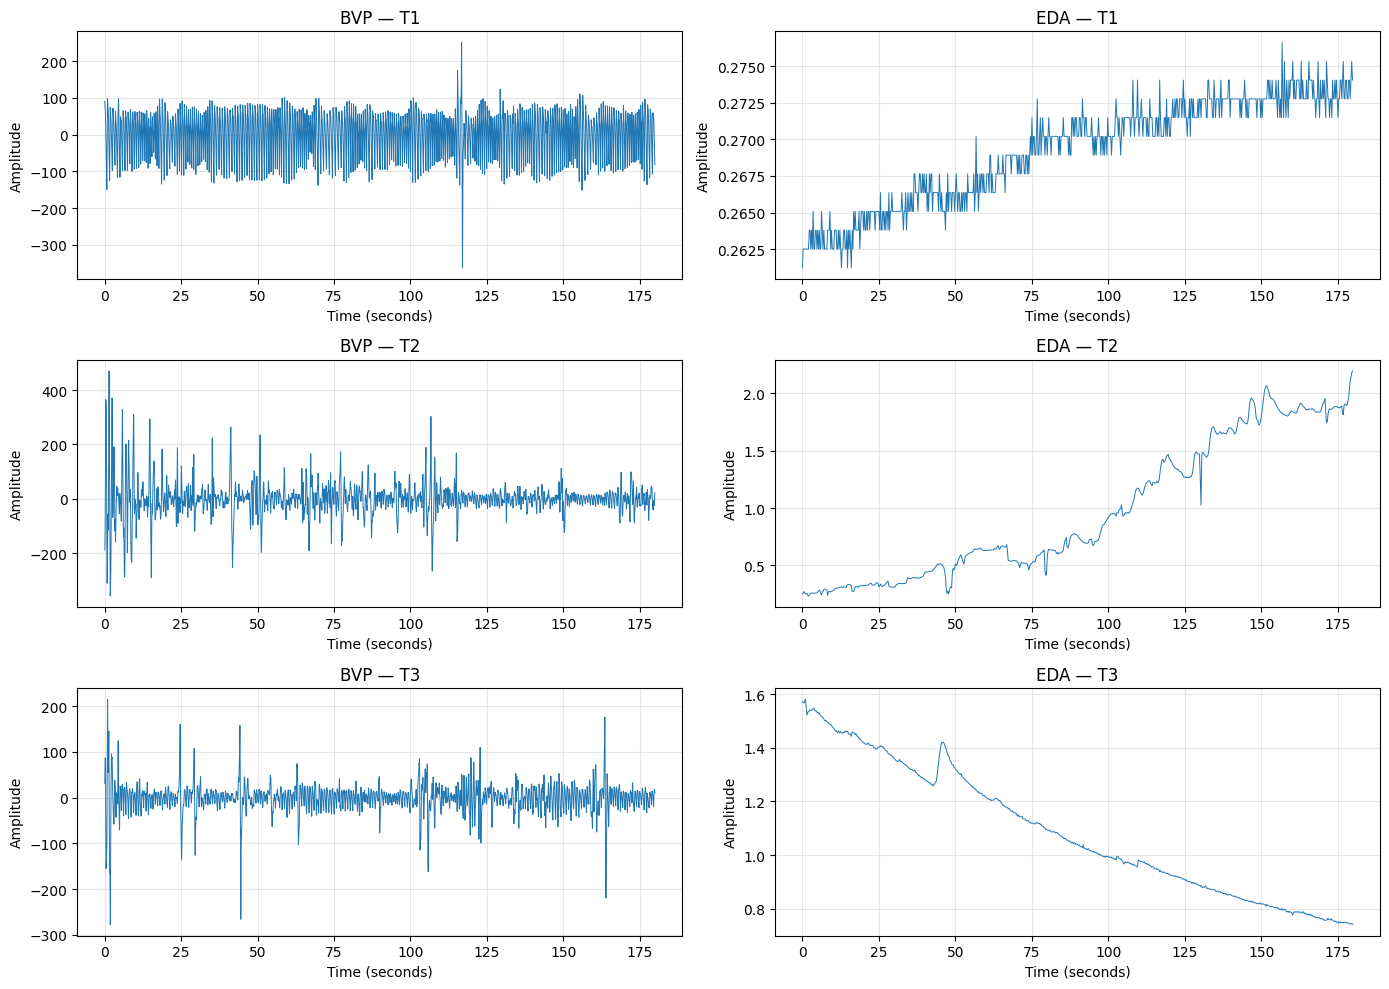

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for row, task in enumerate(["T1", "T2", "T3"]):
    for col, (modality, fs) in enumerate([("bvp", 64), ("eda", 4)]):
        path = folder / f"{modality}_s1_{task}.csv"
        x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy()
        t = range(len(x))

        axes[row, col].plot([i / fs for i in t], x, linewidth=0.7)
        axes[row, col].set_title(f"{modality.upper()} — {task}")
        axes[row, col].set_xlabel("Time (seconds)")
        axes[row, col].set_ylabel("Amplitude")
        axes[row, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for task in ["T1", "T2", "T3"]:
    x = pd.read_csv(
        folder / f"bvp_s1_{task}.csv", header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    median = np.median(x)
    mad = np.median(np.abs(x - median))
    robust_z = (
        0.6745 * (x - median) / mad
        if mad > 0 else np.zeros_like(x)
    )

    print(
        f"{task}: median={median:.3f}, MAD={mad:.3f}, "
        f"p1={np.percentile(x, 1):.2f}, "
        f"p99={np.percentile(x, 99):.2f}, "
        f"|robust z|>3: {np.sum(np.abs(robust_z) > 3)}"
    )

T1: median=12.415, MAD=39.690, p1=-123.30, p99=92.18, |robust z|>3: 20
T2: median=1.075, MAD=19.710, p1=-193.55, p99=211.66, |robust z|>3: 1130
T3: median=2.485, MAD=13.055, p1=-111.63, p99=86.15, |robust z|>3: 636


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for task in ["T1", "T2", "T3"]:
    x = pd.read_csv(
        folder / f"bvp_s1_{task}.csv", header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    median = np.median(x)
    mad = np.median(np.abs(x - median))
    robust_z = 0.6745 * (x - median) / mad if mad > 0 else np.zeros_like(x)
    flagged = np.flatnonzero(np.abs(robust_z) > 3)

    # Group nearby flagged samples into episodes.
    groups = np.split(flagged, np.where(np.diff(flagged) > 1)[0] + 1)
    episodes = [g for g in groups if len(g)]

    print(f"\n{task}: {len(flagged)} flagged samples, {len(episodes)} episodes")
    for g in episodes[:12]:
        print(
            f"  {g[0]/64:.2f}-{g[-1]/64:.2f} s "
            f"({len(g)} samples)"
        )


T1: 20 flagged samples, 2 episodes
  116.69-116.78 s (7 samples)
  116.95-117.14 s (13 samples)

T2: 1130 flagged samples, 76 episodes
  0.00-0.12 s (9 samples)
  0.19-0.55 s (24 samples)
  0.62-0.95 s (22 samples)
  1.09-1.16 s (5 samples)
  1.25-1.58 s (22 samples)
  1.67-2.08 s (27 samples)
  2.19-2.52 s (22 samples)
  2.91-3.16 s (17 samples)
  3.27-3.34 s (6 samples)
  3.42-3.61 s (13 samples)
  5.56-5.92 s (24 samples)
  6.06-6.66 s (39 samples)

T3: 636 flagged samples, 45 episodes
  0.08-0.23 s (11 samples)
  0.33-0.73 s (27 samples)
  0.80-1.08 s (19 samples)
  1.16-1.39 s (16 samples)
  1.47-1.97 s (33 samples)
  2.12-2.47 s (23 samples)
  2.97-3.02 s (4 samples)
  4.30-4.45 s (11 samples)
  4.77-4.86 s (7 samples)
  24.47-24.73 s (18 samples)
  24.94-25.36 s (28 samples)
  29.09-29.31 s (15 samples)


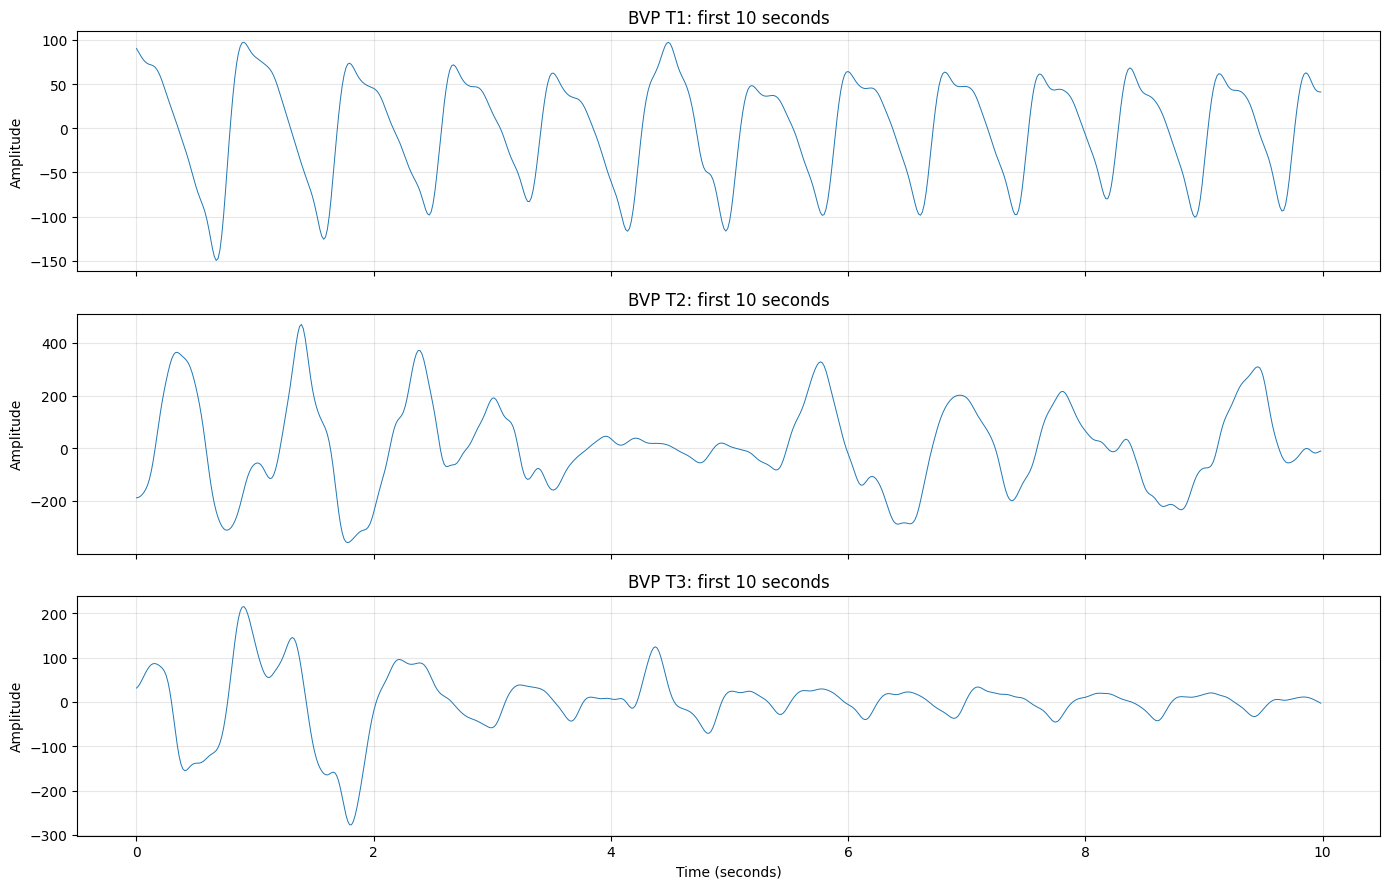

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

for ax, task in zip(axes, ["T1", "T2", "T3"]):
    x = pd.read_csv(
        folder / f"bvp_s1_{task}.csv", header=None
    ).iloc[:, 0].to_numpy()

    n = 10 * 64
    t = [i / 64 for i in range(min(n, len(x)))]

    ax.plot(t, x[:len(t)], linewidth=0.7)
    ax.set_title(f"BVP {task}: first 10 seconds")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
window_seconds = 30
stride_seconds = 5
fs = 64

rows = []

for task in ["T1", "T2", "T3"]:
    x = pd.read_csv(
        folder / f"bvp_s1_{task}.csv",
        header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    window_size = window_seconds * fs
    stride = stride_seconds * fs

    for start in range(0, len(x) - window_size + 1, stride):
        segment = x[start:start + window_size]

        rows.append({
            "subject_id": "s1",
            "session_id": task,
            "start_s": start / fs,
            "end_s": (start + window_size) / fs,
            "mean": np.mean(segment),
            "std": np.std(segment),
            "p01": np.percentile(segment, 1),
            "p99": np.percentile(segment, 99),
        })

quality = pd.DataFrame(rows)

print("Total windows:", len(quality))
print(quality.groupby("session_id")[
    ["std", "p01", "p99"]
].describe().round(2))

display(quality.head(10))

Total windows: 93
             std                                                     p01  \
           count   mean    std    min    25%    50%    75%     max count   
session_id                                                                 
T1          31.0  56.24   3.64  49.60  53.04  56.12  59.27   63.76  31.0   
T2          31.0  48.72  18.10  23.32  29.86  52.36  56.07  108.99  31.0   
T3          31.0  28.30   6.46  15.55  23.45  27.55  33.17   46.14  31.0   

                    ...                   p99                               \
              mean  ...     75%     max count    mean    std    min    25%   
session_id          ...                                                      
T1         -122.46  ... -119.26 -110.20  31.0   97.76  21.08  82.00  86.01   
T2         -153.56  ... -110.88  -54.61  31.0  147.60  66.95  52.95  91.50   
T3          -94.61  ...  -71.92  -36.41  31.0   73.13  22.11  35.94  56.32   

                                    
               50% 

,subject_id,session_id,start_s,end_s,mean,std,p01,p99
0,s1,T1,0.0,30.0,-0.023938,53.122281,-116.4896,90.1330
1,s1,T1,5.0,35.0,-0.190776,50.535935,-110.2037,86.5472
2,s1,T1,10.0,40.0,-0.385964,52.419304,-116.4716,88.3723
3,s1,T1,15.0,45.0,-0.249521,55.364358,-121.1709,88.3723
4,s1,T1,20.0,50.0,-0.910318,56.871972,-121.7562,83.1324
5,s1,T1,25.0,55.0,0.248510,58.677941,-123.5501,82.8701
6,s1,T1,30.0,60.0,0.715573,60.180778,-124.3877,89.0407
7,s1,T1,35.0,65.0,0.415010,61.644555,-124.4281,86.2605
8,s1,T1,40.0,70.0,0.303000,60.076836,-124.9816,90.0384
9,s1,T1,45.0,75.0,0.572562,59.153845,-124.1183,91.3172


In [ ]:
# Validate the window table created in the previous cell
print("Shape:", quality.shape)
print("Missing values:", quality.isna().sum().sum())
print("\nRows per task:")
print(quality.groupby("session_id").size())

print("\nInvalid subject IDs:")
print(quality.loc[quality["subject_id"] != "s1"])

assert len(quality) == 93, "Unexpected number of windows"
assert quality["subject_id"].eq("s1").all(), "Unexpected subject ID"
assert quality["session_id"].isin(["T1", "T2", "T3"]).all()
assert quality.isna().sum().sum() == 0, "Missing values detected"

print("\nWindow table validation: PASS")

Shape: (93, 8)
Missing values: 0

Rows per task:
session_id
T1    31
T2    31
T3    31
dtype: int64

Invalid subject IDs:
Empty DataFrame
Columns: [subject_id, session_id, start_s, end_s, mean, std, p01, p99]
Index: []

Window table validation: PASS


In [ ]:
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1"
)
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "s1_bvp_window_qc.csv"
quality.to_csv(output_path, index=False)

print("Saved:", output_path)
print("File size:", round(output_path.stat().st_size / 1024, 2), "KB")

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_bvp_window_qc.csv
File size: 7.58 KB


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import skew, kurtosis

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
output_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1"
)

FS = 64
WINDOW = 30 * FS
STRIDE = 5 * FS

rows = []

for task in ["T1", "T2", "T3"]:
    x = pd.read_csv(
        folder / f"bvp_s1_{task}.csv",
        header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    for start in range(0, len(x) - WINDOW + 1, STRIDE):
        segment = x[start:start + WINDOW]

        rows.append({
            "subject_id": "s1",
            "session_id": task,
            "start_s": start / FS,
            "end_s": (start + WINDOW) / FS,
            "bvp_mean": np.mean(segment),
            "bvp_std": np.std(segment),
            "bvp_min": np.min(segment),
            "bvp_max": np.max(segment),
            "bvp_median": np.median(segment),
            "bvp_iqr": np.percentile(segment, 75) - np.percentile(segment, 25),
            "bvp_skew": skew(segment),
            "bvp_kurtosis": kurtosis(segment),
            "bvp_rms": np.sqrt(np.mean(segment ** 2)),
        })

bvp_features = pd.DataFrame(rows)

assert len(bvp_features) == 93
assert bvp_features.isna().sum().sum() == 0

path = output_dir / "s1_bvp_features.csv"
bvp_features.to_csv(path, index=False)

print("Shape:", bvp_features.shape)
print("Saved:", path)
display(bvp_features.head())

Shape: (93, 13)
Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_bvp_features.csv


,subject_id,session_id,start_s,end_s,bvp_mean,bvp_std,bvp_min,bvp_max,bvp_median,bvp_iqr,bvp_skew,bvp_kurtosis,bvp_rms
0,s1,T1,0.0,30.0,-0.023938,53.122281,-149.56,97.31,12.295,84.5525,-0.440849,-0.802990,53.122287
1,s1,T1,5.0,35.0,-0.190776,50.535935,-134.62,97.18,11.305,80.1425,-0.435193,-0.812254,50.536295
2,s1,T1,10.0,40.0,-0.385964,52.419304,-134.62,97.18,10.800,83.1950,-0.426866,-0.807752,52.420725
3,s1,T1,15.0,45.0,-0.249521,55.364358,-134.62,97.18,11.365,91.4350,-0.449002,-0.872791,55.364920
4,s1,T1,20.0,50.0,-0.910318,56.871972,-131.43,92.70,12.485,96.8650,-0.459597,-0.955439,56.879257


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import skew, kurtosis

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
output_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1"
)
output_dir.mkdir(parents=True, exist_ok=True)

FS = 4
WINDOW = 30 * FS
STRIDE = 5 * FS

rows = []

for task in ["T1", "T2", "T3"]:
    x = pd.read_csv(
        folder / f"eda_s1_{task}.csv",
        header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    for start in range(0, len(x) - WINDOW + 1, STRIDE):
        segment = x[start:start + WINDOW]
        differences = np.diff(segment)

        rows.append({
            "subject_id": "s1",
            "session_id": task,
            "start_s": start / FS,
            "end_s": (start + WINDOW) / FS,
            "eda_mean": np.mean(segment),
            "eda_std": np.std(segment),
            "eda_min": np.min(segment),
            "eda_max": np.max(segment),
            "eda_median": np.median(segment),
            "eda_iqr": np.percentile(segment, 75) - np.percentile(segment, 25),
            "eda_skew": skew(segment),
            "eda_kurtosis": kurtosis(segment),
            "eda_mean_abs_diff": np.mean(np.abs(differences)),
            "eda_diff_std": np.std(differences),
        })

eda_features = pd.DataFrame(rows)

assert len(eda_features) == 93
assert eda_features.isna().sum().sum() == 0

path = output_dir / "s1_eda_features.csv"
eda_features.to_csv(path, index=False)

print("Shape:", eda_features.shape)
print("Saved:", path)
display(eda_features.head())

Shape: (93, 14)
Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_eda_features.csv


,subject_id,session_id,start_s,end_s,eda_mean,eda_std,eda_min,eda_max,eda_median,eda_iqr,eda_skew,eda_kurtosis,eda_mean_abs_diff,eda_diff_std
0,s1,T1,0.0,30.0,0.263733,0.001159,0.26123,0.26636,0.26380,0.00257,0.025944,-0.730446,0.000939,0.001251
1,s1,T1,5.0,35.0,0.264107,0.001172,0.26123,0.26636,0.26380,0.00128,-0.302896,-0.530165,0.000917,0.001228
2,s1,T1,10.0,40.0,0.264631,0.001382,0.26123,0.26764,0.26508,0.00128,-0.076348,0.037854,0.000905,0.001209
3,s1,T1,15.0,45.0,0.265218,0.001268,0.26123,0.26764,0.26508,0.00128,-0.067711,0.183833,0.000915,0.001237
4,s1,T1,20.0,50.0,0.265539,0.001068,0.26380,0.26764,0.26508,0.00128,0.281185,-0.449713,0.000893,0.001225


In [ ]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/stress-recognition-project/outputs")

paths = [
    base / "ubfc_s1" / "s1_bvp_features.csv",
    base / "ubfc_s1" / "s1_eda_features.csv",
    base / "ubfc_s1_t1_full" / "t1_multimodal_features.csv",
]

for path in paths:
    print(f"\n{path.name}")
    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    if {"subject_id", "session_id", "start_s", "end_s"}.issubset(df.columns):
        print("Tasks:", df["session_id"].value_counts().to_dict())
        print("Missing values:", int(df.isna().sum().sum()))
    else:
        print("Check identifier/timing columns.")


s1_bvp_features.csv
Shape: (93, 13)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'bvp_median', 'bvp_iqr', 'bvp_skew', 'bvp_kurtosis', 'bvp_rms']
Tasks: {'T1': 31, 'T2': 31, 'T3': 31}
Missing values: 0

s1_eda_features.csv
Shape: (93, 14)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'eda_median', 'eda_iqr', 'eda_skew', 'eda_kurtosis', 'eda_mean_abs_diff', 'eda_diff_std']
Tasks: {'T1': 31, 'T2': 31, 'T3': 31}
Missing values: 0

t1_multimodal_features.csv
Shape: (31, 133)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'label', 'video_lm_samples', 'bs_mean__neutral', 'bs_std__neutral', 'bs_mean_browDownLeft', 'bs_std_browDownLeft', 'bs_mean_browDownRight', 'bs_std_browDownRight', 'bs_mean_browInnerUp', 'bs_std_browInnerUp', 'bs_mean_browOuterUpLe

In [ ]:
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/stress-recognition-project/outputs")
out_dir = base / "ubfc_s1"
out_dir.mkdir(parents=True, exist_ok=True)

video_path = base / "ubfc_s1_t1_full" / "t1_multimodal_features.csv"
bvp_path = out_dir / "s1_bvp_features.csv"
eda_path = out_dir / "s1_eda_features.csv"

video = pd.read_csv(video_path)
bvp = pd.read_csv(bvp_path)
eda = pd.read_csv(eda_path)

keys = ["subject_id", "session_id", "start_s", "end_s"]

bvp_t1 = bvp[bvp["session_id"] == "T1"].copy()
eda_t1 = eda[eda["session_id"] == "T1"].copy()

# Remove overlapping physiological columns from the old video table,
# so the new, complete physiological feature tables are authoritative.
old_physiology = [
    c for c in video.columns
    if c.startswith(("bvp_", "eda_"))
]
video_clean = video.drop(columns=old_physiology, errors="ignore")

for name, df in [("video", video_clean), ("BVP", bvp_t1), ("EDA", eda_t1)]:
    assert not df.duplicated(keys).any(), f"Duplicate window keys in {name}"

merged = video_clean.merge(
    bvp_t1, on=keys, how="inner", validate="one_to_one"
).merge(
    eda_t1, on=keys, how="inner", validate="one_to_one"
)

assert len(merged) == 31, f"Expected 31 matched windows; got {len(merged)}"
assert merged.isna().sum().sum() == 0, "Missing values found after merge"

output_path = out_dir / "s1_T1_fusion_features.csv"
merged.to_csv(output_path, index=False)

print("Fusion table shape:", merged.shape)
print("Windows:", len(merged))
print("Missing values:", int(merged.isna().sum().sum()))
print("Saved:", output_path)
print("Window keys unique:", not merged.duplicated(keys).any())

Fusion table shape: (31, 142)
Windows: 31
Missing values: 0
Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_T1_fusion_features.csv
Window keys unique: True


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

files = list(folder.glob("*.csv"))

for prefix in ["bvp_", "eda_"]:
    matched = sorted(
        f.name for f in files
        if f.name.lower().startswith(prefix)
    )
    print(f"\n{prefix.upper()} files: {len(matched)}")
    print("\n".join(matched))

print("\nTotal CSV files:", len(files))


BVP_ files: 19
bvp_s10_T1.csv
bvp_s10_T2.csv
bvp_s10_T3.csv
bvp_s1_T1.csv
bvp_s1_T2.csv
bvp_s1_T3.csv
bvp_s4_T1.csv
bvp_s4_T3.csv
bvp_s5_T1.csv
bvp_s5_T3.csv
bvp_s6_T3.csv
bvp_s7_T1.csv
bvp_s7_T2.csv
bvp_s7_T3.csv
bvp_s8_T2.csv
bvp_s8_T3.csv
bvp_s9_T1.csv
bvp_s9_T2.csv
bvp_s9_T3.csv

EDA_ files: 27
eda_s10_T1.csv
eda_s10_T2.csv
eda_s10_T3.csv
eda_s1_T1.csv
eda_s1_T2.csv
eda_s1_T3.csv
eda_s3_T1.csv
eda_s3_T2.csv
eda_s3_T3.csv
eda_s4_T1.csv
eda_s4_T2.csv
eda_s4_T3.csv
eda_s5_T1.csv
eda_s5_T2.csv
eda_s5_T3.csv
eda_s6_T1.csv
eda_s6_T2.csv
eda_s6_T3.csv
eda_s7_T1.csv
eda_s7_T3.csv
eda_s8_T2.csv
eda_s8_T3.csv
eda_s9_T1.csv
eda_s9_T2 (1).csv
eda_s9_T2.csv
eda_s9_T3 (1).csv
eda_s9_T3.csv

Total CSV files: 47


In [ ]:
from pathlib import Path
import pandas as pd
import re

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

records = []

for subject in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        bvp = folder / f"bvp_s{subject}_{task}.csv"
        eda = folder / f"eda_s{subject}_{task}.csv"

        # Detect duplicate copies such as "(1)"
        eda_duplicates = list(
            folder.glob(f"eda_s{subject}_{task}*.csv")
        )

        records.append({
            "subject": f"s{subject}",
            "task": task,
            "BVP": bvp.exists(),
            "EDA": eda.exists(),
            "EDA copies": len(eda_duplicates),
            "Ready": bvp.exists() and eda.exists()
        })

inventory = pd.DataFrame(records)

display(inventory)

print("\nBVP files found:", int(inventory["BVP"].sum()))
print("EDA files found:", int(inventory["EDA"].sum()))
print("Matched BVP + EDA tasks:", int(inventory["Ready"].sum()))
print("\nMissing BVP:")
display(inventory.loc[~inventory["BVP"], ["subject", "task"]])
print("\nMissing EDA:")
display(inventory.loc[~inventory["EDA"], ["subject", "task"]])

,subject,task,BVP,EDA,EDA copies,Ready
0,s1,T1,True,True,1,True
1,s1,T2,True,True,1,True
2,s1,T3,True,True,1,True
3,s2,T1,False,False,0,False
4,s2,T2,False,False,0,False
5,s2,T3,False,False,0,False
6,s3,T1,False,True,1,False
7,s3,T2,False,True,1,False
8,s3,T3,False,True,1,False
9,s4,T1,True,True,1,True



BVP files found: 19
EDA files found: 25
Matched BVP + EDA tasks: 18

Missing BVP:


,subject,task
3,s2,T1
4,s2,T2
5,s2,T3
6,s3,T1
7,s3,T2
8,s3,T3
10,s4,T2
13,s5,T2
15,s6,T1
16,s6,T2



Missing EDA:


,subject,task
3,s2,T1
4,s2,T2
5,s2,T3
19,s7,T2
21,s8,T1


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
out_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)
out_dir.mkdir(parents=True, exist_ok=True)

FS = {"BVP": 64, "EDA": 4}
WINDOW_SECONDS = 30
STRIDE_SECONDS = 5

def load_signal(path):
    df = pd.read_csv(path, header=None)
    # Use the first column; do not silently combine multiple columns.
    x = pd.to_numeric(df.iloc[:, 0], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0 or not np.isfinite(x).all():
        raise ValueError(f"Empty or non-finite signal: {path.name}")
    return x

def describe_signal(x, prefix):
    d = np.diff(x)
    return {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_median": np.median(x),
        f"{prefix}_iqr": np.percentile(x, 75) - np.percentile(x, 25),
        f"{prefix}_skew": skew(x) if len(x) > 2 else np.nan,
        f"{prefix}_kurtosis": kurtosis(x) if len(x) > 3 else np.nan,
        f"{prefix}_rms": np.sqrt(np.mean(x ** 2)),
        f"{prefix}_mean_abs_diff": np.mean(np.abs(d)) if len(d) else 0.0,
        f"{prefix}_diff_std": np.std(d) if len(d) else 0.0,
    }

rows = []
errors = []

for subject in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        bvp_path = folder / f"bvp_s{subject}_{task}.csv"
        eda_path = folder / f"eda_s{subject}_{task}.csv"

        if not bvp_path.exists() or not eda_path.exists():
            continue

        try:
            bvp = load_signal(bvp_path)
            eda = load_signal(eda_path)

            # Window count is limited to the duration available in BOTH signals.
            duration = min(len(bvp) / FS["BVP"], len(eda) / FS["EDA"])
            start = 0

            while start + WINDOW_SECONDS <= duration + 1e-9:
                end = start + WINDOW_SECONDS

                bvp_start = int(round(start * FS["BVP"]))
                bvp_end = int(round(end * FS["BVP"]))
                eda_start = int(round(start * FS["EDA"]))
                eda_end = int(round(end * FS["EDA"]))

                row = {
                    "subject_id": f"s{subject}",
                    "session_id": task,
                    "start_s": start,
                    "end_s": end,
                    "label": "unlabelled",
                    "bvp_samples": bvp_end - bvp_start,
                    "eda_samples": eda_end - eda_start,
                }
                row.update(describe_signal(bvp[bvp_start:bvp_end], "bvp"))
                row.update(describe_signal(eda[eda_start:eda_end], "eda"))
                rows.append(row)

                start += STRIDE_SECONDS

        except Exception as e:
            errors.append({
                "subject": f"s{subject}",
                "task": task,
                "error": str(e),
            })

features = pd.DataFrame(rows)

output_path = out_dir / "s1_s10_physiological_features.csv"
features.to_csv(output_path, index=False)

print("Feature table shape:", features.shape)
print("Subjects:", features["subject_id"].nunique() if len(features) else 0)
print("Matched tasks processed:", features.groupby(
    ["subject_id", "session_id"]
).ngroups if len(features) else 0)
print("Missing values:", int(features.isna().sum().sum()))
print("Saved:", output_path)

if errors:
    print("\nErrors:")
    display(pd.DataFrame(errors))

Feature table shape: (558, 29)
Subjects: 8
Matched tasks processed: 18
Missing values: 0
Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features.csv


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for prefix in ["bvp_", "eda_"]:
    files = sorted(folder.glob(f"{prefix}*.csv"))
    print(f"\n{prefix.upper()} files: {len(files)}")
    for f in files:
        print(f.name)


BVP_ files: 30
bvp_s10_T1.csv
bvp_s10_T2.csv
bvp_s10_T3.csv
bvp_s1_T1.csv
bvp_s1_T2.csv
bvp_s1_T3.csv
bvp_s2_T1.csv
bvp_s2_T2.csv
bvp_s2_T3.csv
bvp_s3_T1.csv
bvp_s3_T2.csv
bvp_s3_T3.csv
bvp_s4_T1.csv
bvp_s4_T2.csv
bvp_s4_T3.csv
bvp_s5_T1.csv
bvp_s5_T2.csv
bvp_s5_T3.csv
bvp_s6_T1.csv
bvp_s6_T2.csv
bvp_s6_T3.csv
bvp_s7_T1.csv
bvp_s7_T2.csv
bvp_s7_T3.csv
bvp_s8_T1.csv
bvp_s8_T2.csv
bvp_s8_T3.csv
bvp_s9_T1.csv
bvp_s9_T2.csv
bvp_s9_T3.csv

EDA_ files: 32
eda_s10_T1.csv
eda_s10_T2.csv
eda_s10_T3.csv
eda_s1_T1.csv
eda_s1_T2.csv
eda_s1_T3.csv
eda_s2_T1.csv
eda_s2_T2.csv
eda_s2_T3.csv
eda_s3_T1.csv
eda_s3_T2.csv
eda_s3_T3.csv
eda_s4_T1.csv
eda_s4_T2.csv
eda_s4_T3.csv
eda_s5_T1.csv
eda_s5_T2.csv
eda_s5_T3.csv
eda_s6_T1.csv
eda_s6_T2.csv
eda_s6_T3.csv
eda_s7_T1.csv
eda_s7_T2.csv
eda_s7_T3.csv
eda_s8_T1.csv
eda_s8_T2.csv
eda_s8_T3.csv
eda_s9_T1.csv
eda_s9_T2 (1).csv
eda_s9_T2.csv
eda_s9_T3 (1).csv
eda_s9_T3.csv


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
out_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)
out_dir.mkdir(parents=True, exist_ok=True)

FS_BVP, FS_EDA = 64, 4
WINDOW, STRIDE = 30, 5

def load_signal(path):
    df = pd.read_csv(path, header=None)
    x = pd.to_numeric(df.iloc[:, 0], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0 or not np.isfinite(x).all():
        raise ValueError(f"Invalid signal: {path.name}")
    return x

def extract_features(x, prefix):
    d = np.diff(x)
    return {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_min": np.min(x),
        f"{prefix}_max": np.max(x),
        f"{prefix}_median": np.median(x),
        f"{prefix}_iqr": np.percentile(x, 75) - np.percentile(x, 25),
        f"{prefix}_skew": skew(x) if len(x) > 2 else np.nan,
        f"{prefix}_kurtosis": kurtosis(x) if len(x) > 3 else np.nan,
        f"{prefix}_rms": np.sqrt(np.mean(x ** 2)),
        f"{prefix}_mean_abs_diff": np.mean(np.abs(d)) if len(d) else 0.0,
        f"{prefix}_diff_std": np.std(d) if len(d) else 0.0,
    }

rows, errors = [], []

for subject in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        bvp_path = folder / f"bvp_s{subject}_{task}.csv"
        eda_path = folder / f"eda_s{subject}_{task}.csv"

        if not bvp_path.exists() or not eda_path.exists():
            continue

        try:
            bvp = load_signal(bvp_path)
            eda = load_signal(eda_path)
            duration = min(len(bvp) / FS_BVP, len(eda) / FS_EDA)

            for start in np.arange(0, duration - WINDOW + 1e-9, STRIDE):
                end = start + WINDOW

                b0, b1 = round(start * FS_BVP), round(end * FS_BVP)
                e0, e1 = round(start * FS_EDA), round(end * FS_EDA)

                row = {
                    "subject_id": f"s{subject}",
                    "session_id": task,
                    "start_s": int(start),
                    "end_s": int(end),
                    "label": "unlabelled",
                    "bvp_samples": b1 - b0,
                    "eda_samples": e1 - e0,
                }
                row.update(extract_features(bvp[b0:b1], "bvp"))
                row.update(extract_features(eda[e0:e1], "eda"))
                rows.append(row)

        except Exception as exc:
            errors.append({
                "subject": f"s{subject}",
                "task": task,
                "error": str(exc),
            })

features = pd.DataFrame(rows)
output_path = out_dir / "s1_s10_physiological_features.csv"
features.to_csv(output_path, index=False)

print("Feature table shape:", features.shape)
print("Subjects:", features["subject_id"].nunique())
print("Matched tasks:", features.groupby(["subject_id", "session_id"]).ngroups)
print("Missing values:", int(features.isna().sum().sum()))
print("Saved:", output_path)

if errors:
    print("\nTasks with errors:")
    display(pd.DataFrame(errors))

Feature table shape: (930, 29)
Subjects: 10
Matched tasks: 30
Missing values: 0
Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features.csv


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/s1_s10_physiological_features.csv"
)

df = pd.read_csv(path)

keys = ["subject_id", "session_id", "start_s", "end_s"]

print("Duplicate windows:", int(df.duplicated(keys).sum()))
print("Unexpected window lengths:",
      int((df["end_s"] - df["start_s"] != 30).sum()))
print("Invalid sample counts:",
      int(((df["bvp_samples"] != 1920) |
           (df["eda_samples"] != 120)).sum()))

print("\nWindows per subject/task:")
display(
    df.groupby(["subject_id", "session_id"])
      .size()
      .unstack(fill_value=0)
)

print("\nLabels:")
print(df["label"].value_counts(dropna=False))

Duplicate windows: 0
Unexpected window lengths: 0
Invalid sample counts: 0

Windows per subject/task:


session_id,T1,T2,T3
subject_id,,,
s1,31,31,31
s10,31,31,31
s2,31,31,31
s3,31,31,31
s4,31,31,31
s5,31,31,31
s6,31,31,31
s7,31,31,31
s8,31,31,31



Labels:
label
unlabelled    930
Name: count, dtype: int64


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/s1_s10_physiological_features.csv"
)

df = pd.read_csv(path)

keys = ["subject_id", "session_id", "start_s", "end_s"]

print("Duplicate windows:", int(df.duplicated(keys).sum()))
print("Unexpected window lengths:",
      int((df["end_s"] - df["start_s"] != 30).sum()))
print("Invalid sample counts:",
      int(((df["bvp_samples"] != 1920) |
           (df["eda_samples"] != 120)).sum()))

print("\nWindows per subject/task:")
display(
    df.groupby(["subject_id", "session_id"])
      .size()
      .unstack(fill_value=0)
)

print("\nLabels:")
print(df["label"].value_counts(dropna=False))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features.csv'

In [ ]:
from pathlib import Path

from google.colab import drive
drive.mount("/content/drive")

root = Path("/content/drive/MyDrive")

matches = list(root.rglob("s1_s10_physiological_features.csv"))

if matches:
    print("Found feature table:")
    for p in matches:
        print(p)
else:
    print("File not found in Google Drive.")
    print("\nChecking likely output folders:")
    for p in (root / "stress-recognition-project" / "outputs").glob("*"):
        print(p)


Mounted at /content/drive
Found feature table:
/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features.csv


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/s1_s10_physiological_features.csv"
)

df = pd.read_csv(path)
keys = ["subject_id", "session_id", "start_s", "end_s"]

print("Shape:", df.shape)
print("Duplicate windows:", int(df.duplicated(keys).sum()))
print("Unexpected window lengths:",
      int(((df["end_s"] - df["start_s"]) != 30).sum()))
print("Invalid sample counts:",
      int(((df["bvp_samples"] != 1920) |
           (df["eda_samples"] != 120)).sum()))
print("Missing values:", int(df.isna().sum().sum()))

print("\nWindows per subject and task:")
display(df.groupby(["subject_id", "session_id"]).size().unstack(fill_value=0))

print("\nLabels:")
print(df["label"].value_counts(dropna=False))

Shape: (930, 29)
Duplicate windows: 0
Unexpected window lengths: 0
Invalid sample counts: 0
Missing values: 0

Windows per subject and task:


session_id,T1,T2,T3
subject_id,,,
s1,31,31,31
s10,31,31,31
s2,31,31,31
s3,31,31,31
s4,31,31,31
s5,31,31,31
s6,31,31,31
s7,31,31,31
s8,31,31,31



Labels:
label
unlabelled    930
Name: count, dtype: int64


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for pattern in ["selfReportedAnx_s*.csv", "info_s*.txt"]:
    files = sorted(folder.glob(pattern))
    print(f"\n{pattern}: {len(files)} files")
    for f in files:
        print(f.name)


selfReportedAnx_s*.csv: 1 files
selfReportedAnx_s1.csv

info_s*.txt: 1 files
info_s1.txt


In [ ]:
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

questionnaire = pd.read_csv(
    folder / "selfReportedAnx_s1.csv",
    header=None
)

info = folder / "info_s1.txt"

print("Questionnaire shape:", questionnaire.shape)
print("\nQuestionnaire contents:")
display(questionnaire)

print("\nParticipant information:")
print(info.read_text() if info.exists() else "Not found")

Questionnaire shape: (3, 2)

Questionnaire contents:


,0,1
0,2.143,3.286
1,2.571,3.428
2,2.778,1.778



Participant information:
s1
m
test
2019_02_07
11_37_06


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for subject in range(1, 11):
    path = folder / f"info_s{subject}.txt"
    if path.exists():
        print(f"s{subject}: {path.read_text().strip()}")
    else:
        print(f"s{subject}: MISSING")

s1: s1
m
test
2019_02_07
11_37_06
s2: MISSING
s3: MISSING
s4: MISSING
s5: MISSING
s6: MISSING
s7: MISSING
s8: MISSING
s9: MISSING
s10: MISSING


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for s in range(1, 11):
    p = folder / f"info_s{s}.txt"
    print(f"s{s}: {'FOUND' if p.exists() else 'MISSING'}")

s1: FOUND
s2: MISSING
s3: MISSING
s4: MISSING
s5: MISSING
s6: MISSING
s7: MISSING
s8: MISSING
s9: MISSING
s10: MISSING


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for s in range(1, 11):
    p = folder / f"info_s{s}.txt"
    print(f"s{s}: {'FOUND' if p.exists() else 'MISSING'}")

s1: FOUND
s2: FOUND
s3: FOUND
s4: FOUND
s5: FOUND
s6: FOUND
s7: FOUND
s8: FOUND
s9: FOUND
s10: FOUND


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
rows = []

for s in range(1, 11):
    path = folder / f"info_s{s}.txt"
    lines = path.read_text().splitlines()

    rows.append({
        "subject_id": f"s{s}",
        "metadata": " | ".join(line.strip() for line in lines)
    })

info_df = pd.DataFrame(rows)
display(info_df)

output = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/participant_metadata.csv"
)
info_df.to_csv(output, index=False)

print("\nSaved:", output)

,subject_id,metadata
0,s1,s1 | m | test | 2019_02_07 | 11_37_06
1,s2,s2 | m | ctrl | 2019-02-08 | 10-36-48
2,s3,s3 | f | ctrl | 2019_02_08 | 11_18_55
3,s4,s4 | f | test | 2019_02_08 | 11_57_01
4,s5,s5 | f | ctrl | 2019_02_08 | 13_35_28
5,s6,s6 | f | test | 2019_02_12 | 10_34_33
6,s7,s7 | f | ctrl | 2019_02_12 | 11_10_13
7,s8,s8 | f | ctrl | 2019_02_13 | 09_38_45
8,s9,s9 | f | test | 2019_02_13 | 10_12_17
9,s10,s10 | f | ctrl | 2019_02_13 | 10_49_46



Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/participant_metadata.csv


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
rows = []

for s in range(1, 11):
    path = folder / f"info_s{s}.txt"
    parts = path.read_text().split()

    rows.append({
        "subject_id": f"s{s}",
        "group": parts[2],
        "date": parts[3],
        "time": parts[4],
        "sex": parts[1]
    })

metadata = pd.DataFrame(rows)

out = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/participant_metadata_structured.csv"
)
metadata.to_csv(out, index=False)

display(metadata)
print("\nSaved:", out)

,subject_id,group,date,time,sex
0,s1,test,2019_02_07,11_37_06,m
1,s2,ctrl,2019-02-08,10-36-48,m
2,s3,ctrl,2019_02_08,11_18_55,f
3,s4,test,2019_02_08,11_57_01,f
4,s5,ctrl,2019_02_08,13_35_28,f
5,s6,test,2019_02_12,10_34_33,f
6,s7,ctrl,2019_02_12,11_10_13,f
7,s8,ctrl,2019_02_13,09_38_45,f
8,s9,test,2019_02_13,10_12_17,f
9,s10,ctrl,2019_02_13,10_49_46,f



Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/participant_metadata_structured.csv


In [ ]:
from pathlib import Path
import pandas as pd

base = Path("/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10")

features = pd.read_csv(base / "s1_s10_physiological_features.csv")
metadata = pd.read_csv(base / "participant_metadata_structured.csv")

# Check metadata keys before merging
assert metadata["subject_id"].is_unique
assert set(features["subject_id"]).issubset(set(metadata["subject_id"]))

merged = features.merge(
    metadata[["subject_id", "group", "sex"]],
    on="subject_id",
    how="left",
    validate="many_to_one"
)

print("Shape:", merged.shape)
print("Missing values:", int(merged.isna().sum().sum()))
print("\nParticipants by group:")
print(metadata["group"].value_counts())
print("\nRows by group and task:")
display(merged.groupby(["group", "session_id"]).size().unstack(fill_value=0))

output = base / "s1_s10_physiological_features_with_metadata.csv"
merged.to_csv(output, index=False)
print("\nSaved:", output)

Shape: (930, 31)
Missing values: 0

Participants by group:
group
ctrl    6
test    4
Name: count, dtype: int64

Rows by group and task:


session_id,T1,T2,T3
group,,,
ctrl,186,186,186
test,124,124,124



Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features_with_metadata.csv


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for s in range(1, 11):
    path = folder / f"selfReportedAnx_s{s}.csv"

    if path.exists():
        df = pd.read_csv(path, header=None)
        print(f"s{s}: FOUND — shape {df.shape}")
    else:
        print(f"s{s}: MISSING")

s1: FOUND — shape (3, 2)
s2: FOUND — shape (3, 2)
s3: FOUND — shape (3, 2)
s4: FOUND — shape (3, 2)
s5: FOUND — shape (3, 2)
s6: FOUND — shape (3, 2)
s7: FOUND — shape (3, 2)
s8: FOUND — shape (3, 2)
s9: FOUND — shape (3, 2)
s10: FOUND — shape (3, 2)


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for s in range(1, 11):
    path = folder / f"selfReportedAnx_s{s}.csv"
    df = pd.read_csv(path, header=None)

    print(f"\n--- Subject s{s} ---")
    print(df.to_string(index=False, header=False))


--- Subject s1 ---
2.143 3.286
2.571 3.428
2.778 1.778

--- Subject s2 ---
1.428 1.857
1.143 1.143
3.444 3.555

--- Subject s3 ---
1.571 1.143
1.714 1.714
2.778 2.555

--- Subject s4 ---
1.714 2.000
1.143 1.714
2.778 2.555

--- Subject s5 ---
1.571 1.857
1.000 1.000
3.555 3.555

--- Subject s6 ---
1.571 1.286
2.000 2.428
2.111 2.444

--- Subject s7 ---
2.000 1.714
1.714 1.571
2.222 2.000

--- Subject s8 ---
1.857 2.000
1.428 1.571
3.222 2.778

--- Subject s9 ---
3.714 3.286
2.428 3.000
1.778 1.333

--- Subject s10 ---
2.143 2.714
1.714 2.428
2.222 1.778


In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
output = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)
output.mkdir(parents=True, exist_ok=True)

records = []

for s in range(1, 11):
    df = pd.read_csv(
        folder / f"selfReportedAnx_s{s}.csv",
        header=None
    )

    for row in range(df.shape[0]):
        records.append({
            "subject_id": f"s{s}",
            "row_index": row + 1,
            "value_col1": df.iloc[row, 0],
            "value_col2": df.iloc[row, 1]
        })

questionnaire = pd.DataFrame(records)

path = output / "questionnaire_raw_structured.csv"
questionnaire.to_csv(path, index=False)

print("Saved:", path)
print("Shape:", questionnaire.shape)
display(questionnaire.head(9))

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/questionnaire_raw_structured.csv
Shape: (30, 4)


,subject_id,row_index,value_col1,value_col2
0,s1,1,2.143,3.286
1,s1,2,2.571,3.428
2,s1,3,2.778,1.778
3,s2,1,1.428,1.857
4,s2,2,1.143,1.143
5,s2,3,3.444,3.555
6,s3,1,1.571,1.143
7,s3,2,1.714,1.714
8,s3,3,2.778,2.555


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for s in [1, 2]:
    path = folder / f"selfReportedAnx_s{s}.csv"
    print(f"\n--- {path.name} ---")
    print(path.read_text()[:500])


--- selfReportedAnx_s1.csv ---
2.143,3.286
2.571,3.428
2.778,1.778


--- selfReportedAnx_s2.csv ---
1.428,1.857
1.143,1.143
3.444,3.555



In [ ]:
from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
output = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

dimensions = [
    "cognitive_anxiety",
    "somatic_anxiety",
    "self_confidence"
]

records = []

for s in range(1, 11):
    df = pd.read_csv(
        folder / f"selfReportedAnx_s{s}.csv",
        header=None
    )

    for i, dimension in enumerate(dimensions):
        pre = float(df.iloc[i, 0])
        post = float(df.iloc[i, 1])

        records.append({
            "subject_id": f"s{s}",
            "dimension": dimension,
            "pre_session": pre,
            "post_session": post,
            "change_post_minus_pre": post - pre
        })

questionnaire = pd.DataFrame(records)

save_path = output / "questionnaire_interpreted_pilot.csv"
questionnaire.to_csv(save_path, index=False)

print("Saved:", save_path)
display(questionnaire)

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/questionnaire_interpreted_pilot.csv


,subject_id,dimension,pre_session,post_session,change_post_minus_pre
0,s1,cognitive_anxiety,2.143,3.286,1.143
1,s1,somatic_anxiety,2.571,3.428,0.857
2,s1,self_confidence,2.778,1.778,-1.000
3,s2,cognitive_anxiety,1.428,1.857,0.429
4,s2,somatic_anxiety,1.143,1.143,0.000
5,s2,self_confidence,3.444,3.555,0.111
6,s3,cognitive_anxiety,1.571,1.143,-0.428
7,s3,somatic_anxiety,1.714,1.714,0.000
8,s3,self_confidence,2.778,2.555,-0.223
9,s4,cognitive_anxiety,1.714,2.000,0.286


In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

questionnaire = pd.read_csv(
    base / "questionnaire_interpreted_pilot.csv"
)
metadata = pd.read_csv(
    base / "participant_metadata_structured.csv"
)

df = questionnaire.merge(
    metadata[["subject_id", "group"]],
    on="subject_id",
    how="left",
    validate="many_to_one"
)

summary = (
    df.groupby(["group", "dimension"])["change_post_minus_pre"]
    .agg(["count", "mean", "std"])
    .round(3)
    .reset_index()
)

print("Mean questionnaire change by group")
display(summary)

print("\nSubject-level changes")
display(
    df.pivot(
        index="subject_id",
        columns="dimension",
        values="change_post_minus_pre"
    ).round(3)
)

summary.to_csv(
    base / "questionnaire_group_change_summary.csv",
    index=False
)

print("\nSaved questionnaire_group_change_summary.csv")

Mean questionnaire change by group


,group,dimension,count,mean,std
0,ctrl,cognitive_anxiety,6,0.119,0.398
1,ctrl,self_confidence,6,-0.204,0.227
2,ctrl,somatic_anxiety,6,0.119,0.305
3,test,cognitive_anxiety,4,0.179,0.713
4,test,self_confidence,4,-0.334,0.552
5,test,somatic_anxiety,4,0.607,0.180



Subject-level changes


dimension,cognitive_anxiety,self_confidence,somatic_anxiety
subject_id,,,
s1,1.143,-1.000,0.857
s10,0.571,-0.444,0.714
s2,0.429,0.111,0.000
s3,-0.428,-0.223,0.000
s4,0.286,-0.223,0.571
s5,0.286,0.000,0.000
s6,-0.285,0.333,0.428
s7,-0.286,-0.222,-0.143
s8,0.143,-0.444,0.143



Saved questionnaire_group_change_summary.csv


In [ ]:
from pathlib import Path
import pandas as pd

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/"
    "s1_s10_physiological_features_with_metadata.csv"
)

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print(col)

print("\nTasks:")
print(df["session_id"].value_counts())

print("\nSubjects:", df["subject_id"].nunique())
print("Missing values:", df.isna().sum().sum())
print("Label counts:")
print(df["label"].value_counts(dropna=False))

Shape: (930, 31)

Columns:
subject_id
session_id
start_s
end_s
label
bvp_samples
eda_samples
bvp_mean
bvp_std
bvp_min
bvp_max
bvp_median
bvp_iqr
bvp_skew
bvp_kurtosis
bvp_rms
bvp_mean_abs_diff
bvp_diff_std
eda_mean
eda_std
eda_min
eda_max
eda_median
eda_iqr
eda_skew
eda_kurtosis
eda_rms
eda_mean_abs_diff
eda_diff_std
group
sex

Tasks:
session_id
T1    310
T2    310
T3    310
Name: count, dtype: int64

Subjects: 10
Missing values: 0
Label counts:
label
unlabelled    930
Name: count, dtype: int64


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

results = []

for s in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        path = folder / f"bvp_s{s}_{task}.csv"

        signal = pd.read_csv(path, header=None).iloc[:, 0]
        x = pd.to_numeric(signal, errors="coerce").dropna().to_numpy()

        results.append({
            "subject_id": f"s{s}",
            "session_id": task,
            "samples": len(x),
            "duration_seconds": round(len(x) / 64, 2),
            "mean": round(float(np.mean(x)), 4),
            "std": round(float(np.std(x)), 4),
            "finite_fraction": round(float(np.isfinite(x).mean()), 4),
            "unique_values": int(np.unique(x).size)
        })

check = pd.DataFrame(results)

print("BVP signal quality summary")
display(check)

print("\nOverall checks")
print("Expected samples per task: 11520")
print("Unexpected sample counts:",
      int((check["samples"] != 11520).sum()))
print("Non-finite recordings:",
      int((check["finite_fraction"] < 1).sum()))

BVP signal quality summary


,subject_id,session_id,samples,duration_seconds,mean,std,finite_fraction,unique_values
0,s1,T1,11520,180.0,0.0448,56.0346,1.0,8625
1,s1,T2,11520,180.0,0.1302,60.7318,1.0,7708
2,s1,T3,11520,180.0,-0.0564,31.6200,1.0,6246
3,s2,T1,11520,180.0,0.0667,48.3943,1.0,8158
4,s2,T2,11520,180.0,-0.0066,55.6596,1.0,8650
5,s2,T3,11520,180.0,-0.0411,41.1150,1.0,7662
6,s3,T1,11520,180.0,-0.0463,20.5253,1.0,5888
7,s3,T2,11520,180.0,0.0112,32.0383,1.0,7094
8,s3,T3,11520,180.0,0.0249,21.4022,1.0,5444
9,s4,T1,11520,180.0,-0.0418,58.3771,1.0,8381



Overall checks
Expected samples per task: 11520
Unexpected sample counts: 0
Non-finite recordings: 0


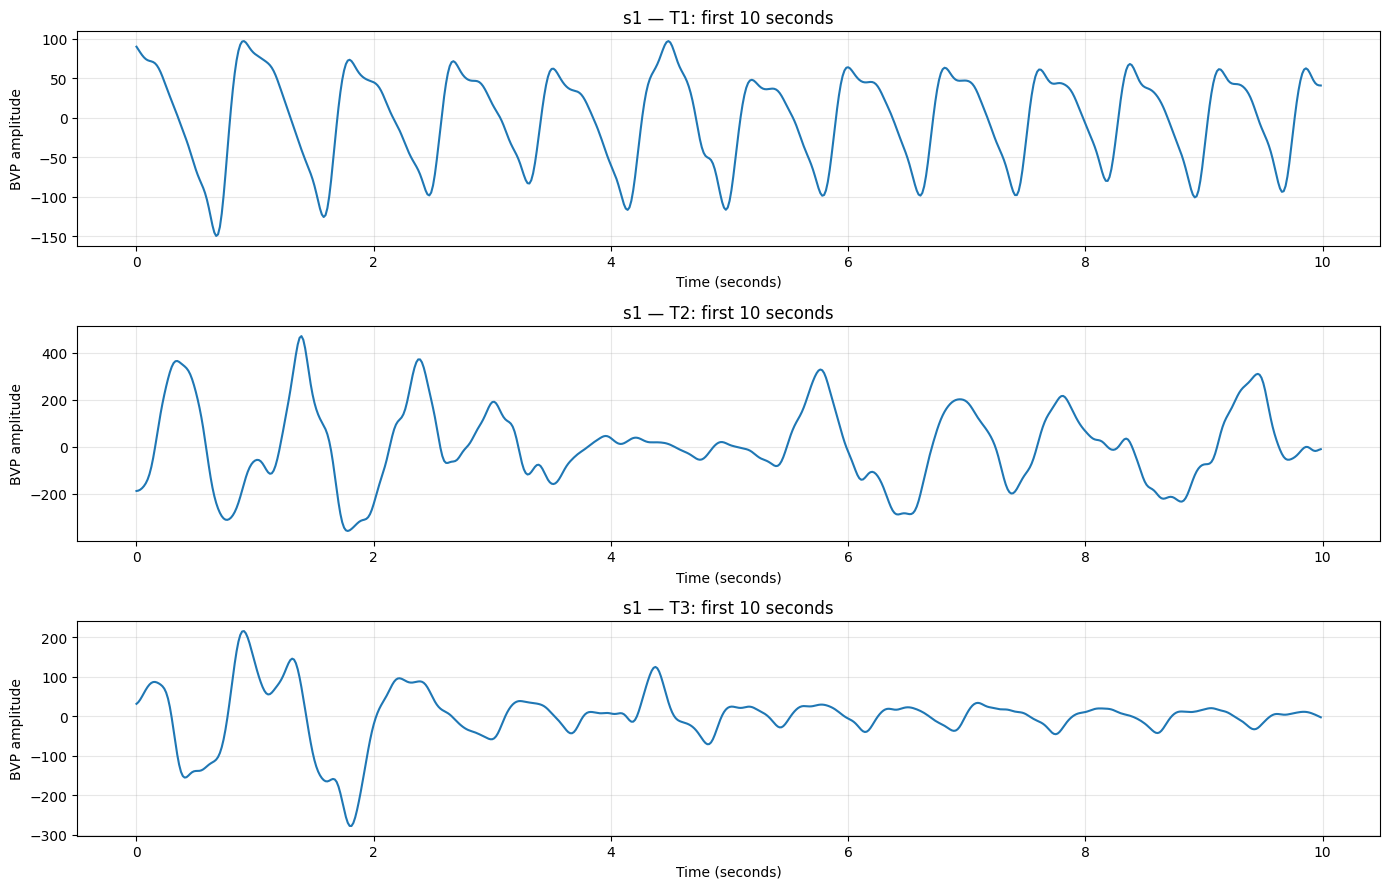

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Representative recordings, one per task
examples = [
    ("s1", "T1"),
    ("s1", "T2"),
    ("s1", "T3"),
]

fs = 64
duration = 10
samples = fs * duration

fig, axes = plt.subplots(3, 1, figsize=(14, 9))

for ax, (subject, task) in zip(axes, examples):
    path = folder / f"bvp_{subject}_{task}.csv"
    signal = pd.read_csv(path, header=None).iloc[:, 0].astype(float)
    segment = signal.iloc[:samples]

    time = [i / fs for i in range(len(segment))]
    ax.plot(time, segment)
    ax.set_title(f"{subject} — {task}: first {duration} seconds")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("BVP amplitude")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

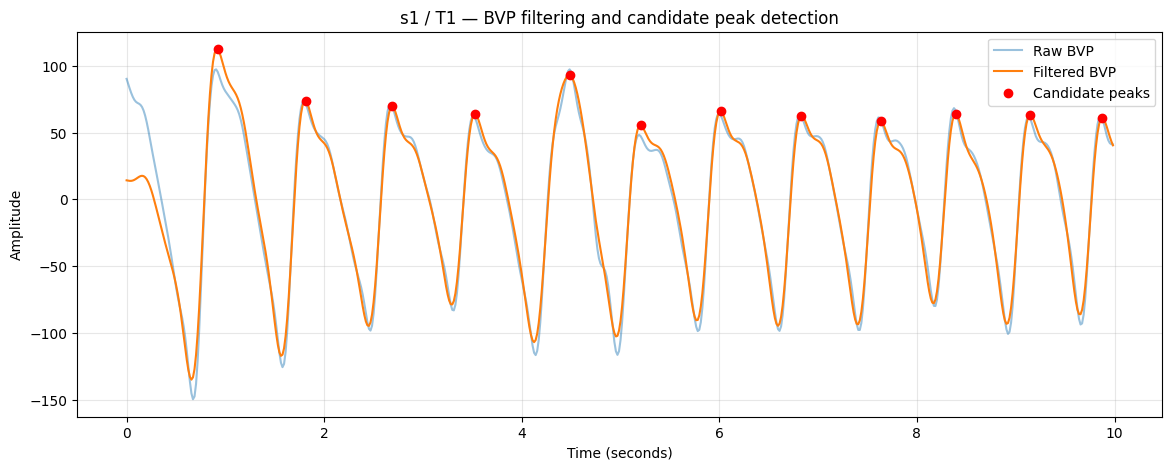

Total candidate peaks in 180 seconds: 244
Filtered signal standard deviation: 54.681


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, sosfiltfilt, find_peaks

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
path = folder / "bvp_s1_T1.csv"

fs = 64
x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(dtype=float)

# Bandpass filter: retain pulse-related frequencies
sos = butter(
    3,
    [0.5, 4.0],
    btype="bandpass",
    fs=fs,
    output="sos"
)
filtered = sosfiltfilt(sos, x)

# Candidate peaks; this is an initial diagnostic, not validated PRV
peaks, properties = find_peaks(
    filtered,
    distance=int(0.33 * fs),
    prominence=0.5 * np.std(filtered)
)

# Plot first 10 seconds
n = 10 * fs
t = np.arange(n) / fs
visible_peaks = peaks[peaks < n]

plt.figure(figsize=(14, 5))
plt.plot(t, x[:n], alpha=0.45, label="Raw BVP")
plt.plot(t, filtered[:n], label="Filtered BVP")
plt.scatter(
    visible_peaks / fs,
    filtered[visible_peaks],
    color="red",
    label="Candidate peaks",
    zorder=3
)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("s1 / T1 — BVP filtering and candidate peak detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Total candidate peaks in 180 seconds:", len(peaks))
print("Filtered signal standard deviation:", round(float(np.std(filtered)), 3))

In [ ]:
import numpy as np
import pandas as pd

# Time between consecutive detected peaks, in seconds
peak_times = peaks / fs
ibi = np.diff(peak_times)

# Convert intervals to beats per minute for a plausibility check
bpm = 60 / ibi

print("Detected peaks:", len(peaks))
print("Intervals:", len(ibi))

print("\nInter-beat interval (IBI) summary")
print("Median:", round(float(np.median(ibi)), 3), "seconds")
print("Minimum:", round(float(np.min(ibi)), 3), "seconds")
print("Maximum:", round(float(np.max(ibi)), 3), "seconds")

print("\nCandidate pulse-rate summary")
print("Median:", round(float(np.median(bpm)), 1), "BPM")
print("Minimum:", round(float(np.min(bpm)), 1), "BPM")
print("Maximum:", round(float(np.max(bpm)), 1), "BPM")

# Diagnostic only: flag intervals outside a broad range
valid = (ibi >= 0.33) & (ibi <= 1.5)

print("\nIntervals within 0.33–1.5 seconds:",
      f"{valid.sum()} / {len(ibi)}")
print("Fraction within range:", round(float(valid.mean()), 3))

Detected peaks: 244
Intervals: 243

Inter-beat interval (IBI) summary
Median: 0.719 seconds
Minimum: 0.547 seconds
Maximum: 1.312 seconds

Candidate pulse-rate summary
Median: 83.5 BPM
Minimum: 45.7 BPM
Maximum: 109.7 BPM

Intervals within 0.33–1.5 seconds: 243 / 243
Fraction within range: 1.0


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt, find_peaks

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 64

sos = butter(
    3, [0.5, 4.0],
    btype="bandpass",
    fs=fs,
    output="sos"
)

results = []

for s in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        path = folder / f"bvp_s{s}_{task}.csv"
        x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)

        filtered = sosfiltfilt(sos, x)

        peaks, _ = find_peaks(
            filtered,
            distance=int(0.33 * fs),
            prominence=0.5 * np.std(filtered)
        )

        ibi = np.diff(peaks) / fs
        bpm = 60 / ibi if len(ibi) else np.array([])
        valid = (ibi >= 0.33) & (ibi <= 1.5)

        results.append({
            "subject_id": f"s{s}",
            "session_id": task,
            "peaks": len(peaks),
            "intervals": len(ibi),
            "median_ibi_s": round(float(np.median(ibi)), 3)
                if len(ibi) else np.nan,
            "median_bpm_candidate": round(float(np.median(bpm)), 1)
                if len(bpm) else np.nan,
            "fraction_intervals_in_range": round(float(np.mean(valid)), 3)
                if len(ibi) else np.nan
        })

quality = pd.DataFrame(results)

display(quality)

out = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/bvp_peak_detection_diagnostic.csv"
)
quality.to_csv(out, index=False)

print("Saved:", out)
print("Recordings checked:", len(quality))
print("Recordings with no detected peaks:",
      int((quality["peaks"] == 0).sum()))
print("Recordings with median candidate rate outside 40–180 BPM:",
      int((~quality["median_bpm_candidate"].between(40, 180)).sum()))

,subject_id,session_id,peaks,intervals,median_ibi_s,median_bpm_candidate,fraction_intervals_in_range
0,s1,T1,244,243,0.719,83.5,1.000
1,s1,T2,200,199,0.797,75.3,0.955
2,s1,T3,219,218,0.789,76.0,0.977
3,s2,T1,182,181,1.000,60.0,1.000
4,s2,T2,220,219,0.812,73.8,0.977
5,s2,T3,223,222,0.781,76.8,0.995
6,s3,T1,257,256,0.688,87.3,1.000
7,s3,T2,298,297,0.594,101.1,0.997
8,s3,T3,303,302,0.594,101.1,0.997
9,s4,T1,240,239,0.734,81.7,1.000


Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/bvp_peak_detection_diagnostic.csv
Recordings checked: 30
Recordings with no detected peaks: 0
Recordings with median candidate rate outside 40–180 BPM: 0


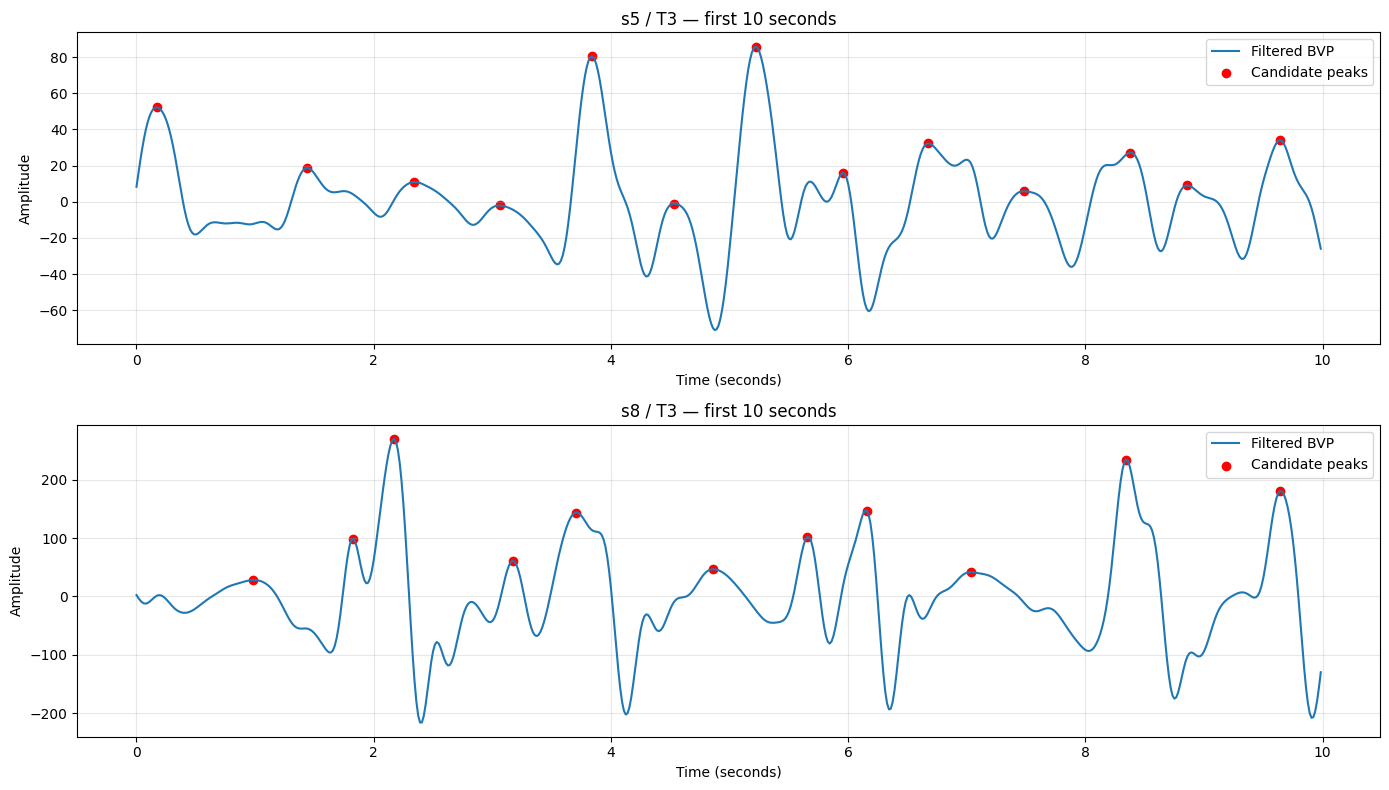

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, sosfiltfilt, find_peaks

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 64

sos = butter(
    3, [0.5, 4.0],
    btype="bandpass",
    fs=fs,
    output="sos"
)

examples = [("s5", "T3"), ("s8", "T3")]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (subject, task) in zip(axes, examples):
    path = folder / f"bvp_{subject}_{task}.csv"
    x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)
    filtered = sosfiltfilt(sos, x)

    peaks, _ = find_peaks(
        filtered,
        distance=int(0.33 * fs),
        prominence=0.5 * np.std(filtered)
    )

    n = 10 * fs
    t = np.arange(n) / fs
    visible = peaks[peaks < n]

    ax.plot(t, filtered[:n], label="Filtered BVP")
    ax.scatter(
        visible / fs,
        filtered[visible],
        color="red",
        label="Candidate peaks"
    )
    ax.set_title(f"{subject} / {task} — first 10 seconds")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal import butter, sosfiltfilt, find_peaks

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 64

sos = butter(
    3, [0.5, 4.0],
    btype="bandpass",
    fs=fs,
    output="sos"
)

examples = [("s5", "T3"), ("s8", "T3")]
prominence_factors = [0.5, 0.8]

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
summary = []

for ax, (subject, task) in zip(axes, examples):
    path = folder / f"bvp_{subject}_{task}.csv"
    x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)
    filtered = sosfiltfilt(sos, x)

    n = 10 * fs
    t = np.arange(n) / fs
    ax.plot(t, filtered[:n], label="Filtered BVP")

    for factor in prominence_factors:
        peaks, _ = find_peaks(
            filtered,
            distance=int(0.33 * fs),
            prominence=factor * np.std(filtered)
        )

        visible = peaks[peaks < n]
        ax.scatter(
            visible / fs,
            filtered[visible],
            label=f"Prominence = {factor} × SD",
            s=25
        )

        ibi = np.diff(peaks) / fs
        valid_fraction = (
            float(np.mean((ibi >= 0.33) & (ibi <= 1.5))
            if len(ibi) else np.nan
        )

        summary.append({
            "subject": subject,
            "task": task,
            "prominence_factor": factor,
            "peak_count": len(peaks),
            "intervals_in_range_fraction": round(valid_fraction, 3)
                if np.isfinite(valid_fraction) else np.nan
        })

    ax.set_title(f"{subject}/{task}: compare peak thresholds")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary))

SyntaxError: '(' was never closed (3281745338.py, line 48)

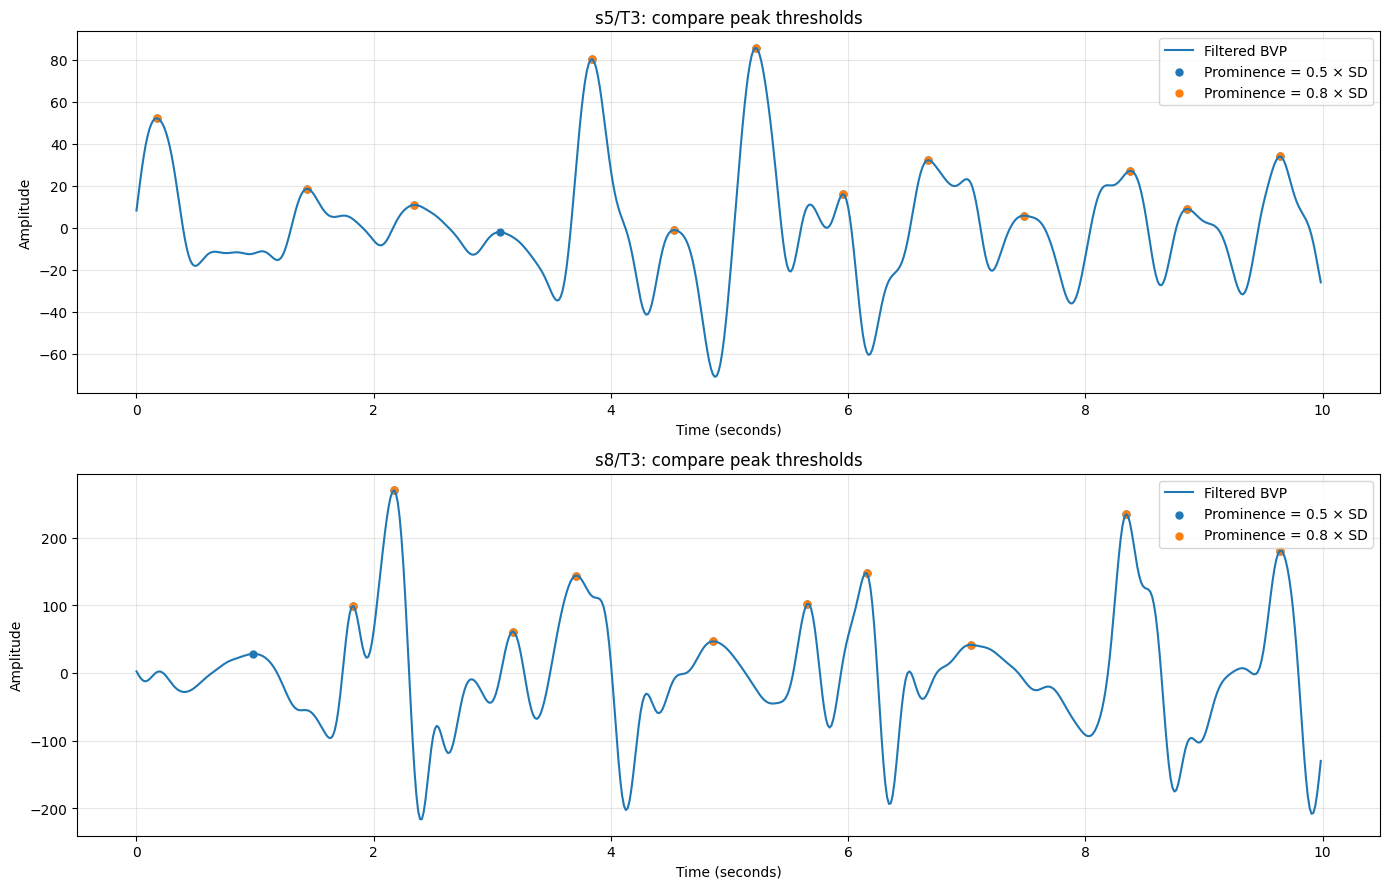

,subject,task,prominence_factor,peak_count,intervals_in_range_fraction
0,s5,T3,0.5,190,0.889
1,s5,T3,0.8,157,0.795
2,s8,T3,0.5,181,0.889
3,s8,T3,0.8,149,0.845


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 64

sos = butter(
    3, [0.5, 4.0],
    btype="bandpass",
    fs=fs,
    output="sos"
)

examples = [("s5", "T3"), ("s8", "T3")]
prominence_factors = [0.5, 0.8]

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
summary = []

for ax, (subject, task) in zip(axes, examples):
    path = folder / f"bvp_{subject}_{task}.csv"
    x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)
    filtered = sosfiltfilt(sos, x)

    n = 10 * fs
    t = np.arange(n) / fs
    ax.plot(t, filtered[:n], label="Filtered BVP")

    for factor in prominence_factors:
        peaks, _ = find_peaks(
            filtered,
            distance=int(0.33 * fs),
            prominence=factor * np.std(filtered)
        )

        visible = peaks[peaks < n]
        ax.scatter(
            visible / fs,
            filtered[visible],
            label=f"Prominence = {factor} × SD",
            s=25
        )

        ibi = np.diff(peaks) / fs

        if len(ibi):
            valid_fraction = np.mean(
                (ibi >= 0.33) & (ibi <= 1.5)
            )
        else:
            valid_fraction = np.nan

        summary.append({
            "subject": subject,
            "task": task,
            "prominence_factor": factor,
            "peak_count": len(peaks),
            "intervals_in_range_fraction": (
                round(float(valid_fraction), 3)
                if np.isfinite(valid_fraction)
                else np.nan
            )
        })

    ax.set_title(f"{subject}/{task}: compare peak thresholds")
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary))


In [ ]:
from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

source = base / "s1_s10_physiological_features_with_metadata.csv"
df = pd.read_csv(source)

# Preserve the original labels; do not invent stress labels
assert df["subject_id"].nunique() == 10
assert df[["bvp_mean", "eda_mean"]].notna().all().all()
assert len(df) == 930

# Save a separate baseline copy
out = base / "physiology_baseline_unlabelled.csv"
df.to_csv(out, index=False)

print("Saved:", out)
print("Shape:", df.shape)
print("\nWindows per subject:")
display(df.groupby("subject_id").size().rename("windows"))

print("\nWindows by task and group:")
display(pd.crosstab(df["session_id"], df["group"]))

print("\nLabels:")
print(df["label"].value_counts(dropna=False))

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/physiology_baseline_unlabelled.csv
Shape: (930, 31)

Windows per subject:


,windows
subject_id,
s1,93
s10,93
s2,93
s3,93
s4,93
s5,93
s6,93
s7,93
s8,93



Windows by task and group:


group,ctrl,test
session_id,,
T1,186,124
T2,186,124
T3,186,124



Labels:
label
unlabelled    930
Name: count, dtype: int64


In [ ]:
from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(base / "physiology_baseline_unlabelled.csv")

feature_cols = [
    c for c in df.columns
    if c.startswith("bvp_") or c.startswith("eda_")
]

recording_level = (
    df.groupby(
        ["subject_id", "session_id", "group", "sex"],
        as_index=False
    )[feature_cols]
    .mean()
)

out = base / "physiology_recording_level_pilot.csv"
recording_level.to_csv(out, index=False)

print("Saved:", out)
print("Shape:", recording_level.shape)
print("\nRows per subject:")
display(recording_level.groupby("subject_id").size())

print("\nGroup distribution:")
display(
    recording_level[["subject_id", "group"]]
    .drop_duplicates()["group"]
    .value_counts()
)

print("\nRecording-level preview:")
display(recording_level.head())

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/physiology_recording_level_pilot.csv
Shape: (30, 28)

Rows per subject:


,0
subject_id,
s1,3
s10,3
s2,3
s3,3
s4,3
s5,3
s6,3
s7,3
s8,3



Group distribution:


,count
group,
ctrl,6
test,4



Recording-level preview:


,subject_id,session_id,group,sex,bvp_samples,eda_samples,bvp_mean,bvp_std,bvp_min,bvp_max,...,eda_std,eda_min,eda_max,eda_median,eda_iqr,eda_skew,eda_kurtosis,eda_rms,eda_mean_abs_diff,eda_diff_std
0,s1,T1,test,m,1920.0,120.0,0.012595,56.240148,-181.783871,131.525484,...,0.001097,0.267102,0.272388,0.269374,0.001301,0.216961,0.242063,0.269392,0.000884,0.001235
1,s1,T2,test,m,1920.0,120.0,-0.050534,48.720345,-211.630968,223.720968,...,0.118559,0.686751,1.189129,0.952856,0.175981,0.033514,-0.246595,0.963501,0.013488,0.026307
2,s1,T3,test,m,1920.0,120.0,-0.067144,28.295278,-164.772903,119.193548,...,0.043217,1.008110,1.162765,1.078301,0.070202,0.135794,-1.024614,1.081167,0.002892,0.003856
3,s10,T1,ctrl,f,1920.0,120.0,-0.000016,12.813452,-37.096129,31.975806,...,0.002537,0.171543,0.182491,0.176314,0.003697,0.235367,-0.406113,0.176503,0.001006,0.001342
4,s10,T2,ctrl,f,1920.0,120.0,0.038405,31.351436,-113.414194,155.047419,...,0.299077,2.483391,3.667787,3.009255,0.452492,0.228180,-0.604704,3.041281,0.042101,0.058227


Feature summaries by task:


bvp_std                   eda_std                  \
               mean      std   median    mean     std  median   
session_id                                                      
T1          30.8268  18.8116  25.3804  0.0025  0.0021  0.0013   
T2          54.0049  24.5081  50.6130  0.0708  0.0926  0.0330   
T3          44.4447  29.9042  33.6689  0.0579  0.0861  0.0356   

           eda_mean_abs_diff                 
                        mean     std median  
session_id                                   
T1                    0.0011  0.0002  0.001  
T2                    0.0103  0.0130  0.005  
T3                    0.0101  0.0206  0.004

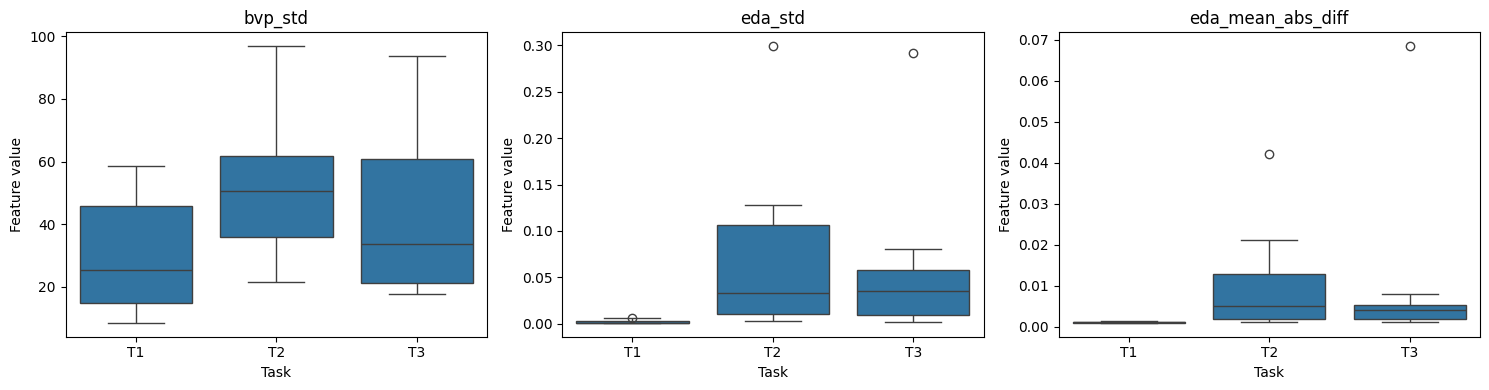

In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(base / "physiology_recording_level_pilot.csv")

# Descriptive summaries by task
features = ["bvp_std", "eda_std", "eda_mean_abs_diff"]

print("Feature summaries by task:")
display(
    df.groupby("session_id")[features]
      .agg(["mean", "std", "median"])
      .round(4)
)

# Visual comparisons
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features):
    sns.boxplot(
        data=df,
        x="session_id",
        y=feature,
        order=["T1", "T2", "T3"],
        ax=ax
    )
    ax.set_title(feature)
    ax.set_xlabel("Task")
    ax.set_ylabel("Feature value")

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(base / "physiology_recording_level_pilot.csv")

features = ["bvp_std", "eda_std", "eda_mean_abs_diff"]

# Each participant gets one row, with a separate column per task
for feature in features:
    wide = df.pivot(
        index="subject_id",
        columns="session_id",
        values=feature
    )

    wide["T2_minus_T1"] = wide["T2"] - wide["T1"]
    wide["T3_minus_T1"] = wide["T3"] - wide["T1"]

    print(f"\n{feature}: participant-level task differences")
    display(wide.round(4))

    print("Participants with T2 > T1:",
          int((wide["T2"] > wide["T1"]).sum()), "/",
          len(wide))
    print("Participants with T3 > T1:",
          int((wide["T3"] > wide["T1"]).sum()), "/",
          len(wide))



bvp_std: participant-level task differences


session_id,T1,T2,T3,T2_minus_T1,T3_minus_T1
subject_id,,,,,
s1,56.2401,48.7203,28.2953,-7.5198,-27.9449
s10,12.8135,31.3514,31.5171,18.5380,18.7036
s2,47.2715,53.6232,38.8840,6.3516,-8.3875
s3,20.3466,31.5950,17.5562,11.2483,-2.7904
s4,58.7040,90.5924,68.2032,31.8884,9.4992
s5,22.5449,50.3248,17.9036,27.7799,-4.6413
s6,28.2159,64.4893,18.7541,36.2734,-9.4618
s7,11.9143,50.9011,35.8208,38.9868,23.9064
s8,8.3949,21.5684,93.7069,13.1735,85.3120


Participants with T2 > T1: 9 / 10
Participants with T3 > T1: 5 / 10

eda_std: participant-level task differences


session_id,T1,T2,T3,T2_minus_T1,T3_minus_T1
subject_id,,,,,
s1,0.0011,0.1186,0.0432,0.1175,0.0421
s10,0.0025,0.2991,0.2917,0.2965,0.2892
s2,0.0032,0.0191,0.0293,0.0160,0.0262
s3,0.0010,0.0027,0.0022,0.0017,0.0012
s4,0.0067,0.0100,0.0053,0.0033,-0.0014
s5,0.0011,0.1281,0.0632,0.1269,0.0620
s6,0.0011,0.0468,0.0418,0.0458,0.0407
s7,0.0058,0.0678,0.0805,0.0620,0.0747
s8,0.0010,0.0037,0.0149,0.0027,0.0139


Participants with T2 > T1: 10 / 10
Participants with T3 > T1: 9 / 10

eda_mean_abs_diff: participant-level task differences


session_id,T1,T2,T3,T2_minus_T1,T3_minus_T1
subject_id,,,,,
s1,0.0009,0.0135,0.0029,0.0126,0.0020
s10,0.0010,0.0421,0.0684,0.0411,0.0674
s2,0.0009,0.0018,0.0043,0.0009,0.0034
s3,0.0011,0.0012,0.0011,0.0001,-0.0000
s4,0.0014,0.0014,0.0013,0.0000,-0.0001
s5,0.0011,0.0210,0.0043,0.0199,0.0032
s6,0.0009,0.0079,0.0037,0.0070,0.0028
s7,0.0009,0.0107,0.0079,0.0098,0.0070
s8,0.0012,0.0017,0.0055,0.0005,0.0043


Participants with T2 > T1: 10 / 10
Participants with T3 > T1: 8 / 10


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(base / "physiology_recording_level_pilot.csv")

features = ["bvp_std", "eda_std", "eda_mean_abs_diff"]

summary = (
    df.groupby(["group", "session_id"])[features]
      .agg(["mean", "median"])
      .round(4)
)

display(summary)

print("\nParticipant counts per group:")
display(
    df[["subject_id", "group"]]
    .drop_duplicates()["group"]
    .value_counts()
)

# Inspect individual participant values to identify outlier influence
for feature in features:
    print(f"\n{feature} by participant and task:")
    display(
        df.pivot(
            index="subject_id",
            columns="session_id",
            values=feature
        ).round(4)
    )


bvp_std          eda_std         eda_mean_abs_diff        
                     mean   median    mean  median              mean  median
group session_id                                                            
ctrl  T1          20.5476  16.5800  0.0024  0.0018            0.0010  0.0010
      T2          39.8940  40.9599  0.0867  0.0435            0.0131  0.0062
      T3          39.2314  33.6689  0.0803  0.0462            0.0153  0.0049
test  T1          46.2456  49.0313  0.0026  0.0013            0.0011  0.0010
      T2          75.1712  77.5408  0.0468  0.0293            0.0062  0.0050
      T3          52.2645  48.2492  0.0243  0.0244            0.0023  0.0022


Participant counts per group:


,count
group,
ctrl,6
test,4



bvp_std by participant and task:


session_id,T1,T2,T3
subject_id,,,
s1,56.2401,48.7203,28.2953
s10,12.8135,31.3514,31.5171
s2,47.2715,53.6232,38.8840
s3,20.3466,31.5950,17.5562
s4,58.7040,90.5924,68.2032
s5,22.5449,50.3248,17.9036
s6,28.2159,64.4893,18.7541
s7,11.9143,50.9011,35.8208
s8,8.3949,21.5684,93.7069



eda_std by participant and task:


session_id,T1,T2,T3
subject_id,,,
s1,0.0011,0.1186,0.0432
s10,0.0025,0.2991,0.2917
s2,0.0032,0.0191,0.0293
s3,0.0010,0.0027,0.0022
s4,0.0067,0.0100,0.0053
s5,0.0011,0.1281,0.0632
s6,0.0011,0.0468,0.0418
s7,0.0058,0.0678,0.0805
s8,0.0010,0.0037,0.0149



eda_mean_abs_diff by participant and task:


session_id,T1,T2,T3
subject_id,,,
s1,0.0009,0.0135,0.0029
s10,0.0010,0.0421,0.0684
s2,0.0009,0.0018,0.0043
s3,0.0011,0.0012,0.0011
s4,0.0014,0.0014,0.0013
s5,0.0011,0.0210,0.0043
s6,0.0009,0.0079,0.0037
s7,0.0009,0.0107,0.0079
s8,0.0012,0.0017,0.0055


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(base / "physiology_recording_level_pilot.csv")

features = ["bvp_std", "eda_std", "eda_mean_abs_diff"]

# One row per participant, retaining their experimental group
wide = df.pivot(
    index=["subject_id", "group"],
    columns="session_id",
    values=features
)

changes = pd.DataFrame(index=wide.index)

for feature in features:
    changes[f"{feature}_T2_minus_T1"] = (
        wide[(feature, "T2")] - wide[(feature, "T1")]
    )
    changes[f"{feature}_T3_minus_T1"] = (
        wide[(feature, "T3")] - wide[(feature, "T1")]
    )

changes = changes.reset_index()

print("Within-participant changes:")
display(changes.round(4))

print("\nGroup-level summary of changes:")
summary = changes.groupby("group")[
    [c for c in changes.columns if "_minus_" in c]
].agg(["mean", "median", "std"]).round(4)

display(summary)

out = base / "physiology_within_subject_changes.csv"
changes.to_csv(out, index=False)
print("\nSaved:", out)


Within-participant changes:


,subject_id,group,bvp_std_T2_minus_T1,bvp_std_T3_minus_T1,eda_std_T2_minus_T1,eda_std_T3_minus_T1,eda_mean_abs_diff_T2_minus_T1,eda_mean_abs_diff_T3_minus_T1
0,s1,test,-7.5198,-27.9449,0.1175,0.0421,0.0126,0.0020
1,s10,ctrl,18.5380,18.7036,0.2965,0.2892,0.0411,0.0674
2,s2,ctrl,6.3516,-8.3875,0.0160,0.0262,0.0009,0.0034
3,s3,ctrl,11.2483,-2.7904,0.0017,0.0012,0.0001,-0.0000
4,s4,test,31.8884,9.4992,0.0033,-0.0014,0.0000,-0.0001
5,s5,ctrl,27.7799,-4.6413,0.1269,0.0620,0.0199,0.0032
6,s6,test,36.2734,-9.4618,0.0458,0.0407,0.0070,0.0028
7,s7,ctrl,38.9868,23.9064,0.0620,0.0747,0.0098,0.0070
8,s8,ctrl,13.1735,85.3120,0.0027,0.0139,0.0005,0.0043
9,s9,test,55.0602,51.9831,0.0103,0.0056,0.0010,0.0004



Group-level summary of changes:


bvp_std_T2_minus_T1                   bvp_std_T3_minus_T1          \
                     mean   median      std                mean  median   
group                                                                     
ctrl              19.3464  15.8557  12.0836             18.6838  7.9566   
test              28.9255  34.0809  26.2935              6.0189  0.0187   

               eda_std_T2_minus_T1                eda_std_T3_minus_T1          \
           std                mean median     std                mean  median   
group                                                                           
ctrl   35.2269              0.0843  0.039  0.1145              0.0779  0.0441   
test   34.2442              0.0442  0.028  0.0523              0.0218  0.0232   

              eda_mean_abs_diff_T2_minus_T1                  \
          std                          mean  median     std   
group                                                         
ctrl   0.1073                        0.0120  0.0053  0.0162   
test   0.0229                        0.0052  0.0040  0.0058   

      eda_mean_abs_diff_T3_minus_T1                  
                               mean  median     std  
group                                                
ctrl                         0.0142  0.0039  0.0262  
test                         0.0013  0.0012  0.0014


Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/physiology_within_subject_changes.csv


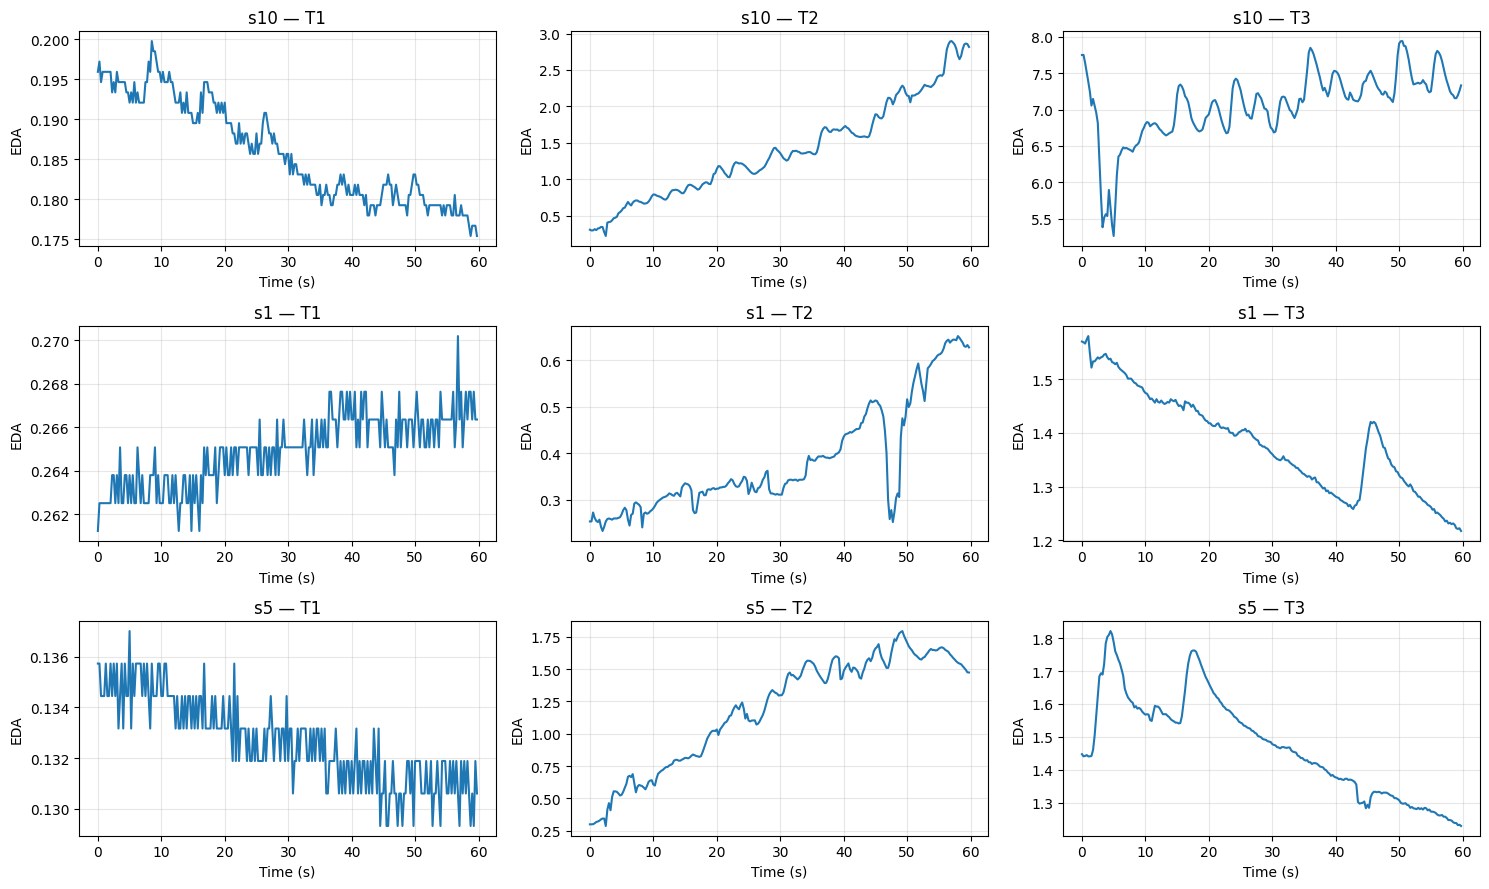

In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 4

examples = [
    ("s10", "T1"), ("s10", "T2"), ("s10", "T3"),
    ("s1", "T1"),  ("s1", "T2"),  ("s1", "T3"),
    ("s5", "T1"),  ("s5", "T2"),  ("s5", "T3"),
]

fig, axes = plt.subplots(3, 3, figsize=(15, 9))

for ax, (subject, task) in zip(axes.flat, examples):
    path = folder / f"eda_{subject}_{task}.csv"
    x = pd.read_csv(path, header=None).iloc[:, 0].astype(float)

    n = min(60 * fs, len(x))
    t = [i / fs for i in range(n)]

    ax.plot(t, x.iloc[:n])
    ax.set_title(f"{subject} — {task}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("EDA")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


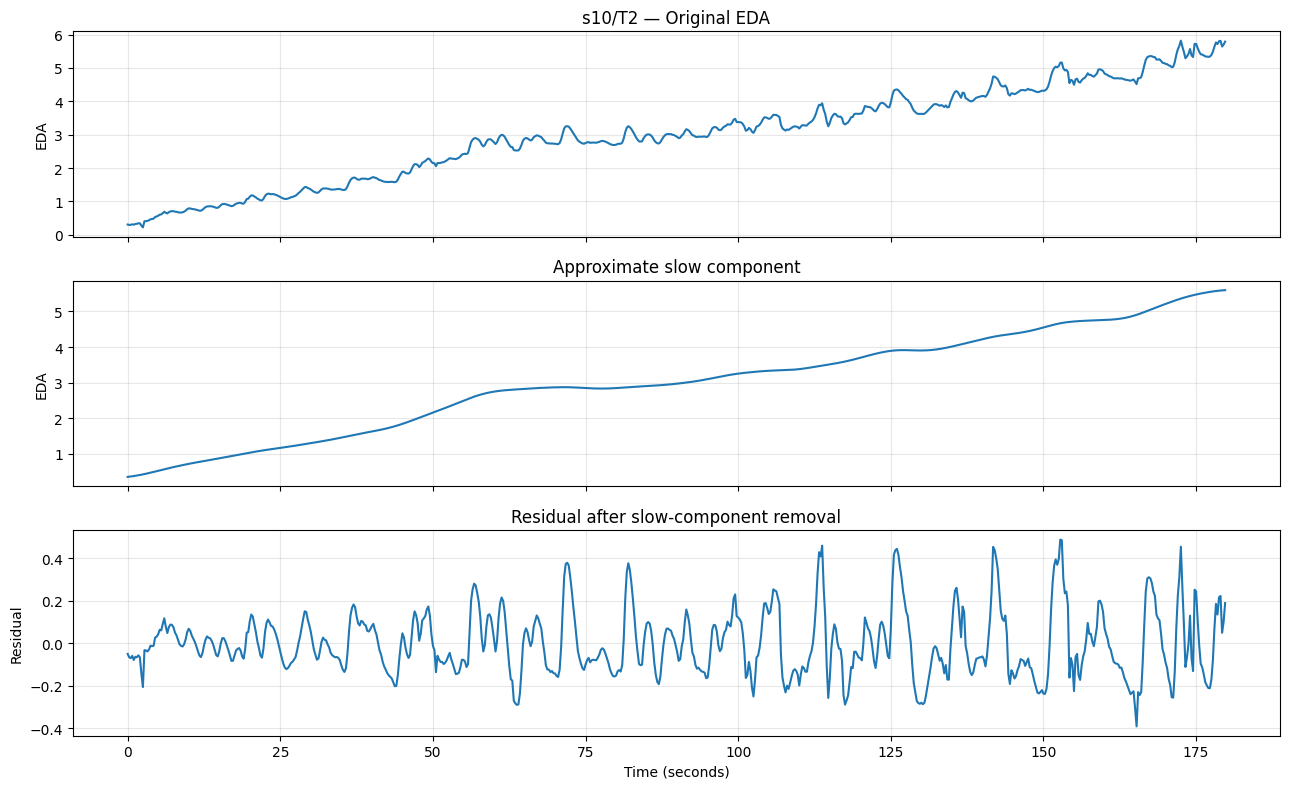

Original standard deviation: 1.40176
Residual standard deviation: 0.14982


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
fs = 4

subject, task = "s10", "T2"
path = folder / f"eda_{subject}_{task}.csv"

eda = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)
time = np.arange(len(eda)) / fs

# Approximate slow component with a low-pass filter
sos = butter(
    2, 0.05,
    btype="lowpass",
    fs=fs,
    output="sos"
)
tonic_approx = sosfiltfilt(sos, eda)

# Residual after removing the estimated slow component
phasic_residual = eda - tonic_approx

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(time, eda)
axes[0].set_title("s10/T2 — Original EDA")
axes[0].set_ylabel("EDA")

axes[1].plot(time, tonic_approx)
axes[1].set_title("Approximate slow component")
axes[1].set_ylabel("EDA")

axes[2].plot(time, phasic_residual)
axes[2].set_title("Residual after slow-component removal")
axes[2].set_ylabel("Residual")
axes[2].set_xlabel("Time (seconds)")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Original standard deviation:", round(float(np.std(eda)), 5))
print("Residual standard deviation:", round(float(np.std(phasic_residual)), 5))


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
out_dir = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)
out_dir.mkdir(parents=True, exist_ok=True)

fs = 4

# Preliminary low-pass approximation; not a validated EDA decomposition
sos = butter(
    2, 0.05,
    btype="lowpass",
    fs=fs,
    output="sos"
)

rows = []

for s in range(1, 11):
    for task in ["T1", "T2", "T3"]:
        path = folder / f"eda_s{s}_{task}.csv"
        x = pd.read_csv(path, header=None).iloc[:, 0].to_numpy(float)

        if not np.isfinite(x).all():
            raise ValueError(f"Non-finite EDA samples: s{s}/{task}")

        tonic = sosfiltfilt(sos, x)
        residual = x - tonic

        rows.append({
            "subject_id": f"s{s}",
            "session_id": task,
            "eda_tonic_mean": float(np.mean(tonic)),
            "eda_tonic_std": float(np.std(tonic)),
            "eda_residual_std": float(np.std(residual)),
            "eda_residual_mean_abs_diff": float(
                np.mean(np.abs(np.diff(residual)))
            )
        })

features = pd.DataFrame(rows)

save_path = out_dir / "eda_tonic_residual_features_pilot.csv"
features.to_csv(save_path, index=False)

print("Saved:", save_path)
print("Shape:", features.shape)
print("\nFeature summaries by task:")
display(
    features.groupby("session_id")[
        [
            "eda_tonic_std",
            "eda_residual_std",
            "eda_residual_mean_abs_diff"
        ]
    ].agg(["mean", "median"]).round(5)
)

print("\nMissing values:", int(features.isna().sum().sum()))


Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/eda_tonic_residual_features_pilot.csv
Shape: (30, 6)

Feature summaries by task:


eda_tonic_std          eda_residual_std           \
                    mean   median             mean   median   
session_id                                                    
T1               0.00723  0.00348          0.00208  0.00114   
T2               0.28791  0.09780          0.03908  0.02033   
T3               0.12125  0.07046          0.04448  0.01826   

           eda_residual_mean_abs_diff           
                                 mean   median  
session_id                                      
T1                            0.00108  0.00105  
T2                            0.01035  0.00477  
T3                            0.01025  0.00390


Missing values: 0


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

features = pd.read_csv(
    base / "eda_tonic_residual_features_pilot.csv"
)

for feature in [
    "eda_tonic_std",
    "eda_residual_std",
    "eda_residual_mean_abs_diff"
]:
    wide = features.pivot(
        index="subject_id",
        columns="session_id",
        values=feature
    )

    print(f"\n{feature}: participant-level values")
    display(wide.round(5))

    print("T2 > T1:", int((wide["T2"] > wide["T1"]).sum()), "/ 10")
    print("T3 > T1:", int((wide["T3"] > wide["T1"]).sum()), "/ 10")



eda_tonic_std: participant-level values


session_id,T1,T2,T3
subject_id,,,
s1,0.00347,0.59589,0.24207
s10,0.00775,1.39091,0.29025
s2,0.00908,0.03592,0.05366
s3,0.00158,0.00403,0.00723
s4,0.01436,0.02062,0.01054
s5,0.00348,0.43858,0.27050
s6,0.00261,0.15729,0.08726
s7,0.02512,0.19375,0.20585
s8,0.00234,0.00385,0.01161


T2 > T1: 10 / 10
T3 > T1: 9 / 10

eda_residual_std: participant-level values


session_id,T1,T2,T3
subject_id,,,
s1,0.00088,0.05376,0.01231
s10,0.00154,0.14982,0.26083
s2,0.00193,0.01132,0.02384
s3,0.00089,0.00151,0.00292
s4,0.00997,0.00413,0.00363
s5,0.00117,0.06839,0.03497
s6,0.00090,0.02933,0.02437
s7,0.00148,0.05996,0.06549
s8,0.00089,0.00471,0.01268


T2 > T1: 9 / 10
T3 > T1: 9 / 10

eda_residual_mean_abs_diff: participant-level values


session_id,T1,T2,T3
subject_id,,,
s1,0.00091,0.01299,0.00268
s10,0.00102,0.04269,0.06819
s2,0.00091,0.00188,0.00410
s3,0.00116,0.00122,0.00129
s4,0.00152,0.00149,0.00134
s5,0.00111,0.01989,0.00458
s6,0.00092,0.00731,0.00370
s7,0.00095,0.01219,0.00930
s8,0.00124,0.00167,0.00577


T2 > T1: 9 / 10
T3 > T1: 9 / 10


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

original = pd.read_csv(
    base / "physiology_recording_level_pilot.csv"
)

eda = pd.read_csv(
    base / "eda_tonic_residual_features_pilot.csv"
)

keys = ["subject_id", "session_id"]

assert not original.duplicated(keys).any()
assert not eda.duplicated(keys).any()
assert len(original) == 30
assert len(eda) == 30

new_features = [
    "eda_tonic_std",
    "eda_residual_std",
    "eda_residual_mean_abs_diff"
]

merged = original.merge(
    eda[keys + new_features],
    on=keys,
    how="left",
    validate="one_to_one"
)

assert len(merged) == 30
assert merged[new_features].notna().all().all()

out = base / "physiology_recording_level_enriched.csv"
merged.to_csv(out, index=False)

print("Saved:", out)
print("Shape:", merged.shape)
print("Missing values:", int(merged.isna().sum().sum()))
print("Unique participants:", merged["subject_id"].nunique())
print("\nNew EDA features:")
display(merged[keys + new_features].head(10))


Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/physiology_recording_level_enriched.csv
Shape: (30, 31)
Missing values: 0
Unique participants: 10

New EDA features:


,subject_id,session_id,eda_tonic_std,eda_residual_std,eda_residual_mean_abs_diff
0,s1,T1,0.003471,0.000882,0.000909
1,s1,T2,0.595888,0.053760,0.012985
2,s1,T3,0.242074,0.012306,0.002683
3,s10,T1,0.007752,0.001540,0.001020
4,s10,T2,1.390906,0.149816,0.042695
5,s10,T3,0.290249,0.260833,0.068195
6,s2,T1,0.009078,0.001927,0.000905
7,s2,T2,0.035919,0.011324,0.001877
8,s2,T3,0.053656,0.023842,0.004096
9,s3,T1,0.001582,0.000892,0.001164


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

questionnaire = pd.read_csv(
    base / "questionnaire_interpreted_pilot.csv"
)

metadata = pd.read_csv(
    base / "participant_metadata_structured.csv"
)

print("Questionnaire columns:")
print(questionnaire.columns.tolist())

print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nQuestionnaire dimensions:")
print(questionnaire["dimension"].value_counts())

print("\nParticipant group distribution:")
print(metadata["group"].value_counts())

print("\nQuestionnaire change summary:")
display(
    questionnaire.groupby("dimension")[
        "change_post_minus_pre"
    ].agg(["count", "mean", "median", "std"]).round(3)
)

print("\nQuestionnaire changes by participant:")
display(
    questionnaire.pivot(
        index="subject_id",
        columns="dimension",
        values="change_post_minus_pre"
    ).round(3)
)


Questionnaire columns:
['subject_id', 'dimension', 'pre_session', 'post_session', 'change_post_minus_pre']

Metadata columns:
['subject_id', 'group', 'date', 'time', 'sex']

Questionnaire dimensions:
dimension
cognitive_anxiety    10
somatic_anxiety      10
self_confidence      10
Name: count, dtype: int64

Participant group distribution:
group
ctrl    6
test    4
Name: count, dtype: int64

Questionnaire change summary:


,count,mean,median,std
dimension,,,,
cognitive_anxiety,10,0.143,0.214,0.508
self_confidence,10,-0.256,-0.223,0.367
somatic_anxiety,10,0.314,0.285,0.355



Questionnaire changes by participant:


dimension,cognitive_anxiety,self_confidence,somatic_anxiety
subject_id,,,
s1,1.143,-1.000,0.857
s10,0.571,-0.444,0.714
s2,0.429,0.111,0.000
s3,-0.428,-0.223,0.000
s4,0.286,-0.223,0.571
s5,0.286,0.000,0.000
s6,-0.285,0.333,0.428
s7,-0.286,-0.222,-0.143
s8,0.143,-0.444,0.143


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

questionnaire = pd.read_csv(
    base / "questionnaire_interpreted_pilot.csv"
)

metadata = pd.read_csv(
    base / "participant_metadata_structured.csv"
)

df = questionnaire.merge(
    metadata[["subject_id", "group"]],
    on="subject_id",
    how="left",
    validate="many_to_one"
)

# Descriptive group comparison
summary = (
    df.groupby(["group", "dimension"])["change_post_minus_pre"]
      .agg(["count", "mean", "median", "std"])
      .round(3)
)

print("Questionnaire changes by experimental group:")
display(summary)

# Save the analysis
out = base / "questionnaire_changes_by_group.csv"
summary.to_csv(out)

print("Saved:", out)


Questionnaire changes by experimental group:


count   mean  median    std
group dimension                                     
ctrl  cognitive_anxiety      6  0.119   0.214  0.398
      self_confidence        6 -0.204  -0.222  0.227
      somatic_anxiety        6  0.119   0.000  0.305
test  cognitive_anxiety      4  0.179   0.001  0.713
      self_confidence        4 -0.334  -0.334  0.552
      somatic_anxiety        4  0.607   0.572  0.180

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/questionnaire_changes_by_group.csv


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(
    base / "physiology_recording_level_enriched.csv"
)

# Verify one row per participant-task combination
assert len(df) == 30
assert df["subject_id"].nunique() == 10
assert not df.duplicated(["subject_id", "session_id"]).any()

# Group label must be consistent within each participant
assert (
    df.groupby("subject_id")["group"].nunique().max() == 1
)

participants = (
    df[["subject_id", "group"]]
    .drop_duplicates()
    .sort_values("subject_id")
    .reset_index(drop=True)
)

print("Participant-level labels:")
display(participants)

print("\nGroup counts:")
print(participants["group"].value_counts())

print("\nRecordings per participant:")
display(df.groupby("subject_id").size().rename("recordings"))

print("\nValidation checks passed.")


Participant-level labels:


,subject_id,group
0,s1,test
1,s10,ctrl
2,s2,ctrl
3,s3,ctrl
4,s4,test
5,s5,ctrl
6,s6,test
7,s7,ctrl
8,s8,ctrl
9,s9,test



Group counts:
group
ctrl    6
test    4
Name: count, dtype: int64

Recordings per participant:


,recordings
subject_id,
s1,3
s10,3
s2,3
s3,3
s4,3
s5,3
s6,3
s7,3
s8,3



Validation checks passed.


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(
    base / "physiology_recording_level_enriched.csv"
)

# Identify metadata and physiological feature columns
metadata_cols = {
    "subject_id", "session_id", "group", "sex"
}
feature_cols = [
    col for col in df.columns
    if col not in metadata_cols
]

print("Dataset shape:", df.shape)
print("Number of feature columns:", len(feature_cols))
print("\nFeature columns:")
for col in feature_cols:
    print("-", col)

print("\nMissing feature values:", df[feature_cols].isna().sum().sum())
print("Infinite feature values:",
      (~df[feature_cols].map(
          lambda x: pd.notna(x) and abs(x) != float("inf")
      )).sum().sum())


Dataset shape: (30, 31)
Number of feature columns: 27

Feature columns:
- bvp_samples
- eda_samples
- bvp_mean
- bvp_std
- bvp_min
- bvp_max
- bvp_median
- bvp_iqr
- bvp_skew
- bvp_kurtosis
- bvp_rms
- bvp_mean_abs_diff
- bvp_diff_std
- eda_mean
- eda_std
- eda_min
- eda_max
- eda_median
- eda_iqr
- eda_skew
- eda_kurtosis
- eda_rms
- eda_mean_abs_diff
- eda_diff_std
- eda_tonic_std
- eda_residual_std
- eda_residual_mean_abs_diff

Missing feature values: 0
Infinite feature values: 0


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    confusion_matrix, classification_report
)

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(
    base / "physiology_recording_level_enriched.csv"
)

metadata_cols = {"subject_id", "session_id", "group", "sex"}
feature_cols = [
    c for c in df.columns if c not in metadata_cols
]

# One row per participant: average their T1, T2 and T3 features
participant_df = (
    df.groupby(["subject_id", "group"], as_index=False)[feature_cols]
      .mean()
)

X = participant_df[feature_cols]
y = participant_df["group"]

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=2000)
)

loo = LeaveOneOut()
predictions = cross_val_predict(model, X, y, cv=loo)

print("Participants:", len(participant_df))
print("Features:", len(feature_cols))
print("LOSO accuracy:", round(accuracy_score(y, predictions), 3))
print(
    "LOSO balanced accuracy:",
    round(balanced_accuracy_score(y, predictions), 3)
)

print("\nClassification report:")
print(classification_report(
    y, predictions, labels=["ctrl", "test"], zero_division=0
))

print("Confusion matrix (rows=true, columns=predicted; ctrl, test):")
print(confusion_matrix(y, predictions, labels=["ctrl", "test"]))

print("\nParticipant-level predictions:")
print(pd.DataFrame({
    "subject_id": participant_df["subject_id"],
    "actual_group": y,
    "predicted_group": predictions
}).to_string(index=False))


Participants: 10
Features: 27
LOSO accuracy: 0.7
LOSO balanced accuracy: 0.667

Classification report:
              precision    recall  f1-score   support

        ctrl       0.71      0.83      0.77         6
        test       0.67      0.50      0.57         4

    accuracy                           0.70        10
   macro avg       0.69      0.67      0.67        10
weighted avg       0.70      0.70      0.69        10

Confusion matrix (rows=true, columns=predicted; ctrl, test):
[[5 1]
 [2 2]]

Participant-level predictions:
subject_id actual_group predicted_group
        s1         test            ctrl
       s10         ctrl            ctrl
        s2         ctrl            test
        s3         ctrl            ctrl
        s4         test            test
        s5         ctrl            ctrl
        s6         test            ctrl
        s7         ctrl            ctrl
        s8         ctrl            ctrl
        s9         test            test


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import pandas as pd

base = "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
df = pd.read_csv(f"{base}/physiology_recording_level_enriched.csv")

metadata_cols = {"subject_id", "session_id", "group", "sex"}

all_features = [
    c for c in df.columns if c not in metadata_cols
]

extra_features = [
    "eda_tonic_std",
    "eda_residual_std",
    "eda_residual_mean_abs_diff"
]

baseline_features = [
    c for c in all_features if c not in extra_features
]

# One row per participant; keep participants independent
participant_df = (
    df.groupby(["subject_id", "group"], as_index=False)[all_features]
      .mean()
)

y = participant_df["group"]
loo = LeaveOneOut()

def evaluate(features):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            class_weight="balanced",
            max_iter=2000
        )
    )
    pred = cross_val_predict(
        model, participant_df[features], y, cv=loo
    )
    return (
        accuracy_score(y, pred),
        balanced_accuracy_score(y, pred)
    )

baseline_result = evaluate(baseline_features)
enriched_result = evaluate(all_features)

print("Feature-set comparison")
print("----------------------")
print(f"Baseline features ({len(baseline_features)}):")
print(f"  Accuracy:          {baseline_result[0]:.3f}")
print(f"  Balanced accuracy: {baseline_result[1]:.3f}")

print(f"\nEnriched features ({len(all_features)}):")
print(f"  Accuracy:          {enriched_result[0]:.3f}")
print(f"  Balanced accuracy: {enriched_result[1]:.3f}")


Feature-set comparison
----------------------
Baseline features (24):
  Accuracy:          0.700
  Balanced accuracy: 0.667

Enriched features (27):
  Accuracy:          0.700
  Balanced accuracy: 0.667


In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(
    base / "physiology_recording_level_enriched.csv"
)

features = [
    "bvp_std",
    "eda_std",
    "eda_mean_abs_diff",
    "eda_tonic_std",
    "eda_residual_std",
]

wide = df.pivot(
    index=["subject_id", "group"],
    columns="session_id",
    values=features
)

for task in ["T2", "T3"]:
    changes = pd.DataFrame(index=wide.index)

    for feature in features:
        changes[feature] = (
            wide[(feature, task)] - wide[(feature, "T1")]
        )

    print(f"\n{task} minus T1 (rest):")
    print(
        changes.groupby(level="group")
        .agg(["mean", "median"])
        .round(4)
        .to_string()
    )

    print("\nParticipants with positive changes:")
    print(
        changes.groupby(level="group")
        .apply(lambda g: (g > 0).sum())
        .to_string()
    )



T2 minus T1 (rest):
       bvp_std          eda_std        eda_mean_abs_diff         eda_tonic_std         eda_residual_std        
          mean   median    mean median              mean  median          mean  median             mean  median
group                                                                                                          
ctrl   19.3464  15.8557  0.0843  0.039            0.0120  0.0053        0.3363  0.0977           0.0480  0.0339
test   28.9255  34.0809  0.0442  0.028            0.0052  0.0040        0.1973  0.0952           0.0205  0.0176

Participants with positive changes:
       bvp_std  eda_std  eda_mean_abs_diff  eda_tonic_std  eda_residual_std
group                                                                      
ctrl         6        6                  6              6                 6
test         3        4                  4              4                 3

T3 minus T1 (rest):
       bvp_std         eda_std         eda_mean_abs_diff 

In [ ]:

from pathlib import Path
import pandas as pd

base = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

df = pd.read_csv(
    base / "physiology_recording_level_enriched.csv"
)

features = [
    "eda_tonic_std",
    "eda_residual_std",
    "eda_residual_mean_abs_diff",
]

print("EDA feature distributions:")
print(
    df[features]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95])
    .round(5)
    .to_string()
)

print("\nLargest tonic EDA variability values:")
print(
    df.nlargest(5, "eda_tonic_std")[
        ["subject_id", "session_id", "group", "eda_tonic_std"]
    ].to_string(index=False)
)


EDA feature distributions:
       eda_tonic_std  eda_residual_std  eda_residual_mean_abs_diff
count       30.00000          30.00000                    30.00000
mean         0.13880           0.02854                     0.00723
std          0.27798           0.05427                     0.01424
min          0.00158           0.00088                     0.00091
25%          0.00483           0.00152                     0.00118
50%          0.02287           0.00626                     0.00161
75%          0.18463           0.02809                     0.00547
90%          0.30508           0.06578                     0.01368
95%          0.52510           0.11318                     0.03243
max          1.39091           0.26083                     0.06819

Largest tonic EDA variability values:
subject_id session_id group  eda_tonic_std
       s10         T2  ctrl       1.390906
        s1         T2  test       0.595888
        s5         T2  ctrl       0.438578
       s10         T3  ct

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

raw = Path("/content/drive/MyDrive/ubfc_test_upload.")
out = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

features = pd.read_csv(
    out / "physiology_recording_level_enriched.csv"
)

top = features.nlargest(5, "eda_tonic_std")

rows = []

for _, r in top.iterrows():
    subject = r["subject_id"]
    task = r["session_id"]

    path = raw / f"eda_{subject}_{task}.csv"
    signal = pd.read_csv(path, header=None).iloc[:, 0]
    signal = pd.to_numeric(signal, errors="coerce").dropna()

    rows.append({
        "subject_id": subject,
        "session_id": task,
        "eda_tonic_std": r["eda_tonic_std"],
        "raw_min": signal.min(),
        "raw_max": signal.max(),
        "raw_std": signal.std(),
        "raw_median": signal.median(),
        "sample_count": len(signal),
    })

print(pd.DataFrame(rows).round(5).to_string(index=False))


subject_id session_id  eda_tonic_std  raw_min  raw_max  raw_std  raw_median  sample_count
       s10         T2        1.39091  0.22024   5.8172  1.40273     3.01430           720
        s1         T2        0.59589  0.23306   2.1930  0.59898     0.70970           720
        s5         T2        0.43858  0.28683   2.2543  0.44499     1.88230           720
       s10         T3        0.29025  5.26400   8.2511  0.41718     7.21375           720
        s5         T3        0.27050  0.78911   1.8213  0.27520     1.07860           720


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt

raw = Path("/content/drive/MyDrive/ubfc_test_upload.")

for subject, task in [("s10", "T2"), ("s1", "T2"), ("s5", "T3")]:
    path = raw / f"eda_{subject}_{task}.csv"
    x = pd.to_numeric(
        pd.read_csv(path, header=None).iloc[:, 0],
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    fs = 4.0
    sos = butter(
        2, 0.05, btype="lowpass", fs=fs, output="sos"
    )
    tonic = sosfiltfilt(sos, x)
    residual = x - tonic

    reconstruction_error = np.max(
        np.abs(x - (tonic + residual))
    )

    print(f"\n{subject}/{task}")
    print(f"Raw standard deviation:      {np.std(x):.5f}")
    print(f"Tonic standard deviation:    {np.std(tonic):.5f}")
    print(f"Residual standard deviation: {np.std(residual):.5f}")
    print(f"Reconstruction error:        {reconstruction_error:.10f}")



s10/T2
Raw standard deviation:      1.40176
Tonic standard deviation:    1.39091
Residual standard deviation: 0.14982
Reconstruction error:        0.0000000000

s1/T2
Raw standard deviation:      0.59856
Tonic standard deviation:    0.59589
Residual standard deviation: 0.05376
Reconstruction error:        0.0000000000

s5/T3
Raw standard deviation:      0.27501
Tonic standard deviation:    0.27050
Residual standard deviation: 0.03497
Reconstruction error:        0.0000000000


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

raw = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Video files found:")
for p in sorted(raw.rglob("*")):
    if p.is_file() and p.suffix.lower() in {
        ".mp4", ".avi", ".mov", ".mkv"
    }:
        print(p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Video files found:
/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi


In [ ]:
import cv2
from pathlib import Path

video_path = Path(
    "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi"
)

cap = cv2.VideoCapture(str(video_path))

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {video_path}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps > 0 else 0

print("Video:", video_path.name)
print(f"FPS: {fps:.3f}")
print(f"Frame count: {frame_count}")
print(f"Resolution: {width} x {height}")
print(f"Duration: {duration:.2f} seconds")
print(f"Duration: {duration / 60:.2f} minutes")

cap.release()

Video: vid_s1_T2.avi
FPS: 35.138
Frame count: 6325
Resolution: 1024 x 1024
Duration: 180.00 seconds
Duration: 3.00 minutes


In [ ]:
import cv2
from pathlib import Path

video_path = Path(
    "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi"
)

cap = cv2.VideoCapture(str(video_path))

# OpenCV's built-in frontal-face detector
cascade_path = (
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)
face_detector = cv2.CascadeClassifier(cascade_path)

if face_detector.empty():
    raise RuntimeError("Could not load OpenCV face detector.")

fps = cap.get(cv2.CAP_PROP_FPS)
sample_times = [0, 10, 30, 60, 90, 120, 150, 175]

print("Face-detection smoke test:")

for seconds in sample_times:
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, frame = cap.read()

    if not ok:
        print(f"{seconds:>3}s: frame read failed")
        continue

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(40, 40)
    )

    print(f"{seconds:>3}s: {len(faces)} face(s) detected")

cap.release()

Face-detection smoke test:
  0s: 0 face(s) detected
 10s: 1 face(s) detected
 30s: 1 face(s) detected
 60s: 1 face(s) detected
 90s: 1 face(s) detected
120s: 1 face(s) detected
150s: 1 face(s) detected
175s: 1 face(s) detected


In [ ]:
%pip install -q mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 10.0 MB/s eta 0:00:00


In [ ]:
import mediapipe as mp

print("MediaPipe version:", mp.__version__)
print("Face Landmarker available:",
      hasattr(mp, "tasks"))

MediaPipe version: 1.1.1
Face Landmarker available: True


In [ ]:
from pathlib import Path
import urllib.request

model_dir = Path("/content/face_landmarker")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "face_landmarker.task"

url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not model_path.exists():
    urllib.request.urlretrieve(url, model_path)

print("Model exists:", model_path.exists())
print("Model size:", round(model_path.stat().st_size / (1024 * 1024), 2), "MB")

Model exists: True
Model size: 3.58 MB


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
from pathlib import Path

video = "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi"
model = "/content/face_landmarker/face_landmarker.task"

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path=model
    ),
    running_mode=mp.tasks.vision.RunningMode.VIDEO,
    num_faces=1
)

cap = cv2.VideoCapture(video)
fps = cap.get(cv2.CAP_PROP_FPS)
duration = cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps

with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    detected = 0

    for i, t in enumerate(np.linspace(1, duration - 1, 20)):
        cap.set(cv2.CAP_PROP_POS_MSEC, float(t * 1000))
        ok, frame = cap.read()

        if ok:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )
            result = detector.detect_for_video(image, int(t * 1000))
            detected += bool(result.face_landmarks)

        print(f"Frame {i+1}/20 | Faces detected so far: {detected}")

cap.release()
print("Test complete.")

Frame 1/20 | Faces detected so far: 1
Frame 2/20 | Faces detected so far: 2
Frame 3/20 | Faces detected so far: 3
Frame 4/20 | Faces detected so far: 4
Frame 5/20 | Faces detected so far: 5
Frame 6/20 | Faces detected so far: 6
Frame 7/20 | Faces detected so far: 7
Frame 8/20 | Faces detected so far: 8
Frame 9/20 | Faces detected so far: 9
Frame 10/20 | Faces detected so far: 10
Frame 11/20 | Faces detected so far: 11
Frame 12/20 | Faces detected so far: 12
Frame 13/20 | Faces detected so far: 13
Frame 14/20 | Faces detected so far: 14
Frame 15/20 | Faces detected so far: 15
Frame 16/20 | Faces detected so far: 16
Frame 17/20 | Faces detected so far: 17
Frame 18/20 | Faces detected so far: 18
Frame 19/20 | Faces detected so far: 19
Frame 20/20 | Faces detected so far: 20
Test complete.


In [ ]:
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
from pathlib import Path

video = Path(
    "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi"
)
model = Path("/content/face_landmarker/face_landmarker.task")
out = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/video_test"
)
out.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(video))
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration = total_frames / fps

sample_every = max(1, round(fps / 5))
rows = []
previous = None
sampled = detected = 0

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path=str(model)),
    running_mode=mp.tasks.vision.RunningMode.VIDEO,
    num_faces=1,
)

with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    frame_index = 0

    while True:
        ok, frame = cap.read()
        if not ok:
            break

        if frame_index % sample_every == 0:
            t = frame_index / fps
            row = {
                "subject_id": "s1",
                "session_id": "T2",
                "timestamp_sec": t,
                "face_detected": 0,
                "landmark_motion_mean": np.nan,
            }

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )
            result = detector.detect_for_video(
                image, int(round(t * 1000))
            )

            if result.face_landmarks:
                coords = np.array(
                    [[p.x, p.y, p.z] for p in result.face_landmarks[0]],
                    dtype=float
                )

                xmin, ymin = coords[:, :2].min(axis=0)
                xmax, ymax = coords[:, :2].max(axis=0)
                scale = max(xmax - xmin, ymax - ymin, 1e-8)

                coords[:, 0] = (coords[:, 0] - xmin) / scale
                coords[:, 1] = (coords[:, 1] - ymin) / scale
                coords[:, 2] /= scale

                row["face_detected"] = 1
                for i, (x, y, z) in enumerate(coords):
                    row[f"lm{i}_x"] = x
                    row[f"lm{i}_y"] = y
                    row[f"lm{i}_z"] = z

                if previous is not None:
                    row["landmark_motion_mean"] = float(
                        np.linalg.norm(coords - previous, axis=1).mean()
                    )
                previous = coords
                detected += 1

            rows.append(row)
            sampled += 1

            if sampled % 100 == 0:
                print(f"Processed {sampled} sampled frames...")

        frame_index += 1

cap.release()

features = pd.DataFrame(rows)
features.to_csv(out / "s1_T2_video_features.csv", index=False)

quality = pd.DataFrame([{
    "subject_id": "s1",
    "session_id": "T2",
    "video_filename": video.name,
    "duration_sec": duration,
    "original_fps": fps,
    "sample_fps_actual": sampled / duration,
    "sampled_frames": sampled,
    "detected_frames": detected,
    "missed_frames": sampled - detected,
    "detection_rate": detected / sampled if sampled else 0,
}])
quality.to_csv(out / "s1_T2_video_quality.csv", index=False)

print("\nQuality report:")
print(quality.to_string(index=False))
print("\nFeature table shape:", features.shape)
print("Saved folder:", out)

Processed 100 sampled frames...
Processed 200 sampled frames...
Processed 300 sampled frames...
Processed 400 sampled frames...
Processed 500 sampled frames...
Processed 600 sampled frames...
Processed 700 sampled frames...
Processed 800 sampled frames...
Processed 900 sampled frames...

Quality report:
subject_id session_id video_filename  duration_sec  original_fps  sample_fps_actual  sampled_frames  detected_frames  missed_frames  detection_rate
        s1         T2  vid_s1_T2.avi    180.004553        35.138           5.022095             904              904              0             1.0

Feature table shape: (904, 1439)
Saved folder: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_test


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

out = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/video_test"
)

features = pd.read_csv(out / "s1_T2_video_features.csv")
quality = pd.read_csv(out / "s1_T2_video_quality.csv")

numeric = features.select_dtypes(include="number")

print("Rows:", len(features))
print("Columns:", len(features.columns))
print("Duplicate timestamps:",
      features["timestamp_sec"].duplicated().sum())
print("Non-increasing timestamps:",
      (features["timestamp_sec"].diff().dropna() <= 0).sum())
print("Missing numeric values:", numeric.isna().sum().sum())
print("Infinite numeric values:",
      np.isinf(numeric.to_numpy()).sum())
print("Face detection rate:",
      round(features["face_detected"].mean(), 4))
print("Motion values available:",
      features["landmark_motion_mean"].notna().sum())

print("\nQuality report:")
print(quality.to_string(index=False))

Rows: 904
Columns: 1439
Duplicate timestamps: 0
Non-increasing timestamps: 0
Missing numeric values: 1
Infinite numeric values: 0
Face detection rate: 1.0
Motion values available: 903

Quality report:
subject_id session_id video_filename  duration_sec  original_fps  sample_fps_actual  sampled_frames  detected_frames  missed_frames  detection_rate
        s1         T2  vid_s1_T2.avi    180.004553        35.138           5.022095             904              904              0             1.0


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

folder = Path("/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10")

recordings = ["s3_T3", "s5_T3", "s6_T3"]
results = []

for rec in recordings:
    features_path = folder / f"{rec}_video_features.csv"
    quality_path = folder / f"{rec}_video_quality.csv"

    if not features_path.exists() or not quality_path.exists():
        print(f"Missing files for {rec}: check folder path.")
        continue

    df = pd.read_csv(features_path)
    q = pd.read_csv(quality_path).iloc[0]

    landmark_cols = [
        c for c in df.columns
        if c.startswith("lm") and c.endswith(("_x", "_y", "_z"))
    ]
    numeric = df.select_dtypes(include="number")

    # Missing landmark values on missed-face frames are expected.
    missing_landmarks = (
        df.loc[df["face_detected"] == 1, landmark_cols].isna().sum().sum()
        if landmark_cols else np.nan
    )

    results.append({
        "recording": rec,
        "rows": len(df),
        "duplicate_timestamps": df["timestamp_sec"].duplicated().sum(),
        "non_increasing_timestamps": (
            df["timestamp_sec"].

_IncompleteInputError: incomplete input (789950154.py, line 38)

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

folder = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

recordings = ["s3_T3", "s5_T3", "s6_T3"]
results = []

for rec in recordings:
    fp = folder / f"{rec}_video_features.csv"
    qp = folder / f"{rec}_video_quality.csv"

    if not fp.exists() or not qp.exists():
        print(f"{rec}: files not found in {folder}")
        continue

    df = pd.read_csv(fp)
    q = pd.read_csv(qp).iloc[0]

    landmark_cols = [
        c for c in df.columns
        if c.startswith("lm") and c.endswith(("_x", "_y", "_z"))
    ]
    numeric = df.select_dtypes(include="number")

    detected = df["face_detected"].eq(1)
    missed = ~detected

    missing_detected_landmarks = (
        int(df.loc[detected, landmark_cols].isna().sum().sum())
        if landmark_cols else 0
    )
    missing_missed_landmarks = (
        int(df.loc[missed, landmark_cols].isna().sum().sum())
        if landmark_cols else 0
    )

    results.append({
        "recording": rec,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_timestamps": int(df["timestamp_sec"].duplicated().sum()),
        "non_increasing_timestamps": int(
            (df["timestamp_sec"].diff().dropna() <= 0).sum()
        ),
        "missed_faces": int(missed.sum()),
        "detection_rate": round(float(detected.mean()), 4),
        "missing_landmarks_detected_frames": missing_detected_landmarks,
        "missing_landmarks_missed_frames": missing_missed_landmarks,
        "missing_motion_values": int(df["landmark_motion_mean"].isna().sum()),
        "infinite_values": int(np.isinf(numeric.to_numpy()).sum()),
        "quality_counts_match": (
            len(df) == int(q["sampled_frames"])
            and int(detected.sum()) == int(q["detected_frames"])
        ),
    })

if results:
    print(pd.DataFrame(results).to_string(index=False))
else:
    print("No recordings validated. Check the folder path and filenames.")

s3_T3: files not found in /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10
s5_T3: files not found in /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10
s6_T3: files not found in /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10
No recordings validated. Check the folder path and filenames.


In [ ]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10"
)

print("Folder exists:", folder.exists())

if folder.exists():
    for f in sorted(folder.glob("*T3*video*.csv")):
        print(f.name)
else:
    print("Folder path is incorrect.")

Folder exists: True


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for name in [
    "s3_T3_video_features.csv",
    "s3_T3_video_quality.csv",
    "s5_T3_video_features.csv",
    "s5_T3_video_quality.csv",
    "s6_T3_video_features.csv",
    "s6_T3_video_quality.csv",
]:
    matches = list(root.rglob(name))
    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND:", name)

FOUND: /content/drive/MyDrive/ubfc_test_upload./s3_T3_video_features.csv
FOUND: /content/drive/MyDrive/ubfc_test_upload./s3_T3_video_quality.csv
FOUND: /content/drive/MyDrive/ubfc_test_upload./s5_T3_video_features.csv
FOUND: /content/drive/MyDrive/ubfc_test_upload./s5_T3_video_quality.csv
FOUND: /content/drive/MyDrive/ubfc_test_upload./s6_T3_video_features.csv
FOUND: /content/drive/MyDrive/ubfc_test_upload./s6_T3_video_quality.csv


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

results = []

for rec in ["s3_T3", "s5_T3", "s6_T3"]:
    fp = folder / f"{rec}_video_features.csv"
    qp = folder / f"{rec}_video_quality.csv"

    df = pd.read_csv(fp)
    q = pd.read_csv(qp).iloc[0]

    detected = df["face_detected"].eq(1)
    missed = ~detected

    landmark_cols = [
        c for c in df.columns
        if c.endswith(("_x", "_y", "_z"))
        and c not in ["landmark_motion_mean"]
    ]
    numeric = df.select_dtypes(include="number")

    results.append({
        "recording": rec,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_timestamps": int(
            df["timestamp_sec"].duplicated().sum()
        ),
        "non_increasing_timestamps": int(
            (df["timestamp_sec"].diff().dropna() <= 0).sum()
        ),
        "missed_faces": int(missed.sum()),
        "detection_rate_pct": round(100 * detected.mean(), 2),
        "missing_landmarks_on_detected_frames": int(
            df.loc[detected, landmark_cols].isna().sum().sum()
        ),
        "missing_landmarks_on_missed_frames": int(
            df.loc[missed, landmark_cols].isna().sum().sum()
        ),
        "missing_motion_values": int(
            df["landmark_motion_mean"].isna().sum()
        ),
        "infinite_values": int(np.isinf(numeric.to_numpy()).sum()),
        "quality_counts_match": (
            len(df) == int(q["sampled_frames"])
            and int(detected.sum()) == int(q["detected_frames"])
        )
    })

print(pd.DataFrame(results).to_string(index=False))

recording  rows  columns  duplicate_timestamps  non_increasing_timestamps  missed_faces  detection_rate_pct  missing_landmarks_on_detected_frames  missing_landmarks_on_missed_frames  missing_motion_values  infinite_values  quality_counts_match
    s3_T3   900     1439                     0                          0             0              100.00                                     0                                   0                      1                0                  True
    s5_T3   900     1439                     0                          0             3               99.67                                     0                                4302                      5                0                  True
    s6_T3   900     1439                     0                          0             0              100.00                                     0                                   0                      1                0                  True


In [ ]:
from pathlib import Path

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

patterns = [
    "*physiological_features*.csv",
    "physiology_recording_level*.csv",
    "*metadata*.csv",
]

for pattern in patterns:
    print(f"\n--- {pattern} ---")
    matches = list(root.glob(pattern))
    if matches:
        for path in matches:
            print(path.name)
    else:
        print("No matching files found")


--- *physiological_features*.csv ---
s1_s10_physiological_features.csv
s1_s10_physiological_features_with_metadata.csv

--- physiology_recording_level*.csv ---
physiology_recording_level_pilot.csv
physiology_recording_level_enriched.csv

--- *metadata*.csv ---
participant_metadata.csv
participant_metadata_structured.csv
s1_s10_physiological_features_with_metadata.csv


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

files = [
    "s1_s10_physiological_features.csv",
    "physiology_recording_level_pilot.csv",
    "physiology_recording_level_enriched.csv",
]

for filename in files:
    path = root / filename
    df = pd.read_csv(path)

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))


FILE: s1_s10_physiological_features.csv
Shape: (930, 29)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'label', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'bvp_median', 'bvp_iqr', 'bvp_skew', 'bvp_kurtosis', 'bvp_rms', 'bvp_mean_abs_diff', 'bvp_diff_std', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'eda_median', 'eda_iqr', 'eda_skew', 'eda_kurtosis', 'eda_rms', 'eda_mean_abs_diff', 'eda_diff_std']

First 3 rows:
subject_id session_id  start_s  end_s      label  bvp_samples  eda_samples  bvp_mean   bvp_std  bvp_min  bvp_max  bvp_median  bvp_iqr  bvp_skew  bvp_kurtosis   bvp_rms  bvp_mean_abs_diff  bvp_diff_std  eda_mean  eda_std  eda_min  eda_max  eda_median  eda_iqr  eda_skew  eda_kurtosis  eda_rms  eda_mean_abs_diff  eda_diff_std
        s1         T1        0     30 unlabelled         1920          120 -0.023938 53.122281  -149.56    97.31      12.295  84.5525 -0.440849     -0.802990 53.122287           6.959536      8.960464  0.263733 0.

In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

phys = pd.read_csv(root / "s1_s10_physiological_features.csv")

video_folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for subject, session in [
    ("s3", "T3"),
    ("s5", "T3"),
    ("s6", "T3"),
]:
    p = phys[
        (phys["subject_id"] == subject) &
        (phys["session_id"] == session)
    ].copy()

    vf = pd.read_csv(
        video_folder / f"{subject}_{session}_video_features.csv"
    )

    print(f"\n--- {subject.upper()}/{session} ---")
    print("Physiology windows:", len(p))
    print("Physiology time range:", p["start_s"].min(), "to", p["end_s"].max(), "seconds")
    print("Video frames:", len(vf))
    print(
        "Video time range:",
        round(vf["timestamp_sec"].min(), 3),
        "to",
        round(vf["timestamp_sec"].max(), 3),
        "seconds"
    )
    print("Physiology window durations:", sorted(
        (p["end_s"] - p["start_s"]).unique()
    ))
    print("First 3 video timestamps:",
          vf["timestamp_sec"].head(3).tolist())


--- S3/T3 ---
Physiology windows: 31
Physiology time range: 0 to 180 seconds
Video frames: 900
Video time range: 0.0 to 179.8 seconds
Physiology window durations: [np.int64(30)]
First 3 video timestamps: [0.0, 0.2, 0.4]

--- S5/T3 ---
Physiology windows: 31
Physiology time range: 0 to 180 seconds
Video frames: 900
Video time range: 0.0 to 179.8 seconds
Physiology window durations: [np.int64(30)]
First 3 video timestamps: [0.0, 0.2, 0.4]

--- S6/T3 ---
Physiology windows: 31
Physiology time range: 0 to 180 seconds
Video frames: 900
Video time range: 0.0 to 179.8 seconds
Physiology window durations: [np.int64(30)]
First 3 video timestamps: [0.0, 0.2, 0.4]


In [ ]:
from pathlib import Path
import pandas as pd

video_folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for rec in ["s3_T3", "s5_T3", "s6_T3"]:
    df = pd.read_csv(video_folder / f"{rec}_video_features.csv")

    landmark_cols = [
        c for c in df.columns
        if c.endswith(("_x", "_y", "_z"))
    ]

    print(f"\n{rec}")
    print("Total columns:", len(df.columns))
    print("Timestamp column present:", "timestamp_sec" in df.columns)
    print("Face detection column present:", "face_detected" in df.columns)
    print("Motion column present:", "landmark_motion_mean" in df.columns)
    print("Coordinate columns:", len(landmark_cols))
    print("First 12 coordinate columns:", landmark_cols[:12])


s3_T3
Total columns: 1439
Timestamp column present: True
Face detection column present: True
Motion column present: True
Coordinate columns: 1434
First 12 coordinate columns: ['lm0_x', 'lm0_y', 'lm0_z', 'lm1_x', 'lm1_y', 'lm1_z', 'lm2_x', 'lm2_y', 'lm2_z', 'lm3_x', 'lm3_y', 'lm3_z']

s5_T3
Total columns: 1439
Timestamp column present: True
Face detection column present: True
Motion column present: True
Coordinate columns: 1434
First 12 coordinate columns: ['lm0_x', 'lm0_y', 'lm0_z', 'lm1_x', 'lm1_y', 'lm1_z', 'lm2_x', 'lm2_y', 'lm2_z', 'lm3_x', 'lm3_y', 'lm3_z']

s6_T3
Total columns: 1439
Timestamp column present: True
Face detection column present: True
Motion column present: True
Coordinate columns: 1434
First 12 coordinate columns: ['lm0_x', 'lm0_y', 'lm0_z', 'lm1_x', 'lm1_y', 'lm1_z', 'lm2_x', 'lm2_y', 'lm2_z', 'lm3_x', 'lm3_y', 'lm3_z']


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

phys_root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)
video_root = Path("/content/drive/MyDrive/ubfc_test_upload.")
out_path = phys_root / "video_physiology_fusion_pilot.csv"

phys = pd.read_csv(
    phys_root / "s1_s10_physiological_features.csv"
)

recordings = [("s3", "T3"), ("s5", "T3"), ("s6", "T3")]
fusion_parts = []

for subject, session in recordings:
    video = pd.read_csv(
        video_root / f"{subject}_{session}_video_features.csv"
    )

    p = phys[
        (phys["subject_id"] == subject) &
        (phys["session_id"] == session)
    ].copy()

    video["timestamp_sec"] = pd.to_numeric(
        video["timestamp_sec"], errors="coerce"
    )

    landmark_cols = [
        c for c in video.columns
        if c.endswith(("_x", "_y", "_z"))
    ]

    rows = []

    for _, window in p.iterrows():
        start, end = window["start_s"], window["end_s"]

        # Half-open windows avoid double-counting frames at boundaries.
        v = video[
            (video["timestamp_sec"] >= start) &
            (video["timestamp_sec"] < end)
        ].copy()

        detected = v["face_detected"].eq(1)
        valid = v.loc[detected]

        row = {
            "subject_id": subject,
            "session_id": session,
            "start_s": start,
            "end_s": end,
            "video_frames": len(v),
            "valid_face_frames": int(detected.sum()),
            "face_detection_rate": (
                float(detected.mean()) if len(v) else np.nan
            ),
            "video_motion_mean": (
                valid["landmark_motion_mean"].mean()
                if len(valid) else np.nan
            ),
            "video_motion_std": (
                valid["landmark_motion_mean"].std()
                if len(valid) > 1 else np.nan
            ),
        }

        # Summarize each coordinate only across detected frames.
        for col in landmark_cols:
            values = pd.to_numeric(
                valid[col], errors="coerce"
            ).dropna()
            row[f"{col}_mean"] = values.mean() if len(values) else np.nan
            row[f"{col}_std"] = values.std() if len(values) > 1 else np.nan

        rows.append(row)

    video_windows = pd.DataFrame(rows)

    merged = p.merge(
        video_windows,
        on=["subject_id", "session_id", "start_s", "end_s"],
        how="inner",
        validate="one_to_one"
    )

    fusion_parts.append(merged)

fusion = pd.concat(fusion_parts, ignore_index=True)
fusion.to_csv(out_path, index=False)

print("Saved:", out_path)
print("Fusion dataset shape:", fusion.shape)
print("\nRows per recording:")
print(fusion.groupby(["subject_id", "session_id"]).size())
print("\nFace detection rate by recording:")
print(
    fusion.groupby(["subject_id", "session_id"])[
        "face_detection_rate"
    ].mean()
)
print("\nMissing values in key video features:")
print(
    fusion[
        [
            "video_motion_mean",
            "face_detection_rate",
            "valid_face_frames"
        ]
    ].isna().sum()
)

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_pilot.csv
Fusion dataset shape: (93, 2902)

Rows per recording:
subject_id  session_id
s3          T3            31
s5          T3            31
s6          T3            31
dtype: int64

Face detection rate by recording:
subject_id  session_id
s3          T3            1.000000
s5          T3            0.996791
s6          T3            1.000000
Name: face_detection_rate, dtype: float64

Missing values in key video features:
video_motion_mean      0
face_detection_rate    0
valid_face_frames      0
dtype: int64


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

path = Path(
    "/content/drive/MyDrive/stress-recognition-project/"
    "outputs/ubfc_s1_s10/video_physiology_fusion_pilot.csv"
)

df = pd.read_csv(path)

print("Shape:", df.shape)

key_cols = ["subject_id", "session_id", "start_s", "end_s"]
print("Duplicate windows:", df.duplicated(key_cols).sum())

print("\nRows per recording:")
print(df.groupby(["subject_id", "session_id"]).size())

print("\nWindow duration counts:")
print((df["end_s"] - df["start_s"]).value_counts().to_dict())

print("\nMissing values in key columns:")
print(df[
    [
        "bvp_mean",
        "eda_mean",
        "video_motion_mean",
        "video_motion_std",
        "face_detection_rate",
        "valid_face_frames"
    ]
].isna().sum())

numeric = df.select_dtypes(include="number")
print("\nInfinite numerical values:", np.isinf(numeric.to_numpy()).sum())

print("\nFace detection rate range:")
print(
    df["face_detection_rate"].min(),
    "to",
    df["face_detection_rate"].max()
)

print("\nFirst five rows of selected columns:")
print(df[
    [
        "subject_id", "session_id", "start_s", "end_s",
        "bvp_mean", "eda_mean",
        "video_motion_mean", "face_detection_rate"
    ]
].head().to_string(index=False))

Shape: (93, 2902)
Duplicate windows: 0

Rows per recording:
subject_id  session_id
s3          T3            31
s5          T3            31
s6          T3            31
dtype: int64

Window duration counts:
{30: 93}

Missing values in key columns:
bvp_mean               0
eda_mean               0
video_motion_mean      0
video_motion_std       0
face_detection_rate    0
valid_face_frames      0
dtype: int64

Infinite numerical values: 0

Face detection rate range:
0.98 to 1.0

First five rows of selected columns:
subject_id session_id  start_s  end_s  bvp_mean  eda_mean  video_motion_mean  face_detection_rate
        s3         T3        0     30  0.144177  0.088695           0.014124                  1.0
        s3         T3        5     35  0.699672  0.085461           0.012171                  1.0
        s3         T3       10     40  0.006167  0.083956           0.012662                  1.0
        s3         T3       15     45 -0.010625  0.082430           0.012699            

In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

source = root / "video_physiology_fusion_pilot.csv"
output = root / "video_physiology_fusion_compact.csv"

df = pd.read_csv(source)

# Keep physiological features and identifiers.
phys_cols = [
    c for c in df.columns
    if c.startswith(("bvp_", "eda_"))
]

id_cols = [
    "subject_id", "session_id", "start_s", "end_s"
]

# Keep compact video-level summaries.
video_cols = [
    "video_motion_mean",
    "video_motion_std",
    "face_detection_rate",
    "valid_face_frames",
    "video_frames"
]

# Keep coordinate means and standard deviations,
# not every raw frame-level landmark.
landmark_summary_cols = [
    c for c in df.columns
    if c.startswith("lm") and c.endswith(("_mean", "_std"))
]

keep = id_cols + phys_cols + video_cols + landmark_summary_cols
compact = df[keep].copy()

compact.to_csv(output, index=False)

print("Saved:", output)
print("Original shape:", df.shape)
print("Compact shape:", compact.shape)
print("Participants:", compact["subject_id"].nunique())
print("Missing values:", compact.isna().sum().sum())

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_compact.csv
Original shape: (93, 2902)
Compact shape: (93, 2901)
Participants: 3
Missing values: 0


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

df = pd.read_csv(root / "video_physiology_fusion_pilot.csv")

id_cols = ["subject_id", "session_id", "start_s", "end_s"]

phys_cols = [
    c for c in df.columns
    if c.startswith(("bvp_", "eda_"))
]

video_cols = [
    "video_motion_mean",
    "video_motion_std",
    "face_detection_rate",
    "valid_face_frames",
    "video_frames"
]

compact = df[id_cols + phys_cols + video_cols].copy()

output = root / "video_physiology_fusion_summary.csv"
compact.to_csv(output, index=False)

print("Saved:", output)
print("Shape:", compact.shape)
print("Participants:", compact["subject_id"].nunique())
print("Missing values:", compact.isna().sum().sum())
print("\nColumns:")
print(compact.columns.tolist())

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_summary.csv
Shape: (93, 33)
Participants: 3
Missing values: 0

Columns:
['subject_id', 'session_id', 'start_s', 'end_s', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'bvp_median', 'bvp_iqr', 'bvp_skew', 'bvp_kurtosis', 'bvp_rms', 'bvp_mean_abs_diff', 'bvp_diff_std', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'eda_median', 'eda_iqr', 'eda_skew', 'eda_kurtosis', 'eda_rms', 'eda_mean_abs_diff', 'eda_diff_std', 'video_motion_mean', 'video_motion_std', 'face_detection_rate', 'valid_face_frames', 'video_frames']


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for f in sorted(folder.glob("*_video_features.csv")):
    quality = folder / f.name.replace(
        "_video_features.csv", "_video_quality.csv"
    )
    print(
        f.name,
        "| quality report:",
        "available" if quality.exists() else "missing"
    )

s3_T1_video_features.csv | quality report: available
s3_T3_video_features.csv | quality report: available
s5_T3_video_features.csv | quality report: available
s6_T3_video_features.csv | quality report: available


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

phys = pd.read_csv(root / "s1_s10_physiological_features.csv")

available_videos = [
    ("s3", "T1"),
    ("s3", "T3"),
    ("s5", "T3"),
    ("s6", "T3"),
]

for subject, session in available_videos:
    p = phys[
        (phys["subject_id"] == subject) &
        (phys["session_id"] == session)
    ]

    print(
        f"{subject.upper()}/{session}: "
        f"{len(p)} physiological windows"
    )

S3/T1: 31 physiological windows
S3/T3: 31 physiological windows
S5/T3: 31 physiological windows
S6/T3: 31 physiological windows


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)
video_root = Path("/content/drive/MyDrive/ubfc_test_upload.")

phys = pd.read_csv(root / "s1_s10_physiological_features.csv")

recordings = [
    ("s3", "T1"),
    ("s3", "T3"),
    ("s5", "T3"),
    ("s6", "T3"),
]

fusion_parts = []

for subject, session in recordings:
    video = pd.read_csv(
        video_root / f"{subject}_{session}_video_features.csv"
    )
    p = phys[
        (phys["subject_id"] == subject) &
        (phys["session_id"] == session)
    ].copy()

    video["timestamp_sec"] = pd.to_numeric(
        video["timestamp_sec"], errors="coerce"
    )

    rows = []

    for _, window in p.iterrows():
        start, end = window["start_s"], window["end_s"]

        v = video[
            (video["timestamp_sec"] >= start) &
            (video["timestamp_sec"] < end)
        ]

        detected = v["face_detected"].eq(1)
        valid = v.loc[detected]
        motion = valid["landmark_motion_mean"]

        rows.append({
            "subject_id": subject,
            "session_id": session,
            "start_s": start,
            "end_s": end,
            "video_frames": len(v),
            "valid_face_frames": int(detected.sum()),
            "face_detection_rate": (
                float(detected.mean()) if len(v) else np.nan
            ),
            "video_motion_mean": motion.mean(),
            "video_motion_std": motion.std(),
        })

    video_windows = pd.DataFrame(rows)

    merged = p.merge(
        video_windows,
        on=["subject_id", "session_id", "start_s", "end_s"],
        how="inner",
        validate="one_to_one"
    )

    fusion_parts.append(merged)

fusion = pd.concat(fusion_parts, ignore_index=True)

# Compact feature set: physiological features + video summaries.
id_cols = ["subject_id", "session_id", "start_s", "end_s"]
phys_cols = [
    c for c in fusion.columns
    if c.startswith(("bvp_", "eda_"))
]
video_cols = [
    "video_motion_mean",
    "video_motion_std",
    "face_detection_rate",
    "valid_face_frames",
    "video_frames",
]

compact = fusion[id_cols + phys_cols + video_cols].copy()

output = root / "video_physiology_fusion_summary_4recordings.csv"
compact.to_csv(output, index=False)

print("Saved:", output)
print("Shape:", compact.shape)
print("\nWindows per recording:")
print(compact.groupby(["subject_id", "session_id"]).size())
print("\nUnique participants:", compact["subject_id"].nunique())
print("Missing values:", compact.isna().sum().sum())

Saved: /content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_summary_4recordings.csv
Shape: (124, 33)

Windows per recording:
subject_id  session_id
s3          T1            31
            T3            31
s5          T3            31
s6          T3            31
dtype: int64

Unique participants: 3
Missing values: 0


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

phys = pd.read_csv(
    root / "s1_s10_physiological_features.csv"
)

print("Available subject/session combinations:")
print(
    phys[["subject_id", "session_id"]]
    .drop_duplicates()
    .sort_values(["subject_id", "session_id"])
    .to_string(index=False)
)

print("\nWindow counts:")
print(
    phys.groupby(["subject_id", "session_id"])
    .size()
    .to_string()
)

Available subject/session combinations:
subject_id session_id
        s1         T1
        s1         T2
        s1         T3
       s10         T1
       s10         T2
       s10         T3
        s2         T1
        s2         T2
        s2         T3
        s3         T1
        s3         T2
        s3         T3
        s4         T1
        s4         T2
        s4         T3
        s5         T1
        s5         T2
        s5         T3
        s6         T1
        s6         T2
        s6         T3
        s7         T1
        s7         T2
        s7         T3
        s8         T1
        s8         T2
        s8         T3
        s9         T1
        s9         T2
        s9         T3

Window counts:
subject_id  session_id
s1          T1            31
            T2            31
            T3            31
s10         T1            31
            T2            31
            T3            31
s2          T1            31
            T2            31
       

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

videos = sorted(
    list(root.glob("*.avi")) +
    list(root.glob("*.mp4"))
)

print("Raw videos found:", len(videos))

for video in videos:
    print(video.name)

Raw videos found: 1
vid_s1_T2.avi


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for rec in ["s3_T3", "s5_T3", "s6_T3"]:
    path = folder / f"{rec}_video_features.csv"
    df = pd.read_csv(path)

    landmark_cols = [
        c for c in df.columns
        if c.startswith("lm") and c.endswith(("_x", "_y", "_z"))
    ]
    detected = df["face_detected"].eq(1)
    coords = df[landmark_cols].apply(pd.to_numeric, errors="coerce")

    x_cols = [c for c in landmark_cols if c.endswith("_x")]
    y_cols = [c for c in landmark_cols if c.endswith("_y")]

    finite = np.isfinite(coords.to_numpy())
    detected_missing = int(coords.loc[detected].isna().sum().sum())

    # Independently recalculate average landmark displacement.
    # This is a diagnostic, not an exact reproduction of every pipeline's
    # motion formula.
    x = coords[x_cols].to_numpy()
    y = coords[y_cols].to_numpy()
    stored_motion = pd.to_numeric(
        df["landmark_motion_mean"], errors="coerce"
    ).to_numpy()

    calculated = np.full(len(df), np.nan)
    for i in range(1, len(df)):
        if detected.iloc[i] and detected.iloc[i - 1]:
            dx = x[i] - x[i - 1]
            dy = y[i] - y[i - 1]
            if np.isfinite(dx).all() and np.isfinite(dy).all():
                calculated[i] = np.sqrt(dx**2 + dy**2).mean()

    valid = np.isfinite(calculated) & np.isfinite(stored_motion)
    corr = (
        np.corrcoef(calculated[valid], stored_motion[valid])[0, 1]
        if valid.sum() > 2 else np.nan
    )

    print(f"\n--- {rec} ---")
    print("Detected frames with missing landmarks:", detected_missing)
    print("Non-finite coordinate values:", int((~finite).sum()))
    print("X coordinate range:",
          float(coords[x_cols].min().min()),
          "to", float(coords[x_cols].max().max()))
    print("Y coordinate range:",
          float(coords[y_cols].min().min()),
          "to", float(coords[y_cols].max().max()))
    print("Motion values available for comparison:", int(valid.sum()))
    print("Correlation with independently calculated motion:", corr)


--- s3_T3 ---
Detected frames with missing landmarks: 0
Non-finite coordinate values: 0
X coordinate range: 0.0 to 0.9495497346396286
Y coordinate range: 0.0 to 1.0
Motion values available for comparison: 899
Correlation with independently calculated motion: 0.9294905081149383

--- s5_T3 ---
Detected frames with missing landmarks: 0
Non-finite coordinate values: 4302
X coordinate range: 0.0 to 1.0
Y coordinate range: 0.0 to 1.0
Motion values available for comparison: 895
Correlation with independently calculated motion: 0.9575936537367843

--- s6_T3 ---
Detected frames with missing landmarks: 0
Non-finite coordinate values: 0
X coordinate range: 0.0 to 0.9422224393815904
Y coordinate range: 0.0 to 1.0
Motion values available for comparison: 899
Correlation with independently calculated motion: 0.9822430339054535


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

assert ROOT.exists(), f"Folder not found: {ROOT}"

files = [p for p in ROOT.rglob("*") if p.is_file()]

print("Total files:", len(files))
print("\nFile extensions:")
print(pd.Series([p.suffix.lower() for p in files]).value_counts())

# Identify physiology files by filename
pattern = re.compile(
    r"(bvp|eda).*?s(\d+).*?t(\d+)|(bvp|eda).*?(\d+).*?t(\d+)",
    re.IGNORECASE
)

records = []
for p in files:
    name = p.name
    match = pattern.search(name)
    if match:
        records.append({
            "filename": name,
            "size_kb": round(p.stat().st_size / 1024, 2),
            "type": "BVP" if "bvp" in name.lower() else
                    "EDA" if "eda" in name.lower() else "other",
            "path": str(p)
        })

inventory = pd.DataFrame(records)
display(inventory.head(30))

if not inventory.empty:
    print("\nFiles by type:")
    print(inventory["type"].value_counts())

    inventory.to_csv(
        ROOT / "physiology_file_inventory.csv", index=False
    )
    print("\nSaved inventory to:", ROOT / "physiology_file_inventory.csv")

Mounted at /content/drive
Total files: 92

File extensions:
.csv    80
.txt    10
.py      1
.avi     1
Name: count, dtype: int64


,filename,size_kb,type,path
0,bvp_s1_T1.csv,70.53,BVP,/content/drive/MyDrive/ubfc_test_upload./bvp_s...
1,eda_s1_T1.csv,5.49,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
2,bvp_s1_T2.csv,69.56,BVP,/content/drive/MyDrive/ubfc_test_upload./bvp_s...
3,bvp_s1_T3.csv,67.21,BVP,/content/drive/MyDrive/ubfc_test_upload./bvp_s...
4,eda_s1_T2.csv,5.27,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
5,eda_s1_T3.csv,5.16,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
6,eda_s3_T1.csv,6.28,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
7,eda_s3_T2.csv,6.24,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
8,eda_s3_T3.csv,6.29,EDA,/content/drive/MyDrive/ubfc_test_upload./eda_s...
9,bvp_s4_T1.csv,70.59,BVP,/content/drive/MyDrive/ubfc_test_upload./bvp_s...



Files by type:
type
EDA    32
BVP    30
Name: count, dtype: int64

Saved inventory to: /content/drive/MyDrive/ubfc_test_upload./physiology_file_inventory.csv


In [ ]:
from pathlib import Path
import re
import pandas as pd

# Existing Drive folder shown in your screenshot
ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

if not ROOT.exists():
    raise FileNotFoundError(
        f"Folder not found: {ROOT}\n"
        "Check that Google Drive is mounted and update ROOT if needed."
    )

files = [p for p in ROOT.rglob("*") if p.is_file()]

# Recognize filenames such as bvp_s1_T1.csv and eda_s56_T3.csv
pattern = re.compile(
    r"^(bvp|eda)[_-]s?(\d+)[_-]t(\d+)\.csv$",
    re.IGNORECASE
)

records = []
unmatched = []

for p in files:
    if p.suffix.lower() != ".csv":
        continue

    match = pattern.match(p.name)

    if match:
        signal, participant, task = match.groups()
        records.append({
            "participant": int(participant),
            "task": int(task),
            "signal": signal.upper(),
            "filename": p.name,
            "size_kb": round(p.stat().st_size / 1024, 2),
            "path": str(p)
        })
    elif "bvp" in p.name.lower() or "eda" in p.name.lower():
        unmatched.append(p.name)

df = pd.DataFrame(records)

print("Total files in folder:", len(files))
print("Recognized BVP/EDA CSV files:", len(df))

if not df.empty:
    print("\nFiles by signal:")
    print(df["signal"].value_counts())

    print("\nUnique participants:", df["participant"].nunique())
    print("Participant range:",
          df["participant"].min(), "to", df["participant"].max())

    expected = pd.MultiIndex.from_product(
        [range(1, 57), [1, 2, 3], ["BVP", "EDA"]],
        names=["participant", "task", "signal"]
    )

    observed = pd.MultiIndex.from_frame(
        df[["participant", "task", "signal"]]
    )

    missing = expected.difference(observed)
    duplicates = df[df.duplicated(
        ["participant", "task", "signal"], keep=False
    )]

    print("\nExpected files:", len(expected))
    print("Missing participant/task/signal combinations:", len(missing))
    print("Duplicate combinations:", len(duplicates))

    print("\nFirst 20 missing combinations:")
    print(list(missing[:20]))

    print("\nDuplicate files:")
    print(duplicates[["filename", "participant", "task", "signal"]])

    df.to_csv(ROOT / "physiology_file_inventory.csv", index=False)
    print("\nInventory saved to physiology_file_inventory.csv")

if unmatched:
    print("\nBVP/EDA CSVs needing filename review:")
    print(unmatched[:50])

Total files in folder: 367
Recognized BVP/EDA CSV files: 334

Files by signal:
signal
BVP    167
EDA    167
Name: count, dtype: int64

Unique participants: 56
Participant range: 1 to 56

Expected files: 336
Missing participant/task/signal combinations: 2
Duplicate combinations: 0

First 20 missing combinations:
[(12, 2, 'BVP'), (47, 2, 'EDA')]

Duplicate files:
Empty DataFrame
Columns: [filename, participant, task, signal]
Index: []

Inventory saved to physiology_file_inventory.csv

BVP/EDA CSVs needing filename review:
['selfReportedAnx_s1.csv', 'eda_s9_T2 (1).csv', 'eda_s9_T3 (1).csv', 'selfReportedAnx_s10.csv', 'selfReportedAnx_s9.csv', 'selfReportedAnx_s8.csv', 'selfReportedAnx_s7.csv', 'selfReportedAnx_s6.csv', 'selfReportedAnx_s5.csv', 'selfReportedAnx_s4.csv', 'selfReportedAnx_s3.csv', 'selfReportedAnx_s2.csv']


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Search for alternate names for the two missing recordings
for participant, task, signal in [
    (12, 2, "bvp"),
    (47, 2, "eda"),
]:
    print(f"\nSearching for {signal.upper()} S{participant} T{task}:")
    matches = [
        str(p.relative_to(ROOT))
        for p in ROOT.rglob("*")
        if p.is_file()
        and signal in p.name.lower()
        and f"s{participant}_" in p.name.lower()
        and f"t{task}" in p.name.lower()
    ]
    print(matches if matches else "No matching filename found")

# Inspect representative signal files
for filename in [
    "bvp_s1_T1.csv",
    "bvp_s1_T2.csv",
    "eda_s1_T1.csv",
    "eda_s1_T2.csv",
]:
    path = ROOT / filename
    print(f"\n--- {filename} ---")

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head())
        print("Missing values:", int(df.isna().sum().sum()))
    else:
        print("File not found at this path")


Searching for BVP S12 T2:
['bvp_s12_T2.csv']

Searching for EDA S47 T2:
['eda_s47_T2.csv']

--- bvp_s1_T1.csv ---
Shape: (11519, 1)
Columns: ['90.19']
   90.19
0  86.56
1  82.96
2  79.61
3  76.75
4  74.55
Missing values: 0

--- bvp_s1_T2.csv ---
Shape: (11519, 1)
Columns: ['-188.32']
   -188.32
0  -186.89
1  -182.95
2  -176.55
3  -167.72
4  -155.84
Missing values: 0

--- eda_s1_T1.csv ---
Shape: (719, 1)
Columns: ['0.26123']
   0.26123
0  0.26251
1  0.26251
2  0.26251
3  0.26251
4  0.26251
Missing values: 0

--- eda_s1_T2.csv ---
Shape: (719, 1)
Columns: ['0.25355']
   0.25355
0  0.25355
1  0.27276
2  0.26123
3  0.25483
4  0.25227
Missing values: 0


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Load headerless signals correctly
def load_signal(path):
    df = pd.read_csv(path, header=None)
    if df.shape[1] != 1:
        raise ValueError(f"Expected one column in {path.name}, got {df.shape[1]}")
    return pd.to_numeric(df.iloc[:, 0], errors="coerce")

checks = []

for path in ROOT.rglob("*.csv"):
    name = path.name.lower()

    if not (name.startswith("bvp_") or name.startswith("eda_")):
        continue

    signal = load_signal(path)

    checks.append({
        "filename": path.name,
        "signal": "BVP" if name.startswith("bvp_") else "EDA",
        "samples": len(signal),
        "non_numeric_or_missing": int(signal.isna().sum()),
        "mean": signal.mean(),
        "std": signal.std(),
        "min": signal.min(),
        "max": signal.max(),
    })

audit = pd.DataFrame(checks)

print("Recognized signal files:", len(audit))
print("\nFile counts:")
print(audit["signal"].value_counts())

print("\nSample-count summary:")
print(audit.groupby("signal")["samples"].describe())

print("\nFiles with missing/non-numeric samples:")
print(audit[audit["non_numeric_or_missing"] > 0])

print("\nUnusual sample counts (expected roughly 11,520 BVP / 720 EDA):")
expected = {"BVP": 11520, "EDA": 720}
print(audit[audit.apply(
    lambda r: r["samples"] != expected[r["signal"]], axis=1
)][["filename", "signal", "samples"]].to_string(index=False))

audit.to_csv(ROOT / "physiology_signal_quality_audit.csv", index=False)
print("\nSaved quality audit.")

Recognized signal files: 338

File counts:
signal
EDA    170
BVP    168
Name: count, dtype: int64

Sample-count summary:
        count     mean  std      min      25%      50%      75%      max
signal                                                                  
BVP     168.0  11520.0  0.0  11520.0  11520.0  11520.0  11520.0  11520.0
EDA     170.0    720.0  0.0    720.0    720.0    720.0    720.0    720.0

Files with missing/non-numeric samples:
Empty DataFrame
Columns: [filename, signal, samples, non_numeric_or_missing, mean, std, min, max]
Index: []

Unusual sample counts (expected roughly 11,520 BVP / 720 EDA):
Empty DataFrame
Columns: [filename, signal, samples]
Index: []

Saved quality audit.


In [ ]:
from pathlib import Path
import re
from collections import defaultdict

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

groups = defaultdict(list)

for p in ROOT.rglob("*.csv"):
    match = re.match(
        r"^eda_s(\d+)_T(\d+)(?:\s*\(\d+\))?\.csv$",
        p.name,
        re.IGNORECASE
    )
    if match:
        key = (int(match.group(1)), int(match.group(2)))
        groups[key].append(p)

print("EDA files with multiple copies:")
for key, paths in sorted(groups.items()):
    if len(paths) > 1:
        print(f"S{key[0]} T{key[1]}:")
        for p in paths:
            print(f"  {p.name} — {p.stat().st_size} bytes")

EDA files with multiple copies:


In [ ]:
from pathlib import Path
import re
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

pattern = re.compile(
    r"^(bvp|eda)[_-]s?(\d+)[_-]t(\d+)\.csv$",
    re.IGNORECASE
)

records = []

for p in ROOT.rglob("*.csv"):
    m = pattern.match(p.name)
    if m:
        signal, participant, task = m.groups()
        records.append({
            "signal": signal.upper(),
            "participant": int(participant),
            "task": int(task),
            "filename": p.name
        })

df = pd.DataFrame(records)

print("Recognized files:", len(df))
print("\nFiles per signal:")
print(df["signal"].value_counts())

expected = pd.MultiIndex.from_product(
    [range(1, 57), [1, 2, 3], ["BVP", "EDA"]],
    names=["participant", "task", "signal"]
)

observed = pd.MultiIndex.from_frame(
    df[["participant", "task", "signal"]]
)

print("\nMissing combinations:", len(expected.difference(observed)))
print("Duplicate combinations:", int(
    df.duplicated(["participant", "task", "signal"]).sum()
))

Recognized files: 336

Files per signal:
signal
BVP    168
EDA    168
Name: count, dtype: int64

Missing combinations: 0
Duplicate combinations: 0


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

def load_signal(filename):
    path = ROOT / filename
    return pd.to_numeric(
        pd.read_csv(path, header=None).iloc[:, 0],
        errors="coerce"
    ).to_numpy()

for filename, fs in [
    ("bvp_s1_T1.csv", 64),
    ("eda_s1_T1.csv", 4),
    ("bvp_s28_T2.csv", 64),
    ("eda_s28_T2.csv", 4),
]:
    x = load_signal(filename)

    print(f"\n{filename}")
    print("Samples:", len(x))
    print("Duration at assumed rate:", round(len(x) / fs, 3), "seconds")
    print("Mean:", round(float(np.mean(x)), 4))
    print("Std:", round(float(np.std(x)), 4))
    print("Min / max:", round(float(np.min(x)), 4),
          "/", round(float(np.max(x)), 4))
    print("Unique values:", len(np.unique(x)))


bvp_s1_T1.csv
Samples: 11520
Duration at assumed rate: 180.0 seconds
Mean: 0.0448
Std: 56.0346
Min / max: -362.46 / 250.13
Unique values: 8625

eda_s1_T1.csv
Samples: 720
Duration at assumed rate: 180.0 seconds
Mean: 0.2692
Std: 0.0035
Min / max: 0.2612 / 0.2766
Unique values: 13

bvp_s28_T2.csv
Samples: 11520
Duration at assumed rate: 180.0 seconds
Mean: -0.0068
Std: 100.0718
Min / max: -500.63 / 478.0
Unique values: 9496

eda_s28_T2.csv
Samples: 720
Duration at assumed rate: 180.0 seconds
Mean: 1.5028
Std: 0.3521
Min / max: 0.6278 / 1.9405
Unique values: 413


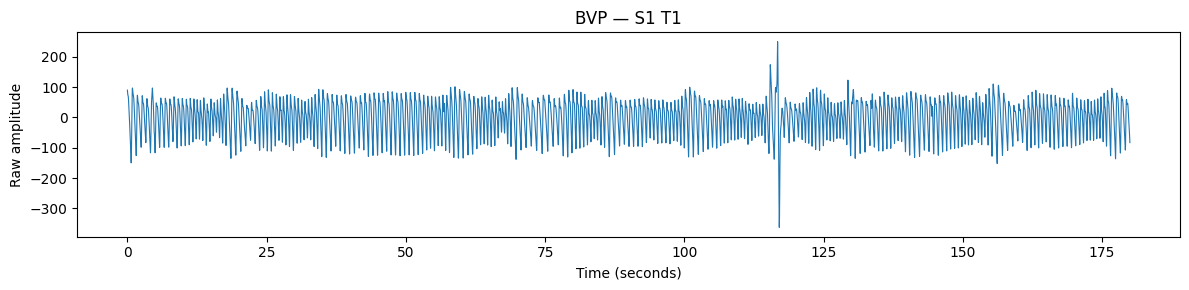

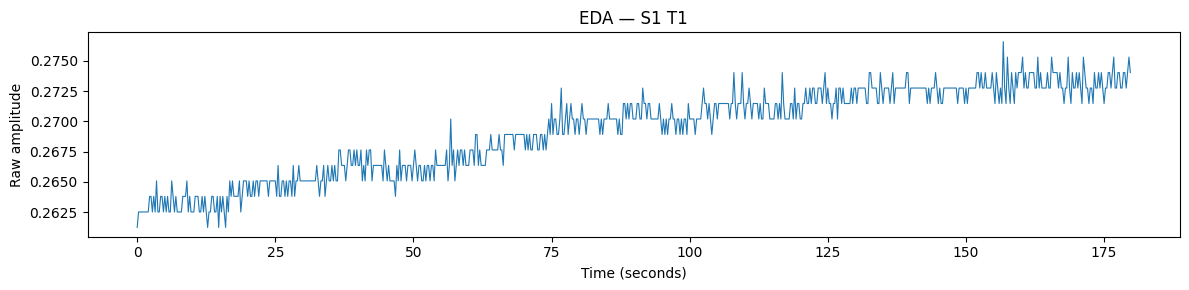

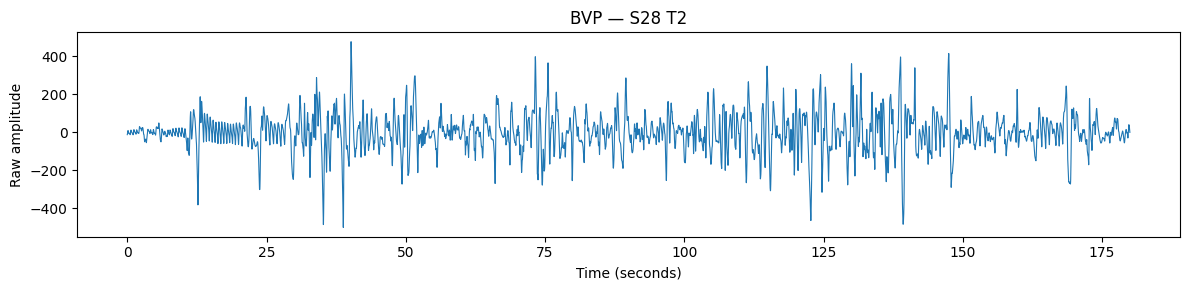

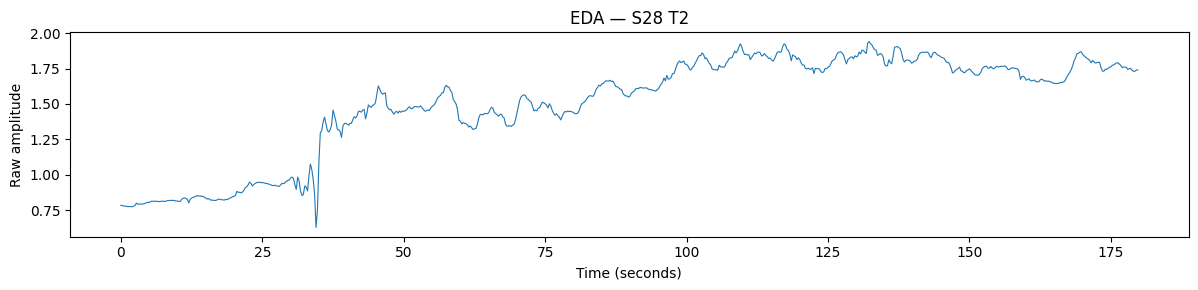

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

def load_signal(filename):
    return pd.read_csv(
        ROOT / filename, header=None
    ).iloc[:, 0].astype(float).to_numpy()

examples = [
    ("bvp_s1_T1.csv", 64, "BVP — S1 T1"),
    ("eda_s1_T1.csv", 4, "EDA — S1 T1"),
    ("bvp_s28_T2.csv", 64, "BVP — S28 T2"),
    ("eda_s28_T2.csv", 4, "EDA — S28 T2"),
]

for filename, fs, title in examples:
    x = load_signal(filename)
    t = np.arange(len(x)) / fs

    plt.figure(figsize=(12, 3))
    plt.plot(t, x, linewidth=0.8)
    plt.title(title)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Raw amplitude")
    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")
FS = {"bvp": 64, "eda": 4}

results = []

for signal_type in ("bvp", "eda"):
    for path in ROOT.glob(f"{signal_type}_s*_T*.csv"):
        match = __import__("re").search(
            r"_s(\d+)_T(\d+)", path.name, __import__("re").I
        )
        if not match:
            continue

        participant, task = map(int, match.groups())
        x = pd.to_numeric(
            pd.read_csv(path, header=None).iloc[:, 0],
            errors="coerce"
        ).to_numpy(dtype=float)

        finite = x[np.isfinite(x)]
        if len(finite) < 10:
            continue

        dx = np.diff(finite)
        median = np.median(finite)
        mad = np.median(np.abs(finite - median))
        robust_scale = 1.4826 * mad

        # Diagnostic flags only; not automatic rejection criteria.
        flat_fraction = np.mean(np.abs(dx) < 1e-12)
        jump_threshold = max(8 * robust_scale, 1e-12)
        jump_fraction = np.mean(np.abs(dx) > jump_threshold)

        # Summarize local variability in 30-second windows.
        fs = FS[signal_type]
        window = 30 * fs
        n_windows = len(finite) // window
        window_stds = [
            np.std(finite[i * window:(i + 1) * window])
            for i in range(n_windows)
        ]

        results.append({
            "filename": path.name,
            "signal": signal_type.upper(),
            "participant": participant,
            "task": task,
            "samples": len(x),
            "nonfinite": int(np.sum(~np.isfinite(x))),
            "flat_difference_fraction": flat_fraction,
            "large_jump_fraction": jump_fraction,
            "robust_scale": robust_scale,
            "min": np.min(finite),
            "max": np.max(finite),
            "window_std_min": min(window_stds) if window_stds else np.nan,
            "window_std_max": max(window_stds) if window_stds else np.nan,
        })

quality = pd.DataFrame(results)
quality.to_csv(ROOT / "physiology_quality_screen.csv", index=False)

print("Recordings screened:", len(quality))
print("\nSignal counts:")
print(quality["signal"].value_counts())

print("\nLargest candidate jump fractions:")
display(quality.sort_values(
    "large_jump_fraction", ascending=False
).head(15))

print("\nSmallest window variability:")
display(quality.sort_values(
    "window_std_min"
).head(15))

print("\nSaved to physiology_quality_screen.csv")

Recordings screened: 336

Signal counts:
signal
BVP    168
EDA    168
Name: count, dtype: int64

Largest candidate jump fractions:


,filename,signal,participant,task,samples,nonfinite,flat_difference_fraction,large_jump_fraction,robust_scale,min,max,window_std_min,window_std_max
286,eda_s39_T2.csv,EDA,39,2,720,0,0.182197,0.011127,0.005693,0.132160,0.786220,0.002313,0.107022
185,eda_s8_T2.csv,EDA,8,2,720,0,0.219750,0.004172,0.001899,0.024332,0.087083,0.000917,0.009639
275,eda_s35_T3.csv,EDA,35,3,720,0,0.205841,0.002782,0.020875,0.258670,0.621070,0.006814,0.037277
174,eda_s4_T1.csv,EDA,4,1,720,0,0.336579,0.002782,0.007606,0.176720,0.385450,0.001668,0.030907
208,eda_s19_T3.csv,EDA,19,3,720,0,0.182197,0.002782,0.068355,0.000000,1.197800,0.014363,0.139543
260,eda_s24_T3.csv,EDA,24,3,720,0,0.311544,0.002782,0.007591,0.011528,0.347120,0.004848,0.048463
89,bvp_s37_T1.csv,BVP,37,1,11520,0,0.001649,0.001823,14.848239,-1286.500000,1787.800000,11.993772,202.557728
298,eda_s44_T3.csv,EDA,44,3,720,0,0.286509,0.001391,0.017094,0.295850,0.658290,0.005859,0.057659
246,eda_s29_T3.csv,EDA,29,3,720,0,0.325452,0.001391,0.007606,0.188260,0.327860,0.001517,0.018822
88,bvp_s37_T2.csv,BVP,37,2,11520,0,0.002257,0.000955,9.117990,-559.100000,412.670000,6.665568,62.614415



Smallest window variability:


,filename,signal,participant,task,samples,nonfinite,flat_difference_fraction,large_jump_fraction,robust_scale,min,max,window_std_min,window_std_max
300,eda_s42_T1.csv,EDA,42,1,720,0,0.407510,0.000000,0.001898,0.199780,0.216430,0.000769,0.001756
168,eda_s1_T1.csv,EDA,1,1,720,0,0.407510,0.000000,0.003795,0.261230,0.276600,0.000820,0.001366
171,eda_s3_T1.csv,EDA,3,1,720,0,0.243394,0.000000,0.001899,0.052506,0.061471,0.000843,0.000991
180,eda_s6_T1.csv,EDA,6,1,720,0,0.382476,0.000000,0.003795,0.179300,0.193390,0.000873,0.001383
328,eda_s54_T1.csv,EDA,54,1,720,0,0.307371,0.000000,0.003797,0.065312,0.090925,0.000890,0.004590
248,eda_s29_T1.csv,EDA,29,1,720,0,0.307371,0.000000,0.015191,0.069159,0.101180,0.000907,0.002688
305,eda_s50_T1.csv,EDA,50,1,720,0,0.363004,0.000000,0.007591,0.154960,0.179290,0.000916,0.001783
185,eda_s8_T2.csv,EDA,8,2,720,0,0.219750,0.004172,0.001899,0.024332,0.087083,0.000917,0.009639
297,eda_s40_T2.csv,EDA,40,2,720,0,0.305981,0.000000,0.003795,0.101170,0.126780,0.000924,0.003179
315,eda_s46_T1.csv,EDA,46,1,720,0,0.214186,0.000000,0.001899,0.037141,0.043544,0.000928,0.001033



Saved to physiology_quality_screen.csv


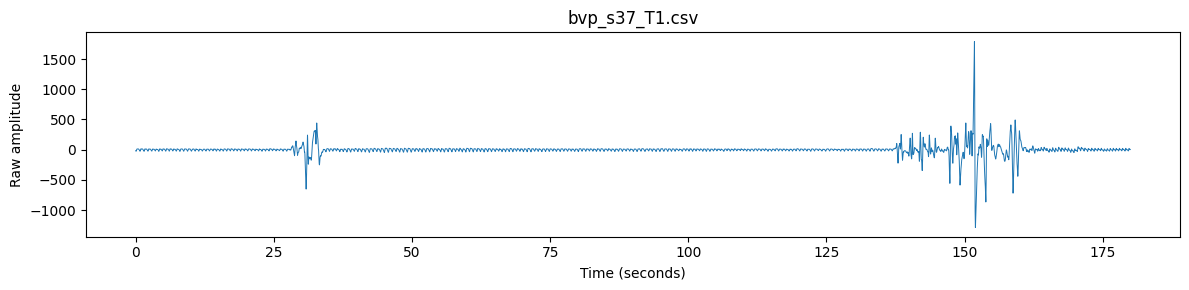

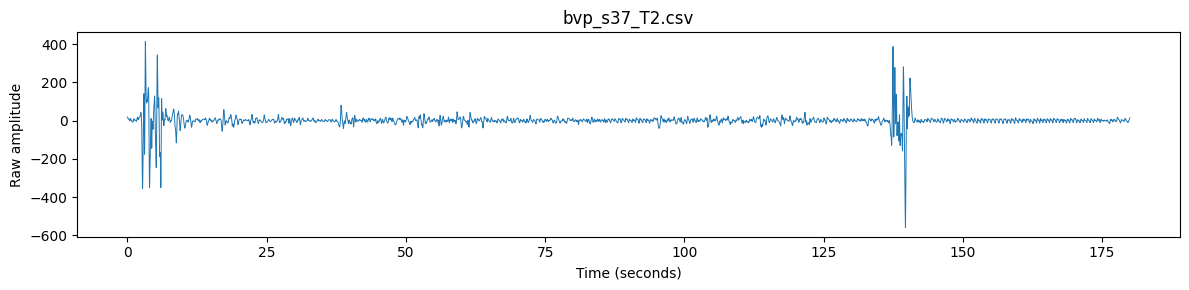

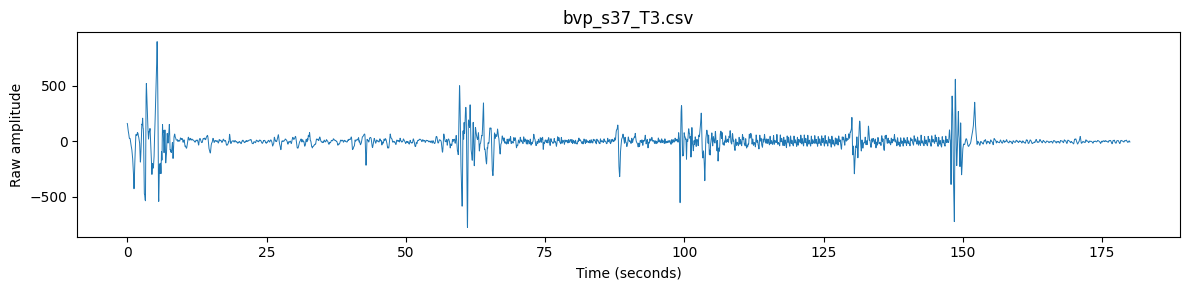

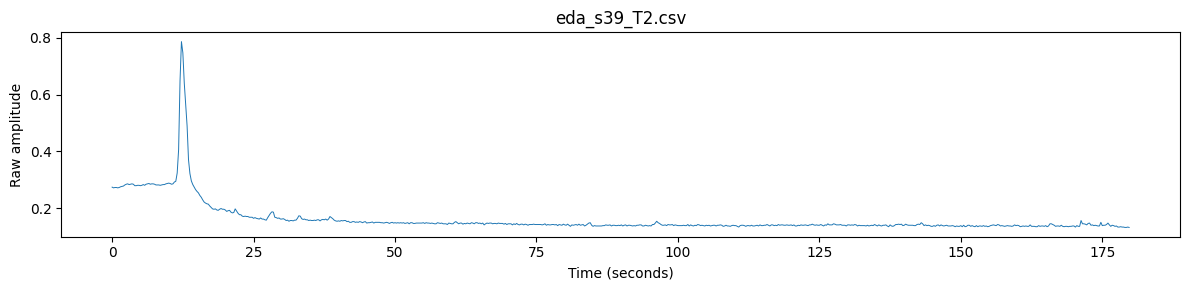

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

recordings = [
    ("bvp_s37_T1.csv", 64),
    ("bvp_s37_T2.csv", 64),
    ("bvp_s37_T3.csv", 64),
    ("eda_s39_T2.csv", 4),
]

for filename, fs in recordings:
    x = pd.read_csv(
        ROOT / filename, header=None
    ).iloc[:, 0].astype(float).to_numpy()

    t = np.arange(len(x)) / fs

    plt.figure(figsize=(12, 3))
    plt.plot(t, x, linewidth=0.7)
    plt.title(filename)
    plt.xlabel("Time (seconds)")
    plt.ylabel("Raw amplitude")
    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")
FS = {"bvp": 64, "eda": 4}
WINDOW_SEC = 30
STRIDE_SEC = 5

rows = []

for signal_type, fs in FS.items():
    for path in ROOT.glob(f"{signal_type}_s*_T*.csv"):
        match = re.search(r"_s(\d+)_T(\d+)", path.name, re.I)
        if not match:
            continue

        participant, task = map(int, match.groups())
        x = pd.read_csv(path, header=None).iloc[:, 0]
        x = pd.to_numeric(x, errors="coerce").to_numpy(float)

        win = WINDOW_SEC * fs
        stride = STRIDE_SEC * fs

        for start in range(0, len(x) - win + 1, stride):
            segment = x[start:start + win]
            finite = segment[np.isfinite(segment)]

            if len(finite) < 0.95 * win:
                rows.append({
                    "filename": path.name,
                    "participant": participant,
                    "task": task,
                    "signal": signal_type.upper(),
                    "start_s": start / fs,
                    "end_s": (start + win) / fs,
                    "finite_fraction": len(finite) / win,
                    "robust_scale": np.nan,
                    "jump_fraction": np.nan,
                })
                continue

            diff = np.diff(finite)
            med = np.median(finite)
            mad = np.median(np.abs(finite - med))
            scale = 1.4826 * mad
            diff_med = np.median(diff)
            diff_mad = 1.4826 * np.median(np.abs(diff - diff_med))

            jump_fraction = (
                np.mean(np.abs(diff - diff_med) > 8 * diff_mad)
                if diff_mad > 0 else 0.0
            )

            rows.append({
                "filename": path.name,
                "participant": participant,
                "task": task,
                "signal": signal_type.upper(),
                "start_s": start / fs,
                "end_s": (start + win) / fs,
                "finite_fraction": len(finite) / win,
                "robust_scale": scale,
                "jump_fraction": jump_fraction,
            })

window_audit = pd.DataFrame(rows)
out = ROOT / "physiology_window_quality_audit.csv"
window_audit.to_csv(out, index=False)

print("Windows audited:", len(window_audit))
print("\nS37 BVP windows:")
display(window_audit[
    (window_audit["participant"] == 37) &
    (window_audit["signal"] == "BVP")
][["task", "start_s", "end_s", "robust_scale", "jump_fraction"]])

print("\nS39 T2 EDA windows:")
display(window_audit[
    (window_audit["participant"] == 39) &
    (window_audit["task"] == 2) &
    (window_audit["signal"] == "EDA")
][["start_s", "end_s", "robust_scale", "jump_fraction"]])

print("\nSaved:", out)

Windows audited: 10416

S37 BVP windows:


,task,start_s,end_s,robust_scale,jump_fraction
2728,2,0.0,30.0,13.373052,0.067223
2729,2,5.0,35.0,10.489395,0.030224
2730,2,10.0,40.0,8.843709,0.002084
2731,2,15.0,45.0,8.539776,0.002084
2732,2,20.0,50.0,8.391516,0.002084
...,...,...,...,...,...
2878,3,130.0,160.0,25.041114,0.029182
2879,3,135.0,165.0,18.702999,0.042731
2880,3,140.0,170.0,14.877891,0.059406
2881,3,145.0,175.0,12.401949,0.072955



S39 T2 EDA windows:


,start_s,end_s,robust_scale,jump_fraction
8866,0.0,30.0,0.084479,0.084034
8867,5.0,35.0,0.048407,0.084034
8868,10.0,40.0,0.021824,0.084034
8869,15.0,45.0,0.011386,0.000000
8870,20.0,50.0,0.010445,0.008403
8871,25.0,55.0,0.009489,0.008403
8872,30.0,60.0,0.005693,0.000000
8873,35.0,65.0,0.003795,0.000000
8874,40.0,70.0,0.001898,0.000000
8875,45.0,75.0,0.002847,0.000000



Saved: /content/drive/MyDrive/ubfc_test_upload./physiology_window_quality_audit.csv


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import re

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")

questionnaire_rows = []
info_rows = []
issues = []

for participant in range(1, 57):
    sid = f"s{participant}"

    # ---- Participant information ----
    info_path = ROOT / f"info_{sid}.txt"

    info = {}
    if info_path.exists():
        text = info_path.read_text(errors="replace")
        info["participant"] = participant
        info["info_text"] = text.strip()
        info_rows.append(info)
    else:
        issues.append((sid, "Missing info file"))

    # ---- Pre/post anxiety questionnaire ----
    anx_path = ROOT / f"selfReportedAnx_{sid}.csv"

    if not anx_path.exists():
        issues.append((sid, "Missing questionnaire file"))
        continue

    try:
        raw = pd.read_csv(anx_path, header=None)
        values = pd.to_numeric(
            raw.stack().reset_index(drop=True),
            errors="coerce"
        ).to_numpy()

        values = values[np.isfinite(values)]

        print(f"{sid}: shape={raw.shape}, numeric_values={len(values)}")

        # Expected layout: 3 rows x 2 columns, in documented order.
        if raw.shape == (3, 2) and len(values) == 6:
            questionnaire_rows.append({
                "participant": participant,
                "cognitive_pre": values[0],
                "cognitive_post": values[1],
                "somatic_pre": values[2],
                "somatic_post": values[3],
                "confidence_pre": values[4],
                "confidence_post": values[5],
            })
        else:
            issues.append((
                sid,
                f"Unexpected questionnaire structure: {raw.shape}; "
                f"{len(values)} numeric values"
            ))

    except Exception as e:
        issues.append((sid, f"Read error: {e}"))

questionnaires = pd.DataFrame(questionnaire_rows)
participant_info = pd.DataFrame(info_rows)

if not questionnaires.empty:
    for name in ["cognitive", "somatic", "confidence"]:
        questionnaires[f"{name}_change"] = (
            questionnaires[f"{name}_post"]
            - questionnaires[f"{name}_pre"]
        )

    questionnaires.to_csv(
        ROOT / "questionnaire_audit_all56.csv", index=False
    )

participant_info.to_csv(
    ROOT / "participant_info_audit_all56.csv", index=False
)

print("\nQuestionnaire participants:", len(questionnaires))
print("Information files:", len(participant_info))
print("Issues:", len(issues))

for issue in issues:
    print(issue)

if not questionnaires.empty:
    print("\nQuestionnaire descriptive summary:")
    display(questionnaires.describe().T)

print("\nExample participant information:")
if not participant_info.empty:
    print(participant_info.iloc[0]["info_text"])

s1: shape=(3, 2), numeric_values=6
s2: shape=(3, 2), numeric_values=6
s3: shape=(3, 2), numeric_values=6
s4: shape=(3, 2), numeric_values=6
s5: shape=(3, 2), numeric_values=6
s6: shape=(3, 2), numeric_values=6
s7: shape=(3, 2), numeric_values=6
s8: shape=(3, 2), numeric_values=6
s9: shape=(3, 2), numeric_values=6
s10: shape=(3, 2), numeric_values=6
s11: shape=(3, 2), numeric_values=6
s12: shape=(3, 2), numeric_values=6
s13: shape=(3, 2), numeric_values=6
s14: shape=(3, 2), numeric_values=6
s15: shape=(3, 2), numeric_values=6
s16: shape=(3, 2), numeric_values=6
s17: shape=(3, 2), numeric_values=6
s18: shape=(3, 2), numeric_values=6
s19: shape=(3, 2), numeric_values=6
s20: shape=(3, 2), numeric_values=6
s21: shape=(3, 2), numeric_values=6
s22: shape=(3, 2), numeric_values=6
s23: shape=(3, 2), numeric_values=6
s24: shape=(3, 2), numeric_values=6
s25: shape=(3, 2), numeric_values=6
s26: shape=(3, 2), numeric_values=6
s27: shape=(3, 2), numeric_values=6
s28: shape=(3, 2), numeric_values=6
s

,count,mean,std,min,25%,50%,75%,max
participant,55.0,28.000000,16.020820,1.000,14.5000,28.000,41.50000,55.000
cognitive_pre,55.0,1.893400,0.639637,1.000,1.4280,1.857,2.14300,4.000
cognitive_post,55.0,2.031073,0.865769,1.000,1.2860,1.857,2.71400,4.000
somatic_pre,55.0,1.776455,0.591375,1.000,1.3570,1.714,2.28600,3.571
somatic_post,55.0,1.929709,0.725692,1.000,1.4280,1.857,2.28550,3.714
confidence_pre,55.0,2.549436,0.615081,1.000,2.1110,2.667,2.94450,3.667
confidence_post,55.0,2.464565,0.753586,1.000,1.8335,2.555,2.94450,4.000
cognitive_change,55.0,0.137673,0.638814,-1.714,-0.2850,0.142,0.50000,1.428
somatic_change,55.0,0.153255,0.549742,-1.286,-0.1430,0.143,0.42900,1.857
confidence_change,55.0,-0.084871,0.529836,-1.223,-0.3890,-0.222,0.16655,1.333



Example participant information:
s1
m
test
2019_02_07
11_37_06


In [ ]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy import signal, stats

ROOT = Path("/content/drive/MyDrive/ubfc_test_upload.")
OUT = ROOT / "physiology_features_all56.csv"

FS = {"bvp": 64, "eda": 4}
WINDOW_SEC = 30
STRIDE_SEC = 5

def load_raw(path):
    # header=None preserves the first signal sample
    return pd.to_numeric(
        pd.read_csv(path, header=None).iloc[:, 0],
        errors="coerce"
    ).to_numpy(dtype=float)

def robust_features(x, prefix):
    x = x[np.isfinite(x)]
    if len(x) < 10:
        return {f"{prefix}_{k}": np.nan for k in
                ["mean", "std", "median", "iqr", "slope", "range"]}

    t = np.arange(len(x), dtype=float)
    slope = stats.linregress(t, x).slope if np.std(x) > 0 else 0.0

    return {
        f"{prefix}_mean": float(np.mean(x)),
        f"{prefix}_std": float(np.std(x)),
        f"{prefix}_median": float(np.median(x)),
        f"{prefix}_iqr": float(np.percentile(x, 75) - np.percentile(x, 25)),
        f"{prefix}_slope_per_sample": float(slope),
        f"{prefix}_range": float(np.max(x) - np.min(x)),
    }

records = []

for participant in range(1, 57):
    for task in range(1, 4):
        for modality in ("bvp", "eda"):
            fs = FS[modality]
            filename = f"{modality}_s{participant}_T{task}.csv"
            path = ROOT / filename

            if not path.exists():
                print("MISSING:", filename)
                continue

            x = load_raw(path)
            win = WINDOW_SEC * fs
            stride = STRIDE_SEC * fs

            for start in range(0, len(x) - win + 1, stride):
                segment = x[start:start + win]
                finite = segment[np.isfinite(segment)]
                row = {
                    "participant": participant,
                    "task": task,
                    "modality": modality.upper(),
                    "start_s": start / fs,
                    "end_s": (start + win) / fs,
                    "finite_fraction": len(finite) / win,
                    "n_samples": len(segment),
                }

                if len(finite) >= 0.95 * win:
                    row.update(robust_features(finite, modality))
                else:
                    row.update(robust_features([], modality))

                records.append(row)

features = pd.DataFrame(records)
features.to_csv(OUT, index=False)

print("Saved:", OUT)
print("Shape:", features.shape)
print("\nRows per modality:")
print(features["modality"].value_counts())
print("\nRows per task:")
print(features.groupby(["modality", "task"]).size())
print("\nMissing feature values:")
print(features.isna().sum().to_string())

Saved: /content/drive/MyDrive/ubfc_test_upload./physiology_features_all56.csv
Shape: (10416, 19)

Rows per modality:
modality
BVP    5208
EDA    5208
Name: count, dtype: int64

Rows per task:
modality  task
BVP       1       1736
          2       1736
          3       1736
EDA       1       1736
          2       1736
          3       1736
dtype: int64

Missing feature values:
participant                0
task                       0
modality                   0
start_s                    0
end_s                      0
finite_fraction            0
n_samples                  0
bvp_mean                5208
bvp_std                 5208
bvp_median              5208
bvp_iqr                 5208
bvp_slope_per_sample    5208
bvp_range               5208
eda_mean                5208
eda_std                 5208
eda_median              5208
eda_iqr                 5208
eda_slope_per_sample    5208
eda_range               5208


In [ ]:

import pandas as pd
import numpy as np

path = "/content/drive/MyDrive/ubfc_test_upload./physiology_features_all56.csv"

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# 1. Confirm the modality-specific missing-value pattern
bvp_cols = [c for c in df.columns if c.startswith("bvp_")]
eda_cols = [c for c in df.columns if c.startswith("eda_")]

print("\nBVP rows: populated BVP features")
print(df.loc[df["modality"] == "BVP", bvp_cols].notna().all(axis=1).mean())

print("\nEDA rows: populated EDA features")
print(df.loc[df["modality"] == "EDA", eda_cols].notna().all(axis=1).mean())

print("\nBVP rows: populated EDA features (expected 0)")
print(df.loc[df["modality"] == "BVP", eda_cols].notna().sum().sum())

print("\nEDA rows: populated BVP features (expected 0)")
print(df.loc[df["modality"] == "EDA", bvp_cols].notna().sum().sum())

# 2. Check finite feature values
feature_cols = bvp_cols + eda_cols

print("\nInfinite values per feature:")
print(np.isinf(df[feature_cols].to_numpy(dtype=float)).sum())

# 3. Inspect distributions
for modality, cols in [("BVP", bvp_cols), ("EDA", eda_cols)]:
    subset = df.loc[df["modality"] == modality, cols]
    print(f"\n{modality} feature summary:")
    print(subset.describe().round(4).T)

# 4. Check timing and data quality
print("\nInvalid time windows:", (df["end_s"] <= df["start_s"]).sum())
print("\nFinite fraction summary:")
print(df["finite_fraction"].describe().round(4))

print("\nRows per participant and task:")
print(pd.crosstab(df["participant"], df["task"]))

# 5. Inspect EDA variability
print("\nEDA variability:")
print(
    df.loc[df["modality"] == "EDA",
           ["eda_std", "eda_iqr", "eda_range"]]
      .describe()
      .round(6)
)


Shape: (10416, 19)

Columns:
['participant', 'task', 'modality', 'start_s', 'end_s', 'finite_fraction', 'n_samples', 'bvp_mean', 'bvp_std', 'bvp_median', 'bvp_iqr', 'bvp_slope_per_sample', 'bvp_range', 'eda_mean', 'eda_std', 'eda_median', 'eda_iqr', 'eda_slope_per_sample', 'eda_range']

BVP rows: populated BVP features
1.0

EDA rows: populated EDA features
1.0

BVP rows: populated EDA features (expected 0)
0

EDA rows: populated BVP features (expected 0)
0

Infinite values per feature:
0

BVP feature summary:
                       count      mean       std      min       25%       50%  \
bvp_mean              5208.0   -0.0032    0.7294  -6.6424   -0.2289   -0.0059   
bvp_std               5208.0   46.3858   36.6414   3.5045   20.2354   34.1834   
bvp_median            5208.0    2.9177    3.8390 -23.0850    0.7900    2.5800   
bvp_iqr               5208.0   46.7497   33.1205   5.0725   24.7494   35.9075   
bvp_slope_per_sample  5208.0   -0.0000    0.0023  -0.0219   -0.0007   -0.0000   

In [ ]:

import pandas as pd
import numpy as np

input_path = (
    "/content/drive/MyDrive/ubfc_test_upload./"
    "physiology_features_all56.csv"
)

output_path = (
    "/content/drive/MyDrive/ubfc_test_upload./"
    "physiology_features_fused.csv"
)

df = pd.read_csv(input_path)

keys = ["participant", "task", "start_s", "end_s"]

bvp_cols = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range"
]

eda_cols = [
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

# Keep only the relevant features for each modality
bvp = df.loc[df["modality"] == "BVP", keys + bvp_cols].copy()
eda = df.loc[df["modality"] == "EDA", keys + eda_cols].copy()

# Check that each modality has unique window keys
assert not bvp.duplicated(keys).any(), "Duplicate BVP windows found"
assert not eda.duplicated(keys).any(), "Duplicate EDA windows found"

# Inner join ensures only exactly matching windows are fused
fused = bvp.merge(
    eda,
    on=keys,
    how="inner",
    validate="one_to_one"
)

# Validate fusion
print("Original rows:", len(df))
print("BVP windows:", len(bvp))
print("EDA windows:", len(eda))
print("Fused windows:", len(fused))
print("Missing values:", fused.isna().sum().sum())

print("\nRows per task:")
print(fused.groupby("task").size())

print("\nRows per participant:")
print(fused.groupby("participant").size().describe())

# Save fused dataset
fused.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("Fused shape:", fused.shape)
print("\nColumns:")
print(fused.columns.tolist())


Original rows: 10416
BVP windows: 5208
EDA windows: 5208
Fused windows: 5208
Missing values: 0

Rows per task:
task
1    1736
2    1736
3    1736
dtype: int64

Rows per participant:
count    56.0
mean     93.0
std       0.0
min      93.0
25%      93.0
50%      93.0
75%      93.0
max      93.0
dtype: float64

Saved: /content/drive/MyDrive/ubfc_test_upload./physiology_features_fused.csv
Fused shape: (5208, 16)

Columns:
['participant', 'task', 'start_s', 'end_s', 'bvp_mean', 'bvp_std', 'bvp_median', 'bvp_iqr', 'bvp_slope_per_sample', 'bvp_range', 'eda_mean', 'eda_std', 'eda_median', 'eda_iqr', 'eda_slope_per_sample', 'eda_range']


In [ ]:

import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

path = (
    "/content/drive/MyDrive/ubfc_test_upload./"
    "physiology_features_labeled.csv"
)

df = pd.read_csv(path)

bvp_features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range"
]

eda_features = [
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

feature_sets = {
    "BVP only": bvp_features,
    "EDA only": eda_features,
    "BVP + EDA": bvp_features + eda_features
}

X_labels = df["label"].to_numpy()
groups = df["participant"].to_numpy()

logo = LeaveOneGroupOut()
results = []
predictions = {}

for name, features in feature_sets.items():
    X = df[features].to_numpy(dtype=float)
    y = X_labels

    oof_predictions = np.empty(len(df), dtype=int)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X[train_idx], y[train_idx])
        oof_predictions[test_idx] = model.predict(X[test_idx])

    predictions[name] = oof_predictions

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y, oof_predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y, oof_predictions
        ),
        "Macro F1": f1_score(
            y, oof_predictions, average="macro"
        )
    })

    print(f"\n{'=' * 45}")
    print(name)
    print(classification_report(
        y, oof_predictions,
        labels=[0, 1],
        target_names=["Rest proxy", "Stress-task proxy"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y, oof_predictions, labels=[0, 1]))

results_df = pd.DataFrame(results)

print("\nLOSO COMPARISON")
print(results_df.round(4).to_string(index=False))

results_path = (
    "/content/drive/MyDrive/ubfc_test_upload./"
    "loso_baseline_results.csv"
)

results_df.to_csv(results_path, index=False)
print("\nResults saved:", results_path)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload./physiology_features_labeled.csv'

In [ ]:

import os
import pandas as pd

base = "/content/drive/MyDrive/ubfc_test_upload."

input_path = os.path.join(
    base, "physiology_features_fused.csv"
)
output_path = os.path.join(
    base, "physiology_features_labeled.csv"
)

# Verify the source file exists
print("Input exists:", os.path.exists(input_path))

if not os.path.exists(input_path):
    print("\nAvailable CSV files:")
    for root, dirs, files in os.walk(
        "/content/drive/MyDrive"
    ):
        for file in files:
            if file.endswith(".csv") and (
                "physiology_features" in file
            ):
                print(os.path.join(root, file))
else:
    df = pd.read_csv(input_path)

    # Experimental task-based proxy labels
    label_map = {1: 0, 2: 1, 3: 1}
    df["label"] = df["task"].map(label_map)

    assert df["label"].notna().all()

    df["label"] = df["label"].astype(int)
    df.to_csv(output_path, index=False)

    print("\nLabelled dataset saved:", output_path)
    print("Shape:", df.shape)
    print("\nTask/label distribution:")
    print(df.groupby(["task", "label"]).size())
    print("\nOutput exists:", os.path.exists(output_path))


Input exists: True

Labelled dataset saved: /content/drive/MyDrive/ubfc_test_upload./physiology_features_labeled.csv
Shape: (5208, 17)

Task/label distribution:
task  label
1     0        1736
2     1        1736
3     1        1736
dtype: int64

Output exists: True


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load labelled data
base = "/content/drive/MyDrive/ubfc_test_upload."
path = os.path.join(base, "physiology_features_labeled.csv")

df = pd.read_csv(path)

bvp_features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range"
]

eda_features = [
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

feature_sets = {
    "BVP only": bvp_features,
    "EDA only": eda_features,
    "BVP + EDA": bvp_features + eda_features
}

y = df["label"].to_numpy(dtype=int)
groups = df["participant"].to_numpy()
logo = LeaveOneGroupOut()

all_results = []
all_predictions = {}

for model_name, features in feature_sets.items():
    X = df[features].to_numpy(dtype=float)
    oof_pred = np.full(len(df), -1, dtype=int)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X[train_idx], y[train_idx])
        oof_pred[test_idx] = model.predict(X[test_idx])

    assert (oof_pred >= 0).all()

    all_predictions[model_name] = oof_pred

    all_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y, oof_pred),
        "Balanced accuracy": balanced_accuracy_score(y, oof_pred),
        "Macro F1": f1_score(y, oof_pred, average="macro")
    })

    print("\n" + "=" * 55)
    print(model_name)
    print(classification_report(
        y, oof_pred,
        labels=[0, 1],
        target_names=["Rest proxy", "Stress-task proxy"],
        zero_division=0
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y, oof_pred, labels=[0, 1]))

results = pd.DataFrame(all_results)

print("\nFINAL LOSO COMPARISON")
print(results.round(4).to_string(index=False))

results.to_csv(
    os.path.join(base, "loso_baseline_results.csv"),
    index=False
)

print("\nSaved baseline results.")



BVP only
                   precision    recall  f1-score   support

       Rest proxy       0.57      0.81      0.67      1736
Stress-task proxy       0.88      0.70      0.78      3472

         accuracy                           0.74      5208
        macro avg       0.73      0.75      0.73      5208
     weighted avg       0.78      0.74      0.74      5208

Confusion matrix:
[[1404  332]
 [1038 2434]]

EDA only
                   precision    recall  f1-score   support

       Rest proxy       0.48      0.91      0.63      1736
Stress-task proxy       0.92      0.52      0.66      3472

         accuracy                           0.65      5208
        macro avg       0.70      0.71      0.65      5208
     weighted avg       0.77      0.65      0.65      5208

Confusion matrix:
[[1575  161]
 [1676 1796]]

BVP + EDA
                   precision    recall  f1-score   support

       Rest proxy       0.61      0.84      0.71      1736
Stress-task proxy       0.90      0.73      0.

In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Verify that the previous experiment's predictions exist
assert "all_predictions" in globals(), (
    "Rerun the LOSO baseline cell first."
)

participant_results = []

for model_name, predictions in all_predictions.items():
    for participant in sorted(df["participant"].unique()):
        mask = df["participant"].to_numpy() == participant

        y_true = df.loc[mask, "label"].to_numpy(dtype=int)
        y_pred = np.asarray(predictions)[mask]

        participant_results.append({
            "participant": participant,
            "model": model_name,
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(
                y_true, y_pred
            ),
            "macro_f1": f1_score(
                y_true, y_pred, average="macro",
                zero_division=0
            )
        })

participant_df = pd.DataFrame(participant_results)

# Summarize variation across the 56 held-out participants
summary = (
    participant_df.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print("PER-PARTICIPANT LOSO SUMMARY")
print(summary)

print("\nFUSED MODEL: LOWEST-PERFORMING PARTICIPANTS")
print(
    participant_df[
        participant_df["model"] == "BVP + EDA"
    ]
    .sort_values("macro_f1")
    .head(10)
    .round(4)
    .to_string(index=False)
)

output_path = os.path.join(
    base, "loso_per_participant_results.csv"
)
participant_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)


PER-PARTICIPANT LOSO SUMMARY
          accuracy                      balanced_accuracy                  \
              mean     std     min  max              mean     std     min   
model                                                                       
BVP + EDA   0.7696  0.1886  0.2473  1.0            0.7876  0.1664  0.3548   
BVP only    0.7369  0.1769  0.2581  1.0            0.7549  0.1661  0.2823   
EDA only    0.6473  0.2329  0.2796  1.0            0.7123  0.1754  0.4194   

               macro_f1                       
           max     mean     std     min  max  
model                                         
BVP + EDA  1.0   0.7450  0.2104  0.2145  1.0  
BVP only   1.0   0.7107  0.1950  0.2500  1.0  
EDA only   1.0   0.6108  0.2595  0.2185  1.0  

FUSED MODEL: LOWEST-PERFORMING PARTICIPANTS
 participant     model  accuracy  balanced_accuracy  macro_f1
          54 BVP + EDA    0.2473             0.3548    0.2145
          40 BVP + EDA    0.3333             0.5000    0.

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

worst_ids = [54, 40, 29, 18]

features = [
    "bvp_mean", "bvp_std", "bvp_iqr", "bvp_range",
    "eda_mean", "eda_std", "eda_iqr", "eda_range"
]

# 1. Compare physiological feature distributions
print("FEATURE DISTRIBUTIONS: DIFFICULT PARTICIPANTS")

for pid in worst_ids:
    person = df[df["participant"] == pid]
    others = df[df["participant"] != pid]

    print(f"\n{'=' * 55}")
    print(f"Participant {pid}")

    comparison = pd.DataFrame({
        "participant_mean": person[features].mean(),
        "participant_std": person[features].std(),
        "other_participants_mean": others[features].mean(),
        "other_participants_std": others[features].std()
    })

    print(comparison.round(4))

# 2. Inspect the fused model's predictions by participant
pred = np.asarray(all_predictions["BVP + EDA"])
y = df["label"].to_numpy()
participant_ids = df["participant"].to_numpy()

print("\n\nCONFUSION MATRICES")

for pid in worst_ids:
    mask = participant_ids == pid

    print(f"\nParticipant {pid}")
    print("True class counts:", np.bincount(y[mask], minlength=2))
    print("Predicted class counts:",
          np.bincount(pred[mask], minlength=2))

    print("Confusion matrix:")
    print(confusion_matrix(
        y[mask], pred[mask], labels=[0, 1]
    ))

# 3. Check whether task performance differs within participants
print("\n\nPER-TASK ACCURACY FOR DIFFICULT PARTICIPANTS")

for pid in worst_ids:
    person_mask = participant_ids == pid

    for task in [1, 2, 3]:
        mask = person_mask & (df["task"].to_numpy() == task)

        print(
            f"Participant {pid}, task {task}: "
            f"accuracy={np.mean(pred[mask] == y[mask]):.3f}"
        )


FEATURE DISTRIBUTIONS: DIFFICULT PARTICIPANTS

Participant 54
           participant_mean  participant_std  other_participants_mean  \
bvp_mean            -0.0146           0.5385                  -0.0030   
bvp_std             31.9747           8.4661                  46.6478   
bvp_iqr             39.7552          10.2634                  46.8769   
bvp_range          231.0686          80.5910                 391.0003   
eda_mean             0.1443           0.0542                   1.1733   
eda_std              0.0034           0.0023                   0.0658   
eda_iqr              0.0044           0.0040                   0.0877   
eda_range            0.0156           0.0104                   0.2810   

           other_participants_std  
bvp_mean                   0.7324  
bvp_std                   36.9035  
bvp_iqr                   33.3784  
bvp_range                357.3690  
eda_mean                   1.7932  
eda_std                    0.1361  
eda_iqr                    0

In [ ]:

import pandas as pd
import numpy as np

df = pd.read_csv(
    "/content/drive/MyDrive/ubfc_test_upload./"
    "physiology_features_labeled.csv"
)

difficult = [54, 40, 29, 18]

features = [
    "bvp_std", "bvp_iqr", "bvp_range",
    "eda_mean", "eda_std", "eda_iqr", "eda_range"
]

for task in [1, 2, 3]:
    task_df = df[df["task"] == task]

    print(f"\n{'=' * 65}")
    print(f"TASK {task}")

    reference = task_df[
        ~task_df["participant"].isin(difficult)
    ][features].median()

    for pid in difficult:
        person = task_df[
            task_df["participant"] == pid
        ]

        person_median = person[features].median()

        comparison = pd.DataFrame({
            "participant_median": person_median,
            "reference_median": reference,
            "ratio_to_reference": (
                person_median / reference.replace(0, np.nan)
            )
        })

        print(f"\nParticipant {pid}")
        print(comparison.round(4))

# Check finite values and minimum signal quality
print("\nOverall finite fraction:")
print(df["finite_fraction"].describe())

print("\nWindow sample counts:")
print(df["n_samples"].describe())

print("\nSaved dataset integrity:")
print("Rows:", len(df))
print("Missing values:", df.isna().sum().sum())
print("Duplicate participant/task/window keys:",
      df.duplicated(
          ["participant", "task", "start_s", "end_s"]
      ).sum())



TASK 1

Participant 54
           participant_median  reference_median  ratio_to_reference
bvp_std               36.1760           22.5899              1.6014
bvp_iqr               38.7600           29.4212              1.3174
bvp_range            252.8100          135.9250              1.8599
eda_mean               0.0852            0.2261              0.3766
eda_std                0.0017            0.0034              0.5003
eda_iqr                0.0026            0.0042              0.6156
eda_range              0.0077            0.0141              0.5454

Participant 40
           participant_median  reference_median  ratio_to_reference
bvp_std               14.6384           22.5899              0.6480
bvp_iqr               20.3875           29.4212              0.6930
bvp_range             62.1400          135.9250              0.4572
eda_mean               0.0843            0.2261              0.3727
eda_std                0.0010            0.0034              0.3101
eda_iqr 

KeyError: 'finite_fraction'

In [ ]:

import pandas as pd
import numpy as np

base = "/content/drive/MyDrive/ubfc_test_upload."

labeled = pd.read_csv(
    f"{base}/physiology_features_labeled.csv"
)

original = pd.read_csv(
    f"{base}/physiology_features_all56.csv"
)

print("Labelled dataset shape:", labeled.shape)
print("Original dataset shape:", original.shape)

# The fused file should not contain these modality-specific
# quality columns because they were omitted during fusion.
for col in ["finite_fraction", "n_samples"]:
    if col in labeled.columns:
        print(f"\n{col} in labelled dataset:")
        print(labeled[col].describe())
    else:
        print(f"\n{col} is absent from labelled dataset.")

    if col in original.columns:
        print(f"{col} in original dataset:")
        print(original[col].describe())

print("\nOriginal data quality by modality:")
for modality in ["BVP", "EDA"]:
    subset = original[original["modality"] == modality]
    print(f"\n{modality}")
    for col in ["finite_fraction", "n_samples"]:
        if col in subset.columns:
            print(col, subset[col].describe().round(4).to_dict())

print("\nFused dataset integrity:")
print("Rows:", len(labeled))
print("Missing values:", labeled.isna().sum().sum())
print(
    "Duplicate participant/task/window keys:",
    labeled.duplicated(
        ["participant", "task", "start_s", "end_s"]
    ).sum()
)


Labelled dataset shape: (5208, 17)
Original dataset shape: (10416, 19)

finite_fraction is absent from labelled dataset.
finite_fraction in original dataset:
count    10416.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: finite_fraction, dtype: float64

n_samples is absent from labelled dataset.
n_samples in original dataset:
count    10416.000000
mean      1020.000000
std        900.043206
min        120.000000
25%        120.000000
50%       1020.000000
75%       1920.000000
max       1920.000000
Name: n_samples, dtype: float64

Original data quality by modality:

BVP
finite_fraction {'count': 5208.0, 'mean': 1.0, 'std': 0.0, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 1.0}
n_samples {'count': 5208.0, 'mean': 1920.0, 'std': 0.0, 'min': 1920.0, '25%': 1920.0, '50%': 1920.0, '75%': 1920.0, 'max': 1920.0}

EDA
finite_fraction {'count': 5208.0, 'mean': 1.0, 'std': 0.0, 'min': 1.0, '25%': 1.0, '50%':

In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

base = "/content/drive/MyDrive/ubfc_test_upload."
df = pd.read_csv(
    os.path.join(base, "physiology_features_labeled.csv")
)

bvp = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range"
]
eda = [
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]
features = bvp + eda

X = df[features].to_numpy(dtype=float)
y = df["label"].to_numpy(dtype=int)
groups = df["participant"].to_numpy()
tasks = df["task"].to_numpy()

assert set(np.unique(y)) == {0, 1}
assert df.groupby("participant")["task"].nunique().eq(3).all()

# Compute each participant's calibration from Task 1 only.
# This is an explicit rest-calibrated protocol.
X_cal = X.copy()

for pid in np.unique(groups):
    participant_mask = groups == pid
    rest_mask = participant_mask & (tasks == 1)

    rest = X[rest_mask]

    median = np.median(rest, axis=0)
    q25 = np.percentile(rest, 25, axis=0)
    q75 = np.percentile(rest, 75, axis=0)
    scale = q75 - q25

    # Avoid division by zero for nearly constant features.
    scale = np.maximum(scale, 1e-8)

    X_cal[participant_mask] = (
        X[participant_mask] - median
    ) / scale

# Compare both protocols using the same held-out participants.
logo = LeaveOneGroupOut()
results = []

for name, features_array in [
    ("Original BVP + EDA", X),
    ("Rest-calibrated BVP + EDA", X_cal)
]:
    predictions = np.full(len(df), -1, dtype=int)

    for train_idx, test_idx in logo.split(
        features_array, y, groups
    ):
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(
            features_array[train_idx], y[train_idx]
        )
        predictions[test_idx] = model.predict(
            features_array[test_idx]
        )

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y, predictions
        ),
        "Macro F1": f1_score(
            y, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(results)

print("REST-CALIBRATION EXPERIMENT")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    os.path.join(base, "loso_rest_calibration_results.csv"),
    index=False
)
print("\nSaved rest-calibration results.")


REST-CALIBRATION EXPERIMENT
                    Model  Accuracy  Balanced accuracy  Macro F1
       Original BVP + EDA    0.7696             0.7876    0.7591
Rest-calibrated BVP + EDA    0.8877             0.9107    0.8811

Saved rest-calibration results.


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

base = "/content/drive/MyDrive/ubfc_test_upload."
df = pd.read_csv(
    os.path.join(base, "physiology_features_labeled.csv")
)

features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range",
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

X = df[features].to_numpy(dtype=float)
y = df["label"].to_numpy(dtype=int)
groups = df["participant"].to_numpy()
tasks = df["task"].to_numpy()

# Normalize each participant using only their Task 1 rest features.
X_cal = np.zeros_like(X)

for pid in np.unique(groups):
    person = groups == pid
    rest = person & (tasks == 1)

    baseline = X[rest]
    median = np.median(baseline, axis=0)
    q25, q75 = np.percentile(baseline, [25, 75], axis=0)

    # Prevent division by very small IQR values.
    scale = np.maximum(q75 - q25, 1e-8)

    X_cal[person] = (X[person] - median) / scale

# Score only tasks 2 and 3 for each held-out participant.
# Task 1 provides calibration but is not scored.
test_mask = np.isin(tasks, [2, 3])

logo = LeaveOneGroupOut()
predictions = np.full(len(df), -1, dtype=int)

for train_idx, test_idx in logo.split(X_cal, y, groups):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_cal[train_idx], y[train_idx])

    # Evaluate only the held-out participant's non-rest tasks.
    scored_idx = test_idx[np.isin(tasks[test_idx], [2, 3])]
    predictions[scored_idx] = model.predict(X_cal[scored_idx])

valid = test_mask & (predictions >= 0)

print("Evaluation windows:", int(valid.sum()))
print("Participants:", df.loc[valid, "participant"].nunique())
print("\nClassification report:")
print(classification_report(
    y[valid],
    predictions[valid],
    labels=[0, 1],
    target_names=["Rest proxy", "Stress-task proxy"],
    zero_division=0
))

print("Accuracy:", round(accuracy_score(
    y[valid], predictions[valid]
), 4))

print("Balanced accuracy:", round(balanced_accuracy_score(
    y[valid], predictions[valid]
), 4))

print("Macro F1:", round(f1_score(
    y[valid], predictions[valid], average="macro"
), 4))

print("\nTask-wise accuracy:")
for task in [2, 3]:
    mask = valid & (tasks == task)
    print(f"Task {task}: {accuracy_score(y[mask], predictions[mask]):.4f}")

# Save the corrected evaluation results
out = df.loc[valid, ["participant", "task", "label"]].copy()
out["prediction"] = predictions[valid]

save_path = os.path.join(
    base, "loso_rest_calibration_stress_tasks_only.csv"
)
out.to_csv(save_path, index=False)

print("\nSaved:", save_path)


Evaluation windows: 3472
Participants: 56

Classification report:
                   precision    recall  f1-score   support

       Rest proxy       0.00      0.00      0.00         0
Stress-task proxy       1.00      0.84      0.91      3472

         accuracy                           0.84      3472
        macro avg       0.50      0.42      0.46      3472
     weighted avg       1.00      0.84      0.91      3472

Accuracy: 0.8416
Balanced accuracy: 0.8416
Macro F1: 0.457

Task-wise accuracy:
Task 2: 0.8272
Task 3: 0.8560

Saved: /content/drive/MyDrive/ubfc_test_upload./loso_rest_calibration_stress_tasks_only.csv


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

base = "/content/drive/MyDrive/ubfc_test_upload."
df = pd.read_csv(
    os.path.join(base, "physiology_features_labeled.csv")
)

features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range",
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

X = df[features].to_numpy(dtype=float)
y = df["label"].to_numpy(dtype=int)
groups = df["participant"].to_numpy()
tasks = df["task"].to_numpy()

# Calibrate each participant using Task 1 only.
X_cal = np.zeros_like(X)

for pid in np.unique(groups):
    person = groups == pid
    rest = person & (tasks == 1)

    baseline = X[rest]
    median = np.median(baseline, axis=0)
    q25, q75 = np.percentile(baseline, [25, 75], axis=0)
    scale = np.maximum(q75 - q25, 1e-8)

    X_cal[person] = (X[person] - median) / scale

# Evaluate all classes, including Task 1 rest windows.
logo = LeaveOneGroupOut()
predictions = np.full(len(df), -1, dtype=int)

for train_idx, test_idx in logo.split(X_cal, y, groups):
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )

    model.fit(X_cal[train_idx], y[train_idx])
    predictions[test_idx] = model.predict(X_cal[test_idx])

assert (predictions >= 0).all()

print("Class distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nClassification report:")
print(classification_report(
    y, predictions,
    labels=[0, 1],
    target_names=["Rest proxy", "Stress-task proxy"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y, predictions, labels=[0, 1]))

print("Accuracy:", round(accuracy_score(y, predictions), 4))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y, predictions), 4
))
print("Macro F1:", round(
    f1_score(y, predictions, average="macro"), 4
))


Class distribution:
0    1736
1    3472
Name: count, dtype: int64

Classification report:
                   precision    recall  f1-score   support

       Rest proxy       0.76      0.98      0.85      1736
Stress-task proxy       0.99      0.84      0.91      3472

         accuracy                           0.89      5208
        macro avg       0.87      0.91      0.88      5208
     weighted avg       0.91      0.89      0.89      5208

Confusion matrix:
[[1701   35]
 [ 550 2922]]
Accuracy: 0.8877
Balanced accuracy: 0.9107
Macro F1: 0.8811


In [ ]:

import os
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Load the fused, labelled dataset
# --------------------------------------------------
base = "/content/drive/MyDrive/ubfc_test_upload."

df = pd.read_csv(
    os.path.join(base, "physiology_features_labeled.csv")
)

features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range",
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

X = df[features].to_numpy(dtype=float)
y = df["label"].to_numpy(dtype=int)
groups = df["participant"].to_numpy()
tasks = df["task"].to_numpy()

assert len(df) == 5208
assert set(np.unique(y)) == {0, 1}

# --------------------------------------------------
# 2. Experiment settings
# --------------------------------------------------
N_REPEATS = 5
CALIBRATION_FRACTION = 0.5

logo = LeaveOneGroupOut()
all_metrics = []
all_oof = []

# --------------------------------------------------
# 3. Repeated rest-calibrated LOSO
# --------------------------------------------------
for repeat in range(N_REPEATS):
    rng = np.random.default_rng(2026 + repeat)

    # Randomly divide each participant's rest windows.
    # Half estimate the baseline; half are held out
    # for rest-class evaluation.
    calibration_masks = np.zeros(len(df), dtype=bool)

    for pid in np.unique(groups):
        rest_indices = np.flatnonzero(
            (groups == pid) & (tasks == 1)
        )

        rest_indices = rng.permutation(rest_indices)

        n_cal = int(
            round(len(rest_indices) * CALIBRATION_FRACTION)
        )
        n_cal = max(1, min(n_cal, len(rest_indices) - 1))

        calibration_masks[rest_indices[:n_cal]] = True

    # Each participant's calibration data are used only
    # to compute that participant's baseline statistics.
    X_cal = np.zeros_like(X)

    for pid in np.unique(groups):
        person = groups == pid
        cal = person & calibration_masks

        baseline = X[cal]

        median = np.median(baseline, axis=0)
        q25, q75 = np.percentile(
            baseline, [25, 75], axis=0
        )
        scale = np.maximum(q75 - q25, 1e-8)

        X_cal[person] = (
            X[person] - median
        ) / scale

    # Evaluate held-out participants. Exclude calibration
    # windows from scoring and from classifier training.
    eval_mask = ~calibration_masks

    predictions = np.full(len(df), -1, dtype=int)

    for train_idx, test_idx in logo.split(X_cal, y, groups):
        # Calibration windows must never be training examples.
        train_idx = train_idx[~calibration_masks[train_idx]]

        # Score all non-calibration windows of the held-out person.
        test_idx = test_idx[eval_mask[test_idx]]

        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X_cal[train_idx], y[train_idx])
        predictions[test_idx] = model.predict(X_cal[test_idx])

    valid = eval_mask & (predictions >= 0)

    assert valid.sum() > 0
    assert set(np.unique(y[valid])) == {0, 1}

    metrics = {
        "repeat": repeat + 1,
        "accuracy": accuracy_score(y[valid], predictions[valid]),
        "balanced_accuracy": balanced_accuracy_score(
            y[valid], predictions[valid]
        ),
        "macro_f1": f1_score(
            y[valid], predictions[valid], average="macro"
        )
    }

    all_metrics.append(metrics)

    out = df.loc[
        valid, ["participant", "task", "label"]
    ].copy()
    out["repeat"] = repeat + 1
    out["prediction"] = predictions[valid]
    all_oof.append(out)

    print(f"\n{'=' * 50}")
    print(f"REPEAT {repeat + 1}")
    print("Evaluation windows:", int(valid.sum()))
    print("Accuracy:", round(metrics["accuracy"], 4))
    print("Balanced accuracy:",
          round(metrics["balanced_accuracy"], 4))
    print("Macro F1:", round(metrics["macro_f1"], 4))
    print("Confusion matrix:")
    print(confusion_matrix(
        y[valid], predictions[valid], labels=[0, 1]
    ))

# --------------------------------------------------
# 4. Summarize repetitions
# --------------------------------------------------
metrics_df = pd.DataFrame(all_metrics)

print("\nREPEATED LOSO SUMMARY")
print(metrics_df.round(4).to_string(index=False))

print("\nMEAN ± STANDARD DEVIATION")
for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    print(
        f"{metric}: "
        f"{metrics_df[metric].mean():.4f} ± "
        f"{metrics_df[metric].std(ddof=1):.4f}"
    )

metrics_path = os.path.join(
    base, "loso_rest_calibration_repeated_metrics.csv"
)
predictions_path = os.path.join(
    base, "loso_rest_calibration_repeated_predictions.csv"
)

metrics_df.to_csv(metrics_path, index=False)
pd.concat(all_oof, ignore_index=True).to_csv(
    predictions_path, index=False
)

print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)



REPEAT 1
Evaluation windows: 4312
Accuracy: 0.8678
Balanced accuracy: 0.9057
Macro F1: 0.8259
Confusion matrix:
[[ 813   27]
 [ 543 2929]]

REPEAT 2
Evaluation windows: 4312
Accuracy: 0.8618
Balanced accuracy: 0.9079
Macro F1: 0.8207
Confusion matrix:
[[ 826   14]
 [ 582 2890]]

REPEAT 3
Evaluation windows: 4312
Accuracy: 0.8511
Balanced accuracy: 0.8967
Macro F1: 0.8083
Confusion matrix:
[[ 816   24]
 [ 618 2854]]

REPEAT 4
Evaluation windows: 4312
Accuracy: 0.8467
Balanced accuracy: 0.8926
Macro F1: 0.8033
Confusion matrix:
[[ 813   27]
 [ 634 2838]]

REPEAT 5
Evaluation windows: 4312
Accuracy: 0.8548
Balanced accuracy: 0.899
Macro F1: 0.8122
Confusion matrix:
[[ 816   24]
 [ 602 2870]]

REPEATED LOSO SUMMARY
 repeat  accuracy  balanced_accuracy  macro_f1
      1    0.8678             0.9057    0.8259
      2    0.8618             0.9079    0.8207
      3    0.8511             0.8967    0.8083
      4    0.8467             0.8926    0.8033
      5    0.8548             0.8990    0.8

In [ ]:

import os

root = "/content/drive/MyDrive/ubfc_test_upload."

extensions = (
    ".csv", ".npy", ".npz", ".pkl", ".pickle",
    ".mat", ".json", ".txt", ".h5", ".hdf5"
)

print("Searching for source data files...\n")

for current_root, dirs, files in os.walk(root):
    # Avoid listing generated result files repeatedly.
    dirs[:] = [
        d for d in dirs
        if d not in {"__pycache__", ".ipynb_checkpoints"}
    ]

    for filename in files:
        if filename.lower().endswith(extensions):
            path = os.path.join(current_root, filename)
            size_mb = os.path.getsize(path) / (1024 * 1024)

            print(f"{size_mb:8.2f} MB  {path}")


Searching for source data files...

    0.07 MB  /content/drive/MyDrive/ubfc_test_upload./bvp_s1_T1.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s1_T1.csv
    0.00 MB  /content/drive/MyDrive/ubfc_test_upload./selfReportedAnx_s1.csv
    0.00 MB  /content/drive/MyDrive/ubfc_test_upload./info_s1.txt
    0.07 MB  /content/drive/MyDrive/ubfc_test_upload./bvp_s1_T2.csv
    0.07 MB  /content/drive/MyDrive/ubfc_test_upload./bvp_s1_T3.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s1_T2.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s1_T3.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s3_T1.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s3_T2.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s3_T3.csv
    0.07 MB  /content/drive/MyDrive/ubfc_test_upload./bvp_s4_T1.csv
    0.07 MB  /content/drive/MyDrive/ubfc_test_upload./bvp_s4_T3.csv
    0.01 MB  /content/drive/MyDrive/ubfc_test_upload./eda_s4_T1.csv
    0

In [ ]:

import os
import pandas as pd
import numpy as np

base = "/content/drive/MyDrive/ubfc_test_upload."

files_to_check = [
    "bvp_s1_T1.csv",
    "eda_s1_T1.csv",
    "bvp_s1_T2.csv",
    "eda_s1_T2.csv",
    "info_s1.txt",
    "info_s2.txt",
    "selfReportedAnx_s1.csv",
]

for filename in files_to_check:
    path = os.path.join(base, filename)

    print("\n" + "=" * 60)
    print(filename)

    if not os.path.exists(path):
        print("File not found")
        continue

    if filename.endswith(".csv"):
        raw = pd.read_csv(path, header=None)

        print("Shape:", raw.shape)
        print("First 5 rows:")
        print(raw.head().to_string(index=False, header=False))
        print("Numeric summary:")
        print(raw.describe().round(4).to_string())

    elif filename.endswith(".txt"):
        with open(path, "r") as f:
            print(f.read()[:3000])



bvp_s1_T1.csv
Shape: (11520, 1)
First 5 rows:
90.19
86.56
82.96
79.61
76.75
Numeric summary:
                0
count  11520.0000
mean       0.0448
std       56.0371
min     -362.4600
25%      -43.7550
50%       12.4150
75%       44.3725
max      250.1300

eda_s1_T1.csv
Shape: (720, 1)
First 5 rows:
0.26123
0.26251
0.26251
0.26251
0.26251
Numeric summary:
              0
count  720.0000
mean     0.2692
std      0.0036
min      0.2612
25%      0.2664
50%      0.2702
75%      0.2728
max      0.2766

bvp_s1_T2.csv
Shape: (11520, 1)
First 5 rows:
-188.32
-186.89
-182.95
-176.55
-167.72
Numeric summary:
                0
count  11520.0000
mean       0.1302
std       60.7344
min     -358.5100
25%      -20.8200
50%        1.0750
75%       18.5850
max      470.4000

eda_s1_T2.csv
Shape: (720, 1)
First 5 rows:
0.25355
0.25355
0.27276
0.26123
0.25483
Numeric summary:
              0
count  720.0000
mean     0.9728
std      0.5990
min      0.2331
25%      0.4492
50%      0.7097
75%      1.6475
ma

In [ ]:

import os
import pandas as pd
import numpy as np

base = "/content/drive/MyDrive/ubfc_test_upload."

records = []

for pid in range(1, 57):
    for task in [1, 2, 3]:
        bvp_path = os.path.join(
            base, f"bvp_s{pid}_T{task}.csv"
        )
        eda_path = os.path.join(
            base, f"eda_s{pid}_T{task}.csv"
        )

        row = {
            "participant": pid,
            "task": task,
            "bvp_exists": os.path.exists(bvp_path),
            "eda_exists": os.path.exists(eda_path),
            "bvp_samples": np.nan,
            "eda_samples": np.nan,
            "bvp_finite_fraction": np.nan,
            "eda_finite_fraction": np.nan
        }

        for path, modality in [
            (bvp_path, "bvp"),
            (eda_path, "eda")
        ]:
            if os.path.exists(path):
                signal = pd.read_csv(
                    path, header=None
                ).iloc[:, 0]

                values = pd.to_numeric(
                    signal, errors="coerce"
                ).to_numpy(dtype=float)

                row[f"{modality}_samples"] = len(values)
                row[f"{modality}_finite_fraction"] = (
                    np.isfinite(values).mean()
                )

        records.append(row)

audit = pd.DataFrame(records)

print("Total participant-task combinations:", len(audit))
print("Complete BVP + EDA recordings:",
      (audit["bvp_exists"] & audit["eda_exists"]).sum())

print("\nMissing BVP files:")
print(audit.loc[~audit["bvp_exists"],
                ["participant", "task"]].to_string(index=False))

print("\nMissing EDA files:")
print(audit.loc[~audit["eda_exists"],
                ["participant", "task"]].to_string(index=False))

print("\nSample count summary:")
print(audit[["bvp_samples", "eda_samples"]].describe())

print("\nNon-finite signal values:")
print("BVP:", (audit["bvp_finite_fraction"] < 1).sum())
print("EDA:", (audit["eda_finite_fraction"] < 1).sum())

audit_path = os.path.join(
    base, "raw_signal_inventory_audit.csv"
)
audit.to_csv(audit_path, index=False)

print("\nSaved:", audit_path)


Total participant-task combinations: 168
Complete BVP + EDA recordings: 168

Missing BVP files:
Empty DataFrame
Columns: [participant, task]
Index: []

Missing EDA files:
Empty DataFrame
Columns: [participant, task]
Index: []

Sample count summary:
       bvp_samples  eda_samples
count        168.0        168.0
mean       11520.0        720.0
std            0.0          0.0
min        11520.0        720.0
25%        11520.0        720.0
50%        11520.0        720.0
75%        11520.0        720.0
max        11520.0        720.0

Non-finite signal values:
BVP: 0
EDA: 0

Saved: /content/drive/MyDrive/ubfc_test_upload./raw_signal_inventory_audit.csv


In [ ]:
import os
import numpy as np
import pandas as pd

from scipy.signal import butter, sosfiltfilt

BASE = "/content/drive/MyDrive/ubfc_test_upload."

# Provisional rates inferred from sample counts and 180-second recordings.
BVP_FS = 64
EDA_FS = 4

WINDOW_SEC = 10
STRIDE_SEC = 5

BVP_LEN = BVP_FS * WINDOW_SEC   # 640 samples
EDA_LEN = EDA_FS * WINDOW_SEC   # 40 samples
STRIDE_BVP = BVP_FS * STRIDE_SEC
STRIDE_EDA = EDA_FS * STRIDE_SEC

# Low-pass filter before windowing to reduce high-frequency noise.
# This is preprocessing, not a substitute for checking the dataset protocol.
sos = butter(4, 3.5, btype="lowpass", fs=BVP_FS, output="sos")

X_bvp, X_eda, y, groups, metadata = [], [], [], [], []

for pid in range(1, 57):
    for task in [1, 2, 3]:

        bvp_path = f"{BASE}/bvp_s{pid}_T{task}.csv"
        eda_path = f"{BASE}/eda_s{pid}_T{task}.csv"

        bvp = pd.read_csv(bvp_path, header=None).iloc[:, 0].to_numpy(float)
        eda = pd.read_csv(eda_path, header=None).iloc[:, 0].to_numpy(float)

        assert len(bvp) == 11520, f"Unexpected BVP length: s{pid}, task {task}"
        assert len(eda) == 720, f"Unexpected EDA length: s{pid}, task {task}"

        # Filter BVP and standardize each recording to reduce scale differences.
        bvp = sosfiltfilt(sos, bvp)
        bvp_std = bvp.std()
        bvp = (bvp - bvp.mean()) / (bvp_std + 1e-8)

        # EDA is kept at its native 4 Hz.
        # Standardize within each recording; this does not use labels.
        eda = (eda - eda.mean()) / (eda.std() + 1e-8)

        # Task 1 = rest; tasks 2 and 3 = stress-task proxy.
        # These are provisional labels, not confirmed ground-truth stress labels.
        label = 0 if task == 1 else 1

        for start_bvp in range(0, len(bvp) - BVP_LEN + 1, STRIDE_BVP):
            start_eda = start_bvp // (BVP_FS // EDA_FS)

            bvp_window = bvp[start_bvp:start_bvp + BVP_LEN]
            eda_window = eda[start_eda:start_eda + EDA_LEN]

            if len(bvp_window) != BVP_LEN or len(eda_window) != EDA_LEN:
                continue

            X_bvp.append(bvp_window.astype(np.float32))
            X_eda.append(eda_window.astype(np.float32))
            y.append(label)
            groups.append(pid)

            start_s = start_bvp / BVP_FS
            metadata.append({
                "participant": pid,
                "task": task,
                "start_s": start_s,
                "end_s": start_s + WINDOW_SEC,
                "label": label
            })

X_bvp = np.asarray(X_bvp, dtype=np.float32)[..., np.newaxis]
X_eda = np.asarray(X_eda, dtype=np.float32)[..., np.newaxis]
y = np.asarray(y, dtype=np.int32)
groups = np.asarray(groups)
window_metadata = pd.DataFrame(metadata)

print("BVP windows:", X_bvp.shape)
print("EDA windows:", X_eda.shape)
print("Labels:", np.unique(y, return_counts=True))
print("Unique participants:", len(np.unique(groups)))
print("Windows per task:")
print(window_metadata.groupby("task").size())
print("Any non-finite values:",
      not (np.isfinite(X_bvp).all() and np.isfinite(X_eda).all()))

# Save arrays and metadata for reuse.
np.savez_compressed(
    f"{BASE}/raw_signal_windows.npz",
    X_bvp=X_bvp,
    X_eda=X_eda,
    y=y,
    groups=groups
)
window_metadata.to_csv(
    f"{BASE}/raw_signal_window_metadata.csv", index=False
)

print("Saved raw_signal_windows.npz and raw_signal_window_metadata.csv")

BVP windows: (5880, 640, 1)
EDA windows: (5880, 40, 1)
Labels: (array([0, 1], dtype=int32), array([1960, 3920]))
Unique participants: 56
Windows per task:
task
1    1960
2    1960
3    1960
dtype: int64
Any non-finite values: False
Saved raw_signal_windows.npz and raw_signal_window_metadata.csv


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

BASE = "/content/drive/MyDrive/ubfc_test_upload."
DATA_PATH = f"{BASE}/raw_signal_windows.npz"

data = np.load(DATA_PATH)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"]

metadata = pd.read_csv(
    f"{BASE}/raw_signal_window_metadata.csv"
)

print("TensorFlow:", tf.__version__)
print("BVP:", X_bvp.shape)
print("EDA:", X_eda.shape)
print("Labels:", np.unique(y, return_counts=True))
print("Participants:", len(np.unique(groups)))
print("Metadata rows:", len(metadata))

assert X_bvp.shape[0] == X_eda.shape[0] == len(y) == len(groups)
assert len(metadata) == len(y)
assert np.isfinite(X_bvp).all()
assert np.isfinite(X_eda).all()

print("Dataset validation passed.")

TensorFlow: 2.21.0
BVP: (5880, 640, 1)
EDA: (5880, 40, 1)
Labels: (array([0, 1], dtype=int32), array([1960, 3920]))
Participants: 56
Metadata rows: 5880
Dataset validation passed.


In [ ]:

import os
import gc
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

# ==================================================
# 1. CONFIGURATION AND DATA LOADING
# ==================================================
SEED = 42
RUN_MODE = "smoke"  # Use "full" after smoke test passes
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4

BASE = "/content/drive/MyDrive/ubfc_test_upload."

np.random.seed(SEED)
tf.random.set_seed(SEED)

data = np.load(f"{BASE}/raw_signal_windows.npz")

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"]

assert len(X_bvp) == len(X_eda) == len(y) == len(groups)
assert np.isfinite(X_bvp).all()
assert np.isfinite(X_eda).all()

print("BVP shape:", X_bvp.shape)
print("EDA shape:", X_eda.shape)
print("Labels:", np.unique(y, return_counts=True))
print("Participants:", len(np.unique(groups)))

# ==================================================
# 2. MODEL A: TCN-LIKE DILATED CNN
# ==================================================
def build_tcn():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    def tcn_branch(inputs, filters):
        x = layers.Conv1D(
            filters, kernel_size=5,
            padding="causal", dilation_rate=1,
            activation="relu"
        )(inputs)

        x = layers.Conv1D(
            filters, kernel_size=5,
            padding="causal", dilation_rate=2,
            activation="relu"
        )(x)

        x = layers.Conv1D(
            filters, kernel_size=5,
            padding="causal", dilation_rate=4,
            activation="relu"
        )(x)

        return layers.GlobalAveragePooling1D()(x)

    bvp_features = tcn_branch(bvp_input, 32)
    eda_features = tcn_branch(eda_input, 16)

    x = layers.Concatenate()([bvp_features, eda_features])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="TCN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ==================================================
# 3. MODEL B: LSTM
# ==================================================
def build_lstm():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    # Downsample BVP sequence before recurrent processing
    bvp = layers.AveragePooling1D(pool_size=4)(bvp_input)
    bvp = layers.LSTM(32)(bvp)

    eda = layers.LSTM(16)(eda_input)

    x = layers.Concatenate()([bvp, eda])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="LSTM"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ==================================================
# 4. PREPARE LOSO FOLDS
# ==================================================
logo = LeaveOneGroupOut()
all_splits = list(logo.split(X_bvp, y, groups))

if RUN_MODE == "smoke":
    splits = all_splits[:3]
else:
    splits = all_splits

print(f"\nRun mode: {RUN_MODE}")
print(f"Number of outer folds: {len(splits)}")

model_builders = {
    "TCN": build_tcn,
    "LSTM": build_lstm
}

oof_records = []

# ==================================================
# 5. TRAIN AND EVALUATE
# ==================================================
for fold_number, (outer_train, outer_test) in enumerate(
    splits, start=1
):
    held_out = np.unique(groups[outer_test]).tolist()

    print(
        f"\nFold {fold_number}/{len(splits)} "
        f"| Held-out participant: {held_out}"
    )

    # Validation split is by participant, not by window
    train_groups = groups[outer_train]

    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED
    )

    train_rel, val_rel = next(
        gss.split(
            outer_train,
            y[outer_train],
            groups=train_groups
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    # Class weights are calculated using training data only
    classes = np.unique(y[train_idx])

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )

    class_weights = {
        int(c): float(w)
        for c, w in zip(classes, weights)
    }

    for model_name, build_model in model_builders.items():
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)

        model = build_model()

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True
        )

        model.fit(
            [X_bvp[train_idx], X_eda[train_idx]],
            y[train_idx],
            validation_data=(
                [X_bvp[val_idx], X_eda[val_idx]],
                y[val_idx]
            ),
            epochs=MAX_EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=class_weights,
            callbacks=[early_stopping],
            verbose=0
        )

        probabilities = model.predict(
            [X_bvp[outer_test], X_eda[outer_test]],
            batch_size=BATCH_SIZE,
            verbose=0
        ).ravel()

        predictions = (
            probabilities >= 0.5
        ).astype(np.int32)

        # Corrected metric calculation: no broken f-string
        test_accuracy = accuracy_score(
            y[outer_test], predictions
        )

        test_macro_f1 = f1_score(
            y[outer_test],
            predictions,
            average="macro",
            zero_division=0
        )

        print(
            f"  {model_name}: "
            f"accuracy={test_accuracy:.3f}, "
            f"macro-F1={test_macro_f1:.3f}"
        )

        for idx, probability, prediction in zip(
            outer_test, probabilities, predictions
        ):
            oof_records.append({
                "model": model_name,
                "index": int(idx),
                "participant": int(groups[idx]),
                "true": int(y[idx]),
                "probability": float(probability),
                "prediction": int(prediction)
            })

        del model
        gc.collect()


# ==================================================
# 6. AGGREGATE OUT-OF-FOLD METRICS
# ==================================================
oof = pd.DataFrame(oof_records)

def summarize(group):
    return pd.Series({
        "windows_scored": len(group),
        "accuracy": accuracy_score(
            group["true"], group["prediction"]
        ),
        "balanced_accuracy": balanced_accuracy_score(
            group["true"], group["prediction"]
        ),
        "macro_f1": f1_score(
            group["true"],
            group["prediction"],
            average="macro",
            zero_division=0
        )
    })

results = (
    oof.groupby("model")
    .apply(summarize, include_groups=False)
    .reset_index()
)

print("\nOVERALL OUT-OF-FOLD RESULTS")
print(results.to_string(index=False))

for model_name in oof["model"].unique():
    subset = oof[oof["model"] == model_name]

    print(f"\n{model_name} confusion matrix:")
    print(
        confusion_matrix(
            subset["true"],
            subset["prediction"],
            labels=[0, 1]
        )
    )

    print(
        classification_report(
            subset["true"],
            subset["prediction"],
            labels=[0, 1],
            target_names=[
                "Rest-task proxy",
                "Stress-task proxy"
            ],
            zero_division=0
        )
    )

# ==================================================
# 7. SAVE RESULTS
# ==================================================
prediction_path = (
    f"{BASE}/tcn_lstm_oof_predictions_{RUN_MODE}.csv"
)

results_path = (
    f"{BASE}/tcn_lstm_results_{RUN_MODE}.csv"
)

oof.to_csv(prediction_path, index=False)
results.to_csv(results_path, index=False)

print("\nSaved predictions:", prediction_path)
print("Saved metrics:", results_path)
print("\nExperiment completed.")


BVP shape: (5880, 640, 1)
EDA shape: (5880, 40, 1)
Labels: (array([0, 1], dtype=int32), array([1960, 3920]))
Participants: 56

Run mode: smoke
Number of outer folds: 3

Fold 1/3 | Held-out participant: [1]
  TCN: accuracy=0.971, macro-F1=0.969
  LSTM: accuracy=0.971, macro-F1=0.968

Fold 2/3 | Held-out participant: [2]


  TCN: accuracy=0.962, macro-F1=0.958
  LSTM: accuracy=0.905, macro-F1=0.888

Fold 3/3 | Held-out participant: [3]
  TCN: accuracy=0.343, macro-F1=0.266
  LSTM: accuracy=0.648, macro-F1=0.647

OVERALL OUT-OF-FOLD RESULTS
model  windows_scored  accuracy  balanced_accuracy  macro_f1
 LSTM           315.0   0.84127           0.859524  0.832261
  TCN           315.0   0.75873           0.819048  0.756668

TCN confusion matrix:
[[105   0]
 [ 76 134]]
                   precision    recall  f1-score   support

  Rest-task proxy       0.58      1.00      0.73       105
Stress-task proxy       1.00      0.64      0.78       210

         accuracy                           0.76       315
        macro avg       0.79      0.82      0.76       315
     weighted avg       0.86      0.76      0.76       315


LSTM confusion matrix:
[[ 96   9]
 [ 41 169]]
                   precision    recall  f1-score   support

  Rest-task proxy       0.70      0.91      0.79       105
Stress-task proxy       0.9

In [ ]:

# ============================================================
# FULL EXPERIMENT: TCN vs LSTM FOR BVP + EDA
# 56-Participant Leave-One-Subject-Out Cross-Validation
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping

# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
VALIDATION_GROUP_FRACTION = 0.15

BASE = "/content/drive/MyDrive/ubfc_test_upload."

OUTPUT_PREDICTIONS = f"{BASE}/tcn_lstm_oof_predictions_full.csv"
OUTPUT_METRICS = f"{BASE}/tcn_lstm_results_full.csv"
OUTPUT_PARTICIPANTS = f"{BASE}/tcn_lstm_participant_results_full.csv"

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)

# ============================================================
# 2. LOAD AND VALIDATE DATA
# ============================================================

data = np.load(f"{BASE}/raw_signal_windows.npz")

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"].astype(np.int32)

assert X_bvp.shape == (5880, 640, 1), X_bvp.shape
assert X_eda.shape == (5880, 40, 1), X_eda.shape
assert len(y) == len(groups) == len(X_bvp)
assert np.isfinite(X_bvp).all()
assert np.isfinite(X_eda).all()
assert set(np.unique(y)) == {0, 1}

participants = np.unique(groups)

print("BVP:", X_bvp.shape)
print("EDA:", X_eda.shape)
print("Labels:", dict(zip(*np.unique(y, return_counts=True))))
print("Participants:", len(participants))

# ============================================================
# 3. MODEL A: TCN-LIKE DILATED CNN
# ============================================================

def build_tcn():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    def dilated_branch(inputs, filters):
        x = inputs

        for dilation in [1, 2, 4, 8]:
            residual = x

            x = layers.Conv1D(
                filters=filters,
                kernel_size=5,
                padding="causal",
                dilation_rate=dilation
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
            x = layers.Dropout(0.15)(x)

            # Project residual if its channel count differs
            if residual.shape[-1] != filters:
                residual = layers.Conv1D(
                    filters=filters,
                    kernel_size=1,
                    padding="same"
                )(residual)

            x = layers.Add()([x, residual])
            x = layers.Activation("relu")(x)

        return layers.GlobalAveragePooling1D()(x)

    bvp_features = dilated_branch(bvp_input, 32)
    eda_features = dilated_branch(eda_input, 16)

    x = layers.Concatenate()([bvp_features, eda_features])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="TCN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ============================================================
# 4. MODEL B: LSTM
# ============================================================

def build_lstm():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    # Reduce BVP sequence length to make LSTM training practical
    bvp = layers.AveragePooling1D(pool_size=4)(bvp_input)
    bvp = layers.LSTM(32)(bvp)

    eda = layers.LSTM(16)(eda_input)

    x = layers.Concatenate()([bvp, eda])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="LSTM"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


model_builders = {
    "TCN": build_tcn,
    "LSTM": build_lstm
}

# ============================================================
# 5. OUTER LOSO SPLITS
# ============================================================

logo = LeaveOneGroupOut()
outer_splits = list(logo.split(X_bvp, y, groups))

assert len(outer_splits) == len(participants)

print("\nStarting FULL LOSO experiment")
print("Outer folds:", len(outer_splits))
print("Models:", list(model_builders.keys()))

# Each row will contain one out-of-fold prediction.
oof_records = []

start_time = time.time()

# ============================================================
# 6. TRAIN BOTH MODELS ON IDENTICAL FOLDS
# ============================================================

for fold_number, (outer_train, outer_test) in enumerate(
    outer_splits, start=1
):
    held_out_participant = int(np.unique(groups[outer_test])[0])

    # Safety check: no participant overlap between train and test
    assert set(groups[outer_train]).isdisjoint(set(groups[outer_test]))

    print(
        f"\nFold {fold_number}/{len(outer_splits)} "
        f"| Held-out participant: {held_out_participant}"
    )

    # --------------------------------------------------------
    # Participant-level validation split inside outer training
    # --------------------------------------------------------

    training_participants = np.unique(groups[outer_train])

    if len(training_participants) < 3:
        raise ValueError("Not enough training participants for validation.")

    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=SEED + fold_number
    )

    # These indices are relative to outer_train
    train_rel, val_rel = next(
        gss.split(
            outer_train,
            y[outer_train],
            groups=groups[outer_train]
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    # Verify validation participants do not occur in training
    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[train_idx]).isdisjoint(set(groups[outer_test]))
    assert set(groups[val_idx]).isdisjoint(set(groups[outer_test]))

    # Class weights from training data only
    train_classes = np.unique(y[train_idx])

    class_weight_values = compute_class_weight(
        class_weight="balanced",
        classes=train_classes,
        y=y[train_idx]
    )

    class_weights = {
        int(label): float(weight)
        for label, weight in zip(
            train_classes, class_weight_values
        )
    }

    for model_name, build_model in model_builders.items():
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED + fold_number)

        model = build_model()

        early_stopping = EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True
        )

        model.fit(
            x=[X_bvp[train_idx], X_eda[train_idx]],
            y=y[train_idx],
            validation_data=(
                [X_bvp[val_idx], X_eda[val_idx]],
                y[val_idx]
            ),
            epochs=MAX_EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=class_weights,
            callbacks=[early_stopping],
            verbose=0
        )

        # Direct call avoids repeatedly creating predict functions
        probabilities = model(
            [X_bvp[outer_test], X_eda[outer_test]],
            training=False
        ).numpy().ravel()

        predictions = (probabilities >= 0.5).astype(np.int32)

        fold_accuracy = accuracy_score(
            y[outer_test], predictions
        )
        fold_balanced_accuracy = balanced_accuracy_score(
            y[outer_test], predictions
        )
        fold_macro_f1 = f1_score(
            y[outer_test],
            predictions,
            average="macro",
            zero_division=0
        )

        print(
            f"  {model_name}: "
            f"accuracy={fold_accuracy:.3f}, "
            f"balanced_accuracy={fold_balanced_accuracy:.3f}, "
            f"macro-F1={fold_macro_f1:.3f}"
        )

        for idx, probability, prediction in zip(
            outer_test, probabilities, predictions
        ):
            oof_records.append({
                "model": model_name,
                "window_index": int(idx),
                "participant": int(groups[idx]),
                "true": int(y[idx]),
                "probability": float(probability),
                "prediction": int(prediction)
            })

        del model
        gc.collect()

    # Save progress after every participant fold
    progress = pd.DataFrame(oof_records)
    progress.to_csv(OUTPUT_PREDICTIONS, index=False)

    elapsed_minutes = (time.time() - start_time) / 60
    print(f"Progress saved. Elapsed: {elapsed_minutes:.1f} minutes")


# ============================================================
# 7. POOLED OUT-OF-FOLD METRICS
# ============================================================

oof = pd.DataFrame(oof_records)

summary_rows = []

for model_name in model_builders:
    subset = oof[oof["model"] == model_name]
    true = subset["true"]
    pred = subset["prediction"]

    summary_rows.append({
        "model": model_name,
        "windows_scored": len(subset),
        "participants_scored": subset["participant"].nunique(),
        "accuracy": accuracy_score(true, pred),
        "balanced_accuracy": balanced_accuracy_score(true, pred),
        "macro_f1": f1_score(
            true, pred, average="macro", zero_division=0
        )
    })

results = pd.DataFrame(summary_rows)

print("\n" + "=" * 65)
print("POOLED OUT-OF-FOLD RESULTS")
print("=" * 65)
print(results.to_string(index=False))

# ============================================================
# 8. CONFUSION MATRICES AND CLASSIFICATION REPORTS
# ============================================================

for model_name in model_builders:
    subset = oof[oof["model"] == model_name]

    print(f"\n{model_name} confusion matrix")
    print("Rows=true labels; columns=predicted labels")
    print(
        confusion_matrix(
            subset["true"],
            subset["prediction"],
            labels=[0, 1]
        )
    )

    print(
        classification_report(
            subset["true"],
            subset["prediction"],
            labels=[0, 1],
            target_names=["Rest-task proxy", "Stress-task proxy"],
            zero_division=0
        )
    )

# ============================================================
# 9. PARTICIPANT-LEVEL RESULTS
# ============================================================

participant_rows = []

for model_name in model_builders:
    model_oof = oof[oof["model"] == model_name]

    for participant, subset in model_oof.groupby("participant"):
        participant_rows.append({
            "model": model_name,
            "participant": int(participant),
            "windows": len(subset),
            "accuracy": accuracy_score(
                subset["true"], subset["prediction"]
            ),
            "balanced_accuracy": balanced_accuracy_score(
                subset["true"], subset["prediction"]
            ),
            "macro_f1": f1_score(
                subset["true"],
                subset["prediction"],
                average="macro",
                zero_division=0
            )
        })

participant_results = pd.DataFrame(participant_rows)

print("\nPARTICIPANT-LEVEL METRICS")
print(
    participant_results.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std"]).round(4)
)

print("\nLowest participant macro-F1 scores:")
print(
    participant_results.sort_values("macro_f1").head(12).to_string(index=False)
)

# ============================================================
# 10. SAVE FINAL RESULTS
# ============================================================

oof.to_csv(OUTPUT_PREDICTIONS, index=False)
results.to_csv(OUTPUT_METRICS, index=False)
participant_results.to_csv(OUTPUT_PARTICIPANTS, index=False)

print("\nSaved files:")
print(OUTPUT_PREDICTIONS)
print(OUTPUT_METRICS)
print(OUTPUT_PARTICIPANTS)

print(
    f"\nFull experiment completed in "
    f"{(time.time() - start_time) / 60:.1f} minutes."
)


TensorFlow: 2.21.0


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload./raw_signal_windows.npz'

In [ ]:
import os
import pandas as pd

path = "/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_full.csv"

if os.path.exists(path):
    df = pd.read_csv(path)
    print("Rows saved:", len(df))
    print("\nPredictions per model:")
    print(df["model"].value_counts())
    print("\nParticipants saved:")
    print(df.groupby("model")["participant"].nunique())
    print("Last saved participant:", df["participant"].max())
else:
    print("Prediction file not found.")

Rows saved: 9450

Predictions per model:
model
TCN     4725
LSTM    4725
Name: count, dtype: int64

Participants saved:
model
LSTM    45
TCN     45
Name: participant, dtype: int64
Last saved participant: 45


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_full.csv"
df = pd.read_csv(path)

print("Total rows:", len(df))
print("\nRows per model:")
print(df["model"].value_counts())

print("\nWindows per participant and model:")
print(
    df.groupby(["model", "participant"])
      .size()
      .groupby("model")
      .describe()
)

print("\nParticipant IDs:")
print(sorted(df["participant"].unique()))

print("\nDuplicate model/window-index rows:")
print(df.duplicated(["model", "window_index"]).sum())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_full.csv'

In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/ubfc_test_upload."
path = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

if os.path.exists(path):
    df = pd.read_csv(path)

    print("Total rows:", len(df))
    print("\nRows per model:")
    print(df["model"].value_counts())

    print("\nParticipants per model:")
    print(df.groupby("model")["participant"].nunique())

    print("\nWindows per participant and model:")
    print(
        df.groupby(["model", "participant"])
          .size()
          .groupby("model")
          .describe()
    )

    print("\nParticipant IDs:")
    print(sorted(df["participant"].unique()))

    print("\nDuplicate model/window-index rows:")
    print(df.duplicated(["model", "window_index"]).sum())
else:
    print("File not found:", path)
    print("\nAvailable CSV files:")
    if os.path.isdir(BASE):
        print([
            f for f in os.listdir(BASE)
            if f.endswith(".csv") and "tcn_lstm" in f
        ])
    else:
        print("Folder not found. Check whether Google Drive is mounted.")


File not found: /content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_full.csv

Available CSV files:
Folder not found. Check whether Google Drive is mounted.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

BASE = "/content/drive/MyDrive/ubfc_test_upload."

if os.path.isdir(BASE):
    print("\nFolder found.")
    print("\nExperiment files:")
    for f in os.listdir(BASE):
        if "tcn_lstm" in f:
            print(f)
else:
    print("Folder not found:", BASE)
    print("\nFolders in MyDrive:")
    print(os.listdir("/content/drive/MyDrive")[:50])

Drive mounted: True

Folder found.

Experiment files:
tcn_lstm_oof_predictions_smoke.csv
tcn_lstm_results_smoke.csv
tcn_lstm_oof_predictions_full.csv


In [ ]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/ubfc_test_upload."
path = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

df = pd.read_csv(path)

print("Total saved rows:", len(df))
print("\nRows per model:")
print(df["model"].value_counts())

print("\nParticipants per model:")
print(df.groupby("model")["participant"].nunique())

print("\nWindows per participant:")
print(df.groupby(["model", "participant"]).size().groupby("model").describe())

print("\nLast saved participant:", df["participant"].max())
print("File size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))
print("Last modified:", pd.Timestamp(os.path.getmtime(path), unit="s"))

Total saved rows: 9450

Rows per model:
model
TCN     4725
LSTM    4725
Name: count, dtype: int64

Participants per model:
model
LSTM    45
TCN     45
Name: participant, dtype: int64

Windows per participant:
       count   mean  std    min    25%    50%    75%    max
model                                                      
LSTM    45.0  105.0  0.0  105.0  105.0  105.0  105.0  105.0
TCN     45.0  105.0  0.0  105.0  105.0  105.0  105.0  105.0

Last saved participant: 45
File size (MB): 0.32
Last modified: 2026-10-23 15:38:46


In [ ]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE = "/content/drive/MyDrive/ubfc_test_upload."
path = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

df = pd.read_csv(path)

for name in ["TCN", "LSTM"]:
    d = df[df["model"] == name]
    y_true = d["true"].to_numpy()
    y_pred = d["prediction"].to_numpy()

    print(f"\n{'=' * 45}")
    print(f"{name} — PARTIAL RESULTS (45 PARTICIPANTS)")
    print(f"{'=' * 45}")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Balanced accuracy:",
          round(balanced_accuracy_score(y_true, y_pred), 4))
    print("Macro-F1:",
          round(f1_score(y_true, y_pred, average="macro"), 4))
    print("Confusion matrix:")
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

    print("\nPer-class report:")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["Rest-task proxy", "Stress-task proxy"],
        zero_division=0
    ))


TCN — PARTIAL RESULTS (45 PARTICIPANTS)
Accuracy: 0.778
Balanced accuracy: 0.6943
Macro-F1: 0.7106
Confusion matrix:
[[ 698  877]
 [ 172 2978]]

Per-class report:
                   precision    recall  f1-score   support

  Rest-task proxy       0.80      0.44      0.57      1575
Stress-task proxy       0.77      0.95      0.85      3150

         accuracy                           0.78      4725
        macro avg       0.79      0.69      0.71      4725
     weighted avg       0.78      0.78      0.76      4725


LSTM — PARTIAL RESULTS (45 PARTICIPANTS)
Accuracy: 0.811
Balanced accuracy: 0.7687
Macro-F1: 0.7785
Confusion matrix:
[[1011  564]
 [ 329 2821]]

Per-class report:
                   precision    recall  f1-score   support

  Rest-task proxy       0.75      0.64      0.69      1575
Stress-task proxy       0.83      0.90      0.86      3150

         accuracy                           0.81      4725
        macro avg       0.79      0.77      0.78      4725
     weighted avg

In [ ]:
import pandas as pd
import os

BASE = "/content/drive/MyDrive/ubfc_test_upload."
path = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

df = pd.read_csv(path)

expected = set(range(1, 57))

for model_name in ["TCN", "LSTM"]:
    completed = set(
        df.loc[df["model"] == model_name, "participant"].astype(int)
    )
    print(f"\n{model_name}")
    print("Completed:", len(completed))
    print("Missing:", sorted(expected - completed))


TCN
Completed: 45
Missing: [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]

LSTM
Completed: 45
Missing: [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]


In [ ]:

import os
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from tensorflow.keras.callbacks import EarlyStopping

BASE = "/content/drive/MyDrive/ubfc_test_upload."
PRED_PATH = f"{BASE}/tcn_lstm_oof_predictions_full.csv"
DATA_PATH = f"{BASE}/raw_signal_windows.npz"

SEED = 42
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
VALIDATION_GROUP_FRACTION = 0.15

# --------------------------------------------------
# 1. Load the existing checkpoint and dataset
# --------------------------------------------------
data = np.load(DATA_PATH)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"].astype(np.int32)

oof = pd.read_csv(PRED_PATH)

expected_participants = set(range(1, 57))

for model_name in ["TCN", "LSTM"]:
    existing = set(
        oof.loc[oof["model"] == model_name, "participant"].astype(int)
    )
    print(model_name, "already saved:", len(existing),
          "| missing:", sorted(expected_participants - existing))

# --------------------------------------------------
# 2. Recover missing folds only
# --------------------------------------------------
model_builders = {
    "TCN": build_tcn,
    "LSTM": build_lstm
}

start_time = time.time()

for held_out_pid in sorted(expected_participants):
    # A participant fold is complete only if both models have predictions.
    already_done = all(
        (
            (oof["model"] == name) &
            (oof["participant"] == held_out_pid)
        ).any()
        for name in ["TCN", "LSTM"]
    )

    if already_done:
        print(f"Skipping participant {held_out_pid}: already saved.")
        continue

    print(f"\nRecovering participant {held_out_pid}/56")

    outer_test = np.where(groups == held_out_pid)[0]
    outer_train = np.where(groups != held_out_pid)[0]

    assert len(outer_test) > 0
    assert set(groups[outer_train]).isdisjoint(set(groups[outer_test]))

    # Same group-based validation strategy as the original experiment
    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=SEED + held_out_pid
    )

    train_rel, val_rel = next(
        gss.split(
            outer_train,
            y[outer_train],
            groups=groups[outer_train]
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[train_idx]).isdisjoint(set(groups[outer_test]))
    assert set(groups[val_idx]).isdisjoint(set(groups[outer_test]))

    classes = np.unique(y[train_idx])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )
    class_weights = {
        int(c): float(w) for c, w in zip(classes, weights)
    }

    for model_name, build_model in model_builders.items():
        # Reuse predictions if one model for this participant was already saved.
        exists = (
            (oof["model"] == model_name) &
            (oof["participant"] == held_out_pid)
        ).any()

        if exists:
            print(f"  {model_name}: already saved, skipping.")
            continue

        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED + held_out_pid)

        model = build_model()

        model.fit(
            [X_bvp[train_idx], X_eda[train_idx]],
            y[train_idx],
            validation_data=(
                [X_bvp[val_idx], X_eda[val_idx]],
                y[val_idx]
            ),
            epochs=MAX_EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=class_weights,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=PATIENCE,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        probabilities = model(
            [X_bvp[outer_test], X_eda[outer_test]],
            training=False
        ).numpy().ravel()

        predictions = (probabilities >= 0.5).astype(np.int32)

        new_rows = pd.DataFrame({
            "model": model_name,
            "window_index": outer_test.astype(int),
            "participant": groups[outer_test].astype(int),
            "true": y[outer_test].astype(int),
            "probability": probabilities.astype(float),
            "prediction": predictions.astype(int)
        })

        oof = pd.concat([oof, new_rows], ignore_index=True)

        print(
            f"  {model_name}: "
            f"accuracy={accuracy_score(y[outer_test], predictions):.3f}, "
            f"balanced_accuracy={balanced_accuracy_score(y[outer_test], predictions):.3f}, "
            f"macro-F1={f1_score(y[outer_test], predictions, average='macro', zero_division=0):.3f}"
        )

        del model
        gc.collect()

        # Save after each model so progress survives interruptions.
        oof.to_csv(PRED_PATH, index=False)
        print("  Checkpoint saved.")

# --------------------------------------------------
# 3. Verify completion
# --------------------------------------------------
oof = pd.read_csv(PRED_PATH)

print("\nFINAL CHECKPOINT STATUS")
for name in ["TCN", "LSTM"]:
    subset = oof[oof["model"] == name]
    completed = sorted(subset["participant"].astype(int).unique())
    missing = sorted(expected_participants - set(completed))

    print(f"\n{name}:")
    print("Participants completed:", len(completed))
    print("Missing participants:", missing)
    print("Prediction rows:", len(subset))

print(f"\nRecovery elapsed: {(time.time() - start_time) / 60:.1f} minutes")


TCN already saved: 45 | missing: [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]
LSTM already saved: 45 | missing: [46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56]


NameError: name 'build_tcn' is not defined

In [ ]:

import os

BASE = "/content/drive/MyDrive/ubfc_test_upload."

for root, dirs, files in os.walk(BASE):
    for filename in files:
        if any(key in filename.lower() for key in [
            "tcn", "lstm", "model", "checkpoint", "config"
        ]):
            print(os.path.join(root, filename))


/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_smoke.csv
/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_results_smoke.csv
/content/drive/MyDrive/ubfc_test_upload./tcn_lstm_oof_predictions_full.csv


In [ ]:
import pandas as pd

path = (
    "/content/drive/MyDrive/ubfc_test_upload."
    "/tcn_lstm_oof_predictions_full.csv"
)

df = pd.read_csv(path)

print("Columns:", df.columns.tolist())
print("\nFirst five rows:")
print(df.head())

print("\nRows per model:")
print(df["model"].value_counts())

print("\nParticipants per model:")
print(df.groupby("model")["participant"].nunique())

Columns: ['model', 'window_index', 'participant', 'true', 'probability', 'prediction']

First five rows:
  model  window_index  participant  true  probability  prediction
0   TCN             0            1     0     0.014529           0
1   TCN             1            1     0     0.020559           0
2   TCN             2            1     0     0.039130           0
3   TCN             3            1     0     0.030123           0
4   TCN             4            1     0     0.016229           0

Rows per model:
model
TCN     4725
LSTM    4725
Name: count, dtype: int64

Participants per model:
model
LSTM    45
TCN     45
Name: participant, dtype: int64


In [ ]:

import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    dirs[:] = [d for d in dirs if d not in {
        ".ipynb_checkpoints", "node_modules", ".git"
    }]
    for filename in files:
        if filename.endswith(".ipynb") and "UBFC_Phys_Stage1_Pipeline" in filename:
            print(os.path.join(root, filename))


/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb


In [ ]:

import json

notebook_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "UBFC_Phys_Stage1_Pipeline.ipynb"
)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "build_tcn", "build_lstm", "Conv1D", "EarlyStopping",
    "Model(", "model.fit", "MAX_EPOCHS", "BATCH_SIZE",
    "GroupShuffleSplit", "outer_test"
]

for i, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matches = [k for k in keywords if k.lower() in source.lower()]

    if matches:
        print("\n" + "=" * 70)
        print(f"CELL {i} | MATCHES: {', '.join(matches)}")
        print("=" * 70)
        print(source)



CELL 210 | MATCHES: model.fit

import pandas as pd
import numpy as np

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

path = (
    "/content/drive/MyDrive/ubfc_test_upload./"
    "physiology_features_labeled.csv"
)

df = pd.read_csv(path)

bvp_features = [
    "bvp_mean", "bvp_std", "bvp_median",
    "bvp_iqr", "bvp_slope_per_sample", "bvp_range"
]

eda_features = [
    "eda_mean", "eda_std", "eda_median",
    "eda_iqr", "eda_slope_per_sample", "eda_range"
]

feature_sets = {
    "BVP only": bvp_features,
    "EDA only": eda_features,
    "BVP + EDA": bvp_features + eda_features
}

X_labels = df["label"].to_numpy()
groups = df["participant"].to_numpy()

logo = LeaveOneGroupOut()
results = []
pred

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def build_tcn():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    def dilated_branch(inputs, filters):
        x = inputs

        for dilation in [1, 2, 4, 8]:
            residual = x

            x = layers.Conv1D(
                filters=filters,
                kernel_size=5,
                padding="causal",
                dilation_rate=dilation
            )(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
            x = layers.Dropout(0.15)(x)

            if residual.shape[-1] != filters:
                residual = layers.Conv1D(
                    filters=filters,
                    kernel_size=1,
                    padding="same"
                )(residual)

            x = layers.Add()([x, residual])
            x = layers.Activation("relu")(x)

        return layers.GlobalAveragePooling1D()(x)

    bvp_features = dilated_branch(bvp_input, 32)
    eda_features = dilated_branch(eda_input, 16)

    x = layers.Concatenate()([bvp_features, eda_features])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="TCN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


def build_lstm():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    bvp = layers.AveragePooling1D(pool_size=4)(bvp_input)
    bvp = layers.LSTM(32)(bvp)

    eda = layers.LSTM(16)(eda_input)

    x = layers.Concatenate()([bvp, eda])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="LSTM"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


model_builders = {
    "TCN": build_tcn,
    "LSTM": build_lstm
}

print("TCN and LSTM definitions restored.")

# Verify both models accept the expected input shapes.
for name, builder in model_builders.items():
    model = builder()
    print(f"{name}: output shape = {model.output_shape}")
    del model

tf.keras.backend.clear_session()


TCN and LSTM definitions restored.
TCN: output shape = (None, 1)
LSTM: output shape = (None, 1)


In [ ]:

import os
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from tensorflow.keras.callbacks import EarlyStopping

BASE = "/content/drive/MyDrive/ubfc_test_upload."
DATA_PATH = f"{BASE}/raw_signal_windows.npz"
PRED_PATH = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

SEED = 42
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
VALIDATION_GROUP_FRACTION = 0.15

# Load data and checkpoint
data = np.load(DATA_PATH)
X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"].astype(np.int32)

oof = pd.read_csv(PRED_PATH)

# Recreate the exact original outer-fold order
logo = LeaveOneGroupOut()
outer_splits = list(logo.split(X_bvp, y, groups))

assert len(outer_splits) == 56

# Identify folds whose predictions are missing
completed = {
    name: set(
        oof.loc[oof["model"] == name, "participant"].astype(int)
    )
    for name in ["TCN", "LSTM"]
}

print("Existing rows:", len(oof))
print("Missing TCN:", sorted(set(np.unique(groups)) - completed["TCN"]))
print("Missing LSTM:", sorted(set(np.unique(groups)) - completed["LSTM"]))

start_time = time.time()

for fold_number, (outer_train, outer_test) in enumerate(outer_splits, start=1):
    held_out_pid = int(np.unique(groups[outer_test])[0])

    # Skip participants already completed for BOTH models
    if all(
        ((oof["model"] == name) &
         (oof["participant"] == held_out_pid)).any()
        for name in ["TCN", "LSTM"]
    ):
        continue

    print(f"\nFold {fold_number}/56 | Participant {held_out_pid}")

    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=SEED + fold_number
    )

    train_rel, val_rel = next(
        gss.split(
            outer_train,
            y[outer_train],
            groups=groups[outer_train]
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    assert set(groups[train_idx]).isdisjoint(groups[val_idx])
    assert set(groups[train_idx]).isdisjoint(groups[outer_test])
    assert set(groups[val_idx]).isdisjoint(groups[outer_test])

    classes = np.unique(y[train_idx])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )
    class_weights = {
        int(c): float(w) for c, w in zip(classes, weights)
    }

    for model_name, builder in model_builders.items():
        # Check each model independently in case a fold was partially saved
        exists = (
            (oof["model"] == model_name) &
            (oof["participant"] == held_out_pid)
        ).any()

        if exists:
            print(f"  {model_name}: already saved; skipping")
            continue

        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED + fold_number)

        model = builder()

        model.fit(
            [X_bvp[train_idx], X_eda[train_idx]],
            y[train_idx],
            validation_data=(
                [X_bvp[val_idx], X_eda[val_idx]],
                y[val_idx]
            ),
            epochs=MAX_EPOCHS,
            batch_size=BATCH_SIZE,
            class_weight=class_weights,
            callbacks=[
                EarlyStopping(
                    monitor="val_loss",
                    patience=PATIENCE,
                    restore_best_weights=True
                )
            ],
            verbose=0
        )

        probabilities = model(
            [X_bvp[outer_test], X_eda[outer_test]],
            training=False
        ).numpy().ravel()

        predictions = (probabilities >= 0.5).astype(np.int32)

        new_rows = pd.DataFrame({
            "model": model_name,
            "window_index": outer_test.astype(int),
            "participant": groups[outer_test].astype(int),
            "true": y[outer_test].astype(int),
            "probability": probabilities.astype(float),
            "prediction": predictions.astype(int)
        })

        oof = pd.concat([oof, new_rows], ignore_index=True)

        # Save immediately after each model
        oof.to_csv(PRED_PATH, index=False)

        print(
            f"  {model_name}: "
            f"accuracy={accuracy_score(y[outer_test], predictions):.3f}, "
            f"balanced_accuracy={balanced_accuracy_score(y[outer_test], predictions):.3f}, "
            f"macro-F1={f1_score(y[outer_test], predictions, average='macro', zero_division=0):.3f}"
        )
        print("  Checkpoint saved.")

        del model
        gc.collect()

# Verify participant coverage
oof = pd.read_csv(PRED_PATH)

print("\nRECOVERY STATUS")
for name in ["TCN", "LSTM"]:
    subset = oof[oof["model"] == name]
    missing = sorted(set(np.unique(groups)) -
                     set(subset["participant"].astype(int)))

    print(
        f"{name}: {subset['participant'].nunique()}/56 participants; "
        f"{len(subset)} rows; missing={missing}"
    )

print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")


Existing rows: 9450
Missing TCN: [np.int32(46), np.int32(47), np.int32(48), np.int32(49), np.int32(50), np.int32(51), np.int32(52), np.int32(53), np.int32(54), np.int32(55), np.int32(56)]
Missing LSTM: [np.int32(46), np.int32(47), np.int32(48), np.int32(49), np.int32(50), np.int32(51), np.int32(52), np.int32(53), np.int32(54), np.int32(55), np.int32(56)]

Fold 46/56 | Participant 46
  TCN: accuracy=0.771, balanced_accuracy=0.829, macro-F1=0.769
  Checkpoint saved.
  LSTM: accuracy=0.771, balanced_accuracy=0.829, macro-F1=0.769
  Checkpoint saved.

Fold 47/56 | Participant 47
  TCN: accuracy=0.667, balanced_accuracy=0.500, macro-F1=0.400
  Checkpoint saved.
  LSTM: accuracy=0.962, balanced_accuracy=0.971, macro-F1=0.958
  Checkpoint saved.

Fold 48/56 | Participant 48
  TCN: accuracy=0.629, balanced_accuracy=0.471, macro-F1=0.386
  Checkpoint saved.
  LSTM: accuracy=0.638, balanced_accuracy=0.493, macro-F1=0.435
  Checkpoint saved.

Fold 49/56 | Participant 49
  TCN: accuracy=1.000, bal

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

BASE = "/content/drive/MyDrive/ubfc_test_upload."
PRED_PATH = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

df = pd.read_csv(PRED_PATH)

print("Total rows:", len(df))
print("\nRows per model:")
print(df.groupby("model").size())

print("\nUnique participants per model:")
print(df.groupby("model")["participant"].nunique())

results = []

for name in ["TCN", "LSTM"]:
    d = df[df["model"] == name].copy()
    y_true = d["true"].astype(int)
    y_pred = d["prediction"].astype(int)

    metrics = {
        "model": name,
        "participants": d["participant"].nunique(),
        "windows": len(d),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }
    results.append(metrics)

    print(f"\n{'=' * 45}\n{name} — Confusion Matrix")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))

results_df = pd.DataFrame(results)
print("\nFINAL POOLED RESULTS")
display(results_df.round(4))

results_df.to_csv(
    f"{BASE}/tcn_lstm_results_final.csv", index=False
)
print("Saved final metrics.")

Total rows: 11760

Rows per model:
model
LSTM    5880
TCN     5880
dtype: int64

Unique participants per model:
model
LSTM    56
TCN     56
Name: participant, dtype: int64

TCN — Confusion Matrix
[[ 891 1069]
 [ 269 3651]]

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.45      0.57      1960
           1       0.77      0.93      0.85      3920

    accuracy                           0.77      5880
   macro avg       0.77      0.69      0.71      5880
weighted avg       0.77      0.77      0.75      5880


LSTM — Confusion Matrix
[[1242  718]
 [ 436 3484]]

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.63      0.68      1960
           1       0.83      0.89      0.86      3920

    accuracy                           0.80      5880
   macro avg       0.78      0.76      0.77      5880
weighted avg       0.80      0.80      0.80      5880


FINAL POOLED RESULTS


,model,participants,windows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,TCN,56,5880,0.7724,0.6930,0.7708,0.6930,0.7081
1,LSTM,56,5880,0.8037,0.7612,0.7846,0.7612,0.7704


Saved final metrics.


In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

BASE = "/content/drive/MyDrive/ubfc_test_upload."
PRED_PATH = f"{BASE}/tcn_lstm_oof_predictions_full.csv"

df = pd.read_csv(PRED_PATH)

# Verify the complete experiment before analysing it.
assert len(df) == 11760, f"Unexpected row count: {len(df)}"
assert set(df["model"].unique()) == {"TCN", "LSTM"}
assert all(
    df[df["model"] == model]["participant"].nunique() == 56
    for model in ["TCN", "LSTM"]
)

print("Dataset verified.")
print("Predictions:", len(df))
print("Participants per model:", df.groupby("model")["participant"].nunique().to_dict())

# Calculate metrics separately for each participant and model.
participant_results = []

for (model, participant), subset in df.groupby(["model", "participant"]):
    y_true = subset["true"].astype(int)
    y_pred = subset["prediction"].astype(int)

    participant_results.append({
        "model": model,
        "participant": int(participant),
        "windows": len(subset),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

participant_df = pd.DataFrame(participant_results)

# Summarise the distribution of participant-level performance.
summary = (
    participant_df.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ]
    .agg(["mean", "std", "median"])
    .round(4)
)

print("\nPARTICIPANT-LEVEL PERFORMANCE")
display(summary)

# Save individual participant results for the report.
participant_path = f"{BASE}/tcn_lstm_participant_results_final.csv"
participant_df.to_csv(participant_path, index=False)

print("\nSaved:", participant_path)


Dataset verified.
Predictions: 11760
Participants per model: {'LSTM': 56, 'TCN': 56}

PARTICIPANT-LEVEL PERFORMANCE


accuracy                 balanced_accuracy                 macro_f1  \
          mean     std  median              mean     std  median     mean   
model                                                                       
LSTM    0.8037  0.1411  0.8381            0.7612  0.1812  0.8143   0.7431   
TCN     0.7724  0.1530  0.7143            0.6930  0.2138  0.5893   0.6434   

                       
          std  median  
model                  
LSTM   0.2022  0.8024  
TCN    0.2540  0.5756


Saved: /content/drive/MyDrive/ubfc_test_upload./tcn_lstm_participant_results_final.csv


In [ ]:

import pandas as pd

BASE = "/content/drive/MyDrive/ubfc_test_upload."
RESULT_PATH = f"{BASE}/tcn_lstm_participant_results_final.csv"

participant_df = pd.read_csv(RESULT_PATH)

paired = participant_df.pivot(
    index="participant",
    columns="model",
    values=["accuracy", "balanced_accuracy", "macro_f1"]
)

for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
    differences = (
        paired[(metric, "LSTM")] - paired[(metric, "TCN")]
    )

    print(f"\n{metric.upper()}")
    print("LSTM wins:", int((differences > 0).sum()))
    print("TCN wins:", int((differences < 0).sum()))
    print("Ties:", int((differences == 0).sum()))
    print("Mean LSTM - TCN:", round(differences.mean(), 4))

print("\nComparison complete.")



ACCURACY
LSTM wins: 26
TCN wins: 26
Ties: 4
Mean LSTM - TCN: 0.0313

BALANCED_ACCURACY
LSTM wins: 31
TCN wins: 23
Ties: 2
Mean LSTM - TCN: 0.0682

MACRO_F1
LSTM wins: 32
TCN wins: 22
Ties: 2
Mean LSTM - TCN: 0.0998

Comparison complete.


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, Model

def build_cnn():
    bvp_input = layers.Input(shape=(640, 1), name="bvp")
    eda_input = layers.Input(shape=(40, 1), name="eda")

    # BVP branch: local temporal feature extraction
    bvp = layers.Conv1D(
        32, kernel_size=7, padding="same", activation="relu"
    )(bvp_input)
    bvp = layers.BatchNormalization()(bvp)
    bvp = layers.MaxPooling1D(pool_size=4)(bvp)

    bvp = layers.Conv1D(
        64, kernel_size=5, padding="same", activation="relu"
    )(bvp)
    bvp = layers.BatchNormalization()(bvp)
    bvp = layers.MaxPooling1D(pool_size=4)(bvp)
    bvp = layers.GlobalAveragePooling1D()(bvp)

    # EDA branch
    eda = layers.Conv1D(
        16, kernel_size=5, padding="same", activation="relu"
    )(eda_input)
    eda = layers.BatchNormalization()(eda)
    eda = layers.MaxPooling1D(pool_size=2)(eda)

    eda = layers.Conv1D(
        32, kernel_size=3, padding="same", activation="relu"
    )(eda)
    eda = layers.GlobalAveragePooling1D()(eda)

    # Multimodal feature fusion
    x = layers.Concatenate()([bvp, eda])
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    output = layers.Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_cnn()
cnn_model.summary()

print("CNN model created successfully.")


Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ bvp (InputLayer)    │ (None, 640, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 640, 32)   │        256 │ bvp[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 640, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ eda (InputLayer)    │ (None, 40, 1)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 160, 32)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 40, 16)    │         96 │ eda[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 160, 64)   │     10,304 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 16)    │         64 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 160, 64)   │        256 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_2     │ (None, 20, 16)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 40, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 20, 32)    │      1,568 │ max_pooling1d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling1d_1[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv1d_3[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      3,104 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 15,809 (61.75 KB)

 Trainable params: 15,585 (60.88 KB)

 Non-trainable params: 224 (896.00 B)

CNN model created successfully.


In [ ]:

# ============================================================
# UBFC-Phys: CNN Leave-One-Group-Out (LOSO) Experiment
# 56 participants | BVP + EDA | 20 epochs maximum
# Resumable checkpoints saved to Google Drive
# ============================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras.callbacks import EarlyStopping

# -------------------- Configuration -------------------------

BASE = "/content/drive/MyDrive/ubfc_test_upload."
DATA_PATH = f"{BASE}/raw_signal_windows.npz"
PRED_PATH = f"{BASE}/cnn_oof_predictions_full.csv"
METRICS_PATH = f"{BASE}/cnn_results_final.csv"
PARTICIPANT_PATH = f"{BASE}/cnn_participant_results_final.csv"

SEED = 42
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
VALIDATION_GROUP_FRACTION = 0.15

os.makedirs(BASE, exist_ok=True)

# -------------------- Load dataset --------------------------

data = np.load(DATA_PATH)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"].astype(np.int32)

print("Dataset loaded")
print("BVP shape:", X_bvp.shape)
print("EDA shape:", X_eda.shape)
print("Labels shape:", y.shape)
print("Participants:", len(np.unique(groups)))

assert len(X_bvp) == len(X_eda) == len(y) == len(groups)
assert len(np.unique(groups)) == 56

# Confirm the CNN definition exists
assert "build_cnn" in globals(), (
    "build_cnn() is undefined. Run the CNN model-definition cell first."
)

# -------------------- Build original folds ------------------

outer_splits = list(
    LeaveOneGroupOut().split(X_bvp, y, groups)
)
assert len(outer_splits) == 56

# -------------------- Load checkpoint ------------------------

columns = [
    "model", "window_index", "participant",
    "true", "probability", "prediction"
]

if os.path.exists(PRED_PATH):
    oof = pd.read_csv(PRED_PATH)
    print("Existing checkpoint loaded:", len(oof), "rows")

    # Keep only CNN rows with valid window indices.
    # This file is dedicated to the CNN experiment.
    oof = oof[oof["model"] == "CNN"].copy()

    oof["window_index"] = oof["window_index"].astype(int)
    oof["participant"] = oof["participant"].astype(int)

    # Prevent duplicated predictions for a window.
    oof = oof.drop_duplicates(
        subset=["model", "window_index"],
        keep="last"
    )
else:
    oof = pd.DataFrame(columns=columns)
    print("No existing CNN checkpoint; starting from scratch.")

start_time = time.time()

# -------------------- Train each participant fold ------------

for fold_number, (outer_train, outer_test) in enumerate(
    outer_splits, start=1
):
    pid = int(np.unique(groups[outer_test])[0])
    expected_indices = set(map(int, outer_test))

    existing = oof[
        (oof["model"] == "CNN") &
        (oof["participant"] == pid)
    ]

    # Skip only if all expected windows exist exactly once.
    if (
        len(existing) == len(expected_indices)
        and set(existing["window_index"].astype(int))
        == expected_indices
    ):
        print(
            f"Fold {fold_number}/56 | Participant {pid}: "
            "already complete; skipping."
        )
        continue

    # Remove incomplete checkpoint rows for this participant.
    oof = oof[
        ~(
            (oof["model"] == "CNN") &
            (oof["participant"] == pid)
        )
    ].copy()

    # Grouped train/validation split within outer training data.
    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=SEED + fold_number
    )

    train_rel, val_rel = next(
        gss.split(
            outer_train,
            y[outer_train],
            groups=groups[outer_train]
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    # Calculate class weights from training labels only.
    classes = np.unique(y[train_idx])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )
    class_weight = dict(zip(classes, weights))

    # Reproducible model initialization.
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED + fold_number)

    model = build_cnn()

    model.fit(
        [X_bvp[train_idx], X_eda[train_idx]],
        y[train_idx],
        validation_data=(
            [X_bvp[val_idx], X_eda[val_idx]],
            y[val_idx]
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # Predict only on the held-out participant.
    probabilities = model(
        [X_bvp[outer_test], X_eda[outer_test]],
        training=False
    ).numpy().ravel()

    predictions = (probabilities >= 0.5).astype(np.int32)

    # Save out-of-fold predictions.
    new_rows = pd.DataFrame({
        "model": "CNN",
        "window_index": outer_test,
        "participant": groups[outer_test],
        "true": y[outer_test],
        "probability": probabilities,
        "prediction": predictions
    })

    oof = pd.concat(
        [oof, new_rows],
        ignore_index=True
    )

    # Save after every completed participant.
    oof.to_csv(PRED_PATH, index=False)

    fold_acc = accuracy_score(y[outer_test], predictions)
    fold_bal_acc = balanced_accuracy_score(
        y[outer_test], predictions
    )
    fold_f1 = f1_score(
        y[outer_test],
        predictions,
        average="macro",
        zero_division=0
    )

    print(
        f"Fold {fold_number}/56 | Participant {pid} | "
        f"accuracy={fold_acc:.3f} | "
        f"balanced_accuracy={fold_bal_acc:.3f} | "
        f"macro-F1={fold_f1:.3f}"
    )
    print(f"Checkpoint saved: {PRED_PATH}")

    del model
    gc.collect()

# -------------------- Validate completion --------------------

oof = pd.read_csv(PRED_PATH)
cnn = oof[oof["model"] == "CNN"].copy()

cnn["window_index"] = cnn["window_index"].astype(int)
cnn["participant"] = cnn["participant"].astype(int)

expected_windows = set(range(len(y)))
actual_windows = set(cnn["window_index"])

assert len(cnn) == len(y), (
    f"Expected {len(y)} rows, got {len(cnn)}"
)
assert cnn["participant"].nunique() == 56
assert actual_windows == expected_windows
assert not cnn["window_index"].duplicated().any()

# Confirm labels align with the original dataset.
cnn = cnn.sort_values("window_index").reset_index(drop=True)
assert np.array_equal(cnn["true"].to_numpy(), y)

# -------------------- Pooled metrics -------------------------

y_true = cnn["true"].astype(int)
y_pred = cnn["prediction"].astype(int)

results = pd.DataFrame([{
    "model": "CNN",
    "participants": cnn["participant"].nunique(),
    "windows": len(cnn),
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(
        y_true, y_pred
    ),
    "macro_precision": precision_score(
        y_true, y_pred,
        average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred,
        average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_true, y_pred,
        average="macro", zero_division=0
    )
}])

results.to_csv(METRICS_PATH, index=False)

print("\n" + "=" * 55)
print("CNN EXPERIMENT COMPLETE")
print("=" * 55)
display(results.round(4))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification report:")
print(classification_report(y_true, y_pred, zero_division=0))

# -------------------- Participant-level metrics --------------

participant_results = []

for pid, subset in cnn.groupby("participant"):
    yt = subset["true"].astype(int)
    yp = subset["prediction"].astype(int)

    participant_results.append({
        "model": "CNN",
        "participant": int(pid),
        "windows": len(subset),
        "accuracy": accuracy_score(yt, yp),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "macro_f1": f1_score(
            yt, yp, average="macro", zero_division=0
        )
    })

participant_df = pd.DataFrame(participant_results)
participant_df.to_csv(PARTICIPANT_PATH, index=False)

print("\nParticipant-level mean and standard deviation:")
display(
    participant_df[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std", "median"]).round(4)
)

print("\nSaved files:")
print("Predictions:", PRED_PATH)
print("Pooled metrics:", METRICS_PATH)
print("Participant metrics:", PARTICIPANT_PATH)
print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")


Dataset loaded
BVP shape: (5880, 640, 1)
EDA shape: (5880, 40, 1)
Labels shape: (5880,)
Participants: 56
Existing checkpoint loaded: 5880 rows
Fold 1/56 | Participant 1: already complete; skipping.
Fold 2/56 | Participant 2: already complete; skipping.
Fold 3/56 | Participant 3: already complete; skipping.
Fold 4/56 | Participant 4: already complete; skipping.
Fold 5/56 | Participant 5: already complete; skipping.
Fold 6/56 | Participant 6: already complete; skipping.
Fold 7/56 | Participant 7: already complete; skipping.
Fold 8/56 | Participant 8: already complete; skipping.
Fold 9/56 | Participant 9: already complete; skipping.
Fold 10/56 | Participant 10: already complete; skipping.
Fold 11/56 | Participant 11: already complete; skipping.
Fold 12/56 | Participant 12: already complete; skipping.
Fold 13/56 | Participant 13: already complete; skipping.
Fold 14/56 | Participant 14: already complete; skipping.
Fold 15/56 | Participant 15: already complete; skipping.
Fold 16/56 | Partici

,model,participants,windows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,CNN,56,5880,0.7957,0.7871,0.7713,0.7871,0.7772



Confusion matrix:
[[1492  468]
 [ 733 3187]]

Classification report:
              precision    recall  f1-score   support

           0       0.67      0.76      0.71      1960
           1       0.87      0.81      0.84      3920

    accuracy                           0.80      5880
   macro avg       0.77      0.79      0.78      5880
weighted avg       0.80      0.80      0.80      5880


Participant-level mean and standard deviation:


,accuracy,balanced_accuracy,macro_f1
mean,0.7957,0.7871,0.7524
std,0.1840,0.1921,0.2228
median,0.8286,0.8500,0.8234



Saved files:
Predictions: /content/drive/MyDrive/ubfc_test_upload./cnn_oof_predictions_full.csv
Pooled metrics: /content/drive/MyDrive/ubfc_test_upload./cnn_results_final.csv
Participant metrics: /content/drive/MyDrive/ubfc_test_upload./cnn_participant_results_final.csv
Elapsed: 0.0 minutes


In [ ]:

import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/ubfc_test_upload."

data = np.load(f"{BASE}/raw_signal_windows.npz")
y = data["y"].astype(int)
groups = data["groups"].astype(int)

cnn = pd.read_csv(f"{BASE}/cnn_oof_predictions_full.csv")

print("Rows:", len(cnn))
print("Unique windows:", cnn["window_index"].nunique())
print("Unique participants:", cnn["participant"].nunique())
print("Duplicate window indices:", cnn["window_index"].duplicated().sum())

cnn = cnn.sort_values("window_index").reset_index(drop=True)

print(
    "Window indices match:",
    np.array_equal(cnn["window_index"].to_numpy(), np.arange(len(y)))
)
print(
    "Labels match source:",
    np.array_equal(cnn["true"].astype(int).to_numpy(), y)
)
print(
    "Participant IDs match source:",
    np.array_equal(cnn["participant"].astype(int).to_numpy(), groups)
)

print("\nFirst rows:")
display(cnn.head())


Rows: 5880
Unique windows: 5880
Unique participants: 56
Duplicate window indices: 0
Window indices match: True
Labels match source: True
Participant IDs match source: True

First rows:


,model,window_index,participant,true,probability,prediction
0,CNN,0,1,0,0.034168,0
1,CNN,1,1,0,0.067712,0
2,CNN,2,1,0,0.099155,0
3,CNN,3,1,0,0.085221,0
4,CNN,4,1,0,0.040770,0


In [ ]:

# ============================================================
# UBFC-Phys: CNN Leave-One-Group-Out (LOSO) Experiment
# 56 participants | BVP + EDA | Maximum 20 epochs
# Fresh, provenance-checked, resumable predictions
# ============================================================

import os
import gc
import json
import time
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import (
    Conv1D, BatchNormalization, MaxPooling1D,
    GlobalAveragePooling1D, Dense, Dropout, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping

# -------------------- Configuration -------------------------

BASE = "/content/drive/MyDrive/ubfc_test_upload."
DATA_PATH = f"{BASE}/raw_signal_windows.npz"

# Use a NEW name so the old, unverified checkpoint is preserved.
RUN_NAME = "cnn_loso_verified_v1"
PRED_PATH = f"{BASE}/{RUN_NAME}_predictions.csv"
MANIFEST_PATH = f"{BASE}/{RUN_NAME}_manifest.json"
METRICS_PATH = f"{BASE}/{RUN_NAME}_metrics.csv"
PARTICIPANT_PATH = f"{BASE}/{RUN_NAME}_participant_metrics.csv"

SEED = 42
MAX_EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
VALIDATION_GROUP_FRACTION = 0.15
THRESHOLD = 0.5

os.makedirs(BASE, exist_ok=True)

# -------------------- Reproducibility -----------------------

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# -------------------- Load dataset --------------------------

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

data = np.load(DATA_PATH)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32).ravel()
groups = data["groups"].astype(np.int32).ravel()

print("Dataset loaded")
print("BVP:", X_bvp.shape)
print("EDA:", X_eda.shape)
print("Labels:", y.shape)
print("Participants:", len(np.unique(groups)))
print("Label counts:", dict(zip(*np.unique(y, return_counts=True))))

assert X_bvp.ndim == 3 and X_bvp.shape[2] == 1
assert X_eda.ndim == 3 and X_eda.shape[2] == 1
assert len(X_bvp) == len(X_eda) == len(y) == len(groups)
assert len(np.unique(groups)) == 56
assert set(np.unique(y)).issubset({0, 1})
assert set(np.unique(y)) == {0, 1}

# -------------------- CNN architecture ----------------------

def build_cnn():
    bvp_input = Input(shape=X_bvp.shape[1:], name="bvp_input")
    eda_input = Input(shape=X_eda.shape[1:], name="eda_input")

    # BVP branch
    b = Conv1D(32, 7, padding="same", activation="relu")(bvp_input)
    b = BatchNormalization()(b)
    b = MaxPooling1D(pool_size=4)(b)

    b = Conv1D(64, 5, padding="same", activation="relu")(b)
    b = BatchNormalization()(b)
    b = MaxPooling1D(pool_size=4)(b)
    b = GlobalAveragePooling1D()(b)

    # EDA branch
    e = Conv1D(16, 5, padding="same", activation="relu")(eda_input)
    e = BatchNormalization()(e)
    e = MaxPooling1D(pool_size=2)(e)

    e = Conv1D(32, 3, padding="same", activation="relu")(e)
    e = BatchNormalization()(e)
    e = GlobalAveragePooling1D()(e)

    # Multimodal fusion
    x = Concatenate()([b, e])
    x = Dense(32, activation="relu")(x)
    x = Dropout(0.3)(x)
    output = Dense(1, activation="sigmoid")(x)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="UBFC_Phys_CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy"
    )
    return model

# -------------------- Fold definitions ---------------------

outer_splits = list(LeaveOneGroupOut().split(X_bvp, y, groups))
assert len(outer_splits) == 56

# -------------------- Run manifest --------------------------

# A checkpoint is resumable only if this script previously
# created its matching manifest.
manifest = {
    "run_name": RUN_NAME,
    "data_path": DATA_PATH,
    "n_windows": int(len(y)),
    "n_participants": int(len(np.unique(groups))),
    "bvp_shape": list(X_bvp.shape),
    "eda_shape": list(X_eda.shape),
    "seed": SEED,
    "max_epochs": MAX_EPOCHS,
    "batch_size": BATCH_SIZE,
    "patience": PATIENCE,
    "validation_group_fraction": VALIDATION_GROUP_FRACTION,
    "threshold": THRESHOLD,
    "architecture": "two-branch CNN: BVP Conv32/64; EDA Conv16/32; fusion Dense32"
}

if os.path.exists(PRED_PATH) and not os.path.exists(MANIFEST_PATH):
    raise RuntimeError(
        f"Predictions exist without a matching manifest:\n{PRED_PATH}\n"
        "To avoid trusting unknown predictions, change RUN_NAME to a new "
        "unique name and rerun this cell."
    )

if os.path.exists(MANIFEST_PATH):
    with open(MANIFEST_PATH, "r") as f:
        old_manifest = json.load(f)

    if old_manifest != manifest:
        raise RuntimeError(
            "The existing run manifest does not match this experiment. "
            "Change RUN_NAME to a new unique name."
        )
else:
    with open(MANIFEST_PATH, "w") as f:
        json.dump(manifest, f, indent=2)

# -------------------- Load/resume checkpoint ----------------

columns = [
    "model", "window_index", "participant",
    "true", "probability", "prediction"
]

if os.path.exists(PRED_PATH):
    oof = pd.read_csv(PRED_PATH)

    if not set(columns).issubset(oof.columns):
        raise ValueError("Checkpoint is missing required columns.")

    if not (oof["model"] == "CNN").all():
        raise ValueError("Unexpected model names in checkpoint.")

    oof["window_index"] = oof["window_index"].astype(int)
    oof["participant"] = oof["participant"].astype(int)

    if oof["window_index"].duplicated().any():
        raise ValueError(
            "Duplicate window predictions detected. Do not reuse this checkpoint."
        )

    if not set(oof["window_index"]).issubset(set(range(len(y)))):
        raise ValueError("Checkpoint contains invalid window indices.")

    if not np.array_equal(
        oof.sort_values("window_index")["true"].to_numpy(),
        y[oof.sort_values("window_index")["window_index"].to_numpy()]
    ):
        raise ValueError("Checkpoint labels do not match the source dataset.")

    print("Resuming matching run:", len(oof), "saved predictions")
else:
    oof = pd.DataFrame(columns=columns)
    print("Fresh run: no previous predictions found.")

# -------------------- Train LOSO folds ----------------------

start_time = time.time()

for fold_number, (outer_train, outer_test) in enumerate(
    outer_splits, start=1
):
    pid = int(np.unique(groups[outer_test])[0])
    expected_indices = set(map(int, outer_test))

    existing = oof[oof["participant"] == pid]
    existing_indices = set(existing["window_index"].astype(int))

    # Skip only a complete, validated participant fold.
    if (
        len(existing) == len(expected_indices)
        and existing_indices == expected_indices
    ):
        print(
            f"Fold {fold_number}/56 | Participant {pid}: "
            "verified checkpoint complete; skipping."
        )
        continue

    # Remove any partial rows for this participant.
    oof = oof[oof["participant"] != pid].copy()

    # Validation participants are selected only from outer training data.
    gss = GroupShuffleSplit(
        n_splits=1,
        test_size=VALIDATION_GROUP_FRACTION,
        random_state=SEED + fold_number
    )

    train_rel, val_rel = next(
        gss.split(
            X_bvp[outer_train],
            y[outer_train],
            groups=groups[outer_train]
        )
    )

    train_idx = outer_train[train_rel]
    val_idx = outer_train[val_rel]

    # Ensure train, validation and test participants are disjoint.
    train_groups = set(groups[train_idx])
    val_groups = set(groups[val_idx])
    test_groups = set(groups[outer_test])

    assert train_groups.isdisjoint(val_groups)
    assert train_groups.isdisjoint(test_groups)
    assert val_groups.isdisjoint(test_groups)

    classes = np.unique(y[train_idx])
    if len(classes) != 2:
        raise ValueError(
            f"Training fold {fold_number} does not contain both classes."
        )

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )
    class_weight = dict(zip(classes, weights))

    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED + fold_number)

    model = build_cnn()

    model.fit(
        [X_bvp[train_idx], X_eda[train_idx]],
        y[train_idx],
        validation_data=(
            [X_bvp[val_idx], X_eda[val_idx]],
            y[val_idx]
        ),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=PATIENCE,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    # The held-out participant is used only for final prediction.
    probabilities = model.predict(
        [X_bvp[outer_test], X_eda[outer_test]],
        batch_size=BATCH_SIZE,
        verbose=0
    ).ravel()

    predictions = (probabilities >= THRESHOLD).astype(np.int32)

    new_rows = pd.DataFrame({
        "model": "CNN",
        "window_index": outer_test.astype(int),
        "participant": groups[outer_test].astype(int),
        "true": y[outer_test].astype(int),
        "probability": probabilities,
        "prediction": predictions
    })

    oof = pd.concat([oof, new_rows], ignore_index=True)
    oof = oof.sort_values("window_index").reset_index(drop=True)

    # Atomic checkpoint write helps avoid a partially written CSV.
    temp_path = PRED_PATH + ".tmp"
    oof.to_csv(temp_path, index=False)
    os.replace(temp_path, PRED_PATH)

    print(
        f"Fold {fold_number}/56 | Participant {pid} | "
        f"accuracy={accuracy_score(y[outer_test], predictions):.3f} | "
        f"balanced_accuracy={balanced_accuracy_score(y[outer_test], predictions):.3f} | "
        f"macro-F1={f1_score(y[outer_test], predictions, average='macro', zero_division=0):.3f}"
    )
    print("Checkpoint saved.")

    del model
    gc.collect()

# -------------------- Validate completion -------------------

cnn = pd.read_csv(PRED_PATH)
cnn["window_index"] = cnn["window_index"].astype(int)
cnn["participant"] = cnn["participant"].astype(int)

assert len(cnn) == len(y), f"Expected {len(y)} rows; found {len(cnn)}."
assert cnn["model"].eq("CNN").all()
assert cnn["window_index"].nunique() == len(y)
assert set(cnn["window_index"]) == set(range(len(y)))
assert cnn["participant"].nunique() == 56

cnn = cnn.sort_values("window_index").reset_index(drop=True)

assert np.array_equal(cnn["true"].to_numpy(dtype=int), y)
assert np.array_equal(cnn["participant"].to_numpy(dtype=int), groups)
assert np.isfinite(cnn["probability"]).all()
assert cnn["probability"].between(0, 1).all()
assert np.array_equal(
    cnn["prediction"].to_numpy(dtype=int),
    (cnn["probability"].to_numpy() >= THRESHOLD).astype(int)
)

# -------------------- Pooled metrics ------------------------

y_true = cnn["true"].astype(int)
y_pred = cnn["prediction"].astype(int)

results = pd.DataFrame([{
    "model": "CNN",
    "participants": cnn["participant"].nunique(),
    "windows": len(cnn),
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "macro_precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}])

results.to_csv(METRICS_PATH, index=False)

print("\n" + "=" * 55)
print("VERIFIED CNN LOSO EXPERIMENT COMPLETE")
print("=" * 55)
display(results.round(4))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=[0, 1], zero_division=0))

# -------------------- Participant-level metrics --------------

participant_results = []

for pid, subset in cnn.groupby("participant"):
    yt = subset["true"].astype(int)
    yp = subset["prediction"].astype(int)

    participant_results.append({
        "model": "CNN",
        "participant": int(pid),
        "windows": len(subset),
        "accuracy": accuracy_score(yt, yp),
        "balanced_accuracy": balanced_accuracy_score(yt, yp),
        "macro_f1": f1_score(
            yt, yp, average="macro", zero_division=0
        )
    })

participant_df = pd.DataFrame(participant_results)
participant_df.to_csv(PARTICIPANT_PATH, index=False)

print("\nParticipant-level metrics (mean, standard deviation, median):")
display(
    participant_df[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std", "median"]).round(4)
)

print("\nSaved files:")
print("Predictions:", PRED_PATH)
print("Run manifest:", MANIFEST_PATH)
print("Pooled metrics:", METRICS_PATH)
print("Participant metrics:", PARTICIPANT_PATH)
print(f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes")


Dataset loaded
BVP: (5880, 640, 1)
EDA: (5880, 40, 1)
Labels: (5880,)
Participants: 56
Label counts: {np.int32(0): np.int64(1960), np.int32(1): np.int64(3920)}
Fresh run: no previous predictions found.


/tmp/ipykernel_3387/1229121358.py:325: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  oof = pd.concat([oof, new_rows], ignore_index=True)


Fold 1/56 | Participant 1 | accuracy=1.000 | balanced_accuracy=1.000 | macro-F1=1.000
Checkpoint saved.
Fold 2/56 | Participant 2 | accuracy=1.000 | balanced_accuracy=1.000 | macro-F1=1.000
Checkpoint saved.


Fold 3/56 | Participant 3 | accuracy=0.448 | balanced_accuracy=0.557 | macro-F1=0.436
Checkpoint saved.
Fold 4/56 | Participant 4 | accuracy=0.638 | balanced_accuracy=0.486 | macro-F1=0.413
Checkpoint saved.
Fold 5/56 | Participant 5 | accuracy=1.000 | balanced_accuracy=1.000 | macro-F1=1.000
Checkpoint saved.
Fold 6/56 | Participant 6 | accuracy=0.505 | balanced_accuracy=0.586 | macro-F1=0.504
Checkpoint saved.
Fold 7/56 | Participant 7 | accuracy=1.000 | balanced_accuracy=1.000 | macro-F1=1.000
Checkpoint saved.
Fold 8/56 | Participant 8 | accuracy=0.705 | balanced_accuracy=0.779 | macro-F1=0.704
Checkpoint saved.
Fold 9/56 | Participant 9 | accuracy=0.962 | balanced_accuracy=0.943 | macro-F1=0.956
Checkpoint saved.
Fold 10/56 | Participant 10 | accuracy=1.000 | balanced_accuracy=1.000 | macro-F1=1.000
Checkpoint saved.
Fold 11/56 | Participant 11 | accuracy=0.829 | balanced_accuracy=0.743 | macro-F1=0.770
Checkpoint saved.
Fold 12/56 | Participant 12 | accuracy=0.924 | balanced_accu

,model,participants,windows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,CNN,56,5880,0.7636,0.763,0.7415,0.763,0.747



Confusion matrix:
[[1492  468]
 [ 922 2998]]

Classification report:
              precision    recall  f1-score   support

           0       0.62      0.76      0.68      1960
           1       0.86      0.76      0.81      3920

    accuracy                           0.76      5880
   macro avg       0.74      0.76      0.75      5880
weighted avg       0.78      0.76      0.77      5880


Participant-level metrics (mean, standard deviation, median):


,accuracy,balanced_accuracy,macro_f1
mean,0.7636,0.7630,0.7206
std,0.2042,0.1996,0.2394
median,0.7857,0.8107,0.7721



Saved files:
Predictions: /content/drive/MyDrive/ubfc_test_upload./cnn_loso_verified_v1_predictions.csv
Run manifest: /content/drive/MyDrive/ubfc_test_upload./cnn_loso_verified_v1_manifest.json
Pooled metrics: /content/drive/MyDrive/ubfc_test_upload./cnn_loso_verified_v1_metrics.csv
Participant metrics: /content/drive/MyDrive/ubfc_test_upload./cnn_loso_verified_v1_participant_metrics.csv
Elapsed: 90.1 minutes


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

import os

BASE = "/content/drive/MyDrive/ubfc_test_upload."

print("Checking physiological experiment files...\n")

files_to_check = [
    "raw_signal_windows.npz",
    "cnn_loso_verified_v1_predictions.csv",
    "cnn_loso_verified_v1_metrics.csv",
    "cnn_loso_verified_v1_participant_metrics.csv",
    "tcn_lstm_oof_predictions_full.csv",
    "tcn_lstm_results_final.csv",
    "tcn_lstm_participant_results_final.csv",
]

for filename in files_to_check:
    path = os.path.join(BASE, filename)
    if os.path.exists(path):
        print(f"FOUND   {filename} ({os.path.getsize(path) / 1024:.1f} KB)")
    else:
        print(f"MISSING {filename}")


Checking physiological experiment files...

FOUND   raw_signal_windows.npz (7319.7 KB)
FOUND   cnn_loso_verified_v1_predictions.csv (150.9 KB)
FOUND   cnn_loso_verified_v1_metrics.csv (0.2 KB)
FOUND   cnn_loso_verified_v1_participant_metrics.csv (3.3 KB)
FOUND   tcn_lstm_oof_predictions_full.csv (402.8 KB)
FOUND   tcn_lstm_results_final.csv (0.3 KB)
FOUND   tcn_lstm_participant_results_final.csv (6.7 KB)


In [ ]:

import os
import numpy as np
import pandas as pd

BASE = "/content/drive/MyDrive/ubfc_test_upload."

files = {
    "CNN predictions": "cnn_loso_verified_v1_predictions.csv",
    "CNN metrics": "cnn_loso_verified_v1_metrics.csv",
    "CNN participant metrics": "cnn_loso_verified_v1_participant_metrics.csv",
    "TCN/LSTM predictions": "tcn_lstm_oof_predictions_full.csv",
    "TCN/LSTM metrics": "tcn_lstm_results_final.csv",
    "TCN/LSTM participant metrics": "tcn_lstm_participant_results_final.csv",
}

# 1. Inspect pooled metrics
for label in ["CNN metrics", "TCN/LSTM metrics"]:
    path = os.path.join(BASE, files[label])
    print(f"\n--- {label} ---")
    print(pd.read_csv(path).to_string(index=False))

# 2. Inspect participant-level summaries
for label in ["CNN participant metrics", "TCN/LSTM participant metrics"]:
    path = os.path.join(BASE, files[label])
    df = pd.read_csv(path)
    print(f"\n--- {label} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))

# 3. Check out-of-fold prediction files
for label in ["CNN predictions", "TCN/LSTM predictions"]:
    path = os.path.join(BASE, files[label])
    df = pd.read_csv(path)
    print(f"\n--- {label} ---")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Models:", df["model"].value_counts().to_dict())
    print("Unique participants:", df["participant"].nunique())
    print("Unique window indices:", df["window_index"].nunique())
    print("Duplicate model/window pairs:",
          int(df.duplicated(["model", "window_index"]).sum()))



--- CNN metrics ---
model  participants  windows  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
  CNN            56     5880  0.763605            0.76301         0.741518       0.76301   0.74701

--- TCN/LSTM metrics ---
model  participants  windows  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
  TCN            56     5880  0.772449           0.692985         0.770810      0.692985  0.708146
 LSTM            56     5880  0.803741           0.761224         0.784648      0.761224  0.770355

--- CNN participant metrics ---
Shape: (56, 6)
Columns: ['model', 'participant', 'windows', 'accuracy', 'balanced_accuracy', 'macro_f1']
model  participant  windows  accuracy  balanced_accuracy  macro_f1
  CNN            1      105  1.000000           1.000000  1.000000
  CNN            2      105  1.000000           1.000000  1.000000
  CNN            3      105  0.447619           0.557143  0.436111

--- TCN/LSTM participant metrics ---
Shape: (112, 6

In [ ]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

BASE = "/content/drive/MyDrive/ubfc_test_upload."

# Load the original dataset
data = np.load(f"{BASE}/raw_signal_windows.npz")
y = data["y"].astype(int).ravel()
groups = data["groups"].astype(int).ravel()

# Load out-of-fold predictions
cnn = pd.read_csv(
    f"{BASE}/cnn_loso_verified_v1_predictions.csv"
)
seq = pd.read_csv(
    f"{BASE}/tcn_lstm_oof_predictions_full.csv"
)

models = {
    "CNN": cnn,
    "TCN": seq[seq["model"] == "TCN"].copy(),
    "LSTM": seq[seq["model"] == "LSTM"].copy(),
}

# 1. Validate each model's predictions against source data
for name, df in models.items():
    df = df.sort_values("window_index").reset_index(drop=True)

    assert len(df) == len(y), f"{name}: wrong prediction count"
    assert df["window_index"].tolist() == list(range(len(y))), (
        f"{name}: window indices are missing or misordered"
    )
    assert np.array_equal(df["true"].to_numpy(dtype=int), y), (
        f"{name}: labels differ from source"
    )
    assert np.array_equal(
        df["participant"].to_numpy(dtype=int), groups
    ), f"{name}: participant assignments differ from source"

    assert np.isfinite(df["probability"]).all()
    assert df["probability"].between(0, 1).all()
    assert np.array_equal(
        df["prediction"].to_numpy(dtype=int),
        (df["probability"].to_numpy() >= 0.5).astype(int)
    )

    print(f"{name}: source alignment checks PASSED")

    print(f"{name} confusion matrix:")
    print(confusion_matrix(y, df["prediction"], labels=[0, 1]))
    print()

# 2. Compare participant-level metrics
participant_frames = []

for name, df in models.items():
    for pid, subset in df.groupby("participant"):
        participant_frames.append({
            "model": name,
            "participant": int(pid),
            "accuracy": np.mean(
                subset["true"].to_numpy() ==
                subset["prediction"].to_numpy()
            ),
            "balanced_accuracy": pd.crosstab(
                subset["true"], subset["prediction"]
            ).shape[0]  # replaced below with sklearn metric
        })

from sklearn.metrics import balanced_accuracy_score, f1_score

for row in participant_frames:
    name = row["model"]
    pid = row["participant"]
    subset = models[name][models[name]["participant"] == pid]
    row["balanced_accuracy"] = balanced_accuracy_score(
        subset["true"], subset["prediction"]
    )
    row["macro_f1"] = f1_score(
        subset["true"], subset["prediction"],
        average="macro", zero_division=0
    )

participant_df = pd.DataFrame(participant_frames)

print("Participant-level mean / standard deviation / median:")
display(
    participant_df.groupby("model")[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].agg(["mean", "std", "median"]).round(4)
)

# 3. Compare models participant by participant
wide = participant_df.pivot(
    index="participant", columns="model", values="macro_f1"
)

print("\nPaired participant-level macro-F1 comparison:")
for a, b in [("LSTM", "CNN"), ("LSTM", "TCN"), ("CNN", "TCN")]:
    diff = wide[a] - wide[b]
    print(
        f"{a} vs {b}: mean difference={diff.mean():+.4f}, "
        f"{a} wins={(diff > 0).sum()}, "
        f"{b} wins={(diff < 0).sum()}, "
        f"ties={(diff == 0).sum()}"
    )


CNN: source alignment checks PASSED
CNN confusion matrix:
[[1492  468]
 [ 922 2998]]

TCN: source alignment checks PASSED
TCN confusion matrix:
[[ 891 1069]
 [ 269 3651]]

LSTM: source alignment checks PASSED
LSTM confusion matrix:
[[1242  718]
 [ 436 3484]]

Participant-level mean / standard deviation / median:


accuracy                 balanced_accuracy                 macro_f1  \
          mean     std  median              mean     std  median     mean   
model                                                                       
CNN     0.7636  0.2042  0.7857            0.7630  0.1996  0.8107   0.7206   
LSTM    0.8037  0.1411  0.8381            0.7612  0.1812  0.8143   0.7431   
TCN     0.7724  0.1530  0.7143            0.6930  0.2138  0.5893   0.6434   

                       
          std  median  
model                  
CNN    0.2394  0.7721  
LSTM   0.2022  0.8024  
TCN    0.2540  0.5756


Paired participant-level macro-F1 comparison:
LSTM vs CNN: mean difference=+0.0226, LSTM wins=29, CNN wins=27, ties=0
LSTM vs TCN: mean difference=+0.0998, LSTM wins=32, TCN wins=22, ties=2
CNN vs TCN: mean difference=+0.0772, CNN wins=34, TCN wins=18, ties=4


In [ ]:

import os
import pandas as pd
import numpy as np

BASE = "/content/drive/MyDrive/ubfc_test_upload."

cnn = pd.read_csv(
    f"{BASE}/cnn_loso_verified_v1_predictions.csv"
)
seq = pd.read_csv(
    f"{BASE}/tcn_lstm_oof_predictions_full.csv"
)

models = {
    "CNN": cnn,
    "TCN": seq[seq["model"] == "TCN"].copy(),
    "LSTM": seq[seq["model"] == "LSTM"].copy()
}

for name, df in models.items():
    print(f"\n--- {name} ---")
    print("Prediction counts:")
    print(df["prediction"].value_counts().sort_index().to_dict())
    print("True label counts:")
    print(df["true"].value_counts().sort_index().to_dict())
    print("Windows per participant:")
    print(df.groupby("participant").size().describe().round(2))
    print("Participants with both labels:")
    both = df.groupby("participant")["true"].nunique().eq(2)
    print(f"{both.sum()} / {len(both)}")



--- CNN ---
Prediction counts:
{0: 2414, 1: 3466}
True label counts:
{0: 1960, 1: 3920}
Windows per participant:
count     56.0
mean     105.0
std        0.0
min      105.0
25%      105.0
50%      105.0
75%      105.0
max      105.0
dtype: float64
Participants with both labels:
56 / 56

--- TCN ---
Prediction counts:
{0: 1160, 1: 4720}
True label counts:
{0: 1960, 1: 3920}
Windows per participant:
count     56.0
mean     105.0
std        0.0
min      105.0
25%      105.0
50%      105.0
75%      105.0
max      105.0
dtype: float64
Participants with both labels:
56 / 56

--- LSTM ---
Prediction counts:
{0: 1678, 1: 4202}
True label counts:
{0: 1960, 1: 3920}
Windows per participant:
count     56.0
mean     105.0
std        0.0
min      105.0
25%      105.0
50%      105.0
75%      105.0
max      105.0
dtype: float64
Participants with both labels:
56 / 56


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

required_files = [
    "raw_signal_windows.npz",
    "cnn_loso_verified_v1_predictions.csv",
    "cnn_loso_verified_v1_participant_metrics.csv",
    "tcn_lstm_oof_predictions_full.csv",
    "tcn_lstm_results_final.csv",
    "tcn_lstm_participant_results_final.csv",
]

for filename in required_files:
    path = BASE / filename
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {filename}")

data = np.load(BASE / "raw_signal_windows.npz")

X_bvp = data["X_bvp"]
X_eda = data["X_eda"]
y = data["y"].astype(np.int32)
groups = data["groups"]

print("\nDataset verification")
print("BVP:", X_bvp.shape)
print("EDA:", X_eda.shape)
print("Labels:", y.shape)
print("Participants:", len(np.unique(groups)))
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Windows per participant:",
      pd.Series(groups).value_counts().value_counts().to_dict())

FOUND: raw_signal_windows.npz
FOUND: cnn_loso_verified_v1_predictions.csv
FOUND: cnn_loso_verified_v1_participant_metrics.csv
FOUND: tcn_lstm_oof_predictions_full.csv
FOUND: tcn_lstm_results_final.csv
FOUND: tcn_lstm_participant_results_final.csv

Dataset verification
BVP: (5880, 640, 1)
EDA: (5880, 40, 1)
Labels: (5880,)
Participants: 56
Class counts: {np.int32(0): np.int64(1960), np.int32(1): np.int64(3920)}
Windows per participant: {105: 56}


In [ ]:

import os
import gc
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# --------------------------------------------------
# Configuration
# --------------------------------------------------
BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
BASE.mkdir(parents=True, exist_ok=True)

PRED_PATH = BASE / "cnn_lstm_loso_predictions.csv"
PART_PATH = BASE / "cnn_lstm_loso_participant_metrics.csv"
METRICS_PATH = BASE / "cnn_lstm_loso_metrics.csv"
MANIFEST_PATH = BASE / "cnn_lstm_loso_manifest.json"

SEED = 42
EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4

# Load the verified raw windows
data = np.load(BASE / "raw_signal_windows.npz")
X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"]

participants = np.unique(groups)

assert X_bvp.shape == (5880, 640, 1)
assert X_eda.shape == (5880, 40, 1)
assert len(participants) == 56
assert len(y) == len(groups) == len(X_bvp) == len(X_eda)

print("TensorFlow:", tf.__version__)
print("Participants:", len(participants))
print("Windows:", len(y))


# --------------------------------------------------
# CNN-LSTM architecture
# --------------------------------------------------
def build_cnn_lstm():
    from tensorflow.keras import Model, Input
    from tensorflow.keras.layers import (
        Conv1D, BatchNormalization, ReLU, MaxPooling1D,
        LSTM, GlobalAveragePooling1D, Dense, Dropout, Concatenate
    )

    # BVP branch: CNN extracts local waveform patterns;
    # LSTM models temporal dependencies between extracted features.
    bvp_in = Input(shape=(640, 1), name="bvp_input")
    b = Conv1D(32, 7, padding="same", use_bias=False)(bvp_in)
    b = BatchNormalization()(b)
    b = ReLU()(b)
    b = MaxPooling1D(pool_size=4)(b)
    b = Conv1D(64, 5, padding="same", use_bias=False)(b)
    b = BatchNormalization()(b)
    b = ReLU()(b)
    b = MaxPooling1D(pool_size=4)(b)
    b = LSTM(32)(b)

    # EDA branch
    eda_in = Input(shape=(40, 1), name="eda_input")
    e = Conv1D(16, 5, padding="same", use_bias=False)(eda_in)
    e = BatchNormalization()(e)
    e = ReLU()(e)
    e = MaxPooling1D(pool_size=2)(e)
    e = Conv1D(32, 3, padding="same", use_bias=False)(e)
    e = BatchNormalization()(e)
    e = ReLU()(e)
    e = MaxPooling1D(pool_size=2)(e)
    e = LSTM(16)(e)

    fused = Concatenate()([b, e])
    fused = Dense(32, activation="relu")(fused)
    fused = Dropout(0.3)(fused)
    out = Dense(1, activation="sigmoid")(fused)

    model = Model(inputs=[bvp_in, eda_in], outputs=out,
                  name="CNN_LSTM")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model


# --------------------------------------------------
# Participant-level metric helper
# --------------------------------------------------
def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
    }


# --------------------------------------------------
# Resume-safe setup
# Existing rows are reused only if they are valid
# predictions from this experiment's fold loop.
# --------------------------------------------------
if PRED_PATH.exists():
    existing = pd.read_csv(PRED_PATH)
    required_cols = {
        "model", "window_index", "participant",
        "true", "probability", "prediction"
    }
    if required_cols.issubset(existing.columns) and (
        existing["model"].eq("CNN-LSTM").all()
    ):
        completed_ids = set(existing["window_index"].astype(int))
        predictions = existing.to_dict("records")
        print("Found saved predictions:", len(completed_ids))
    else:
        raise ValueError(
            "Existing prediction file has an unexpected schema/model. "
            "Rename it before starting a fresh run."
        )
else:
    completed_ids = set()
    predictions = []

# Only resume if completed folds have all 105 windows.
completed_participants = set()
for pid in participants:
    ids = np.flatnonzero(groups == pid)
    saved = completed_ids.intersection(set(ids.tolist()))
    if len(saved) == len(ids):
        completed_participants.add(pid)
    elif len(saved) != 0:
        raise ValueError(
            f"Partial participant {pid} exists in saved predictions. "
            "Remove the incomplete output file and rerun."
        )

logo = LeaveOneGroupOut()
fold_results = []
start_time = time.time()

for fold_no, (trainval_idx, test_idx) in enumerate(
    logo.split(X_bvp, y, groups), start=1
):
    heldout_pid = groups[test_idx][0]

    if heldout_pid in completed_participants:
        print(f"[{fold_no}/56] Participant {heldout_pid}: already saved")
        continue

    # Split validation by participant, never by individual window.
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED + fold_no,
    )
    train_rel, val_rel = next(
        splitter.split(
            X_bvp[trainval_idx],
            y[trainval_idx],
            groups[trainval_idx],
        )
    )
    train_idx = trainval_idx[train_rel]
    val_idx = trainval_idx[val_rel]

    # Guard against leakage.
    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))
    assert set(groups[train_idx]).isdisjoint(set(groups[test_idx]))
    assert set(groups[val_idx]).isdisjoint(set(groups[test_idx]))

    classes = np.unique(y[train_idx])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx],
    )
    class_weights = {
        int(c): float(w) for c, w in zip(classes, weights)
    }

    tf.keras.backend.clear_session()
    gc.collect()
    seed = SEED + fold_no
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = build_cnn_lstm()

    callback = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        mode="min",
        verbose=0,
    )

    model.fit(
        [X_bvp[train_idx], X_eda[train_idx]],
        y[train_idx],
        validation_data=(
            [X_bvp[val_idx], X_eda[val_idx]],
            y[val_idx],
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[callback],
        verbose=0,
    )

    probabilities = model.predict(
        [X_bvp[test_idx], X_eda[test_idx]],
        batch_size=BATCH_SIZE,
        verbose=0,
    ).reshape(-1)

    predicted = (probabilities >= 0.5).astype(np.int32)

    for idx, prob, pred in zip(test_idx, probabilities, predicted):
        predictions.append({
            "model": "CNN-LSTM",
            "window_index": int(idx),
            "participant": int(groups[idx]),
            "true": int(y[idx]),
            "probability": float(prob),
            "prediction": int(pred),
        })

    # Save after every completed participant.
    pred_df = pd.DataFrame(predictions).sort_values("window_index")
    pred_df.to_csv(PRED_PATH, index=False)

    fold_metric = calculate_metrics(y[test_idx], predicted)
    fold_metric["participant"] = int(heldout_pid)
    fold_metric["n_windows"] = len(test_idx)
    fold_metric["epochs_trained"] = len(model.history.history["loss"])
    fold_results.append(fold_metric)

    print(
        f"[{fold_no}/56] PID={heldout_pid} | "
        f"acc={fold_metric['accuracy']:.3f} | "
        f"bal_acc={fold_metric['balanced_accuracy']:.3f} | "
        f"F1={fold_metric['macro_f1']:.3f} | "
        f"epochs={fold_metric['epochs_trained']} | "
        f"saved={len(pred_df)}/5880"
    )

    del model
    gc.collect()

# --------------------------------------------------
# Final aggregation from all out-of-fold predictions
# --------------------------------------------------
pred_df = pd.DataFrame(predictions).sort_values("window_index")
pred_df.to_csv(PRED_PATH, index=False)

assert len(pred_df) == 5880, (
    f"Expected 5880 predictions, found {len(pred_df)}"
)
assert pred_df["window_index"].nunique() == 5880
assert np.isfinite(pred_df["probability"]).all()
assert pred_df["probability"].between(0, 1).all()
assert np.array_equal(
    pred_df["prediction"].to_numpy(),
    (pred_df["probability"].to_numpy() >= 0.5).astype(int),
)

y_true = pred_df["true"].to_numpy()
y_pred = pred_df["prediction"].to_numpy()

overall = calculate_metrics(y_true, y_pred)
overall["model"] = "CNN-LSTM"
overall["n_windows"] = len(pred_df)
overall["n_participants"] = pred_df["participant"].nunique()
overall["threshold"] = 0.5
overall["confusion_matrix"] = json.dumps(
    confusion_matrix(y_true, y_pred).tolist()
)

participant_rows = []
for pid, frame in pred_df.groupby("participant"):
    row = calculate_metrics(
        frame["true"].to_numpy(),
        frame["prediction"].to_numpy(),
    )
    row["participant"] = int(pid)
    row["n_windows"] = len(frame)
    participant_rows.append(row)

participant_df = pd.DataFrame(participant_rows)
participant_df.to_csv(PART_PATH, index=False)
pd.DataFrame([overall]).to_csv(METRICS_PATH, index=False)

manifest = {
    "model": "CNN-LSTM",
    "protocol": "56-participant LeaveOneGroupOut",
    "seed_base": SEED,
    "max_epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "patience": PATIENCE,
    "validation_split": "GroupShuffleSplit, test_size=0.15",
    "threshold": 0.5,
    "windows": len(pred_df),
    "participants": int(pred_df["participant"].nunique()),
    "prediction_file": str(PRED_PATH),
    "participant_metrics_file": str(PART_PATH),
    "overall_metrics_file": str(METRICS_PATH),
    "elapsed_minutes": round((time.time() - start_time) / 60, 2),
}
MANIFEST_PATH.write_text(json.dumps(manifest, indent=2))

print("\n=== CNN-LSTM FINAL OOF METRICS ===")
for key in [
    "accuracy", "balanced_accuracy",
    "macro_precision", "macro_recall", "macro_f1"
]:
    print(f"{key}: {overall[key]:.4f}")

print("Confusion matrix [ [TN, FP], [FN, TP] ]:")
print(confusion_matrix(y_true, y_pred))
print("\nParticipant-level means:")
print(
    participant_df[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].mean().round(4)
)
print("\nSaved files:")
print(PRED_PATH)
print(PART_PATH)
print(METRICS_PATH)
print(MANIFEST_PATH)


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload./raw_signal_windows.npz'

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
PRED_PATH = BASE / "cnn_lstm_loso_predictions.csv"

if PRED_PATH.exists():
    df = pd.read_csv(PRED_PATH)

    print("Saved prediction rows:", len(df))
    print("Unique windows:", df["window_index"].nunique())
    print("Participants saved:", df["participant"].nunique())
    print("\nParticipant progress:")
    print(df.groupby("participant").size().to_string())

    counts = df.groupby("participant").size()
    print("\nFully saved participants:", (counts == 105).sum())
    print("Incomplete participants:", (counts != 105).sum())
else:
    print("Prediction CSV not found:", PRED_PATH)

Prediction CSV not found: /content/drive/MyDrive/ubfc_test_upload./cnn_lstm_loso_predictions.csv


In [ ]:
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

root = Path('/content/drive/MyDrive')

print("Searching Google Drive for CNN-LSTM predictions...")

matches = list(root.rglob("cnn_lstm_loso_predictions.csv"))

if matches:
    for path in matches:
        print("\nFOUND:", path)
        print("Size:", path.stat().st_size, "bytes")
else:
    print("\nNo CNN-LSTM prediction CSV found in Google Drive.")
    print("\nFolders matching UBFC:")
    for path in root.iterdir():
        if "ubfc" in path.name.lower():
            print(path)

ValueError: Mountpoint must not already contain files

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/gdrive')

root = Path('/content/gdrive/MyDrive')

print("Drive mounted:", root.exists())
print("\nSearching for CNN-LSTM predictions...")

matches = list(root.rglob("cnn_lstm_loso_predictions.csv"))

if matches:
    for path in matches:
        print("\nFOUND:", path)
        print("Size:", path.stat().st_size, "bytes")
else:
    print("Prediction CSV not found.")
    print("\nMatching UBFC folders:")
    for path in root.iterdir():
        if "ubfc" in path.name.lower():
            print(path)

Mounted at /content/gdrive
Drive mounted: True

Searching for CNN-LSTM predictions...

FOUND: /content/gdrive/MyDrive/ubfc_test_upload./cnn_lstm_loso_predictions.csv
Size: 120241 bytes


In [ ]:
import pandas as pd
from pathlib import Path

PRED_PATH = Path(
    "/content/gdrive/MyDrive/ubfc_test_upload./cnn_lstm_loso_predictions.csv"
)

df = pd.read_csv(PRED_PATH)

print("Saved rows:", len(df))
print("Unique windows:", df["window_index"].nunique())
print("Participants:", df["participant"].nunique())

counts = df.groupby("participant").size()

print("\nWindows saved per participant:")
print(counts.to_string())

print("\nFully saved participants:", (counts == 105).sum())
print("Incomplete participants:", (counts != 105).sum())

print("\nLast saved participant IDs:", sorted(counts.index.tolist())[-10:])

Saved rows: 3150
Unique windows: 3150
Participants: 30

Windows saved per participant:
participant
1     105
2     105
3     105
4     105
5     105
6     105
7     105
8     105
9     105
10    105
11    105
12    105
13    105
14    105
15    105
16    105
17    105
18    105
19    105
20    105
21    105
22    105
23    105
24    105
25    105
26    105
27    105
28    105
29    105
30    105

Fully saved participants: 30
Incomplete participants: 0

Last saved participant IDs: [21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


In [ ]:

# ============================================================
# STRESSSENSE AI — CNN-LSTM LOSO TRAINING
# Resume-safe version for Google Colab
# Dataset: UBFC-Phys | 56 participants | 5,880 windows
# ============================================================

import os
import gc
import json
import time
import random
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf

from google.colab import drive
from sklearn.model_selection import LeaveOneGroupOut, GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

# Uses a separate mountpoint to avoid the previous mount error.
drive.mount("/content/gdrive", force_remount=False)

# IMPORTANT: Keep the trailing period in the folder name.
BASE = Path("/content/gdrive/MyDrive/ubfc_test_upload.")
BASE.mkdir(parents=True, exist_ok=True)

PRED_PATH = BASE / "cnn_lstm_loso_predictions.csv"
PART_PATH = BASE / "cnn_lstm_loso_participant_metrics.csv"
METRICS_PATH = BASE / "cnn_lstm_loso_metrics.csv"
MANIFEST_PATH = BASE / "cnn_lstm_loso_manifest.json"

# Checkpoint files
PROGRESS_PATH = BASE / "cnn_lstm_loso_progress.json"

SEED = 42
EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
THRESHOLD = 0.5

print("TensorFlow:", tf.__version__)
print("Output folder:", BASE)

# ------------------------------------------------------------
# 2. Load and validate the raw dataset
# ------------------------------------------------------------

DATA_PATH = BASE / "raw_signal_windows.npz"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

data = np.load(DATA_PATH)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"]

participants = np.unique(groups)

assert X_bvp.shape == (5880, 640, 1), X_bvp.shape
assert X_eda.shape == (5880, 40, 1), X_eda.shape
assert len(y) == len(groups) == 5880
assert len(participants) == 56

assert set(np.unique(y)).issubset({0, 1})
assert np.isfinite(X_bvp).all()
assert np.isfinite(X_eda).all()

print("BVP shape:", X_bvp.shape)
print("EDA shape:", X_eda.shape)
print("Participants:", len(participants))
print("Windows:", len(y))

# ------------------------------------------------------------
# 3. Atomic file-writing helpers
# ------------------------------------------------------------

def atomic_write_csv(df, destination):
    """Write a complete CSV to a temporary file, then replace it."""
    destination = Path(destination)
    fd, tmp_name = tempfile.mkstemp(
        prefix=destination.stem + "_",
        suffix=".tmp",
        dir=str(destination.parent),
    )
    os.close(fd)

    try:
        df.to_csv(tmp_name, index=False)
        os.replace(tmp_name, destination)
    finally:
        if os.path.exists(tmp_name):
            os.remove(tmp_name)


def atomic_write_json(obj, destination):
    """Write JSON atomically."""
    destination = Path(destination)
    fd, tmp_name = tempfile.mkstemp(
        prefix=destination.stem + "_",
        suffix=".tmp",
        dir=str(destination.parent),
    )
    os.close(fd)

    try:
        with open(tmp_name, "w") as f:
            json.dump(obj, f, indent=2)
        os.replace(tmp_name, destination)
    finally:
        if os.path.exists(tmp_name):
            os.remove(tmp_name)


# ------------------------------------------------------------
# 4. CNN-LSTM architecture
# ------------------------------------------------------------

def build_cnn_lstm():
    from tensorflow.keras import Model, Input
    from tensorflow.keras.layers import (
        Conv1D,
        BatchNormalization,
        ReLU,
        MaxPooling1D,
        LSTM,
        Dense,
        Dropout,
        Concatenate,
    )

    # BVP branch
    bvp_in = Input(shape=(640, 1), name="bvp_input")

    b = Conv1D(
        32, 7, padding="same", use_bias=False
    )(bvp_in)
    b = BatchNormalization()(b)
    b = ReLU()(b)
    b = MaxPooling1D(pool_size=4)(b)

    b = Conv1D(
        64, 5, padding="same", use_bias=False
    )(b)
    b = BatchNormalization()(b)
    b = ReLU()(b)
    b = MaxPooling1D(pool_size=4)(b)

    b = LSTM(32)(b)

    # EDA branch
    eda_in = Input(shape=(40, 1), name="eda_input")

    e = Conv1D(
        16, 5, padding="same", use_bias=False
    )(eda_in)
    e = BatchNormalization()(e)
    e = ReLU()(e)
    e = MaxPooling1D(pool_size=2)(e)

    e = Conv1D(
        32, 3, padding="same", use_bias=False
    )(e)
    e = BatchNormalization()(e)
    e = ReLU()(e)
    e = MaxPooling1D(pool_size=2)(e)

    e = LSTM(16)(e)

    # Fusion head
    fused = Concatenate()([b, e])
    fused = Dense(32, activation="relu")(fused)
    fused = Dropout(0.3)(fused)
    output = Dense(1, activation="sigmoid")(fused)

    model = Model(
        inputs=[bvp_in, eda_in],
        outputs=output,
        name="CNN_LSTM",
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )

    return model


# ------------------------------------------------------------
# 5. Metrics
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true, y_pred,
                average="macro", zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true, y_pred,
                average="macro", zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true, y_pred,
                average="macro", zero_division=0
            )
        ),
    }


# ------------------------------------------------------------
# 6. Recover saved predictions
# ------------------------------------------------------------

required_cols = {
    "model",
    "window_index",
    "participant",
    "true",
    "probability",
    "prediction",
}

if PRED_PATH.exists():
    existing = pd.read_csv(PRED_PATH)

    if not required_cols.issubset(existing.columns):
        raise ValueError(
            "Saved prediction CSV has an unexpected schema. "
            "Do not overwrite it. Inspect the file first."
        )

    if not existing["model"].eq("CNN-LSTM").all():
        raise ValueError(
            "The prediction file contains another model. "
            "Do not overwrite it."
        )

    # Validate row-level integrity before resuming.
    if existing["window_index"].duplicated().any():
        raise ValueError(
            "Duplicate window IDs in saved predictions. "
            "Inspect the CSV before resuming."
        )

    if not existing["window_index"].between(
        0, len(y) - 1
    ).all():
        raise ValueError("Saved window index out of range.")

    existing["window_index"] = (
        existing["window_index"].astype(int)
    )
    existing["participant"] = (
        existing["participant"].astype(int)
    )
    existing["true"] = existing["true"].astype(int)
    existing["prediction"] = (
        existing["prediction"].astype(int)
    )

    if not np.isfinite(existing["probability"]).all():
        raise ValueError("Non-finite saved probabilities.")

    if not existing["probability"].between(0, 1).all():
        raise ValueError("Saved probabilities outside [0, 1].")

    if not np.array_equal(
        existing["prediction"].to_numpy(),
        (
            existing["probability"].to_numpy()
            >= THRESHOLD
        ).astype(int),
    ):
        raise ValueError(
            "Saved predictions do not match the threshold."
        )

    # Ensure every saved record matches the raw dataset.
    saved_idx = existing["window_index"].to_numpy()

    if not np.array_equal(
        existing["participant"].to_numpy(),
        groups[saved_idx].astype(int),
    ):
        raise ValueError(
            "Participant IDs disagree with raw dataset."
        )

    if not np.array_equal(
        existing["true"].to_numpy(),
        y[saved_idx],
    ):
        raise ValueError(
            "Saved labels disagree with raw dataset."
        )

    predictions = existing.to_dict("records")
    completed_ids = set(saved_idx.tolist())

    print("\nRecovered saved predictions:", len(existing))

else:
    existing = pd.DataFrame(columns=sorted(required_cols))
    predictions = []
    completed_ids = set()
    print("\nNo existing prediction CSV. Starting fresh.")


# A participant is complete only if all its windows are saved.
completed_participants = set()

for pid in participants:
    participant_indices = np.flatnonzero(groups == pid)
    saved = completed_ids.intersection(
        participant_indices.tolist()
    )

    if len(saved) == len(participant_indices):
        completed_participants.add(pid)
    elif len(saved) != 0:
        raise ValueError(
            f"Participant {pid} has only {len(saved)} "
            f"of {len(participant_indices)} windows saved. "
            "Do not resume until this partial fold is inspected."
        )

print(
    "Fully completed participants:",
    len(completed_participants),
    "/",
    len(participants),
)
print(
    "Remaining participants:",
    len(participants) - len(completed_participants),
)

# ------------------------------------------------------------
# 7. Save initial progress manifest
# ------------------------------------------------------------

start_time = time.time()

atomic_write_json(
    {
        "model": "CNN-LSTM",
        "status": "running",
        "completed_participants": sorted(
            int(p) for p in completed_participants
        ),
        "completed_participant_count": len(
            completed_participants
        ),
        "saved_predictions": len(predictions),
        "expected_predictions": len(y),
        "max_epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "patience": PATIENCE,
        "threshold": THRESHOLD,
        "protocol": "56-participant LeaveOneGroupOut",
        "prediction_file": str(PRED_PATH),
        "last_update_unix": time.time(),
    },
    PROGRESS_PATH,
)

# ------------------------------------------------------------
# 8. Run/resume LOSO
# ------------------------------------------------------------

logo = LeaveOneGroupOut()

for fold_no, (trainval_idx, test_idx) in enumerate(
    logo.split(X_bvp, y, groups),
    start=1,
):
    heldout_pid = groups[test_idx][0]

    if heldout_pid in completed_participants:
        print(
            f"[{fold_no}/56] PID={heldout_pid}: "
            "already saved; skipping."
        )
        continue

    print(
        f"\n[{fold_no}/56] Starting participant "
        f"{heldout_pid}..."
    )

    # Group-separated validation split.
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED + fold_no,
    )

    train_rel, val_rel = next(
        splitter.split(
            X_bvp[trainval_idx],
            y[trainval_idx],
            groups[trainval_idx],
        )
    )

    train_idx = trainval_idx[train_rel]
    val_idx = trainval_idx[val_rel]

    # Leakage guards.
    assert set(groups[train_idx]).isdisjoint(
        set(groups[val_idx])
    )
    assert set(groups[train_idx]).isdisjoint(
        set(groups[test_idx])
    )
    assert set(groups[val_idx]).isdisjoint(
        set(groups[test_idx])
    )

    # Class weights use only training labels.
    classes = np.unique(y[train_idx])

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx],
    )

    class_weights = {
        int(c): float(w)
        for c, w in zip(classes, weights)
    }

    # Reproducible fold seed.
    tf.keras.backend.clear_session()
    gc.collect()

    seed = SEED + fold_no
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    model = build_cnn_lstm()

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        mode="min",
        verbose=0,
    )

    history = model.fit(
        [X_bvp[train_idx], X_eda[train_idx]],
        y[train_idx],
        validation_data=(
            [X_bvp[val_idx], X_eda[val_idx]],
            y[val_idx],
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weights,
        callbacks=[early_stop],
        verbose=0,
    )

    probabilities = model.predict(
        [X_bvp[test_idx], X_eda[test_idx]],
        batch_size=BATCH_SIZE,
        verbose=0,
    ).reshape(-1)

    if not np.isfinite(probabilities).all():
        raise ValueError(
            f"Non-finite probabilities for participant {heldout_pid}"
        )

    predicted = (
        probabilities >= THRESHOLD
    ).astype(np.int32)

    # Append this completed participant's predictions.
    for idx, prob, pred in zip(
        test_idx, probabilities, predicted
    ):
        predictions.append(
            {
                "model": "CNN-LSTM",
                "window_index": int(idx),
                "participant": int(groups[idx]),
                "true": int(y[idx]),
                "probability": float(prob),
                "prediction": int(pred),
            }
        )

    # Atomically save all predictions after every fold.
    pred_df = pd.DataFrame(predictions)
    pred_df = pred_df.sort_values("window_index")

    atomic_write_csv(pred_df, PRED_PATH)

    fold_metric = calculate_metrics(
        y[test_idx], predicted
    )

    completed_participants.add(heldout_pid)

    # Update progress immediately after a completed fold.
    atomic_write_json(
        {
            "model": "CNN-LSTM",
            "status": "running",
            "completed_participants": sorted(
                int(p) for p in completed_participants
            ),
            "completed_participant_count": len(
                completed_participants
            ),
            "saved_predictions": len(pred_df),
            "expected_predictions": len(y),
            "last_completed_participant": int(
                heldout_pid
            ),
            "last_fold_metrics": fold_metric,
            "max_epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "patience": PATIENCE,
            "threshold": THRESHOLD,
            "protocol": "56-participant LeaveOneGroupOut",
            "prediction_file": str(PRED_PATH),
            "last_update_unix": time.time(),
        },
        PROGRESS_PATH,
    )

    print(
        f"[{fold_no}/56] PID={heldout_pid} | "
        f"acc={fold_metric['accuracy']:.3f} | "
        f"bal_acc={fold_metric['balanced_accuracy']:.3f} | "
        f"macro-F1={fold_metric['macro_f1']:.3f} | "
        f"epochs={len(history.history['loss'])} | "
        f"saved={len(pred_df)}/{len(y)}"
    )

    del model, history
    gc.collect()


# ------------------------------------------------------------
# 9. Final validation
# ------------------------------------------------------------

pred_df = pd.read_csv(PRED_PATH).sort_values(
    "window_index"
).reset_index(drop=True)

assert len(pred_df) == len(y), (
    f"Expected {len(y)} predictions; found {len(pred_df)}"
)

assert pred_df["window_index"].nunique() == len(y)
assert pred_df["participant"].nunique() == len(participants)
assert not pred_df["window_index"].duplicated().any()

assert np.array_equal(
    pred_df["window_index"].to_numpy(),
    np.arange(len(y)),
)

assert np.array_equal(
    pred_df["participant"].to_numpy(),
    groups.astype(int),
)

assert np.array_equal(
    pred_df["true"].to_numpy(),
    y,
)

assert np.isfinite(pred_df["probability"]).all()
assert pred_df["probability"].between(0, 1).all()

assert np.array_equal(
    pred_df["prediction"].to_numpy(),
    (
        pred_df["probability"].to_numpy()
        >= THRESHOLD
    ).astype(int),
)

assert (pred_df.groupby("participant").size() == 105).all()

# ------------------------------------------------------------
# 10. Overall and participant-level metrics
# ------------------------------------------------------------

y_true = pred_df["true"].to_numpy()
y_pred = pred_df["prediction"].to_numpy()

overall = calculate_metrics(y_true, y_pred)

overall["model"] = "CNN-LSTM"
overall["n_windows"] = len(pred_df)
overall["n_participants"] = pred_df["participant"].nunique()
overall["threshold"] = THRESHOLD
overall["confusion_matrix"] = json.dumps(
    confusion_matrix(y_true, y_pred).tolist()
)

participant_rows = []

for pid, frame in pred_df.groupby("participant"):
    row = calculate_metrics(
        frame["true"].to_numpy(),
        frame["prediction"].to_numpy(),
    )

    row["participant"] = int(pid)
    row["n_windows"] = len(frame)

    participant_rows.append(row)

participant_df = pd.DataFrame(participant_rows)

atomic_write_csv(
    participant_df,
    PART_PATH,
)

atomic_write_csv(
    pd.DataFrame([overall]),
    METRICS_PATH,
)

elapsed_minutes = round(
    (time.time() - start_time) / 60,
    2,
)

atomic_write_json(
    {
        "model": "CNN-LSTM",
        "status": "completed",
        "protocol": "56-participant LeaveOneGroupOut",
        "seed_base": SEED,
        "max_epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "patience": PATIENCE,
        "validation_split": (
            "GroupShuffleSplit, test_size=0.15"
        ),
        "threshold": THRESHOLD,
        "windows": len(pred_df),
        "participants": int(
            pred_df["participant"].nunique()
        ),
        "completed_participants": sorted(
            int(p) for p in participants
        ),
        "overall_metrics_file": str(METRICS_PATH),
        "participant_metrics_file": str(PART_PATH),
        "prediction_file": str(PRED_PATH),
        "elapsed_minutes_this_session": elapsed_minutes,
        "last_update_unix": time.time(),
    },
    MANIFEST_PATH,
)

# ------------------------------------------------------------
# 11. Print final results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("CNN-LSTM FINAL OUT-OF-FOLD RESULTS")
print("=" * 55)

for key in [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
]:
    print(f"{key}: {overall[key]:.4f}")

print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_true, y_pred))

print("\nParticipant-level metric means:")
print(
    participant_df[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].mean().round(4)
)

print("\nParticipant-level metric standard deviations:")
print(
    participant_df[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].std().round(4)
)

print("\nPredicted class counts:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nAll 5,880 predictions validated successfully.")
print("\nSaved files:")
print(PRED_PATH)
print(PART_PATH)
print(METRICS_PATH)
print(MANIFEST_PATH)
print(PROGRESS_PATH)


Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
TensorFlow: 2.21.0
Output folder: /content/gdrive/MyDrive/ubfc_test_upload.
BVP shape: (5880, 640, 1)
EDA shape: (5880, 40, 1)
Participants: 56
Windows: 5880

Recovered saved predictions: 3150
Fully completed participants: 30 / 56
Remaining participants: 26
[1/56] PID=1: already saved; skipping.
[2/56] PID=2: already saved; skipping.
[3/56] PID=3: already saved; skipping.
[4/56] PID=4: already saved; skipping.
[5/56] PID=5: already saved; skipping.
[6/56] PID=6: already saved; skipping.
[7/56] PID=7: already saved; skipping.
[8/56] PID=8: already saved; skipping.
[9/56] PID=9: already saved; skipping.
[10/56] PID=10: already saved; skipping.
[11/56] PID=11: already saved; skipping.
[12/56] PID=12: already saved; skipping.
[13/56] PID=13: already saved; skipping.
[14/56] PID=14: already saved; skipping.
[15/56] PID=15: already saved; skipping.
[16/56] PID=16

[33/56] PID=33 | acc=0.914 | bal_acc=0.907 | macro-F1=0.904 | epochs=13 | saved=3465/5880

[34/56] Starting participant 34...
[34/56] PID=34 | acc=0.990 | bal_acc=0.986 | macro-F1=0.989 | epochs=13 | saved=3570/5880

[35/56] Starting participant 35...
[35/56] PID=35 | acc=0.667 | bal_acc=0.500 | macro-F1=0.400 | epochs=5 | saved=3675/5880

[36/56] Starting participant 36...
[36/56] PID=36 | acc=0.990 | bal_acc=0.993 | macro-F1=0.989 | epochs=10 | saved=3780/5880

[37/56] Starting participant 37...
[37/56] PID=37 | acc=0.610 | bal_acc=0.457 | macro-F1=0.379 | epochs=9 | saved=3885/5880

[38/56] Starting participant 38...
[38/56] PID=38 | acc=0.933 | bal_acc=0.900 | macro-F1=0.921 | epochs=12 | saved=3990/5880

[39/56] Starting participant 39...
[39/56] PID=39 | acc=0.667 | bal_acc=0.500 | macro-F1=0.400 | epochs=5 | saved=4095/5880

[40/56] Starting participant 40...
[40/56] PID=40 | acc=0.676 | bal_acc=0.593 | macro-F1=0.595 | epochs=5 | saved=4200/5880

[41/56] Starting participant 41

In [ ]:

import os
import pandas as pd

# Use the Google Drive mount that worked in your previous run.
BASE = "/content/gdrive/MyDrive/ubfc_test_upload."

files = {
    "CNN": "cnn_loso_verified_v1_participant_metrics.csv",
    "TCN/LSTM": "tcn_lstm_participant_results_final.csv",
    "CNN-LSTM": "cnn_lstm_loso_participant_metrics.csv",
}

for name, filename in files.items():
    path = os.path.join(BASE, filename)

    print(f"\n{'=' * 65}")
    print(f"{name}: {filename}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))
    else:
        print("FILE NOT FOUND")



CNN: cnn_loso_verified_v1_participant_metrics.csv
Exists: True
Shape: (56, 6)
Columns: ['model', 'participant', 'windows', 'accuracy', 'balanced_accuracy', 'macro_f1']
model  participant  windows  accuracy  balanced_accuracy  macro_f1
  CNN            1      105  1.000000           1.000000  1.000000
  CNN            2      105  1.000000           1.000000  1.000000
  CNN            3      105  0.447619           0.557143  0.436111

TCN/LSTM: tcn_lstm_participant_results_final.csv
Exists: True
Shape: (112, 6)
Columns: ['model', 'participant', 'windows', 'accuracy', 'balanced_accuracy', 'macro_f1']
model  participant  windows  accuracy  balanced_accuracy  macro_f1
 LSTM            1      105  0.923810           0.935714  0.917518
 LSTM            2      105  0.971429           0.957143  0.967122
 LSTM            3      105  0.619048           0.714286  0.618182

CNN-LSTM: cnn_lstm_loso_participant_metrics.csv
Exists: True
Shape: (56, 7)
Columns: ['accuracy', 'balanced_accuracy', 'macro

In [ ]:

import os
import itertools
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."
N_BOOT = 10_000
SEED = 42

# --------------------------------------------------
# 1. Load and standardize the four participant files
# --------------------------------------------------
cnn = pd.read_csv(
    os.path.join(BASE, "cnn_loso_verified_v1_participant_metrics.csv")
)

seq = pd.read_csv(
    os.path.join(BASE, "tcn_lstm_participant_results_final.csv")
)

hybrid = pd.read_csv(
    os.path.join(BASE, "cnn_lstm_loso_participant_metrics.csv")
)

cnn = cnn[["participant", "accuracy", "balanced_accuracy", "macro_f1"]].copy()
cnn["model"] = "CNN"

seq = seq[["model", "participant", "accuracy",
           "balanced_accuracy", "macro_f1"]].copy()
seq["model"] = seq["model"].astype(str).str.strip().str.upper()

hybrid = hybrid.rename(columns={"n_windows": "windows"})
hybrid = hybrid[["participant", "accuracy",
                 "balanced_accuracy", "macro_f1"]].copy()
hybrid["model"] = "CNN-LSTM"

df = pd.concat([cnn, seq, hybrid], ignore_index=True)

models = ["CNN", "TCN", "LSTM", "CNN-LSTM"]
metrics = ["accuracy", "balanced_accuracy", "macro_f1"]

# --------------------------------------------------
# 2. Validate participant-level data
# --------------------------------------------------
assert set(df["model"].unique()) == set(models), (
    f"Unexpected model names: {sorted(df['model'].unique())}"
)

assert df["participant"].nunique() == 56, (
    f"Expected 56 participants, found {df['participant'].nunique()}"
)

assert not df.duplicated(["model", "participant"]).any(), (
    "Duplicate participant/model rows detected."
)

counts = df.groupby("model")["participant"].nunique()
assert (counts == 56).all(), f"Incorrect participant counts:\n{counts}"

assert df[metrics].notna().all().all(), "Missing metric values detected."
assert np.isfinite(df[metrics].to_numpy()).all(), "Non-finite metric values."
assert df[metrics].ge(0).all().all() and df[metrics].le(1).all().all(), (
    "Metrics must lie between 0 and 1."
)

print("VALIDATION PASSED")
print("\nParticipants per model:")
print(counts)
print("\nMean participant-level metrics (%):")
print((df.groupby("model")[metrics].mean() * 100).round(2))

# --------------------------------------------------
# 3. Bootstrap confidence intervals for each model
#    Resample participants, not individual windows.
# --------------------------------------------------
rng = np.random.default_rng(SEED)
model_rows = []

for model in models:
    sub = (
        df[df["model"] == model]
        .sort_values("participant")
        .set_index("participant")
        .loc[range(1, 57)]
    )

    for metric in metrics:
        values = sub[metric].to_numpy()
        boot_indices = rng.integers(0, len(values),
                                    size=(N_BOOT, len(values)))
        boot_means = values[boot_indices].mean(axis=1)

        model_rows.append({
            "model": model,
            "metric": metric,
            "mean": values.mean(),
            "std_between_participants": values.std(ddof=1),
            "ci95_low": np.quantile(boot_means, 0.025),
            "ci95_high": np.quantile(boot_means, 0.975)
        })

model_summary = pd.DataFrame(model_rows)

# --------------------------------------------------
# 4. Paired Wilcoxon tests and paired bootstrap CIs
# --------------------------------------------------
pair_rows = []

for metric in metrics:
    for model_a, model_b in itertools.combinations(models, 2):
        a = (
            df[df["model"] == model_a]
            .set_index("participant")[metric]
            .sort_index()
            .loc[range(1, 57)]
            .to_numpy()
        )
        b = (
            df[df["model"] == model_b]
            .set_index("participant")[metric]
            .sort_index()
            .loc[range(1, 57)]
            .to_numpy()
        )

        # Positive difference means model B performs better.
        diff = b - a
        nonzero = diff[diff != 0]

        if len(nonzero) == 0:
            p_value = 1.0
        else:
            p_value = wilcoxon(
                diff, alternative="two-sided",
                zero_method="wilcox", method="auto"
            ).pvalue

        boot_indices = rng.integers(
            0, len(diff), size=(N_BOOT, len(diff))
        )
        boot_means = diff[boot_indices].mean(axis=1)

        pair_rows.append({
            "metric": metric,
            "model_A": model_a,
            "model_B": model_b,
            "mean_difference_B_minus_A": diff.mean(),
            "ci95_low": np.quantile(boot_means, 0.025),
            "ci95_high": np.quantile(boot_means, 0.975),
            "wilcoxon_p": p_value,
            "participants_B_better": int((diff > 0).sum()),
            "participants_A_better": int((diff < 0).sum()),
            "ties": int((diff == 0).sum())
        })

pairwise = pd.DataFrame(pair_rows)

# --------------------------------------------------
# 5. Holm correction across the six comparisons
#    separately for each metric.
# --------------------------------------------------
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)
    order = np.argsort(p_values)
    sorted_p = p_values[order]
    adjusted_sorted = np.maximum.accumulate(
        (m - np.arange(m)) * sorted_p
    )
    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

    adjusted = np.empty(m)
    adjusted[order] = adjusted_sorted
    return adjusted

pairwise["holm_adjusted_p"] = np.nan

for metric in metrics:
    mask = pairwise["metric"] == metric
    pairwise.loc[mask, "holm_adjusted_p"] = holm_adjust(
        pairwise.loc[mask, "wilcoxon_p"].to_numpy()
    )

pairwise["significant_holm_0.05"] = (
    pairwise["holm_adjusted_p"] < 0.05
)

# --------------------------------------------------
# 6. Save results and display readable tables
# --------------------------------------------------
model_summary.to_csv(
    os.path.join(BASE, "statistical_model_summary.csv"), index=False
)
pairwise.to_csv(
    os.path.join(BASE, "statistical_pairwise_comparisons.csv"), index=False
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("\n\nMODEL SUMMARY — MEANS AND 95% BOOTSTRAP CIs (%)")
summary_display = model_summary.copy()
for col in ["mean", "std_between_participants", "ci95_low", "ci95_high"]:
    summary_display[col] *= 100
print(summary_display.round(3).to_string(index=False))

print("\n\nPAIRWISE COMPARISONS")
pair_display = pairwise.copy()
for col in ["mean_difference_B_minus_A", "ci95_low", "ci95_high"]:
    pair_display[col] *= 100

print(pair_display.round(5).to_string(index=False))

print("\nSaved:")
print(os.path.join(BASE, "statistical_model_summary.csv"))
print(os.path.join(BASE, "statistical_pairwise_comparisons.csv"))


VALIDATION PASSED

Participants per model:
model
CNN         56
CNN-LSTM    56
LSTM        56
TCN         56
Name: participant, dtype: int64

Mean participant-level metrics (%):
          accuracy  balanced_accuracy  macro_f1
model                                          
CNN          76.36              76.30     72.06
CNN-LSTM     80.75              75.97     72.70
LSTM         80.37              76.12     74.31
TCN          77.24              69.30     64.34


MODEL SUMMARY — MEANS AND 95% BOOTSTRAP CIs (%)
   model            metric   mean  std_between_participants  ci95_low  ci95_high
     CNN          accuracy 76.361                    20.419    70.884     81.548
     CNN balanced_accuracy 76.301                    19.956    71.059     81.390
     CNN          macro_f1 72.056                    23.940    65.738     78.232
     TCN          accuracy 77.245                    15.300    73.316     81.242
     TCN balanced_accuracy 69.298                    21.375    63.814     74.87

In [ ]:

import os
import numpy as np

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."

# Check saved dataset and previous experiment outputs.
for filename in [
    "raw_signal_windows.npz",
    "cnn_lstm_loso_predictions.csv",
    "cnn_lstm_loso_participant_metrics.csv",
]:
    path = os.path.join(BASE, filename)
    print(f"{filename}: {'FOUND' if os.path.exists(path) else 'NOT FOUND'}")

# Inspect the saved arrays without modifying them.
npz_path = os.path.join(BASE, "raw_signal_windows.npz")

if os.path.exists(npz_path):
    data = np.load(npz_path, allow_pickle=False)
    print("\nAvailable arrays:", data.files)

    for key in data.files:
        arr = data[key]
        print(f"{key}: shape={arr.shape}, dtype={arr.dtype}")


raw_signal_windows.npz: FOUND
cnn_lstm_loso_predictions.csv: FOUND
cnn_lstm_loso_participant_metrics.csv: FOUND

Available arrays: ['X_bvp', 'X_eda', 'y', 'groups']
X_bvp: shape=(5880, 640, 1), dtype=float32
X_eda: shape=(5880, 40, 1), dtype=float32
y: shape=(5880,), dtype=int32
groups: shape=(5880,), dtype=int64


In [ ]:

# ============================================================
# StressSense AI: CNN-TCN-LSTM | 56-participant LOSO
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)

from tensorflow.keras import Model, layers, callbacks

# -------------------------
# 1. Configuration
# -------------------------
BASE = "/content/gdrive/MyDrive/ubfc_test_upload."
DATA_PATH = os.path.join(BASE, "raw_signal_windows.npz")

PRED_PATH = os.path.join(BASE, "cnn_tcn_lstm_loso_predictions.csv")
PART_PATH = os.path.join(BASE, "cnn_tcn_lstm_loso_participant_metrics.csv")
METRIC_PATH = os.path.join(BASE, "cnn_tcn_lstm_loso_metrics.csv")
PROGRESS_PATH = os.path.join(BASE, "cnn_tcn_lstm_loso_progress.json")

SEED = 42
EPOCHS = 20
BATCH_SIZE = 64
PATIENCE = 4
THRESHOLD = 0.5

os.makedirs(BASE, exist_ok=True)

# -------------------------
# 2. Load and validate data
# -------------------------
data = np.load(DATA_PATH, allow_pickle=False)

X_bvp = data["X_bvp"].astype(np.float32)
X_eda = data["X_eda"].astype(np.float32)
y = data["y"].astype(np.int32)
groups = data["groups"].astype(np.int64)

assert X_bvp.shape == (5880, 640, 1)
assert X_eda.shape == (5880, 40, 1)
assert y.shape == groups.shape == (5880,)
assert np.isfinite(X_bvp).all() and np.isfinite(X_eda).all()
assert set(np.unique(y)) == {0, 1}

participants = np.sort(np.unique(groups))
assert len(participants) == 56
assert all(np.sum(groups == p) == 105 for p in participants)

print("Dataset validated")
print("Participants:", len(participants))
print("Windows:", len(y))
print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))

# -------------------------
# 3. Model building blocks
# -------------------------
def tcn_block(x, filters=32, kernel_size=3, dilation=1, dropout=0.15):
    """Residual causal convolutional block."""
    shortcut = x

    z = layers.Conv1D(
        filters, kernel_size,
        padding="causal",
        dilation_rate=dilation,
        use_bias=False
    )(x)
    z = layers.BatchNormalization()(z)
    z = layers.Activation("relu")(z)
    z = layers.Dropout(dropout)(z)

    z = layers.Conv1D(
        filters, kernel_size,
        padding="causal",
        dilation_rate=dilation,
        use_bias=False
    )(z)
    z = layers.BatchNormalization()(z)

    if shortcut.shape[-1] != filters:
        shortcut = layers.Conv1D(
            filters, 1, padding="same", use_bias=False
        )(shortcut)

    z = layers.Add()([shortcut, z])
    return layers.Activation("relu")(z)


def signal_branch(input_shape, name):
    inp = layers.Input(shape=input_shape, name=f"{name}_input")

    # CNN: learn local signal patterns while preserving time steps.
    x = layers.Conv1D(32, 7, padding="same", use_bias=False)(inp)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(32, 5, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling1D(2)(x)

    # TCN: model wider temporal context with dilated convolutions.
    for dilation in [1, 2, 4]:
        x = tcn_block(x, filters=32, dilation=dilation)

    # LSTM: model sequential dependencies in learned features.
    x = layers.LSTM(32, return_sequences=False)(x)
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    return inp, x


def build_model():
    bvp_input, bvp_features = signal_branch((640, 1), "bvp")
    eda_input, eda_features = signal_branch((40, 1), "eda")

    fused = layers.Concatenate(name="physiology_fusion")(
        [bvp_features, eda_features]
    )
    fused = layers.Dense(32, activation="relu")(fused)
    fused = layers.Dropout(0.3)(fused)
    output = layers.Dense(1, activation="sigmoid")(fused)

    model = Model(
        inputs=[bvp_input, eda_input],
        outputs=output,
        name="CNN_TCN_LSTM"
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model


# -------------------------
# 4. Resume existing predictions safely
# -------------------------
columns = [
    "window_index", "participant", "true", "probability", "prediction"
]

if os.path.exists(PRED_PATH):
    predictions = pd.read_csv(PRED_PATH)

    if not set(columns).issubset(predictions.columns):
        raise ValueError("Existing prediction file has unexpected columns.")

    predictions = predictions[columns]
    predictions["window_index"] = predictions["window_index"].astype(int)

    if predictions["window_index"].duplicated().any():
        raise ValueError("Duplicate window IDs in checkpoint file.")

    if not predictions.empty:
        ids = predictions["window_index"].to_numpy()
        if not np.all((ids >= 0) & (ids < len(y))):
            raise ValueError("Checkpoint contains invalid window IDs.")

        if not np.array_equal(
            predictions["participant"].to_numpy(),
            groups[ids]
        ):
            raise ValueError("Checkpoint participant IDs do not match data.")

        if not np.array_equal(predictions["true"].to_numpy(), y[ids]):
            raise ValueError("Checkpoint labels do not match data.")

    print("Resuming from", len(predictions), "saved predictions")
else:
    predictions = pd.DataFrame(columns=columns)

completed = set(predictions["participant"].astype(int).unique())

# -------------------------
# 5. Train one model per held-out participant
# -------------------------
for fold, participant in enumerate(participants, start=1):
    participant = int(participant)

    if participant in completed:
        print(f"[{fold}/56] Participant {participant}: already saved; skipping")
        continue

    print(f"\n[{fold}/56] Held-out participant: {participant}")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + participant)

    test_idx = np.flatnonzero(groups == participant)
    train_pool_idx = np.flatnonzero(groups != participant)

    # Validation split is by participant, never by overlapping windows.
    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=0.15,
        random_state=SEED + participant
    )

    tr_rel, val_rel = next(
        splitter.split(
            np.zeros(len(train_pool_idx)),
            y[train_pool_idx],
            groups=groups[train_pool_idx]
        )
    )

    train_idx = train_pool_idx[tr_rel]
    val_idx = train_pool_idx[val_rel]

    assert participant not in groups[train_idx]
    assert participant not in groups[val_idx]
    assert set(groups[train_idx]).isdisjoint(set(groups[val_idx]))

    # Class weights are calculated from training participants only.
    classes = np.array([0, 1])
    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y[train_idx]
    )
    class_weight = {int(c): float(w) for c, w in zip(classes, weights)}

    model = build_model()

    early_stop = callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True,
        mode="min"
    )

    history = model.fit(
        [X_bvp[train_idx], X_eda[train_idx]],
        y[train_idx],
        validation_data=(
            [X_bvp[val_idx], X_eda[val_idx]],
            y[val_idx]
        ),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(
        [X_bvp[test_idx], X_eda[test_idx]],
        batch_size=BATCH_SIZE,
        verbose=0
    ).reshape(-1)

    fold_predictions = pd.DataFrame({
        "window_index": test_idx,
        "participant": groups[test_idx],
        "true": y[test_idx],
        "probability": probabilities,
        "prediction": (probabilities >= THRESHOLD).astype(int)
    })

    # Write atomically so interrupted writes do not corrupt the checkpoint.
    updated = pd.concat(
        [predictions, fold_predictions], ignore_index=True
    )
    updated = updated.sort_values("window_index").reset_index(drop=True)

    tmp_path = PRED_PATH + ".tmp"
    updated.to_csv(tmp_path, index=False)
    os.replace(tmp_path, PRED_PATH)
    predictions = updated

    progress = {
        "completed_participants": sorted(
            predictions["participant"].astype(int).unique().tolist()
        ),
        "completed_count": int(
            predictions["participant"].nunique()
        ),
        "total_participants": 56,
        "last_participant": participant,
        "seed": SEED,
        "threshold": THRESHOLD
    }

    tmp_progress = PROGRESS_PATH + ".tmp"
    with open(tmp_progress, "w") as f:
        json.dump(progress, f, indent=2)
    os.replace(tmp_progress, PROGRESS_PATH)

    print(
        f"Saved participant {participant} | "
        f"epochs={len(history.history['loss'])} | "
        f"windows={len(test_idx)}"
    )

# -------------------------
# 6. Validate all OOF predictions
# -------------------------
predictions = pd.read_csv(PRED_PATH).sort_values("window_index")

assert len(predictions) == len(y), (
    f"Expected {len(y)} predictions; found {len(predictions)}"
)
assert predictions["window_index"].nunique() == len(y)
assert predictions["participant"].nunique() == 56
assert not predictions["window_index"].duplicated().any()
assert np.isfinite(predictions["probability"]).all()
assert predictions["probability"].between(0, 1).all()

ids = predictions["window_index"].to_numpy()
assert np.array_equal(predictions["participant"].to_numpy(), groups[ids])
assert np.array_equal(predictions["true"].to_numpy(), y[ids])
assert np.array_equal(
    predictions["prediction"].to_numpy(),
    (predictions["probability"].to_numpy() >= THRESHOLD).astype(int)
)

# -------------------------
# 7. Pooled and participant-level results
# -------------------------
yt = predictions["true"].to_numpy()
yp = predictions["prediction"].to_numpy()

cm = confusion_matrix(yt, yp, labels=[0, 1])

overall = pd.DataFrame([{
    "model": "CNN-TCN-LSTM",
    "accuracy": accuracy_score(yt, yp),
    "balanced_accuracy": balanced_accuracy_score(yt, yp),
    "macro_precision": precision_score(
        yt, yp, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        yt, yp, average="macro", zero_division=0
    ),
    "macro_f1": f1_score(
        yt, yp, average="macro", zero_division=0
    ),
    "threshold": THRESHOLD,
    "n_windows": len(yt),
    "n_participants": predictions["participant"].nunique()
}])

participant_rows = []
for p, part in predictions.groupby("participant"):
    truth = part["true"].to_numpy()
    pred = part["prediction"].to_numpy()

    participant_rows.append({
        "model": "CNN-TCN-LSTM",
        "participant": int(p),
        "windows": len(part),
        "accuracy": accuracy_score(truth, pred),
        "balanced_accuracy": balanced_accuracy_score(truth, pred),
        "macro_f1": f1_score(
            truth, pred, average="macro", zero_division=0
        )
    })

participant_metrics = pd.DataFrame(participant_rows)

overall.to_csv(METRIC_PATH, index=False)
participant_metrics.to_csv(PART_PATH, index=False)

print("\n========== FINAL RESULTS ==========")
print(overall.to_string(index=False))
print("\nConfusion matrix [[TN, FP], [FN, TP]]:")
print(cm)

print("\nParticipant-level mean metrics (%):")
print(
    (participant_metrics[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].mean() * 100).round(2)
)

print("\nParticipant-level standard deviation (%):")
print(
    (participant_metrics[
        ["accuracy", "balanced_accuracy", "macro_f1"]
    ].std(ddof=1) * 100).round(2)
)

print("\nSaved files:")
print(PRED_PATH)
print(PART_PATH)
print(METRIC_PATH)
print(PROGRESS_PATH)


Dataset validated
Participants: 56
Windows: 5880
Class counts: {np.int32(0): np.int64(1960), np.int32(1): np.int64(3920)}
Resuming from 5880 saved predictions
[1/56] Participant 1: already saved; skipping
[2/56] Participant 2: already saved; skipping
[3/56] Participant 3: already saved; skipping
[4/56] Participant 4: already saved; skipping
[5/56] Participant 5: already saved; skipping
[6/56] Participant 6: already saved; skipping
[7/56] Participant 7: already saved; skipping
[8/56] Participant 8: already saved; skipping
[9/56] Participant 9: already saved; skipping
[10/56] Participant 10: already saved; skipping
[11/56] Participant 11: already saved; skipping
[12/56] Participant 12: already saved; skipping
[13/56] Participant 13: already saved; skipping
[14/56] Participant 14: already saved; skipping
[15/56] Participant 15: already saved; skipping
[16/56] Participant 16: already saved; skipping
[17/56] Participant 17: already saved; skipping
[18/56] Participant 18: already saved; skip

In [ ]:

import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."

files = {
    "CNN": "cnn_loso_verified_v1_participant_metrics.csv",
    "TCN_LSTM": "tcn_lstm_participant_results_final.csv",
    "CNN_LSTM": "cnn_lstm_loso_participant_metrics.csv",
    "CNN_TCN_LSTM": "cnn_tcn_lstm_loso_participant_metrics.csv",
}

metrics = ["accuracy", "balanced_accuracy", "macro_f1"]
frames = []

for key, filename in files.items():
    path = os.path.join(BASE, filename)
    if not os.path.exists(path):
        raise FileNotFoundError(path)

    d = pd.read_csv(path)

    if key == "TCN_LSTM":
        d["model"] = d["model"].astype(str).str.upper()
        d = d[d["model"].isin(["TCN", "LSTM"])].copy()
    else:
        d["model"] = key

    d = d[["participant"] + metrics + ["model"]].copy()
    d["participant"] = d["participant"].astype(int)
    frames.append(d)

all_results = pd.concat(frames, ignore_index=True)

# Verify one row per participant/model and complete pairing.
assert not all_results.duplicated(["model", "participant"]).any()

expected_models = ["CNN", "TCN", "LSTM", "CNN_LSTM", "CNN_TCN_LSTM"]
for model in expected_models:
    sub = all_results[all_results.model == model]
    assert len(sub) == 56, f"{model}: expected 56 rows, found {len(sub)}"
    assert set(sub.participant) == set(range(1, 57))

print("Mean participant-level scores (%):")
print((all_results.groupby("model")[metrics].mean() * 100).round(2))

# Compare the new hybrid with each previous model.
rng = np.random.default_rng(2026)
N_BOOT = 10000
rows = []

for metric in metrics:
    new = (
        all_results[all_results.model == "CNN_TCN_LSTM"]
        .set_index("participant")[metric].sort_index()
    )

    for old_model in ["CNN", "TCN", "LSTM", "CNN_LSTM"]:
        old = (
            all_results[all_results.model == old_model]
            .set_index("participant")[metric].sort_index()
        )

        # Positive difference favours the new hybrid.
        diff = (new - old).to_numpy()

        p = (
            1.0 if np.all(diff == 0)
            else wilcoxon(
                diff, alternative="two-sided",
                zero_method="wilcox", method="auto"
            ).pvalue
        )

        boot_idx = rng.integers(0, 56, size=(N_BOOT, 56))
        boot_means = diff[boot_idx].mean(axis=1)

        rows.append({
            "metric": metric,
            "comparison": f"CNN_TCN_LSTM vs {old_model}",
            "mean_difference_pp": diff.mean() * 100,
            "ci95_low_pp": np.quantile(boot_means, .025) * 100,
            "ci95_high_pp": np.quantile(boot_means, .975) * 100,
            "wilcoxon_p": p,
            "participants_new_model_better": int((diff > 0).sum()),
            "participants_old_model_better": int((diff < 0).sum()),
            "ties": int((diff == 0).sum())
        })

out = pd.DataFrame(rows)

# Holm correction across all 12 new-vs-old comparisons.
p = out["wilcoxon_p"].to_numpy()
order = np.argsort(p)
adjusted_sorted = np.maximum.accumulate(
    (len(p) - np.arange(len(p))) * p[order]
)
adjusted_sorted = np.minimum(adjusted_sorted, 1.0)
adjusted = np.empty_like(adjusted_sorted)
adjusted[order] = adjusted_sorted

out["holm_p_12_tests"] = adjusted
out["significant_005"] = out["holm_p_12_tests"] < .05

out.to_csv(
    os.path.join(BASE, "cnn_tcn_lstm_paired_comparisons.csv"),
    index=False
)

print("\nNew hybrid vs existing models:")
print(out.round(4).to_string(index=False))
print("\nSaved: cnn_tcn_lstm_paired_comparisons.csv")


Mean participant-level scores (%):
              accuracy  balanced_accuracy  macro_f1
model                                              
CNN              76.36              76.30     72.06
CNN_LSTM         80.75              75.97     72.70
CNN_TCN_LSTM     82.07              77.97     75.78
LSTM             80.37              76.12     74.31
TCN              77.24              69.30     64.34

New hybrid vs existing models:
           metric               comparison  mean_difference_pp  ci95_low_pp  ci95_high_pp  wilcoxon_p  participants_new_model_better  participants_old_model_better  ties  holm_p_12_tests  significant_005
         accuracy      CNN_TCN_LSTM vs CNN              5.7143       1.7003       10.1871      0.0857                             27                             23     6           0.7711            False
         accuracy      CNN_TCN_LSTM vs TCN              4.8299       1.5646        8.2997      0.0121                             31                             

In [ ]:

import os

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."
keywords = (
    "video", "face", "facial", "mediapipe", "landmark",
    "blendshape", "head_pose", "headpose", "rgb", "rppg",
    "feature", "extract"
)
extensions = (".csv", ".parquet", ".npz", ".npy", ".py", ".ipynb")

matches = []

for root, dirs, files in os.walk(BASE):
    # Avoid searching virtual environments and cache folders.
    dirs[:] = [
        d for d in dirs
        if d not in {"venv", ".venv", "__pycache__", ".cache"}
    ]

    for filename in files:
        lower = filename.lower()
        if lower.endswith(extensions) and any(k in lower for k in keywords):
            matches.append(os.path.join(root, filename))

print(f"Found {len(matches)} possible files:\n")
for path in matches[:200]:
    print(path)

if len(matches) > 200:
    print(f"\nShowing first 200 of {len(matches)} matches.")


Found 0 possible files:



In [ ]:

import os

DRIVE = "/content/gdrive/MyDrive"

print("Google Drive mounted:", os.path.isdir(DRIVE))

if os.path.isdir(DRIVE):
    for name in sorted(os.listdir(DRIVE)):
        path = os.path.join(DRIVE, name)
        kind = "DIR " if os.path.isdir(path) else "FILE"
        print(f"{kind}  {name}")


Google Drive mounted: False


In [ ]:

from google.colab import drive
drive.mount('/content/gdrive', force_remount=True)


Mounted at /content/gdrive


In [ ]:

import os

DRIVE = "/content/gdrive/MyDrive"

print("Drive mounted:", os.path.isdir(DRIVE))

if os.path.isdir(DRIVE):
    for name in sorted(os.listdir(DRIVE)):
        path = os.path.join(DRIVE, name)
        print(("DIR  " if os.path.isdir(path) else "FILE ") + name)


Drive mounted: True
FILE 2 (1).gdoc
FILE 2.gdoc
FILE 24293916018_Unit_II_Assignment.gdoc
FILE 24293916072_cn_exp_10_11.gdoc
FILE 24293916075_1382230_1774780749.pdf
FILE 24293916075_AI_ML_Exp.gdoc
FILE 24293916075_CN_Exp5.gdoc
FILE 24293916075_CN_Exp6.gdoc
FILE 24293916075_CN_LAB13.gdoc
FILE 24293916075_CN_LAB6.gdoc
FILE 24293916075_DMW_Exp_4.gdoc
FILE 24293916075_DMW_Exp_6.gdoc
FILE 24293916075_DMW_pdf1.gdoc
FILE 24293916100_DMW_Exp6 (1).gdoc
FILE 24293916100_DMW_Exp6.gdoc
FILE AURA.gdoc
FILE AURA_ML_Pipeline.gdoc
FILE AURA_ML_Results_Report (1) (1).gdoc
FILE AURA_ML_Results_Report (1).gdoc
FILE AURA_Team_Meeting_Roadmap.gdoc
FILE Anshul_CSA_LABFILE .gdoc
FILE Anshul_SIngh_24293916075.gdoc
FILE Anshul_SIngh_Cover_letter.gdoc
FILE Anshul_Singh_24293916075.gdoc
FILE Anshul_Singh_Resume (1).pdf
FILE Anshul_os_ practical10.gdoc
FILE Anshul_os_ practical14 (1).gdoc
FILE Anshul_os_ practical14.gdoc
FILE Anshul_os_practical_9.gdoc
FILE Anshul_singh_24293916075.gdoc
FILE Architecture of Automo

In [ ]:

import os

ROOTS = [
    "/content/gdrive/MyDrive/stress-recognition-project",
    "/content/gdrive/MyDrive/Colab Notebooks",
    "/content/gdrive/MyDrive/ubfc_test_upload."
]

keywords = [
    "video", "face", "facial", "mediapipe", "landmark",
    "blendshape", "head_pose", "headpose", "rppg",
    "feature", "extract", "fusion", "multimodal"
]

extensions = (
    ".csv", ".parquet", ".npz", ".npy",
    ".py", ".ipynb", ".json"
)

for root in ROOTS:
    print(f"\n{'='*65}\nFOLDER: {root}")
    if not os.path.isdir(root):
        print("Folder not found")
        continue

    count = 0
    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in {"venv", ".venv", "__pycache__", ".git"}
        ]

        for filename in files:
            if (
                filename.lower().endswith(extensions)
                and any(k in filename.lower() for k in keywords)
            ):
                print(os.path.join(current, filename))
                count += 1

    if count == 0:
        print("No matching filenames found")



FOLDER: /content/gdrive/MyDrive/stress-recognition-project
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_t1_full/t1_multimodal_features.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_bvp_features.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_eda_features.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1/s1_T1_fusion_features.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/s1_s10_physiological_features_with_metadata.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/eda_tonic_residual_features_pilot.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_pilot.csv
/content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_physiology_fusion_compact.csv
/content/gdrive/MyDrive/st

In [ ]:

import os
import glob
import pandas as pd

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."
PROJECT = "/content/gdrive/MyDrive/stress-recognition-project"

# Find all existing video feature files in the two project folders.
video_files = []
for root in [BASE, PROJECT]:
    video_files.extend(
        glob.glob(os.path.join(root, "**", "*video_features.csv"),
                  recursive=True)
    )

print("=" * 80)
print("VIDEO FEATURE INVENTORY")
print("Number of files:", len(video_files))

for path in sorted(set(video_files)):
    print("\nFILE:", path)
    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist()[:35])
        print(df.head(2).to_string(index=False))

        # Check missingness in the file.
        if len(df.columns):
            missing = df.isna().mean().mul(100)
            missing = missing[missing > 0].sort_values(ascending=False)
            if not missing.empty:
                print("Columns with missing values (%):")
                print(missing.head(10).round(1).to_dict())

    except Exception as e:
        print("Could not read:", repr(e))

# Inspect existing fusion pilot summaries and compact outputs.
print("\n" + "=" * 80)
print("EXISTING FUSION OUTPUTS")

fusion_files = [
    os.path.join(PROJECT, "outputs/ubfc_s1_s10/video_physiology_fusion_pilot.csv"),
    os.path.join(PROJECT, "outputs/ubfc_s1_s10/video_physiology_fusion_compact.csv"),
    os.path.join(PROJECT, "outputs/ubfc_s1_s10/video_physiology_fusion_summary.csv"),
    os.path.join(PROJECT, "outputs/ubfc_s1_s10/video_physiology_fusion_summary_4recordings.csv"),
    os.path.join(PROJECT, "outputs/ubfc_s1_s10/video_test/s1_T2_video_features.csv"),
]

for path in fusion_files:
    if not os.path.exists(path):
        continue

    print("\nFILE:", path)
    try:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist()[:40])
        print(df.head(3).to_string(index=False))
    except Exception as e:
        print("Could not read:", repr(e))


VIDEO FEATURE INVENTORY
Number of files: 5

FILE: /content/gdrive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10/video_test/s1_T2_video_features.csv
Shape: (904, 1439)
Columns: ['subject_id', 'session_id', 'timestamp_sec', 'face_detected', 'landmark_motion_mean', 'lm0_x', 'lm0_y', 'lm0_z', 'lm1_x', 'lm1_y', 'lm1_z', 'lm2_x', 'lm2_y', 'lm2_z', 'lm3_x', 'lm3_y', 'lm3_z', 'lm4_x', 'lm4_y', 'lm4_z', 'lm5_x', 'lm5_y', 'lm5_z', 'lm6_x', 'lm6_y', 'lm6_z', 'lm7_x', 'lm7_y', 'lm7_z', 'lm8_x', 'lm8_y', 'lm8_z', 'lm9_x', 'lm9_y', 'lm9_z']
subject_id session_id  timestamp_sec  face_detected  landmark_motion_mean    lm0_x    lm0_y     lm0_z    lm1_x    lm1_y     lm1_z    lm2_x    lm2_y     lm2_z    lm3_x    lm3_y     lm3_z    lm4_x    lm4_y     lm4_z    lm5_x    lm5_y     lm5_z    lm6_x    lm6_y     lm6_z    lm7_x    lm7_y     lm7_z    lm8_x    lm8_y     lm8_z    lm9_x    lm9_y     lm9_z   lm10_x   lm10_y    lm10_z   lm11_x   lm11_y    lm11_z   lm12_x   lm12_y    lm12_z   lm13_x   lm13_y   

In [ ]:

import os
import glob
import pandas as pd
import numpy as np

BASE = "/content/gdrive/MyDrive/ubfc_test_upload."
PROJECT = "/content/gdrive/MyDrive/stress-recognition-project"

roots = [BASE, PROJECT]

# 1. Count all extracted video recordings.
video_files = sorted(set(
    p
    for root in roots
    for p in glob.glob(
        os.path.join(root, "**", "*video_features.csv"),
        recursive=True
    )
))

print("=" * 65)
print("1. VIDEO RECORDING COVERAGE")
print("Video feature files:", len(video_files))

recordings = []
for path in video_files:
    name = os.path.basename(path)
    df = pd.read_csv(path, usecols=lambda c: c in [
        "subject_id", "session_id", "timestamp_sec",
        "face_detected"
    ])

    recordings.append({
        "file": name,
        "rows": len(df),
        "subjects": (
            df["subject_id"].nunique()
            if "subject_id" in df else None
        ),
        "sessions": (
            df["session_id"].nunique()
            if "session_id" in df else None
        ),
        "face_detection_rate": (
            pd.to_numeric(df["face_detected"], errors="coerce").mean()
            if "face_detected" in df else None
        )
    })

print(pd.DataFrame(recordings).to_string(index=False))

# 2. Inspect fusion pilot coverage and labels.
pilot_path = os.path.join(
    PROJECT,
    "outputs/ubfc_s1_s10/video_physiology_fusion_pilot.csv"
)

print("\n" + "=" * 65)
print("2. FUSION PILOT AUDIT")

if os.path.exists(pilot_path):
    pilot = pd.read_csv(pilot_path)
    print("Shape:", pilot.shape)
    print("Columns:", pilot.columns.tolist()[:25])

    for col in ["subject_id", "session_id", "label"]:
        if col in pilot.columns:
            print(f"\n{col} distribution:")
            print(pilot[col].value_counts(dropna=False).sort_index())

    if {"subject_id", "session_id"}.issubset(pilot.columns):
        print("\nRows per subject:")
        print(pilot.groupby("subject_id").size().to_string())
        print("\nRecordings per subject:")
        print(
            pilot.groupby("subject_id")["session_id"]
            .nunique().to_string()
        )

    if "label" in pilot.columns:
        print("\nLabels by subject:")
        print(pd.crosstab(pilot["subject_id"], pilot["label"]))

    # Check duplicate participant/session/time windows.
    key_cols = [
        c for c in ["subject_id", "session_id", "start_s", "end_s"]
        if c in pilot.columns
    ]
    if key_cols:
        print("\nDuplicate window keys:", pilot.duplicated(key_cols).sum())

else:
    print("Pilot file not found:", pilot_path)

# 3. Check the compact fusion output.
compact_path = os.path.join(
    PROJECT,
    "outputs/ubfc_s1_s10/video_physiology_fusion_compact.csv"
)

print("\n" + "=" * 65)
print("3. COMPACT FUSION OUTPUT")

if os.path.exists(compact_path):
    compact = pd.read_csv(compact_path)
    print("Shape:", compact.shape)
    print("Columns:", compact.columns.tolist())
    print(compact.head(5).to_string(index=False))
else:
    print("Compact file not found.")


1. VIDEO RECORDING COVERAGE
Video feature files: 5
                    file  rows  subjects  sessions  face_detection_rate
s1_T2_video_features.csv   904         1         1             1.000000
s3_T1_video_features.csv   901         1         1             1.000000
s3_T3_video_features.csv   900         1         1             1.000000
s5_T3_video_features.csv   900         1         1             0.996667
s6_T3_video_features.csv   900         1         1             1.000000

2. FUSION PILOT AUDIT
Shape: (93, 2902)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'label', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'bvp_median', 'bvp_iqr', 'bvp_skew', 'bvp_kurtosis', 'bvp_rms', 'bvp_mean_abs_diff', 'bvp_diff_std', 'eda_mean', 'eda_std', 'eda_min', 'eda_max', 'eda_median', 'eda_iqr', 'eda_skew']

subject_id distribution:
subject_id
s3    31
s5    31
s6    31
Name: count, dtype: int64

session_id distribution:
session_id
T3    93
Name: count, dt

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/gdrive/MyDrive/stress-recognition-project/outputs")

fusion_files = [
    ROOT / "ubfc_s1_s10/video_physiology_fusion_pilot.csv",
    ROOT / "ubfc_s1_s10/video_physiology_fusion_compact.csv",
    ROOT / "ubfc_s1_s10/video_physiology_fusion_summary.csv",
    ROOT / "ubfc_s1_s10/video_physiology_fusion_summary_4recordings.csv",
]

print("=" * 70)
print("FUSION FILES")
print("=" * 70)

for path in fusion_files:
    if not path.exists():
        print(f"\nMISSING: {path.name}")
        continue

    df = pd.read_csv(path)
    print(f"\nFILE: {path.name}")
    print("Shape:", df.shape)
    print("Columns:", df.columns[:15].tolist())

    for col in ["subject_id", "session_id", "label",
                "start_s", "end_s", "face_detection_rate"]:
        if col in df.columns:
            print(f"\n{col}:")
            print(df[col].value_counts(dropna=False).head(15))

    if {"subject_id", "session_id", "start_s", "end_s"}.issubset(df.columns):
        print("\nTime ranges by recording:")
        print(
            df.groupby(["subject_id", "session_id"])
              .agg(
                  windows=("start_s", "size"),
                  first_start=("start_s", "min"),
                  last_end=("end_s", "max")
              )
              .to_string()
        )

print("\n" + "=" * 70)
print("VIDEO FILE INVENTORY")
print("=" * 70)

video_dir = ROOT / "ubfc_s1_s10"
for path in sorted(video_dir.rglob("*video_features.csv")):
    try:
        df = pd.read_csv(path, usecols=lambda c: c in [
            "subject_id", "session_id", "timestamp_sec",
            "face_detected", "landmark_motion_mean"
        ])
        print(f"\n{path.name}: {len(df)} frames")
        for col in ["subject_id", "session_id"]:
            if col in df.columns:
                print(f"{col}:", df[col].dropna().unique()[:10])
        if "timestamp_sec" in df.columns:
            print("Time range:", df["timestamp_sec"].min(),
                  "to", df["timestamp_sec"].max())
        if "face_detected" in df.columns:
            print("Face detection rate:",
                  pd.to_numeric(df["face_detected"], errors="coerce").mean())
    except Exception as e:
        print(path.name, "ERROR:", e)

print("\n" + "=" * 70)
print("LABEL / TIMING SOURCE FILES")
print("=" * 70)

for path in sorted(ROOT.rglob("*.csv")):
    name = path.name.lower()
    if any(k in name for k in ["metadata", "label", "physiological_features"]):
        print(path)

FUSION FILES

FILE: video_physiology_fusion_pilot.csv
Shape: (93, 2902)
Columns: ['subject_id', 'session_id', 'start_s', 'end_s', 'label', 'bvp_samples', 'eda_samples', 'bvp_mean', 'bvp_std', 'bvp_min', 'bvp_max', 'bvp_median', 'bvp_iqr', 'bvp_skew', 'bvp_kurtosis']

subject_id:
subject_id
s3    31
s5    31
s6    31
Name: count, dtype: int64

session_id:
session_id
T3    93
Name: count, dtype: int64

label:
label
unlabelled    93
Name: count, dtype: int64

start_s:
start_s
0     3
5     3
10    3
15    3
20    3
25    3
30    3
35    3
40    3
45    3
50    3
55    3
60    3
65    3
70    3
Name: count, dtype: int64

end_s:
end_s
30     3
35     3
40     3
45     3
50     3
55     3
60     3
65     3
70     3
75     3
80     3
85     3
90     3
95     3
100    3
Name: count, dtype: int64

face_detection_rate:
face_detection_rate
1.000000    88
0.980132     4
0.980000     1
Name: count, dtype: int64

Time ranges by recording:
                       windows  first_start  last_end
subject

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/gdrive/MyDrive/stress-recognition-project/outputs"
)

files = [
    ROOT / "ubfc_s1_s10/participant_metadata.csv",
    ROOT / "ubfc_s1_s10/participant_metadata_structured.csv",
    ROOT / "ubfc_s1_s10/physiology_baseline_unlabelled.csv",
    ROOT / "ubfc_s1_s10/s1_s10_physiological_features_with_metadata.csv",
    ROOT / "ubfc_s1_s10/video_physiology_fusion_summary_4recordings.csv",
]

for path in files:
    print("\n" + "=" * 80)
    print("FILE:", path.name)

    if not path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist()[:70])

    # Print a small sample to reveal the actual schema and label conventions.
    print(df.head(5).to_string(index=False, max_cols=18))

    # Show likely participant, task, session, label and timing fields.
    likely = [
        c for c in df.columns
        if any(k in c.lower() for k in [
            "subject", "participant", "session", "task",
            "label", "stress", "condition", "start",
            "end", "time", "recording", "video"
        ])
    ]

    print("\nRelevant columns:", likely)

    for col in likely:
        if df[col].nunique(dropna=False) <= 15:
            print(f"\n{col} values:")
            print(df[col].value_counts(dropna=False).head(15).to_string())

# Check which video feature files actually exist throughout the output tree.
print("\n" + "=" * 80)
print("VIDEO FEATURE FILES")

for path in sorted(ROOT.rglob("*video_features.csv")):
    print(path.relative_to(ROOT))



FILE: participant_metadata.csv
Shape: (10, 2)
Columns: ['subject_id', 'metadata']
subject_id                              metadata
        s1 s1 | m | test | 2019_02_07 | 11_37_06
        s2 s2 | m | ctrl | 2019-02-08 | 10-36-48
        s3 s3 | f | ctrl | 2019_02_08 | 11_18_55
        s4 s4 | f | test | 2019_02_08 | 11_57_01
        s5 s5 | f | ctrl | 2019_02_08 | 13_35_28

Relevant columns: ['subject_id']

subject_id values:
subject_id
s1     1
s2     1
s3     1
s4     1
s5     1
s6     1
s7     1
s8     1
s9     1
s10    1

FILE: participant_metadata_structured.csv
Shape: (10, 5)
Columns: ['subject_id', 'group', 'date', 'time', 'sex']
subject_id group       date     time sex
        s1  test 2019_02_07 11_37_06   m
        s2  ctrl 2019-02-08 10-36-48   m
        s3  ctrl 2019_02_08 11_18_55   f
        s4  test 2019_02_08 11_57_01   f
        s5  ctrl 2019_02_08 13_35_28   f

Relevant columns: ['subject_id', 'time']

subject_id values:
subject_id
s1     1
s2     1
s3     1
s4     1

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

# Find the upload folder
matches = list(DRIVE_ROOT.rglob("ubfc_test_upload"))

print("Matching folders:")
for p in matches:
    print(p)

Matching folders:


In [ ]:
from pathlib import Path

UPLOAD_DIR = Path("/content/drive/MyDrive/ubfc_test_upload")

print("Folder exists:", UPLOAD_DIR.exists())

if UPLOAD_DIR.exists():
    for p in sorted(UPLOAD_DIR.iterdir()):
        print(p.name)

Folder exists: False


In [ ]:
from google.colab import drive
from pathlib import Path
import os

# Confirm Drive is mounted
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

# List the top-level items in My Drive
root = Path("/content/drive/MyDrive")

if root.exists():
    print("\nItems in My Drive:")
    for p in list(root.iterdir())[:50]:
        print(p.name, " [folder]" if p.is_dir() else " [file]")
else:
    print("My Drive not found. Mount it now:")
    drive.mount("/content/drive")

Drive mounted: True

Items in My Drive:
The_Moonstone_by_Wilkie_Collins.3 (5).epub  [file]
The_Moonstone_by_Wilkie_Collins.3 (4).epub  [file]
The_Moonstone_by_Wilkie_Collins.3 (3).epub  [file]
The_Moonstone_by_Wilkie_Collins (2).epub  [file]
The_Moonstone_by_Wilkie_Collins.3 (2).epub  [file]
The_Moonstone_by_Wilkie_Collins.3 (1).epub  [file]
The_Moonstone_by_Wilkie_Collins.3.epub  [file]
The_Moonstone_by_Wilkie_Collins (1).epub  [file]
The_Moonstone_by_Wilkie_Collins.epub  [file]
The_Moonstone_by_Wilkie_Collins.mobi  [file]
Google Earth  [folder]
Untitled document (11).gdoc  [file]
DOC-20251001-WA0004.pdf  [file]
Colab Notebooks  [folder]
Anshul_singh_24293916075.gdoc  [file]
Untitled document (10).gdoc  [file]
Csa_Assignment_1_24293916075.gdoc  [file]
Tanmay.gdoc  [file]
Architecture of Automotive Infotainment System.drawio  [file]
Resume.gdoc  [file]
os file upto p8 (1).gdoc  [file]
Untitled document (9).gdoc  [file]
os1.gdoc  [file]
os file upto p8.gdoc  [file]
Untitled document (8)

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

for folder in root.iterdir():
    if folder.is_dir():
        for p in folder.iterdir():
            if p.is_dir() and "ubfc" in p.name.lower():
                print(p)

In [ ]:
import os

print("Runtime files:")
print(os.listdir("/content")[:40])

print("\nDrive mounted:", os.path.isdir("/content/drive/MyDrive"))

if os.path.isdir("/content/drive/MyDrive"):
    print("\nRelevant folders:")
    for name in os.listdir("/content/drive/MyDrive"):
        if any(k in name.lower() for k in ["ubfc", "video", "phys", "stress"]):
            print(name)

Runtime files:
['.config', 'drive', 'sample_data']

Drive mounted: True

Relevant folders:
StressSense_Project_Proposal (2).gdoc
StressSense_Revised_Proposal.gdoc
StressSense_Project_Proposal (1).gdoc
StressSense_Project_Proposal.gdoc
stress-recognition-project
ubfc_test_upload.


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

matches = [
    p for p in root.iterdir()
    if "ubfc_test_upload" in p.name.lower()
]

print("Matching paths:")
for p in matches:
    print("Path:", p)
    print("Is directory:", p.is_dir())

    if p.is_dir():
        print("\nFiles inside:")
        for f in p.iterdir():
            print(" -", f.name)

Matching paths:
Path: /content/drive/MyDrive/ubfc_test_upload.
Is directory: True

Files inside:
 - bvp_s1_T1.csv
 - eda_s1_T1.csv
 - selfReportedAnx_s1.csv
 - info_s1.txt
 - analyze_ubfc_pilot.py
 - bvp_s1_T2.csv
 - bvp_s1_T3.csv
 - eda_s1_T2.csv
 - eda_s1_T3.csv
 - vid_s1_T2.avi
 - eda_s3_T1.csv
 - eda_s3_T2.csv
 - eda_s3_T3.csv
 - bvp_s4_T1.csv
 - bvp_s4_T3.csv
 - eda_s4_T1.csv
 - eda_s4_T2.csv
 - eda_s4_T3.csv
 - bvp_s5_T1.csv
 - bvp_s5_T3.csv
 - eda_s5_T1.csv
 - eda_s5_T2.csv
 - eda_s5_T3.csv
 - bvp_s6_T3.csv
 - eda_s6_T1.csv
 - eda_s6_T2.csv
 - eda_s6_T3.csv
 - bvp_s7_T1.csv
 - bvp_s7_T2.csv
 - bvp_s7_T3.csv
 - eda_s7_T1.csv
 - eda_s7_T3.csv
 - bvp_s8_T2.csv
 - bvp_s8_T3.csv
 - eda_s8_T2.csv
 - eda_s8_T3.csv
 - bvp_s9_T2.csv
 - eda_s9_T2.csv
 - eda_s9_T3.csv
 - bvp_s9_T1.csv
 - bvp_s9_T3.csv
 - eda_s9_T1.csv
 - bvp_s10_T1.csv
 - bvp_s10_T2.csv
 - bvp_s10_T3.csv
 - eda_s10_T1.csv
 - eda_s10_T2.csv
 - eda_s10_T3.csv
 - bvp_s2_T1.csv
 - bvp_s2_T2.csv
 - bvp_s2_T3.csv
 - eda_s2_T1.cs

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload")

video = pd.read_csv(BASE / "video_windows.csv")
labels = pd.read_csv(BASE / "labels_used.csv")
participants = pd.read_csv(BASE / "participants_tasks_present.csv")
frames = pd.read_csv(BASE / "video_frames_compact.csv")

for name, df in {
    "video_windows": video,
    "labels_used": labels,
    "participants_tasks_present": participants,
    "video_frames_compact": frames,
}.items():
    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2).to_string(index=False))

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload/video_windows.csv'

In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Checking Drive mount:")
print("MyDrive exists:", root.exists())

print("\nMatching upload folders:")
for p in root.iterdir():
    if "ubfc_test_upload" in p.name.lower():
        print("Path:", repr(str(p)))
        print("Is directory:", p.is_dir())

        if p.is_dir():
            print("\nCSV files inside:")
            for f in p.glob("*.csv"):
                print(f.name)

Checking Drive mount:
MyDrive exists: True

Matching upload folders:
Path: '/content/drive/MyDrive/ubfc_test_upload.'
Is directory: True

CSV files inside:
bvp_s1_T1.csv
eda_s1_T1.csv
selfReportedAnx_s1.csv
bvp_s1_T2.csv
bvp_s1_T3.csv
eda_s1_T2.csv
eda_s1_T3.csv
eda_s3_T1.csv
eda_s3_T2.csv
eda_s3_T3.csv
bvp_s4_T1.csv
bvp_s4_T3.csv
eda_s4_T1.csv
eda_s4_T2.csv
eda_s4_T3.csv
bvp_s5_T1.csv
bvp_s5_T3.csv
eda_s5_T1.csv
eda_s5_T2.csv
eda_s5_T3.csv
bvp_s6_T3.csv
eda_s6_T1.csv
eda_s6_T2.csv
eda_s6_T3.csv
bvp_s7_T1.csv
bvp_s7_T2.csv
bvp_s7_T3.csv
eda_s7_T1.csv
eda_s7_T3.csv
bvp_s8_T2.csv
bvp_s8_T3.csv
eda_s8_T2.csv
eda_s8_T3.csv
bvp_s9_T2.csv
eda_s9_T2.csv
eda_s9_T3.csv
bvp_s9_T1.csv
bvp_s9_T3.csv
eda_s9_T1.csv
bvp_s10_T1.csv
bvp_s10_T2.csv
bvp_s10_T3.csv
eda_s10_T1.csv
eda_s10_T2.csv
eda_s10_T3.csv
bvp_s2_T1.csv
bvp_s2_T2.csv
bvp_s2_T3.csv
eda_s2_T1.csv
eda_s2_T2.csv
eda_s2_T3.csv
bvp_s3_T1.csv
bvp_s3_T2.csv
bvp_s3_T3.csv
bvp_s4_T2.csv
bvp_s5_T2.csv
bvp_s6_T1.csv
bvp_s6_T2.csv
bvp_s8_T1.csv
eda

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload")

assert BASE.is_dir(), f"Folder not found: {BASE}"

print("Folder contents:")
print([p.name for p in BASE.iterdir()][:30])

video_path = BASE / "video_windows.csv"
assert video_path.is_file(), f"CSV not found: {video_path}"

video = pd.read_csv(video_path)

print("\nShape:", video.shape)
print("Columns:", video.columns.tolist())
display(video.head())

AssertionError: Folder not found: /content/drive/MyDrive/ubfc_test_upload

In [ ]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

root = Path('/content/drive/MyDrive')

print("MyDrive exists:", root.exists())
print("\nFolders containing 'ubfc':")

for p in root.iterdir():
    if "ubfc" in p.name.lower():
        print("Folder name:", repr(p.name))
        print("Full path:", repr(str(p)))
        print("Is directory:", p.is_dir())

        if p.is_dir():
            print("Contains video_windows.csv:",
                  (p / "video_windows.csv").is_file())
            print("CSV files:",
                  [f.name for f in p.glob("*.csv")][:20])
        print("-" * 40)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
MyDrive exists: True

Folders containing 'ubfc':
Folder name: 'ubfc_test_upload.'
Full path: '/content/drive/MyDrive/ubfc_test_upload.'
Is directory: True
Contains video_windows.csv: True
CSV files: ['bvp_s1_T1.csv', 'eda_s1_T1.csv', 'selfReportedAnx_s1.csv', 'bvp_s1_T2.csv', 'bvp_s1_T3.csv', 'eda_s1_T2.csv', 'eda_s1_T3.csv', 'eda_s3_T1.csv', 'eda_s3_T2.csv', 'eda_s3_T3.csv', 'bvp_s4_T1.csv', 'bvp_s4_T3.csv', 'eda_s4_T1.csv', 'eda_s4_T2.csv', 'eda_s4_T3.csv', 'bvp_s5_T1.csv', 'bvp_s5_T3.csv', 'eda_s5_T1.csv', 'eda_s5_T2.csv', 'eda_s5_T3.csv']
----------------------------------------


In [ ]:
import pandas as pd
from pathlib import Path
from IPython.display import display

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Load the video dataset and related files
video = pd.read_csv(BASE / "video_windows.csv")
labels = pd.read_csv(BASE / "labels_used.csv")
participants = pd.read_csv(BASE / "participants_tasks_present.csv")
frames = pd.read_csv(BASE / "video_frames_compact.csv")

# Inspect each file
for name, df in [
    ("video_windows", video),
    ("labels_used", labels),
    ("participants_tasks_present", participants),
    ("video_frames_compact", frames),
]:
    print(f"\n{'=' * 60}")
    print(f"{name}: shape = {df.shape}")
    print("Columns:", df.columns.tolist())
    display(df.head(3))


video_windows: shape = (972, 36)
Columns: ['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 'n_rows', 'n_detected', 'detection_fraction', 'max_missing_run', 'window_complete', 'video_detection_rate', 'label', 'window_reliable', 'f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff', 'f_nod_proxy_absdiff', 'f_tilt_proxy_absdiff', 'f_motion_max', 'f_motion_p90']


,subject_id,session_id,window_idx,window_start_sec,window_end_sec,n_rows,n_detected,detection_fraction,max_missing_run,window_complete,...,f_nod_proxy_std,f_tilt_proxy_mean,f_tilt_proxy_std,f_turn_depth_proxy_mean,f_turn_depth_proxy_std,f_turn_proxy_absdiff,f_nod_proxy_absdiff,f_tilt_proxy_absdiff,f_motion_max,f_motion_p90
0,s3,T1,0,0.0,10.0,50,50,1.0,0,True,...,0.002067,3.414968,0.193169,0.048274,0.005388,0.001043,0.000862,0.043535,0.013808,0.005055
1,s3,T1,1,10.0,20.0,50,50,1.0,0,True,...,0.001258,3.358890,0.088020,0.051606,0.004153,0.000812,0.000561,0.029322,0.009228,0.003487
2,s3,T1,2,20.0,30.0,50,50,1.0,0,True,...,0.002143,3.715048,0.207492,0.044524,0.004098,0.000962,0.000699,0.033588,0.006086,0.003498



labels_used: shape = (54, 4)
Columns: ['subject_id', 'session_id', 'label_raw', 'label']


,subject_id,session_id,label_raw,label
0,s3,T1,0,0
1,s3,T2,1,1
2,s3,T3,1,1



participants_tasks_present: shape = (18, 4)
Columns: ['subject_id', 'T1', 'T2', 'T3']


,subject_id,T1,T2,T3
0,s3,True,True,True
1,s4,True,True,True
2,s5,True,True,True



video_frames_compact: shape = (48609, 13)
Columns: ['subject_id', 'session_id', 'timestamp_sec', 'face_detected', 'motion', 'ear_mean', 'mouth_open', 'mouth_width', 'brow_eye', 'turn_proxy', 'nod_proxy', 'tilt_proxy', 'turn_depth_proxy']


,subject_id,session_id,timestamp_sec,face_detected,motion,ear_mean,mouth_open,mouth_width,brow_eye,turn_proxy,nod_proxy,tilt_proxy,turn_depth_proxy
0,s3,T1,0.0,1,NaN,0.277671,0.005567,0.430901,0.138150,0.035829,0.511384,3.127217,0.054499
1,s3,T1,0.2,1,0.013808,0.276230,0.005243,0.432310,0.134667,0.036475,0.513094,3.163134,0.054539
2,s3,T1,0.4,1,0.009932,0.273589,0.004705,0.432221,0.132448,0.037293,0.508557,3.255520,0.054985


In [ ]:
# 1. Overall dataset and label distribution
print("Total windows:", len(video))
print("\nLabel distribution:")
print(video["label"].value_counts(dropna=False).sort_index())

print("\nLabel proportions:")
print(video["label"].value_counts(normalize=True).sort_index().round(4))

# 2. Participant and task coverage
print("\nUnique participants:", video["subject_id"].nunique())
print("Unique tasks:", sorted(video["session_id"].unique()))

print("\nWindows per task:")
print(video.groupby("session_id").size())

print("\nWindows per participant:")
print(video.groupby("subject_id").size().describe())

# 3. Check labels against task IDs
print("\nLabel by task:")
print(pd.crosstab(video["session_id"], video["label"], dropna=False))

# 4. Reliability and missing-value audit
print("\nWindow reliability:")
print(video["window_reliable"].value_counts(dropna=False))

print("\nMissing values in predictor features:")
feature_cols = [c for c in video.columns if c.startswith("f_")]
print(video[feature_cols].isna().sum().sort_values(ascending=False).head(10))

print("\nInfinite predictor values:",
      int(video[feature_cols].isin([float("inf"), float("-inf")]).sum().sum()))

# 5. Confirm each participant has all three tasks
print("\nTasks per participant:")
print(video.groupby("subject_id")["session_id"].nunique().value_counts().sort_index())

Total windows: 972

Label distribution:
label
0    324
1    648
Name: count, dtype: int64

Label proportions:
label
0    0.3333
1    0.6667
Name: proportion, dtype: float64

Unique participants: 18
Unique tasks: ['T1', 'T2', 'T3']

Windows per task:
session_id
T1    324
T2    324
T3    324
dtype: int64

Windows per participant:
count    18.0
mean     54.0
std       0.0
min      54.0
25%      54.0
50%      54.0
75%      54.0
max      54.0
dtype: float64

Label by task:
label         0    1
session_id          
T1          324    0
T2            0  324
T3            0  324

Window reliability:
window_reliable
True    972
Name: count, dtype: int64

Missing values in predictor features:
f_motion_mean         0
f_motion_std          0
f_ear_mean_mean       0
f_ear_mean_std        0
f_mouth_open_mean     0
f_mouth_open_std      0
f_mouth_width_mean    0
f_mouth_width_std     0
f_brow_eye_mean       0
f_brow_eye_std        0
dtype: int64

Infinite predictor values: 0

Tasks per participant:
s

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Work from the verified video dataset
df = video.copy()

# Target and participant groups
y = df["label"].astype(int).to_numpy()
groups = df["subject_id"].to_numpy()

# Facial/movement predictors only; exclude labels, IDs, and quality metadata
all_features = [c for c in df.columns if c.startswith("f_")]

mouth_features = [
    "f_mouth_open_mean",
    "f_mouth_open_std",
    "f_mouth_width_mean",
    "f_mouth_width_std",
]

missing_mouth = [c for c in mouth_features if c not in all_features]
if missing_mouth:
    raise ValueError(f"Expected mouth features not found: {missing_mouth}")

feature_sets = {
    "All features": all_features,
    "Without mouth features": [
        c for c in all_features if c not in mouth_features
    ],
    "Mouth features only": mouth_features,
}

logo = LeaveOneGroupOut()
oof_results = []
summary_results = []

for set_name, features in feature_sets.items():
    X = df[features].replace([np.inf, -np.inf], np.nan)

    # Each participant is held out exactly once
    oof_pred = np.full(len(df), -1, dtype=int)
    oof_prob = np.full(len(df), np.nan, dtype=float)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X.iloc[train_idx], y[train_idx])
        oof_pred[test_idx] = model.predict(X.iloc[test_idx])
        oof_prob[test_idx] = model.predict_proba(X.iloc[test_idx])[:, 1]

    assert np.all(oof_pred >= 0), "Some windows lack predictions"
    assert np.all(np.isfinite(oof_prob)), "Some probabilities are missing"

    summary_results.append({
        "feature_set": set_name,
        "n_features": len(features),
        "accuracy": accuracy_score(y, oof_pred),
        "balanced_accuracy": balanced_accuracy_score(y, oof_pred),
        "macro_f1": f1_score(y, oof_pred, average="macro"),
    })

    oof_results.append(pd.DataFrame({
        "feature_set": set_name,
        "subject_id": groups,
        "true": y,
        "prediction": oof_pred,
        "probability": oof_prob,
    }))

    print(f"\n{'=' * 60}")
    print(set_name, f"({len(features)} features)")
    print(classification_report(
        y, oof_pred, labels=[0, 1], zero_division=0
    ))
    print("Confusion matrix (rows=true, columns=predicted):")
    print(confusion_matrix(y, oof_pred, labels=[0, 1]))

results_df = pd.DataFrame(summary_results)
predictions_df = pd.concat(oof_results, ignore_index=True)

print("\nOVERALL COMPARISON")
display(results_df.round(4))

print("\nPER-PARTICIPANT RESULTS")
participant_results = (
    predictions_df.groupby(["feature_set", "subject_id"])
    .apply(
        lambda g: pd.Series({
            "accuracy": accuracy_score(g["true"], g["prediction"]),
            "macro_f1": f1_score(
                g["true"], g["prediction"],
                average="macro", zero_division=0
            ),
        }),
        include_groups=False
    )
    .reset_index()
)

display(
    participant_results.groupby("feature_set")[
        ["accuracy", "macro_f1"]
    ].agg(["mean", "std"]).round(4)
)

# Save reproducible results to Drive
results_df.to_csv(BASE / "video_speech_ablation_summary.csv", index=False)
predictions_df.to_csv(BASE / "video_speech_ablation_oof_predictions.csv",
                      index=False)
participant_results.to_csv(
    BASE / "video_speech_ablation_participant_results.csv", index=False
)

print("\nSaved three result files to:", BASE)


All features (23 features)
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       324
           1       0.99      0.96      0.98       648

    accuracy                           0.97       972
   macro avg       0.96      0.97      0.96       972
weighted avg       0.97      0.97      0.97       972

Confusion matrix (rows=true, columns=predicted):
[[315   9]
 [ 23 625]]

Without mouth features (19 features)
              precision    recall  f1-score   support

           0       0.79      0.95      0.86       324
           1       0.97      0.87      0.92       648

    accuracy                           0.90       972
   macro avg       0.88      0.91      0.89       972
weighted avg       0.91      0.90      0.90       972

Confusion matrix (rows=true, columns=predicted):
[[308  16]
 [ 82 566]]

Mouth features only (4 features)
              precision    recall  f1-score   support

           0       0.91      0.97      0.94    

,feature_set,n_features,accuracy,balanced_accuracy,macro_f1
0,All features,23,0.9671,0.9684,0.9634
1,Without mouth features,19,0.8992,0.9120,0.8915
2,Mouth features only,4,0.9599,0.9630,0.9556



PER-PARTICIPANT RESULTS


accuracy         macro_f1        
                           mean     std     mean     std
feature_set                                             
All features             0.9671  0.0502   0.9639  0.0544
Mouth features only      0.9599  0.0586   0.9569  0.0607
Without mouth features   0.8992  0.1269   0.8943  0.1306


Saved three result files to: /content/drive/MyDrive/ubfc_test_upload.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score
)

df = video.copy()
features = [c for c in df.columns if c.startswith("f_")]
logo = LeaveOneGroupOut()

comparisons = [
    ("T1 vs T2", ["T1", "T2"]),
    ("T1 vs T3", ["T1", "T3"]),
    ("T2 vs T3", ["T2", "T3"]),
]

rows = []

for comparison, tasks in comparisons:
    sub = df[df["session_id"].isin(tasks)].copy().reset_index(drop=True)

    X = sub[features].replace([np.inf, -np.inf], np.nan)
    y = sub["label"].astype(int).to_numpy()
    groups = sub["subject_id"].to_numpy()

    pred = np.full(len(sub), -1, dtype=int)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
        model.fit(X.iloc[train_idx], y[train_idx])
        pred[test_idx] = model.predict(X.iloc[test_idx])

    rows.append({
        "comparison": comparison,
        "tasks": ", ".join(tasks),
        "windows": len(sub),
        "participants": sub["subject_id"].nunique(),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "macro_f1": f1_score(y, pred, average="macro"),
    })

print(pd.DataFrame(rows).round(4).to_string(index=False))

ValueError: This solver needs samples of at least 2 classes in the data, but the data contains only one class: np.int64(1)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

df = video.copy()
features = [c for c in df.columns if c.startswith("f_")]
logo = LeaveOneGroupOut()

comparisons = [
    ("T1 vs T2", ["T1", "T2"]),
    ("T1 vs T3", ["T1", "T3"]),
]

results = []

for comparison, tasks in comparisons:
    sub = df[df["session_id"].isin(tasks)].copy().reset_index(drop=True)

    X = sub[features].replace([np.inf, -np.inf], np.nan)
    y = sub["label"].astype(int).to_numpy()
    groups = sub["subject_id"].to_numpy()

    predictions = np.full(len(sub), -1, dtype=int)

    for train_idx, test_idx in logo.split(X, y, groups):
        # Safety check: every training fold must contain both classes
        if len(np.unique(y[train_idx])) < 2:
            raise ValueError(
                f"{comparison}: training fold contains only one class"
            )

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X.iloc[train_idx], y[train_idx])
        predictions[test_idx] = model.predict(X.iloc[test_idx])

    result = {
        "comparison": comparison,
        "windows": len(sub),
        "participants": sub["subject_id"].nunique(),
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
    }
    results.append(result)

    print(f"\n{comparison}")
    print("Confusion matrix (rows=true, columns=predicted):")
    print(confusion_matrix(y, predictions, labels=[0, 1]))
    print(pd.Series(result).to_string())

print("\nFINAL COMPARISON")
print(pd.DataFrame(results).round(4).to_string(index=False))


T1 vs T2
Confusion matrix (rows=true, columns=predicted):
[[315   9]
 [ 12 312]]
comparison           T1 vs T2
windows                   648
participants               18
accuracy             0.967593
balanced_accuracy    0.967593
macro_f1             0.967592

T1 vs T3
Confusion matrix (rows=true, columns=predicted):
[[316   8]
 [ 18 306]]
comparison           T1 vs T3
windows                   648
participants               18
accuracy             0.959877
balanced_accuracy    0.959877
macro_f1             0.959867

FINAL COMPARISON
comparison  windows  participants  accuracy  balanced_accuracy  macro_f1
  T1 vs T2      648            18    0.9676             0.9676    0.9676
  T1 vs T3      648            18    0.9599             0.9599    0.9599


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix
)

# Verified dataset and output folder
df = video.copy().reset_index(drop=True)
features = [c for c in df.columns if c.startswith("f_")]
logo = LeaveOneGroupOut()

comparisons = [
    ("T1 vs T2", ["T1", "T2"]),
    ("T1 vs T3", ["T1", "T3"]),
]

all_predictions = []
participant_rows = []
overall_rows = []

for comparison, tasks in comparisons:
    sub = (
        df[df["session_id"].isin(tasks)]
        .copy()
        .reset_index(drop=True)
    )

    X = sub[features].replace([np.inf, -np.inf], np.nan)
    y = sub["label"].astype(int).to_numpy()
    groups = sub["subject_id"].to_numpy()

    oof_pred = np.full(len(sub), -1, dtype=int)

    for train_idx, test_idx in logo.split(X, y, groups):
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )

        model.fit(X.iloc[train_idx], y[train_idx])
        oof_pred[test_idx] = model.predict(X.iloc[test_idx])

    assert np.all(oof_pred >= 0)

    pred_df = pd.DataFrame({
        "comparison": comparison,
        "subject_id": groups,
        "true": y,
        "prediction": oof_pred,
    })
    all_predictions.append(pred_df)

    # Pooled out-of-fold metrics
    overall_rows.append({
        "comparison": comparison,
        "accuracy": accuracy_score(y, oof_pred),
        "balanced_accuracy": balanced_accuracy_score(y, oof_pred),
        "macro_f1": f1_score(y, oof_pred, average="macro"),
        "total_errors": int(np.sum(y != oof_pred)),
    })

    # Metrics for each held-out participant
    for subject in sorted(sub["subject_id"].unique()):
        mask = groups == subject
        yt = y[mask]
        yp = oof_pred[mask]

        participant_rows.append({
            "comparison": comparison,
            "subject_id": subject,
            "windows": int(mask.sum()),
            "errors": int(np.sum(yt != yp)),
            "accuracy": accuracy_score(yt, yp),
            "balanced_accuracy": balanced_accuracy_score(yt, yp),
            "macro_f1": f1_score(
                yt, yp, average="macro", zero_division=0
            ),
        })

    print(f"\n{comparison} pooled confusion matrix:")
    print(confusion_matrix(y, oof_pred, labels=[0, 1]))

predictions_df = pd.concat(all_predictions, ignore_index=True)
participant_df = pd.DataFrame(participant_rows)
overall_df = pd.DataFrame(overall_rows)

# Summarize between-participant variability
summary_df = (
    participant_df.groupby("comparison")
    [["accuracy", "balanced_accuracy", "macro_f1"]]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

print("\n=== POOLED OOF RESULTS ===")
print(overall_df.round(4).to_string(index=False))

print("\n=== PARTICIPANT-LEVEL MEAN, SD, MIN, MAX ===")
print(summary_df.to_string())

print("\n=== PARTICIPANTS WITH MOST ERRORS ===")
print(
    participant_df.sort_values(
        ["comparison", "errors"],
        ascending=[True, False]
    ).groupby("comparison").head(5).to_string(index=False)
)

# Save all results
BASE = __import__("pathlib").Path(
    "/content/drive/MyDrive/ubfc_test_upload."
)

predictions_df.to_csv(
    BASE / "video_loso_oof_predictions.csv", index=False
)
participant_df.to_csv(
    BASE / "video_loso_participant_metrics.csv", index=False
)
overall_df.to_csv(
    BASE / "video_loso_pooled_metrics.csv", index=False
)

print("\nSaved results to:", BASE)


T1 vs T2 pooled confusion matrix:
[[315   9]
 [ 12 312]]

T1 vs T3 pooled confusion matrix:
[[316   8]
 [ 18 306]]

=== POOLED OOF RESULTS ===
comparison  accuracy  balanced_accuracy  macro_f1  total_errors
  T1 vs T2    0.9676             0.9676    0.9676            21
  T1 vs T3    0.9599             0.9599    0.9599            26

=== PARTICIPANT-LEVEL MEAN, SD, MIN, MAX ===
           accuracy                      balanced_accuracy                      macro_f1                     
               mean     std     min  max              mean     std     min  max     mean     std     min  max
comparison                                                                                                   
T1 vs T2     0.9676  0.0429  0.8889  1.0            0.9676  0.0429  0.8889  1.0   0.9674  0.0432  0.8875  1.0
T1 vs T3     0.9599  0.0708  0.7500  1.0            0.9599  0.0708  0.7500  1.0   0.9594  0.0718  0.7498  1.0

=== PARTICIPANTS WITH MOST ERRORS ===
comparison subject_id  window

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_loso_oof_predictions.csv")

# Recover the task identity from the original verified dataset
meta = video[["subject_id", "session_id", "window_idx"]].copy()

pred = pred.merge(
    meta,
    on=["subject_id"],
    how="left",
    validate="many_to_many"
) if "session_id" not in pred.columns else pred.copy()

# If predictions contain no session_id, use the original dataset's
# participant/task/window ordering to attach the exact task identity.
if "session_id" not in pd.read_csv(
    BASE / "video_loso_oof_predictions.csv"
).columns:
    original = video[
        ["subject_id", "session_id", "window_idx", "label"]
    ].copy()

    pred = pd.read_csv(BASE / "video_loso_oof_predictions.csv")
    pred = pred.merge(
        original,
        left_on=["subject_id", "true"],
        right_on=["subject_id", "label"],
        how="left"
    )

print("Prediction columns:", pred.columns.tolist())
print("Rows:", len(pred))

Prediction columns: ['comparison', 'subject_id', 'true', 'prediction', 'session_id', 'window_idx', 'label']
Rows: 34992


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Load saved predictions and original dataset
pred = pd.read_csv(BASE / "video_loso_oof_predictions.csv")
original = video.copy().reset_index(drop=True)

# Reconstruct a unique window key
original["window_key"] = (
    original["subject_id"].astype(str) + "_" +
    original["session_id"].astype(str) + "_" +
    original["window_idx"].astype(str)
)

# Predictions were generated in the same row order as each filtered
# comparison dataset. Reconstruct that order explicitly.
parts = []

for comparison, tasks in [
    ("T1 vs T2", ["T1", "T2"]),
    ("T1 vs T3", ["T1", "T3"]),
]:
    sub = (
        original[original["session_id"].isin(tasks)]
        .copy()
        .reset_index(drop=True)
    )

    saved = pred[pred["comparison"] == comparison].copy()

    assert len(sub) == len(saved) == 648, (
        comparison, len(sub), len(saved)
    )

    # The original prediction generation preserved row order.
    sub["comparison"] = comparison
    sub["true"] = saved["true"].to_numpy()
    sub["prediction"] = saved["prediction"].to_numpy()
    sub["window_key"] = (
        sub["subject_id"].astype(str) + "_" +
        sub["session_id"].astype(str) + "_" +
        sub["window_idx"].astype(str)
    )

    parts.append(sub)

correct = pd.concat(parts, ignore_index=True)

assert len(correct) == 1296
assert correct["window_key"].nunique() == 972
assert (correct["label"].to_numpy() == correct["true"].to_numpy()).all()

correct["error"] = correct["true"] != correct["prediction"]

print("Rows:", len(correct))
print("Unique windows across comparisons:", correct["window_key"].nunique())
print("Comparison counts:")
print(correct["comparison"].value_counts())

print("\nErrors by participant and task:")
error_table = (
    correct.groupby(["comparison", "subject_id", "session_id"])
    .agg(
        windows=("error", "size"),
        errors=("error", "sum"),
        accuracy=("error", lambda x: 1 - x.mean())
    )
    .reset_index()
)

print(
    error_table[error_table["subject_id"].isin(["s9", "s15"])]
    .round(4)
    .to_string(index=False)
)

correct.to_csv(BASE / "video_loso_predictions_task_verified.csv", index=False)
error_table.to_csv(BASE / "video_loso_errors_by_task.csv", index=False)

print("\nSaved verified predictions and task-level error table.")

Rows: 1296
Unique windows across comparisons: 972
Comparison counts:
comparison
T1 vs T2    648
T1 vs T3    648
Name: count, dtype: int64

Errors by participant and task:
comparison subject_id session_id  windows  errors  accuracy
  T1 vs T2        s15         T1       18       0    1.0000
  T1 vs T2        s15         T2       18       3    0.8333
  T1 vs T2         s9         T1       18       2    0.8889
  T1 vs T2         s9         T2       18       2    0.8889
  T1 vs T3        s15         T1       18       0    1.0000
  T1 vs T3        s15         T3       18       7    0.6111
  T1 vs T3         s9         T1       18       4    0.7778
  T1 vs T3         s9         T3       18       5    0.7222

Saved verified predictions and task-level error table.


In [ ]:
import pandas as pd
import numpy as np

df = video.copy()

features = [c for c in df.columns if c.startswith("f_")]
mouth_features = [
    "f_mouth_open_mean",
    "f_mouth_open_std",
    "f_mouth_width_mean",
    "f_mouth_width_std",
]

# Summarize feature distributions for the two difficult participants
# and the remaining participants, separately for each task.
df["participant_group"] = np.where(
    df["subject_id"].isin(["s9", "s15"]),
    df["subject_id"],
    "Other participants"
)

summary = (
    df.groupby(["participant_group", "session_id"])[mouth_features]
      .agg(["mean", "std", "median"])
      .round(4)
)

print("MOUTH-FEATURE DISTRIBUTIONS")
display(summary)

# Compare the difficult participants with all other participants.
print("\nWINDOW COUNTS BY PARTICIPANT AND TASK")
print(
    df[df["subject_id"].isin(["s9", "s15"])]
    .groupby(["subject_id", "session_id"])
    .size()
)

MOUTH-FEATURE DISTRIBUTIONS


f_mouth_open_mean                  \
                                           mean     std  median   
participant_group  session_id                                     
Other participants T1                    0.0116  0.0116  0.0076   
                   T2                    0.1141  0.0475  0.1144   
                   T3                    0.1197  0.0535  0.1202   
s15                T1                    0.0151  0.0077  0.0129   
                   T2                    0.0515  0.0272  0.0528   
                   T3                    0.0875  0.0302  0.0842   
s9                 T1                    0.0218  0.0080  0.0199   
                   T2                    0.0740  0.0429  0.0730   
                   T3                    0.0448  0.0390  0.0306   

                              f_mouth_open_std                  \
                                          mean     std  median   
participant_group  session_id                                    
Other participants T1                   0.0037  0.0059  0.0020   
                   T2                   0.0688  0.0188  0.0678   
                   T3                   0.0574  0.0181  0.0575   
s15                T1                   0.0021  0.0021  0.0014   
                   T2                   0.0532  0.0150  0.0576   
                   T3                   0.0449  0.0171  0.0392   
s9                 T1                   0.0063  0.0038  0.0058   
                   T2                   0.0663  0.0287  0.0761   
                   T3                   0.0393  0.0353  0.0377   

                              f_mouth_width_mean                  \
                                            mean     std  median   
participant_group  session_id                                      
Other participants T1                     0.3498  0.0275  0.3487   
                   T2                     0.3752  0.0327  0.3770   
                   T3                     0.3789  0.0337  0.3777   
s15                T1                     0.3551  0.0041  0.3556   
                   T2                     0.3823  0.0092  0.3843   
                   T3                     0.3871  0.0179  0.3834   
s9                 T1                     0.3512  0.0158  0.3480   
                   T2                     0.3585  0.0124  0.3601   
                   T3                     0.3412  0.0141  0.3428   

                              f_mouth_width_std                  
                                           mean     std  median  
participant_group  session_id                                    
Other participants T1                    0.0051  0.0054  0.0030  
                   T2                    0.0229  0.0098  0.0219  
                   T3                    0.0217  0.0114  0.0194  
s15                T1                    0.0024  0.0029  0.0016  
                   T2                    0.0160  0.0050  0.0151  
                   T3                    0.0168  0.0125  0.0154  
s9                 T1                    0.0118  0.0064  0.0107  
                   T2                    0.0203  0.0068  0.0203  
                   T3                    0.0162  0.0078  0.0160


WINDOW COUNTS BY PARTICIPANT AND TASK
subject_id  session_id
s15         T1            18
            T2            18
            T3            18
s9          T1            18
            T2            18
            T3            18
dtype: int64


In [ ]:
import pandas as pd
import numpy as np

df = video.copy()

mouth_features = [
    "f_mouth_open_mean",
    "f_mouth_open_std",
    "f_mouth_width_mean",
    "f_mouth_width_std",
]

# Participant-level summaries within each task
participant_summary = (
    df.groupby(["subject_id", "session_id"])[mouth_features]
      .agg(["median", lambda x: x.quantile(0.75) - x.quantile(0.25)])
)

participant_summary.columns = [
    f"{feature}_{stat if isinstance(stat, str) else 'IQR'}"
    for feature, stat in participant_summary.columns
]

participant_summary = participant_summary.reset_index()

# Compare s9 and s15 with the distribution across other participants
for task in ["T1", "T2", "T3"]:
    print(f"\n{'=' * 60}\nTASK: {task}")

    task_df = participant_summary[
        participant_summary["session_id"] == task
    ].copy()

    print("\nReference distribution across all participants:")
    display(task_df.drop(columns=["subject_id", "session_id"]).describe(
        percentiles=[0.25, 0.5, 0.75]
    ).round(4))

    print("\ns9 and s15:")
    display(
        task_df[task_df["subject_id"].isin(["s9", "s15"])]
        .round(4)
    )


TASK: T1

Reference distribution across all participants:


,f_mouth_open_mean_median,f_mouth_open_mean_<lambda_0>,f_mouth_open_std_median,f_mouth_open_std_<lambda_0>,f_mouth_width_mean_median,f_mouth_width_mean_<lambda_0>,f_mouth_width_std_median,f_mouth_width_std_<lambda_0>
count,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000
mean,0.0111,0.0048,0.0028,0.0022,0.3504,0.0081,0.0041,0.0043
std,0.0088,0.0050,0.0022,0.0020,0.0252,0.0041,0.0025,0.0032
min,0.0024,0.0007,0.0005,0.0003,0.3150,0.0020,0.0014,0.0005
25%,0.0053,0.0021,0.0015,0.0008,0.3274,0.0045,0.0023,0.0020
50%,0.0079,0.0035,0.0020,0.0015,0.3500,0.0086,0.0037,0.0037
75%,0.0139,0.0049,0.0033,0.0027,0.3660,0.0109,0.0050,0.0058
max,0.0367,0.0215,0.0095,0.0074,0.4026,0.0145,0.0107,0.0130



s9 and s15:


,subject_id,session_id,f_mouth_open_mean_median,f_mouth_open_mean_<lambda_0>,f_mouth_open_std_median,f_mouth_open_std_<lambda_0>,f_mouth_width_mean_median,f_mouth_width_mean_<lambda_0>,f_mouth_width_std_median,f_mouth_width_std_<lambda_0>
15,s15,T1,0.0129,0.0034,0.0014,0.0017,0.3556,0.0024,0.0016,0.0005
51,s9,T1,0.0199,0.0106,0.0058,0.0027,0.3480,0.0121,0.0107,0.0080



TASK: T2

Reference distribution across all participants:


...

,subject_id,session_id,f_mouth_open_mean_median,f_mouth_open_mean_<lambda_0>,f_mouth_open_std_median,f_mouth_open_std_<lambda_0>,f_mouth_width_mean_median,f_mouth_width_mean_<lambda_0>,f_mouth_width_std_median,f_mouth_width_std_<lambda_0>
16,s15,T2,0.0528,0.0434,0.0576,0.0209,0.3843,0.0117,0.0151,0.0070
52,s9,T2,0.0730,0.0676,0.0761,0.0293,0.3601,0.0167,0.0203,0.0105



TASK: T3

Reference distribution across all participants:


,f_mouth_open_mean_median,f_mouth_open_mean_<lambda_0>,f_mouth_open_std_median,f_mouth_open_std_<lambda_0>,f_mouth_width_mean_median,f_mouth_width_mean_<lambda_0>,f_mouth_width_std_median,f_mouth_width_std_<lambda_0>
count,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000,18.0000
mean,0.1140,0.0341,0.0549,0.0189,0.3743,0.0225,0.0186,0.0122
std,0.0527,0.0136,0.0133,0.0092,0.0283,0.0123,0.0061,0.0051
min,0.0239,0.0146,0.0288,0.0078,0.3221,0.0108,0.0067,0.0048
25%,0.0829,0.0250,0.0492,0.0134,0.3595,0.0145,0.0155,0.0087
50%,0.1127,0.0304,0.0537,0.0163,0.3793,0.0168,0.0176,0.0113
75%,0.1506,0.0431,0.0630,0.0227,0.3901,0.0247,0.0226,0.0140
max,0.2065,0.0639,0.0806,0.0476,0.4313,0.0489,0.0321,0.0227



s9 and s15:


,subject_id,session_id,f_mouth_open_mean_median,f_mouth_open_mean_<lambda_0>,f_mouth_open_std_median,f_mouth_open_std_<lambda_0>,f_mouth_width_mean_median,f_mouth_width_mean_<lambda_0>,f_mouth_width_std_median,f_mouth_width_std_<lambda_0>
17,s15,T3,0.0842,0.0351,0.0392,0.0230,0.3834,0.0108,0.0154,0.0164
53,s9,T3,0.0306,0.0437,0.0377,0.0476,0.3428,0.0237,0.0160,0.0142


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

frames = pd.read_csv(BASE / "video_frames_compact.csv")
windows = pd.read_csv(BASE / "video_windows.csv")

# T3 frame-level measurements for s9 and s15
focus = frames[
    (frames["subject_id"].isin(["s9", "s15"])) &
    (frames["session_id"] == "T3")
].copy()

print("Frame counts:")
print(focus.groupby("subject_id").size())

print("\nFace detection rate:")
print(
    focus.groupby("subject_id")["face_detected"]
    .agg(["count", "mean", "sum"])
    .round(4)
)

print("\nMissing values in relevant frame features:")
print(
    focus.groupby("subject_id")[
        ["motion", "mouth_open", "mouth_width"]
    ].apply(lambda x: x.isna().sum())
)

print("\nWindow quality and error counts:")
errors = pd.read_csv(
    BASE / "video_loso_errors_by_task.csv"
)

print(
    errors[
        (errors["subject_id"].isin(["s9", "s15"])) &
        (errors["session_id"] == "T3")
    ].to_string(index=False)
)

print("\nFrame-level feature summary:")
print(
    focus.groupby("subject_id")[
        ["motion", "mouth_open", "mouth_width"]
    ].agg(["mean", "std", "median"]).round(4)
)

Frame counts:
subject_id
s15    900
s9     900
dtype: int64

Face detection rate:
            count    mean  sum
subject_id                    
s15           900  0.9956  896
s9            900  0.9867  888

Missing values in relevant frame features:
            motion  mouth_open  mouth_width
subject_id                                 
s15              7           4            4
s9              20          12           12

Window quality and error counts:
comparison subject_id session_id  windows  errors  accuracy
  T1 vs T3        s15         T3       18       7  0.611111
  T1 vs T3         s9         T3       18       5  0.722222

Frame-level feature summary:
            motion                 mouth_open                 mouth_width  \
              mean     std  median       mean     std  median        mean   
subject_id                                                                  
s15         0.0077  0.0107  0.0041     0.0875  0.0560  0.0871      0.3871   
s9          0.0104  0.

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Verified out-of-fold predictions, with task metadata
pred = pd.read_csv(BASE / "video_loso_predictions_task_verified.csv")
windows = pd.read_csv(BASE / "video_windows.csv")

# Select the difficult T1-vs-T3 comparison and the two participants
focus = pred[
    (pred["comparison"] == "T1 vs T3") &
    (pred["subject_id"].isin(["s9", "s15"])) &
    (pred["session_id"] == "T3")
].copy()

focus["error"] = focus["true"] != focus["prediction"]

# Join on the actual participant, task, and window index
focus = focus.merge(
    windows[
        [
            "subject_id", "session_id", "window_idx",
            "window_start_sec", "window_end_sec",
            "detection_fraction", "max_missing_run",
            "window_reliable"
        ]
    ],
    on=["subject_id", "session_id", "window_idx"],
    how="left",
    validate="one_to_one"
)

print("T3 windows for s9 and s15:")
print(
    focus[
        [
            "subject_id", "window_idx",
            "window_start_sec", "window_end_sec",
            "true", "prediction", "error",
            "detection_fraction", "max_missing_run",
            "window_reliable"
        ]
    ].sort_values(["subject_id", "window_idx"]).to_string(index=False)
)

print("\nError rate by detection-quality group:")
focus["quality_group"] = pd.cut(
    focus["detection_fraction"],
    bins=[-0.01, 0.95, 0.99, 1.01],
    labels=["Below 95%", "95–99%", "99–100%"]
)

print(
    focus.groupby(
        ["subject_id", "quality_group"], observed=False
    ).agg(
        windows=("error", "size"),
        errors=("error", "sum"),
        error_rate=("error", "mean")
    ).round(3).to_string()
)

T3 windows for s9 and s15:


KeyError: "['window_start_sec', 'window_end_sec', 'detection_fraction', 'max_missing_run', 'window_reliable'] not in index"

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_loso_predictions_task_verified.csv")
windows = pd.read_csv(BASE / "video_windows.csv")

# Keep only the metadata columns needed for this analysis
quality_cols = [
    "subject_id", "session_id", "window_idx",
    "window_start_sec", "window_end_sec",
    "detection_fraction", "max_missing_run", "window_reliable"
]

# Remove any overlapping metadata from predictions before merging
focus = pred[
    (pred["comparison"] == "T1 vs T3") &
    (pred["subject_id"].isin(["s9", "s15"])) &
    (pred["session_id"] == "T3")
].copy()

focus = focus.drop(
    columns=[
        c for c in quality_cols[3:]
        if c in focus.columns
    ],
    errors="ignore"
)

focus = focus.merge(
    windows[quality_cols],
    on=["subject_id", "session_id", "window_idx"],
    how="left",
    validate="one_to_one"
)

focus["error"] = focus["true"] != focus["prediction"]

print("Rows:", len(focus))
print("Missing quality metadata:")
print(focus[quality_cols[3:]].isna().sum())

print("\nT3 windows for s9 and s15:")
print(
    focus[
        [
            "subject_id", "window_idx",
            "window_start_sec", "window_end_sec",
            "true", "prediction", "error",
            "detection_fraction", "max_missing_run",
            "window_reliable"
        ]
    ].sort_values(["subject_id", "window_idx"])
    .to_string(index=False)
)

print("\nError rate by detection-quality group:")
focus["quality_group"] = pd.cut(
    focus["detection_fraction"],
    bins=[-0.01, 0.95, 0.99, 1.01],
    labels=["Below 95%", "95–99%", "99–100%"]
)

print(
    focus.groupby(
        ["subject_id", "quality_group"], observed=False
    ).agg(
        windows=("error", "size"),
        errors=("error", "sum"),
        error_rate=("error", "mean")
    ).round(3).to_string()
)

Rows: 36
Missing quality metadata:
window_start_sec      0
window_end_sec        0
detection_fraction    0
max_missing_run       0
window_reliable       0
dtype: int64

T3 windows for s9 and s15:
subject_id  window_idx  window_start_sec  window_end_sec  true  prediction  error  detection_fraction  max_missing_run  window_reliable
       s15           0               0.0            10.0     1           1  False                1.00                0             True
       s15           1              10.0            20.0     1           1  False                0.92                3             True
       s15           2              20.0            30.0     1           1  False                1.00                0             True
       s15           3              30.0            40.0     1           1  False                1.00                0             True
       s15           4              40.0            50.0     1           1  False                1.00                0      

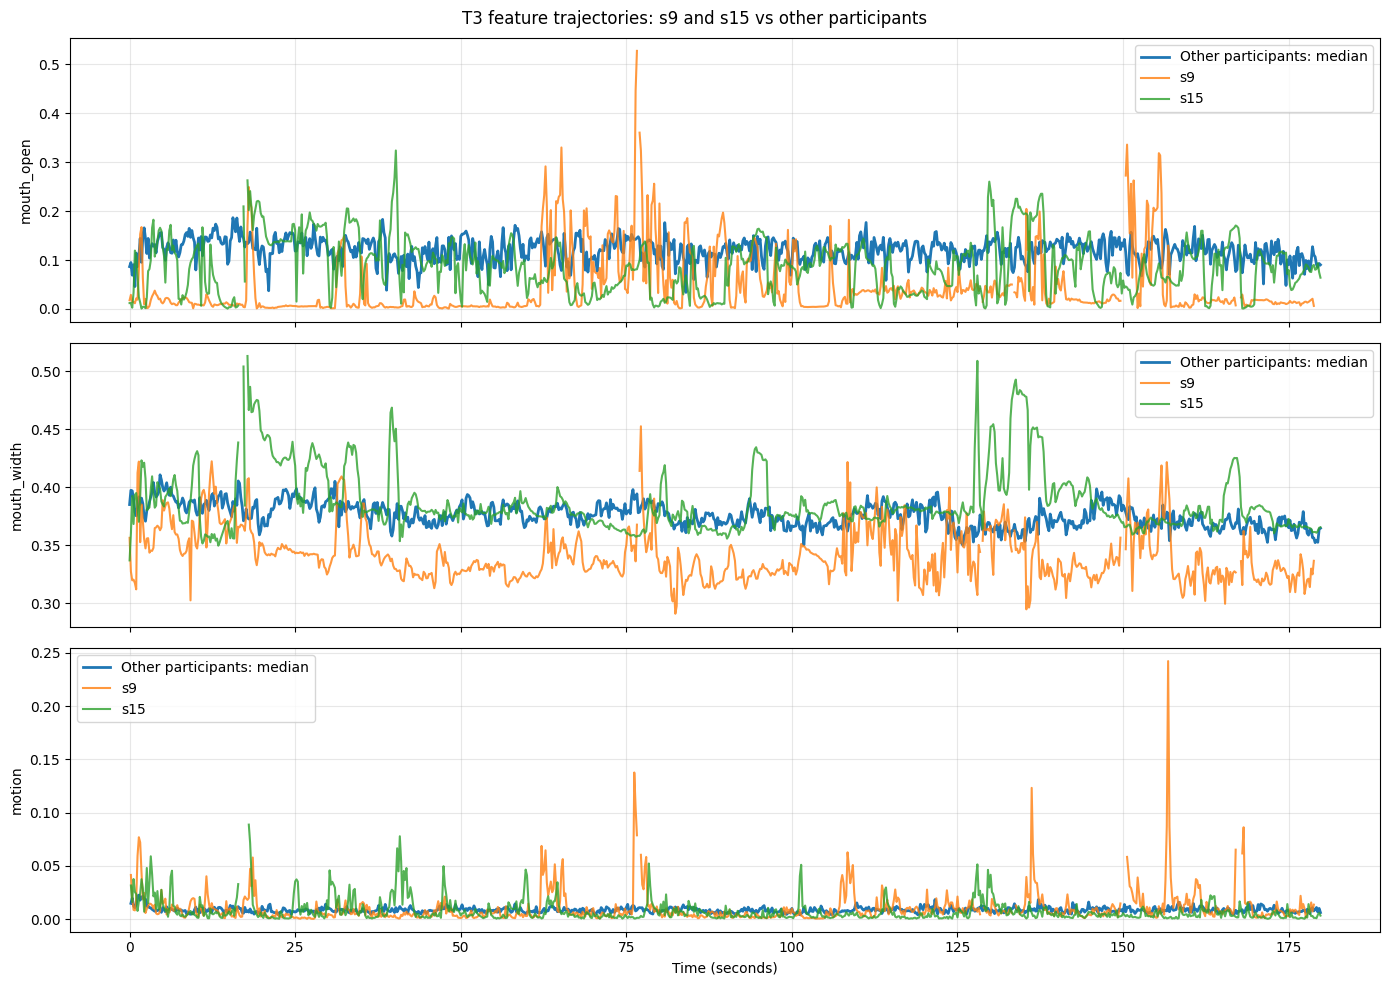

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
frames = pd.read_csv(BASE / "video_frames_compact.csv")

features = ["mouth_open", "mouth_width", "motion"]
focus_ids = ["s9", "s15"]

t3 = frames[frames["session_id"] == "T3"].copy()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for ax, feature in zip(axes, features):
    # Median across other participants at each timestamp
    reference = (
        t3[~t3["subject_id"].isin(focus_ids)]
        .groupby("timestamp_sec")[feature]
        .median()
    )
    ax.plot(
        reference.index, reference.values,
        label="Other participants: median", linewidth=2
    )

    for subject in focus_ids:
        subject_data = t3[t3["subject_id"] == subject]
        ax.plot(
            subject_data["timestamp_sec"],
            subject_data[feature],
            label=subject, alpha=0.8
        )

    ax.set_ylabel(feature)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("T3 feature trajectories: s9 and s15 vs other participants")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Load saved out-of-fold predictions from the speech-feature ablation
pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

print("Shape:", pred.shape)
print("Columns:", pred.columns.tolist())
print(pred.head(10).to_string(index=False))

Shape: (2916, 5)
Columns: ['feature_set', 'subject_id', 'true', 'prediction', 'probability']
 feature_set subject_id  true  prediction  probability
All features         s3     0           0     0.019565
All features         s3     0           0     0.012586
All features         s3     0           0     0.028525
All features         s3     0           0     0.031779
All features         s3     0           0     0.016114
All features         s3     0           0     0.017198
All features         s3     0           1     0.974555
All features         s3     0           0     0.008093
All features         s3     0           0     0.008561
All features         s3     0           0     0.007542


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

print("Feature sets:")
print(pred["feature_set"].value_counts().to_string())

print("\nSubjects:", pred["subject_id"].nunique())
print("Predictions per feature set and subject:")
print(
    pred.groupby(["feature_set", "subject_id"])
        .size()
        .groupby("feature_set")
        .describe()
        .to_string()
)

print("\nLabels by feature set:")
print(pd.crosstab(pred["feature_set"], pred["true"]).to_string())

print("\nOverall accuracy by feature set:")
print(
    pred.assign(correct=pred["true"] == pred["prediction"])
        .groupby("feature_set")["correct"]
        .mean()
        .mul(100)
        .round(2)
        .rename("accuracy_percent")
        .to_string()
)

Feature sets:
feature_set
All features              972
Without mouth features    972
Mouth features only       972

Subjects: 18
Predictions per feature set and subject:
                        count  mean  std   min   25%   50%   75%   max
feature_set                                                           
All features             18.0  54.0  0.0  54.0  54.0  54.0  54.0  54.0
Mouth features only      18.0  54.0  0.0  54.0  54.0  54.0  54.0  54.0
Without mouth features   18.0  54.0  0.0  54.0  54.0  54.0  54.0  54.0

Labels by feature set:
true                      0    1
feature_set                     
All features            324  648
Mouth features only     324  648
Without mouth features  324  648

Overall accuracy by feature set:
feature_set
All features              96.71
Mouth features only       95.99
Without mouth features    89.92


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

focus = ["s9", "s15"]

subset = pred[pred["subject_id"].isin(focus)].copy()
subset["correct"] = subset["true"] == subset["prediction"]

summary = (
    subset.groupby(["subject_id", "feature_set"])
    .agg(
        windows=("correct", "size"),
        correct=("correct", "sum"),
        errors=("correct", lambda x: (~x).sum()),
        accuracy=("correct", "mean"),
        mean_probability=("probability", "mean")
    )
    .reset_index()
)

summary["accuracy"] = (summary["accuracy"] * 100).round(2)
summary["mean_probability"] = summary["mean_probability"].round(4)

print(summary.to_string(index=False))

subject_id            feature_set  windows  correct  errors  accuracy  mean_probability
       s15           All features       54       49       5     90.74            0.5388
       s15    Mouth features only       54       53       1     98.15            0.6121
       s15 Without mouth features       54       33      21     61.11            0.3512
        s9           All features       54       43      11     79.63            0.6313
        s9    Mouth features only       54       43      11     79.63            0.5205
        s9 Without mouth features       54       36      18     66.67            0.6386


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

task_pred = pd.read_csv(
    BASE / "video_loso_predictions_task_verified.csv"
)

print("Shape:", task_pred.shape)
print("Columns:", task_pred.columns.tolist())
print("\nComparison counts:")
print(task_pred["comparison"].value_counts().to_string())

print("\nExamples for s9 and s15:")
print(
    task_pred[
        task_pred["subject_id"].isin(["s9", "s15"])
    ].head(10).to_string(index=False)
)

Shape: (1296, 41)
Columns: ['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 'n_rows', 'n_detected', 'detection_fraction', 'max_missing_run', 'window_complete', 'video_detection_rate', 'label', 'window_reliable', 'f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff', 'f_nod_proxy_absdiff', 'f_tilt_proxy_absdiff', 'f_motion_max', 'f_motion_p90', 'window_key', 'comparison', 'true', 'prediction', 'error']

Comparison counts:
comparison
T1 vs T2    648
T1 vs T3    648

Examples for s9 and s15:
subject_id session_id  window_idx  window_start_sec  window_end_sec  n_rows  n_detected  detection_fraction  max_missing_run  window_complet

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

# Check whether rows are grouped consistently by participant and feature set.
for feature_set in pred["feature_set"].unique():
    df = pred[pred["feature_set"] == feature_set]

    print(f"\n{'=' * 50}")
    print("Feature set:", feature_set)
    print("First 15 subject IDs:")
    print(df["subject_id"].head(15).tolist())

    print("\nSubject counts:")
    print(df["subject_id"].value_counts().sort_index().to_string())

    print("\nRows per subject and true label:")
    print(
        df.groupby(["subject_id", "true"])
          .size()
          .head(12)
          .to_string()
    )


Feature set: All features
First 15 subject IDs:
['s3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3']

Subject counts:
subject_id
s10    54
s11    54
s12    54
s13    54
s14    54
s15    54
s16    54
s17    54
s18    54
s19    54
s20    54
s3     54
s4     54
s5     54
s6     54
s7     54
s8     54
s9     54

Rows per subject and true label:
subject_id  true
s10         0       18
            1       36
s11         0       18
            1       36
s12         0       18
            1       36
s13         0       18
            1       36
s14         0       18
            1       36
s15         0       18
            1       36

Feature set: Without mouth features
First 15 subject IDs:
['s3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3']

Subject counts:
subject_id
s10    54
s11    54
s12    54
s13    54
s14    54
s15    54
s16    54
s17    54
s18    54
s19    54
s20    54
s3     54
s4     54
s5     54
s6     

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

# Check whether rows are grouped consistently by participant and feature set.
for feature_set in pred["feature_set"].unique():
    df = pred[pred["feature_set"] == feature_set]

    print(f"\n{'=' * 50}")
    print("Feature set:", feature_set)
    print("First 15 subject IDs:")
    print(df["subject_id"].head(15).tolist())

    print("\nSubject counts:")
    print(df["subject_id"].value_counts().sort_index().to_string())

    print("\nRows per subject and true label:")
    print(
        df.groupby(["subject_id", "true"])
          .size()
          .head(12)
          .to_string()
    )


Feature set: All features
First 15 subject IDs:
['s3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3']

Subject counts:
subject_id
s10    54
s11    54
s12    54
s13    54
s14    54
s15    54
s16    54
s17    54
s18    54
s19    54
s20    54
s3     54
s4     54
s5     54
s6     54
s7     54
s8     54
s9     54

Rows per subject and true label:
subject_id  true
s10         0       18
            1       36
s11         0       18
            1       36
s12         0       18
            1       36
s13         0       18
            1       36
s14         0       18
            1       36
s15         0       18
            1       36

Feature set: Without mouth features
First 15 subject IDs:
['s3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3', 's3']

Subject counts:
subject_id
s10    54
s11    54
s12    54
s13    54
s14    54
s15    54
s16    54
s17    54
s18    54
s19    54
s20    54
s3     54
s4     54
s5     54
s6     

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

feature_sets = pred["feature_set"].unique().tolist()

reference = (
    pred[pred["feature_set"] == feature_sets[0]]
    [["subject_id", "true"]]
    .reset_index(drop=True)
)

print("Reference feature set:", feature_sets[0])

for name in feature_sets[1:]:
    current = (
        pred[pred["feature_set"] == name]
        [["subject_id", "true"]]
        .reset_index(drop=True)
    )

    same_order = reference.equals(current)
    print(f"{name}: identical subject/label row order = {same_order}")

# Verify row ordering within each participant
for name in feature_sets:
    df = pred[pred["feature_set"] == name].reset_index(drop=True)
    print(f"\n{name}")
    print("First 25 labels for s9:")
    print(df[df["subject_id"] == "s9"]["true"].head(25).tolist())

Reference feature set: All features
Without mouth features: identical subject/label row order = True
Mouth features only: identical subject/label row order = True

All features
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]

Without mouth features
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]

Mouth features only
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")

feature_sets = pred["feature_set"].unique().tolist()

reference = (
    pred[pred["feature_set"] == feature_sets[0]]
    [["subject_id", "true"]]
    .reset_index(drop=True)
)

print("Reference feature set:", feature_sets[0])

for name in feature_sets[1:]:
    current = (
        pred[pred["feature_set"] == name]
        [["subject_id", "true"]]
        .reset_index(drop=True)
    )

    same_order = reference.equals(current)
    print(f"{name}: identical subject/label row order = {same_order}")

# Verify row ordering within each participant
for name in feature_sets:
    df = pred[pred["feature_set"] == name].reset_index(drop=True)
    print(f"\n{name}")
    print("First 25 labels for s9:")
    print(df[df["subject_id"] == "s9"]["true"].head(25).tolist())

Reference feature set: All features
Without mouth features: identical subject/label row order = True
Mouth features only: identical subject/label row order = True

All features
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]

Without mouth features
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]

Mouth features only
First 25 labels for s9:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1]


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")
features = pd.read_csv(BASE / "video_windows.csv")

# Check original feature-table ordering for s9 and s15
for subject in ["s9", "s15"]:
    print(f"\n{'=' * 45}")
    print("Participant:", subject)

    original = features[features["subject_id"] == subject].copy()

    print("Original rows:", len(original))
    print("\nOriginal task/window ordering:")
    print(
        original[
            ["subject_id", "session_id", "window_idx", "label"]
        ].to_string(index=False)
    )

    for feature_set in pred["feature_set"].unique():
        p = pred[
            (pred["feature_set"] == feature_set)
            & (pred["subject_id"] == subject)
        ].reset_index(drop=True)

        print(
            f"\n{feature_set}: "
            f"{len(p)} predictions; "
            f"labels match original row order = "
            f"{p['true'].tolist() == original['label'].tolist()}"
        )


Participant: s9
Original rows: 54

Original task/window ordering:
subject_id session_id  window_idx  label
        s9         T1           0      0
        s9         T1           1      0
        s9         T1           2      0
        s9         T1           3      0
        s9         T1           4      0
        s9         T1           5      0
        s9         T1           6      0
        s9         T1           7      0
        s9         T1           8      0
        s9         T1           9      0
        s9         T1          10      0
        s9         T1          11      0
        s9         T1          12      0
        s9         T1          13      0
        s9         T1          14      0
        s9         T1          15      0
        s9         T1          16      0
        s9         T1          17      0
        s9         T2           0      1
        s9         T2           1      1
        s9         T2           2      1
        s9         T2          

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(BASE / "video_speech_ablation_oof_predictions.csv")
features = pd.read_csv(BASE / "video_windows.csv")

# Reconstruct task/window IDs in the original feature-table order.
features = features.sort_values(
    ["subject_id", "session_id", "window_idx"]
).reset_index(drop=True)

# Verify every participant has exactly 54 windows.
assert features.groupby("subject_id").size().eq(54).all()

# Align each feature set to the original rows within each participant.
aligned = []

for feature_set in pred["feature_set"].unique():
    p = pred[pred["feature_set"] == feature_set].copy()

    for subject in p["subject_id"].unique():
        p_sub = p[p["subject_id"] == subject].reset_index(drop=True)
        f_sub = (
            features[features["subject_id"] == subject]
            .reset_index(drop=True)
        )

        # Labels must match before assigning task/window identifiers.
        assert p_sub["true"].tolist() == f_sub["label"].tolist(), (
            f"Label/order mismatch: {feature_set}, {subject}"
        )

        p_sub["session_id"] = f_sub["session_id"].values
        p_sub["window_idx"] = f_sub["window_idx"].values
        aligned.append(p_sub)

aligned = pd.concat(aligned, ignore_index=True)
aligned["correct"] = aligned["true"] == aligned["prediction"]

# T3-only results by participant and feature set.
t3 = aligned[
    (aligned["session_id"] == "T3")
    & (aligned["subject_id"].isin(["s9", "s15"]))
]

summary = (
    t3.groupby(["subject_id", "feature_set"])
    .agg(
        windows=("correct", "size"),
        correct=("correct", "sum"),
        errors=("correct", lambda x: (~x).sum()),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

summary["accuracy_pct"] = (summary["accuracy"] * 100).round(2)

print("T3 performance for s9 and s15:")
print(summary.drop(columns="accuracy").to_string(index=False))

print("\nT3 misclassified windows:")
print(
    t3[~t3["correct"]][
        ["subject_id", "feature_set", "window_idx",
         "true", "prediction", "probability"]
    ].sort_values(
        ["subject_id", "window_idx", "feature_set"]
    ).to_string(index=False)
)

T3 performance for s9 and s15:
subject_id            feature_set  windows  correct  errors  accuracy_pct
       s15           All features       18       16       2         88.89
       s15    Mouth features only       18       18       0        100.00
       s15 Without mouth features       18        7      11         38.89
        s9           All features       18       12       6         66.67
        s9    Mouth features only       18       10       8         55.56
        s9 Without mouth features       18        8      10         44.44

T3 misclassified windows:
subject_id            feature_set  window_idx  true  prediction  probability
       s15 Without mouth features           2     1           0     0.390349
       s15 Without mouth features           5     1           0     0.270224
       s15           All features           6     1           0     0.247960
       s15 Without mouth features           6     1           0     0.228970
       s15 Without mouth features      

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Folder exists:", BASE.exists())
print("\nAvailable CSV files:")

for f in sorted(BASE.glob("*.csv")):
    print(f"{f.name:45s} {f.stat().st_size / 1024:.1f} KB")

Folder exists: True

Available CSV files:
bvp_s10_T1.csv                                64.7 KB
bvp_s10_T2.csv                                68.3 KB
bvp_s10_T3.csv                                68.0 KB
bvp_s11_T1.csv                                64.9 KB
bvp_s11_T2.csv                                72.0 KB
bvp_s11_T3.csv                                67.1 KB
bvp_s12_T1.csv                                67.2 KB
bvp_s12_T2.csv                                69.3 KB
bvp_s12_T3.csv                                66.8 KB
bvp_s13_T1.csv                                66.9 KB
bvp_s13_T2.csv                                76.5 KB
bvp_s13_T3.csv                                70.7 KB
bvp_s14_T1.csv                                67.7 KB
bvp_s14_T2.csv                                71.7 KB
bvp_s14_T3.csv                                71.7 KB
bvp_s15_T1.csv                                68.0 KB
bvp_s15_T2.csv                                67.1 KB
bvp_s15_T3.csv                          

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(BASE / "video_windows.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nRows per participant:")
print(df.groupby("subject_id").size().describe())

print("\nTasks and labels:")
print(pd.crosstab(df["session_id"], df["label"]))

print("\nFeature columns:")
features = [c for c in df.columns if c.startswith("f_")]
print("Total:", len(features))
print(features)

print("\nReliability:")
print(df["window_reliable"].value_counts(dropna=False))

Shape: (972, 36)

Columns:
['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 'n_rows', 'n_detected', 'detection_fraction', 'max_missing_run', 'window_complete', 'video_detection_rate', 'label', 'window_reliable', 'f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff', 'f_nod_proxy_absdiff', 'f_tilt_proxy_absdiff', 'f_motion_max', 'f_motion_p90']

Rows per participant:
count    18.0
mean     54.0
std       0.0
min      54.0
25%      54.0
50%      54.0
75%      54.0
max      54.0
dtype: float64

Tasks and labels:
label         0    1
session_id          
T1          324    0
T2            0  324
T3            0  324

Feature colum

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(BASE / "video_windows.csv")

# Sort explicitly so metadata and predictions retain stable row identities.
df = df.sort_values(
    ["subject_id", "session_id", "window_idx"]
).reset_index(drop=True)

all_features = [c for c in df.columns if c.startswith("f_")]

mouth_features = [
    "f_mouth_open_mean",
    "f_mouth_open_std",
    "f_mouth_width_mean",
    "f_mouth_width_std"
]

feature_sets = {
    "All features": all_features,
    "Mouth features only": mouth_features,
    "Without mouth features": [
        c for c in all_features if c not in mouth_features
    ]
}

# Validate the inputs.
assert len(df) == 972
assert df["subject_id"].nunique() == 18
assert df["window_key"].is_unique if "window_key" in df.columns else True
assert set(df["label"].unique()) == {0, 1}
assert df["window_reliable"].all()
assert all(c in df.columns for c in mouth_features)

groups = df["subject_id"].to_numpy()
y = df["label"].to_numpy()

logo = LeaveOneGroupOut()

# Standardize using training-fold statistics only.
# Imputation is included defensively and is also fitted within each fold.
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)

all_predictions = []
summary_rows = []
participant_rows = []

for feature_set, cols in feature_sets.items():
    X = df[cols].replace([np.inf, -np.inf], np.nan)

    oof_pred = np.full(len(df), -1, dtype=int)
    oof_prob = np.full(len(df), np.nan, dtype=float)

    for train_idx, test_idx in logo.split(X, y, groups):
        fold_model = clone(model)

        fold_model.fit(X.iloc[train_idx], y[train_idx])

        oof_pred[test_idx] = fold_model.predict(X.iloc[test_idx])
        oof_prob[test_idx] = fold_model.predict_proba(
            X.iloc[test_idx]
        )[:, 1]

    assert (oof_pred >= 0).all()
    assert np.isfinite(oof_prob).all()

    out = df[
        [
            "subject_id", "session_id", "window_idx",
            "window_start_sec", "window_end_sec", "label"
        ]
    ].copy()

    out["feature_set"] = feature_set
    out["true"] = y
    out["prediction"] = oof_pred
    out["probability_class1"] = oof_prob
    out["correct"] = out["true"] == out["prediction"]
    out["error"] = ~out["correct"]

    all_predictions.append(out)

    summary_rows.append({
        "feature_set": feature_set,
        "n_windows": len(out),
        "accuracy": accuracy_score(y, oof_pred),
        "balanced_accuracy": balanced_accuracy_score(y, oof_pred),
        "macro_f1": f1_score(y, oof_pred, average="macro")
    })

    for subject, part in out.groupby("subject_id"):
        participant_rows.append({
            "feature_set": feature_set,
            "subject_id": subject,
            "n_windows": len(part),
            "errors": int(part["error"].sum()),
            "accuracy": accuracy_score(
                part["true"], part["prediction"]
            )
        })

predictions = pd.concat(all_predictions, ignore_index=True)
summary = pd.DataFrame(summary_rows)
participant_metrics = pd.DataFrame(participant_rows)

# Save all outputs.
predictions.to_csv(
    BASE / "video_ablation_verified_v2_predictions.csv",
    index=False
)
summary.to_csv(
    BASE / "video_ablation_verified_v2_summary.csv",
    index=False
)
participant_metrics.to_csv(
    BASE / "video_ablation_verified_v2_participant_metrics.csv",
    index=False
)

print("OVERALL LOSO RESULTS")
print(summary.round(4).to_string(index=False))

print("\nT3 RESULTS FOR s9 AND s15")
t3_focus = predictions[
    (predictions["session_id"] == "T3")
    & (predictions["subject_id"].isin(["s9", "s15"]))
]

print(
    t3_focus.groupby(["subject_id", "feature_set"])
    .agg(
        windows=("correct", "size"),
        correct=("correct", "sum"),
        errors=("error", "sum"),
        accuracy=("correct", "mean")
    )
    .reset_index()
    .round(4)
    .to_string(index=False)
)

print("\nSaved predictions:", len(predictions))
print("Saved to:", BASE)

OVERALL LOSO RESULTS
           feature_set  n_windows  accuracy  balanced_accuracy  macro_f1
          All features        972    0.9691             0.9684    0.9655
   Mouth features only        972    0.9630             0.9645    0.9588
Without mouth features        972    0.9208             0.9236    0.9130

T3 RESULTS FOR s9 AND s15
subject_id            feature_set  windows  correct  errors  accuracy
       s15           All features       18       16       2    0.8889
       s15    Mouth features only       18       18       0    1.0000
       s15 Without mouth features       18       10       8    0.5556
        s9           All features       18       12       6    0.6667
        s9    Mouth features only       18       11       7    0.6111
        s9 Without mouth features       18       12       6    0.6667

Saved predictions: 2916
Saved to: /content/drive/MyDrive/ubfc_test_upload.


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)

# Participant-level performance for each feature set
participant = (
    pred.groupby(["subject_id", "feature_set"])
    .agg(
        windows=("correct", "size"),
        errors=("error", "sum"),
        accuracy=("correct", "mean")
    )
    .reset_index()
)

participant["accuracy_pct"] = (
    participant["accuracy"] * 100
).round(2)

print("LOWEST-ACCURACY PARTICIPANTS: ALL FEATURES")
print(
    participant[
        participant["feature_set"] == "All features"
    ]
    .sort_values("accuracy")
    .head(10)[
        ["subject_id", "windows", "errors", "accuracy_pct"]
    ]
    .to_string(index=False)
)

print("\nFEATURE-SET COMPARISON FOR EVERY PARTICIPANT")
wide = participant.pivot(
    index="subject_id",
    columns="feature_set",
    values="accuracy_pct"
)

wide["mouth_gain_vs_without"] = (
    wide["Mouth features only"]
    - wide["Without mouth features"]
)

print(wide.round(2).sort_values("All features").to_string())

LOWEST-ACCURACY PARTICIPANTS: ALL FEATURES
subject_id  windows  errors  accuracy_pct
        s9       54      11         79.63
       s15       54       5         90.74
        s6       54       3         94.44
       s14       54       2         96.30
       s18       54       2         96.30
        s3       54       2         96.30
       s13       54       2         96.30
       s11       54       2         96.30
        s5       54       1         98.15
       s17       54       0        100.00

FEATURE-SET COMPARISON FOR EVERY PARTICIPANT
feature_set  All features  Mouth features only  Without mouth features  mouth_gain_vs_without
subject_id                                                                                   
s9                  79.63                81.48                   74.07                   7.41
s15                 90.74                98.15                   77.78                  20.37
s6                  94.44                92.59                   90.74   

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)

# Keep T3 windows and pivot predictions into comparable columns.
t3 = pred[pred["session_id"] == "T3"].copy()

wide = t3.pivot(
    index=["subject_id", "session_id", "window_idx", "true"],
    columns="feature_set",
    values="prediction"
).reset_index()

wide.columns.name = None

all_col = "All features"
mouth_col = "Mouth features only"
nonmouth_col = "Without mouth features"

# Error indicator for each feature set
for name, col in [
    ("all", all_col),
    ("mouth", mouth_col),
    ("nonmouth", nonmouth_col)
]:
    wide[f"{name}_error"] = wide[col] != wide["true"]

print("T3 window-level agreement patterns:")
print(
    wide.groupby(["all_error", "mouth_error", "nonmouth_error"])
    .size()
    .rename("number_of_windows")
    .reset_index()
    .to_string(index=False)
)

print("\nWindows where all features are wrong but mouth-only is correct:")
print(
    wide[
        wide["all_error"]
        & ~wide["mouth_error"]
    ][
        ["subject_id", "window_idx", "true",
         all_col, mouth_col, nonmouth_col]
    ].to_string(index=False)
)

print("\nT3 error counts by participant:")
print(
    wide.groupby("subject_id")[
        ["all_error", "mouth_error", "nonmouth_error"]
    ].sum().sort_values("all_error", ascending=False).to_string()
)

T3 window-level agreement patterns:
 all_error  mouth_error  nonmouth_error  number_of_windows
     False        False           False                272
     False        False            True                 31
     False         True           False                  6
     False         True            True                  3
      True        False            True                  6
      True         True           False                  3
      True         True            True                  3

Windows where all features are wrong but mouth-only is correct:
subject_id  window_idx  true  All features  Mouth features only  Without mouth features
       s11          10     1             0                    1                       0
       s11          12     1             0                    1                       0
       s15           6     1             0                    1                       0
       s15          15     1             0                    1            

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)

t3 = pred[pred["session_id"] == "T3"].copy()

wide = t3.pivot(
    index=["subject_id", "session_id", "window_idx", "true"],
    columns="feature_set",
    values="prediction"
).reset_index()

wide.columns.name = None

cols = [
    "All features",
    "Mouth features only",
    "Without mouth features"
]

for col in cols:
    wide[col + "_error"] = wide[col] != wide["true"]

shared = wide[
    wide[[c + "_error" for c in cols]].all(axis=1)
]

print("Windows where all three models fail:")
print(
    shared[
        ["subject_id", "window_idx", "true"] + cols
    ].to_string(index=False)
)

# Join the corresponding original video features.
features = pd.read_csv(BASE / "video_windows.csv")

detail = shared.merge(
    features,
    on=["subject_id", "session_id", "window_idx", "label"],
    how="left",
    validate="one_to_one"
)

print("\nOriginal features for shared failure windows:")
print(
    detail[
        ["subject_id", "window_idx",
         "detection_fraction", "max_missing_run",
         "f_mouth_open_mean", "f_mouth_open_std",
         "f_mouth_width_mean", "f_mouth_width_std",
         "f_motion_mean", "f_motion_std",
         "f_ear_mean_mean", "f_brow_eye_mean"]
    ].to_string(index=False)
)

Windows where all three models fail:
subject_id  window_idx  true  All features  Mouth features only  Without mouth features
       s18           4     1             0                    0                       0
        s9           2     1             0                    0                       0
        s9           5     1             0                    0                       0


KeyError: 'label'

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)
features = pd.read_csv(BASE / "video_windows.csv")

# Keep only T3 predictions.
t3 = pred[pred["session_id"] == "T3"].copy()

# Pivot predictions for the three feature sets.
wide = t3.pivot(
    index=["subject_id", "session_id", "window_idx", "true"],
    columns="feature_set",
    values="prediction"
).reset_index()

wide.columns.name = None

cols = [
    "All features",
    "Mouth features only",
    "Without mouth features"
]

for col in cols:
    wide[col + "_error"] = wide[col] != wide["true"]

# Windows where all three models fail.
shared = wide[
    wide[[c + "_error" for c in cols]].all(axis=1)
].copy()

# Join using matching identifiers; map true to the original label column.
detail = shared.merge(
    features,
    left_on=["subject_id", "session_id", "window_idx", "true"],
    right_on=["subject_id", "session_id", "window_idx", "label"],
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (detail["_merge"] == "both").all(), (
    "Some windows did not match the original feature table."
)

inspect_cols = [
    "subject_id", "session_id", "window_idx",
    "detection_fraction", "max_missing_run",
    "f_mouth_open_mean", "f_mouth_open_std",
    "f_mouth_width_mean", "f_mouth_width_std",
    "f_motion_mean", "f_motion_std",
    "f_ear_mean_mean", "f_brow_eye_mean"
]

print("Original features for shared failure windows:")
print(detail[inspect_cols].to_string(index=False))

Original features for shared failure windows:
subject_id session_id  window_idx  detection_fraction  max_missing_run  f_mouth_open_mean  f_mouth_open_std  f_mouth_width_mean  f_mouth_width_std  f_motion_mean  f_motion_std  f_ear_mean_mean  f_brow_eye_mean
       s18         T3           4                 1.0                0           0.082268          0.011187            0.320689           0.003946       0.002415      0.002745         0.341414         0.125929
        s9         T3           2                 1.0                0           0.005114          0.003060            0.342536           0.005121       0.003059      0.002830         0.133145         0.221638
        s9         T3           5                 1.0                0           0.005656          0.002890            0.327749           0.005960       0.004116      0.002849         0.165661         0.218694


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(BASE / "video_windows.csv")

features = [
    "f_mouth_open_mean",
    "f_mouth_open_std",
    "f_mouth_width_mean",
    "f_mouth_width_std",
    "f_motion_mean",
    "f_motion_std",
    "f_ear_mean_mean",
    "f_brow_eye_mean"
]

targets = [
    ("s9", 2),
    ("s9", 5),
    ("s18", 4)
]

for subject, window_idx in targets:
    target = df[
        (df["subject_id"] == subject)
        & (df["session_id"] == "T3")
        & (df["window_idx"] == window_idx)
    ].iloc[0]

    baseline = df[
        (df["subject_id"] == subject)
        & (df["session_id"] == "T1")
    ]

    print(f"\n{'=' * 65}")
    print(f"{subject} | T3 window {window_idx}")
    print(f"{target['window_start_sec']:.0f}–"
          f"{target['window_end_sec']:.0f} seconds")
    print(f"{'Feature':28s} {'T3 window':>12s} "
          f"{'T1 median':>12s} {'Difference':>12s}")

    for feature in features:
        value = target[feature]
        rest_median = baseline[feature].median()

        print(
            f"{feature:28s} "
            f"{value:12.5f} "
            f"{rest_median:12.5f} "
            f"{value - rest_median:12.5f}"
        )


s9 | T3 window 2
20–30 seconds
Feature                         T3 window    T1 median   Difference
f_mouth_open_mean                 0.00511      0.01993     -0.01482
f_mouth_open_std                  0.00306      0.00580     -0.00275
f_mouth_width_mean                0.34254      0.34804     -0.00550
f_mouth_width_std                 0.00512      0.01067     -0.00554
f_motion_mean                     0.00306      0.00613     -0.00307
f_motion_std                      0.00283      0.00726     -0.00443
f_ear_mean_mean                   0.13314      0.26746     -0.13431
f_brow_eye_mean                   0.22164      0.16041      0.06123

s9 | T3 window 5
50–60 seconds
Feature                         T3 window    T1 median   Difference
f_mouth_open_mean                 0.00566      0.01993     -0.01428
f_mouth_open_std                  0.00289      0.00580     -0.00292
f_mouth_width_mean                0.32775      0.34804     -0.02029
f_mouth_width_std                 0.00596      0.010

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(BASE / "video_windows.csv")

features = [
    "f_mouth_open_mean",
    "f_mouth_width_mean",
    "f_motion_mean",
    "f_ear_mean_mean",
    "f_brow_eye_mean"
]

targets = [
    ("s9", 2),
    ("s9", 5),
    ("s18", 4)
]

t3 = df[df["session_id"] == "T3"].copy()

for subject, idx in targets:
    row = t3[
        (t3["subject_id"] == subject)
        & (t3["window_idx"] == idx)
    ].iloc[0]

    print(f"\n{'=' * 60}")
    print(f"{subject}, T3 window {idx}")

    for feature in features:
        values = t3[feature].dropna()
        value = row[feature]

        percentile = 100 * (
            (values < value).sum() + 0.5 * (values == value).sum()
        ) / len(values)

        print(
            f"{feature:24s} value={value:.5f} "
            f"T3 percentile={percentile:.1f}"
        )


s9, T3 window 2
f_mouth_open_mean        value=0.00511 T3 percentile=0.2
f_mouth_width_mean       value=0.34254 T3 percentile=14.0
f_motion_mean            value=0.00306 T3 percentile=2.3
f_ear_mean_mean          value=0.13314 T3 percentile=1.1
f_brow_eye_mean          value=0.22164 T3 percentile=99.5

s9, T3 window 5
f_mouth_open_mean        value=0.00566 T3 percentile=0.5
f_mouth_width_mean       value=0.32775 T3 percentile=8.5
f_motion_mean            value=0.00412 T3 percentile=9.1
f_ear_mean_mean          value=0.16566 T3 percentile=3.9
f_brow_eye_mean          value=0.21869 T3 percentile=98.6

s18, T3 window 4
f_mouth_open_mean        value=0.08227 T3 percentile=28.2
f_mouth_width_mean       value=0.32069 T3 percentile=2.9
f_motion_mean            value=0.00242 T3 percentile=0.2
f_ear_mean_mean          value=0.34141 T3 percentile=77.9
f_brow_eye_mean          value=0.12593 T3 percentile=19.0


In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred_path = BASE / "video_ablation_verified_v2_predictions.csv"
pred = pd.read_csv(pred_path)

targets = [
    ("s9", 2),
    ("s9", 5),
    ("s18", 4)
]

for subject, idx in targets:
    print(f"\n{'=' * 65}")
    print(f"{subject} | T3 | window {idx}")

    row = pred[
        (pred["subject_id"] == subject)
        & (pred["session_id"] == "T3")
        & (pred["window_idx"] == idx)
    ]

    cols = [
        "subject_id",
        "session_id",
        "window_idx",
        "true",
        "model",
        "prediction",
        "probability_class1",
        "correct",
    ]

    print(row[cols].to_string(index=False))


s9 | T3 | window 2


KeyError: "['model'] not in index"

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred_path = BASE / "video_ablation_verified_v2_predictions.csv"

pred = pd.read_csv(pred_path)

print("Shape:", pred.shape)
print("\nAvailable columns:")
print(pred.columns.tolist())

print("\nFirst 5 rows:")
print(pred.head().to_string(index=False))

Shape: (2916, 12)

Available columns:
['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 'label', 'feature_set', 'true', 'prediction', 'probability_class1', 'correct', 'error']

First 5 rows:
subject_id session_id  window_idx  window_start_sec  window_end_sec  label  feature_set  true  prediction  probability_class1  correct  error
       s10         T1           0               0.0            10.0      0 All features     0           0            0.000276     True  False
       s10         T1           1              10.0            20.0      0 All features     0           0            0.003039     True  False
       s10         T1           2              20.0            30.0      0 All features     0           0            0.087252     True  False
       s10         T1           3              30.0            40.0      0 All features     0           0            0.179598     True  False
       s10         T1           4              40.0            50.0 

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)

targets = [
    ("s9", 2),
    ("s9", 5),
    ("s18", 4)
]

print("Feature sets:", pred["feature_set"].unique())

for subject, idx in targets:
    print(f"\n{'=' * 70}")
    print(f"{subject} | T3 | window {idx}")

    row = pred[
        (pred["subject_id"] == subject)
        & (pred["session_id"] == "T3")
        & (pred["window_idx"] == idx)
    ]

    cols = [
        "subject_id",
        "session_id",
        "window_idx",
        "feature_set",
        "true",
        "prediction",
        "probability_class1",
        "correct",
    ]

    print(row[cols].to_string(index=False))

Feature sets: ['All features' 'Mouth features only' 'Without mouth features']

s9 | T3 | window 2
subject_id session_id  window_idx            feature_set  true  prediction  probability_class1  correct
        s9         T3           2           All features     1           0            0.026045    False
        s9         T3           2    Mouth features only     1           0            0.025742    False
        s9         T3           2 Without mouth features     1           0            0.068035    False

s9 | T3 | window 5
subject_id session_id  window_idx            feature_set  true  prediction  probability_class1  correct
        s9         T3           5           All features     1           0            0.026337    False
        s9         T3           5    Mouth features only     1           0            0.021721    False
        s9         T3           5 Without mouth features     1           0            0.389980    False

s18 | T3 | window 4
subject_id session_id  window

In [ ]:
import pandas as pd
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "video_ablation_verified_v2_predictions.csv"
)

features = pd.read_csv(
    BASE / "video_windows.csv"
)

keys = ["subject_id", "session_id", "window_idx"]

print("Prediction rows:", len(pred))
print("Feature rows:", len(features))

print(
    "Duplicate prediction keys:",
    pred.duplicated(keys + ["feature_set"]).sum()
)

print(
    "Duplicate feature keys:",
    features.duplicated(keys).sum()
)

merged = pred.merge(
    features,
    on=keys,
    how="left",
    validate="many_to_one",
    suffixes=("_pred", "_feature"),
    indicator=True
)

print("\nMerge results:")
print(merged["_merge"].value_counts())

print("\nMerged shape:", merged.shape)
print(
    merged[
        keys + ["feature_set", "true", "prediction",
                "probability_class1", "f_mouth_open_mean",
                "f_motion_mean"]
    ].head(10).to_string(index=False)
)

Prediction rows: 2916
Feature rows: 972
Duplicate prediction keys: 0
Duplicate feature keys: 0

Merge results:
_merge
both          2916
left_only        0
right_only       0
Name: count, dtype: int64

Merged shape: (2916, 46)
subject_id session_id  window_idx  feature_set  true  prediction  probability_class1  f_mouth_open_mean  f_motion_mean
       s10         T1           0 All features     0           0            0.000276           0.024873       0.008062
       s10         T1           1 All features     0           0            0.003039           0.014774       0.002490
       s10         T1           2 All features     0           0            0.087252           0.023488       0.001383
       s10         T1           3 All features     0           0            0.179598           0.028335       0.000424
       s10         T1           4 All features     0           0            0.001931           0.020414       0.007538
       s10         T1           5 All features     0       

In [ ]:
import importlib.util

packages = ["streamlit", "pandas", "numpy", "plotly"]

for package in packages:
    print(
        f"{package}:",
        "installed" if importlib.util.find_spec(package)
        else "not installed"
    )

streamlit: not installed
pandas: installed
numpy: installed
plotly: installed


In [ ]:
from pathlib import Path
import os

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

keywords = [
    "fusion",
    "multimodal",
    "cross_modal",
    "video",
    "physiology",
    "loso",
    "prediction",
    "result"
]

for path in sorted(BASE.iterdir()):
    if path.is_file() and any(
        word in path.name.lower() for word in keywords
    ):
        print(path.name)

cnn_loso_verified_v1_manifest.json
cnn_loso_verified_v1_metrics.csv
cnn_loso_verified_v1_participant_metrics.csv
cnn_loso_verified_v1_predictions.csv
cnn_lstm_loso_manifest.json
cnn_lstm_loso_metrics.csv
cnn_lstm_loso_participant_metrics.csv
cnn_lstm_loso_predictions.csv
cnn_lstm_loso_progress.json
cnn_oof_predictions_full.csv
cnn_participant_results_final.csv
cnn_results_final.csv
cnn_tcn_lstm_loso_metrics.csv
cnn_tcn_lstm_loso_participant_metrics.csv
cnn_tcn_lstm_loso_predictions.csv
cnn_tcn_lstm_loso_progress.json
loso_baseline_results.csv
loso_per_participant_results.csv
loso_rest_calibration_repeated_metrics.csv
loso_rest_calibration_repeated_predictions.csv
loso_rest_calibration_results.csv
loso_rest_calibration_stress_tasks_only.csv
physiology_features_all56.csv
physiology_features_fused.csv
physiology_features_labeled.csv
physiology_file_inventory.csv
physiology_quality_screen.csv
physiology_signal_quality_audit.csv
physiology_window_quality_audit.csv
s3_T1_video_features.csv
s

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# 1. Inspect experiment summaries for fusion-related results
for name in [
    "cnn_loso_verified_v1_metrics.csv",
    "cnn_tcn_lstm_loso_metrics.csv",
    "tcn_lstm_results_final.csv",
    "video_ablation_verified_v2_summary.csv",
    "physiology_features_labeled.csv",
]:
    path = BASE / name
    if path.exists():
        print(f"\n{'=' * 65}\n{name}")
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(5).to_string(index=False))

# 2. Check participant overlap between video and physiology
video = pd.read_csv(BASE / "video_windows.csv")
phys = pd.read_csv(BASE / "physiology_features_labeled.csv")

video_ids = set(video["subject_id"].astype(str).str.lower().str.strip())

# Physiology data may use a different participant column name.
print("\nPhysiology columns:", phys.columns.tolist())

print("\nVideo participants:", len(video_ids))
print("Example video IDs:", sorted(video_ids)[:10])

for col in ["participant", "subject_id", "participant_id"]:
    if col in phys.columns:
        phys_ids = set(
            phys[col].dropna().astype(str).str.lower().str.strip()
        )
        overlap = video_ids & phys_ids
        print(f"\nPhysiology ID column: {col}")
        print("Physiology participants:", len(phys_ids))
        print("Exact ID overlap:", len(overlap))
        print("Overlapping IDs:", sorted(overlap)[:30])


cnn_loso_verified_v1_metrics.csv
Shape: (1, 8)
Columns: ['model', 'participants', 'windows', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
model  participants  windows  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
  CNN            56     5880  0.763605            0.76301         0.741518       0.76301   0.74701

cnn_tcn_lstm_loso_metrics.csv
Shape: (1, 9)
Columns: ['model', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1', 'threshold', 'n_windows', 'n_participants']
       model  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1  threshold  n_windows  n_participants
CNN-TCN-LSTM  0.820748           0.779719         0.805901      0.779719  0.789935        0.5       5880              56

tcn_lstm_results_final.csv
Shape: (2, 8)
Columns: ['model', 'participants', 'windows', 'accuracy', 'balanced_accuracy', 'macro_precision', 'macro_recall', 'macro_f1']
model  participants  windows  

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Inspect participant metadata and manifests
for name in [
    "participant_metadata.csv",
    "cnn_loso_verified_v1_manifest.json",
    "cnn_lstm_loso_manifest.json",
    "cnn_loso_verified_v1_predictions.csv",
]:
    path = BASE / name

    if not path.exists():
        print(f"\nNOT FOUND: {name}")
        continue

    print(f"\n{'=' * 65}\n{name}")

    if path.suffix == ".csv":
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(10).to_string(index=False))
    else:
        print(path.read_text()[:5000])


NOT FOUND: participant_metadata.csv

cnn_loso_verified_v1_manifest.json
{
  "run_name": "cnn_loso_verified_v1",
  "data_path": "/content/drive/MyDrive/ubfc_test_upload./raw_signal_windows.npz",
  "n_windows": 5880,
  "n_participants": 56,
  "bvp_shape": [
    5880,
    640,
    1
  ],
  "eda_shape": [
    5880,
    40,
    1
  ],
  "seed": 42,
  "max_epochs": 20,
  "batch_size": 64,
  "patience": 4,
  "validation_group_fraction": 0.15,
  "threshold": 0.5,
  "architecture": "two-branch CNN: BVP Conv32/64; EDA Conv16/32; fusion Dense32"
}

cnn_lstm_loso_manifest.json
{
  "model": "CNN-LSTM",
  "status": "completed",
  "protocol": "56-participant LeaveOneGroupOut",
  "seed_base": 42,
  "max_epochs": 20,
  "batch_size": 64,
  "patience": 4,
  "validation_split": "GroupShuffleSplit, test_size=0.15",
  "threshold": 0.5,
  "windows": 5880,
  "participants": 56,
  "completed_participants": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Inspect raw physiology window metadata
path = BASE / "raw_signal_window_metadata.csv"

if path.exists():
    meta = pd.read_csv(path)

    print("Shape:", meta.shape)
    print("\nColumns:")
    print(meta.columns.tolist())

    print("\nFirst 10 rows:")
    print(meta.head(10).to_string(index=False))

    for col in ["participant", "subject_id", "task",
                "start_s", "end_s", "window_idx"]:
        if col in meta.columns:
            print(f"\n{col}:")
            print("Unique values:", meta[col].nunique())
            print("Examples:", meta[col].dropna().unique()[:15])
else:
    print("raw_signal_window_metadata.csv not found")

# Inspect video participant and timing identifiers
video_path = BASE / "video_windows.csv"
video = pd.read_csv(video_path)

print("\n" + "=" * 60)
print("VIDEO WINDOW METADATA")
print("Columns:", video.columns.tolist())

cols = [
    c for c in [
        "subject_id", "session_id", "window_idx",
        "window_start_sec", "window_end_sec"
    ] if c in video.columns
]

print(video[cols].head(10).to_string(index=False))

Shape: (5880, 5)

Columns:
['participant', 'task', 'start_s', 'end_s', 'label']

First 10 rows:
 participant  task  start_s  end_s  label
           1     1      0.0   10.0      0
           1     1      5.0   15.0      0
           1     1     10.0   20.0      0
           1     1     15.0   25.0      0
           1     1     20.0   30.0      0
           1     1     25.0   35.0      0
           1     1     30.0   40.0      0
           1     1     35.0   45.0      0
           1     1     40.0   50.0      0
           1     1     45.0   55.0      0

participant:
Unique values: 56
Examples: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]

task:
Unique values: 3
Examples: [1 2 3]

start_s:
Unique values: 35
Examples: [ 0.  5. 10. 15. 20. 25. 30. 35. 40. 45. 50. 55. 60. 65. 70.]

end_s:
Unique values: 35
Examples: [10. 15. 20. 25. 30. 35. 40. 45. 50. 55. 60. 65. 70. 75. 80.]

VIDEO WINDOW METADATA
Columns: ['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

video = pd.read_csv(BASE / "video_windows.csv")
phys = pd.read_csv(BASE / "raw_signal_window_metadata.csv")

# Summarise video coverage by participant and task
video_summary = (
    video.groupby(["subject_id", "session_id"])
    .agg(
        video_windows=("window_idx", "count"),
        video_start=("window_start_sec", "min"),
        video_end=("window_end_sec", "max"),
        video_label=("label", "first")
    )
    .reset_index()
)

# Summarise physiology coverage by participant and task
phys_summary = (
    phys.groupby(["participant", "task"])
    .agg(
        phys_windows=("start_s", "count"),
        phys_start=("start_s", "min"),
        phys_end=("end_s", "max"),
        phys_label=("label", "first")
    )
    .reset_index()
)

print("VIDEO COVERAGE")
print(video_summary.groupby("session_id").agg(
    participants=("subject_id", "nunique"),
    min_windows=("video_windows", "min"),
    max_windows=("video_windows", "max"),
    min_duration=("video_end", "min"),
    max_duration=("video_end", "max")
).to_string())

print("\nPHYSIOLOGY COVERAGE")
print(phys_summary.groupby("task").agg(
    participants=("participant", "nunique"),
    min_windows=("phys_windows", "min"),
    max_windows=("phys_windows", "max"),
    min_duration=("phys_end", "min"),
    max_duration=("phys_end", "max")
).to_string())

print("\nVIDEO LABELS BY TASK")
print(video.groupby("session_id")["label"].value_counts().to_string())

print("\nPHYSIOLOGY LABELS BY TASK")
print(phys.groupby("task")["label"].value_counts().to_string())

VIDEO COVERAGE
            participants  min_windows  max_windows  min_duration  max_duration
session_id                                                                    
T1                    18           18           18         180.0         180.0
T2                    18           18           18         180.0         180.0
T3                    18           18           18         180.0         180.0

PHYSIOLOGY COVERAGE
      participants  min_windows  max_windows  min_duration  max_duration
task                                                                    
1               56           35           35         180.0         180.0
2               56           35           35         180.0         180.0
3               56           35           35         180.0         180.0

VIDEO LABELS BY TASK
session_id  label
T1          0        324
T2          1        324
T3          1        324

PHYSIOLOGY LABELS BY TASK
task  label
1     0        1960
2     1        1960
3     1   

In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

for path in sorted(BASE.iterdir()):
    name = path.name.lower()

    if any(term in name for term in [
        "metadata", "manifest", "participant",
        "subject", "session", "inventory",
        "readme", "mapping", "source"
    ]):
        print(f"{path.name}  [{path.stat().st_size:,} bytes]")

cnn_loso_verified_v1_manifest.json  [470 bytes]
cnn_loso_verified_v1_participant_metrics.csv  [3,404 bytes]
cnn_lstm_loso_manifest.json  [1,155 bytes]
cnn_lstm_loso_participant_metrics.csv  [4,937 bytes]
cnn_participant_results_final.csv  [3,487 bytes]
cnn_tcn_lstm_loso_participant_metrics.csv  [3,895 bytes]
loso_per_participant_results.csv  [10,884 bytes]
participant_info_audit_all56.csv  [2,020 bytes]
participants_tasks_present.csv  [374 bytes]
physiology_file_inventory.csv  [28,416 bytes]
raw_signal_inventory_audit.csv  [5,620 bytes]
raw_signal_window_metadata.csv  [104,092 bytes]
tcn_lstm_participant_results_final.csv  [6,857 bytes]
video_ablation_verified_v2_participant_metrics.csv  [2,223 bytes]
video_loso_participant_metrics.csv  [1,851 bytes]
video_speech_ablation_participant_results.csv  [2,664 bytes]


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

for name in [
    "participant_info_audit_all56.csv",
    "participants_tasks_present.csv",
    "physiology_file_inventory.csv",
]:
    path = BASE / name

    print(f"\n{'=' * 65}")
    print(name)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(12).to_string(index=False))


participant_info_audit_all56.csv
Shape: (56, 2)
Columns: ['participant', 'info_text']
 participant                          info_text
           1  s1\nm\ntest\n2019_02_07\n11_37_06
           2  s2\nm\nctrl\n2019-02-08\n10-36-48
           3  s3\nf\nctrl\n2019_02_08\n11_18_55
           4  s4\nf\ntest\n2019_02_08\n11_57_01
           5  s5\nf\nctrl\n2019_02_08\n13_35_28
           6  s6\nf\ntest\n2019_02_12\n10_34_33
           7  s7\nf\nctrl\n2019_02_12\n11_10_13
           8  s8\nf\nctrl\n2019_02_13\n09_38_45
           9  s9\nf\ntest\n2019_02_13\n10_12_17
          10 s10\nf\nctrl\n2019_02_13\n10_49_46
          11 s11\nf\ntest\n2019_02_13\n11_26_13
          12 s12\nf\nctrl\n2019_02_13\n14_29_22

participants_tasks_present.csv
Shape: (18, 4)
Columns: ['subject_id', 'T1', 'T2', 'T3']
subject_id   T1   T2   T3
        s3 True True True
        s4 True True True
        s5 True True True
        s6 True True True
        s7 True True True
        s8 True True True
        s9 True Tr

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Video coverage
video = pd.read_csv(BASE / "video_windows.csv")

video_pairs = (
    video[["subject_id", "session_id"]]
    .drop_duplicates()
    .rename(columns={
        "subject_id": "subject",
        "session_id": "task"
    })
)

# Physiology recording inventory
phys = pd.read_csv(BASE / "physiology_file_inventory.csv")

phys_pairs = (
    phys[["participant", "task"]]
    .drop_duplicates()
    .copy()
)

phys_pairs["subject"] = (
    "s" + phys_pairs["participant"].astype(str)
)
phys_pairs["task"] = "T" + phys_pairs["task"].astype(str)

phys_pairs = phys_pairs[["subject", "task"]]

# Compare participant-task coverage
comparison = video_pairs.merge(
    phys_pairs,
    on=["subject", "task"],
    how="left",
    indicator=True
)

print("Video participant-task pairs:", len(video_pairs))
print("Pairs with physiology files:", (comparison["_merge"] == "both").sum())
print("Pairs without physiology files:", (comparison["_merge"] == "left_only").sum())

print("\nMissing physiology pairs:")
print(
    comparison.loc[
        comparison["_merge"] == "left_only",
        ["subject", "task"]
    ].to_string(index=False)
)

print("\nParticipants with all three tasks in both inventories:")
video_complete = set(
    video_pairs.groupby("subject")["task"].nunique()
    .loc[lambda x: x == 3].index
)
phys_complete = set(
    phys_pairs.groupby("subject")["task"].nunique()
    .loc[lambda x: x == 3].index
)

print(sorted(video_complete & phys_complete))

Video participant-task pairs: 54
Pairs with physiology files: 54
Pairs without physiology files: 0

Missing physiology pairs:
Empty DataFrame
Columns: [subject, task]
Index: []

Participants with all three tasks in both inventories:
['s10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's3', 's4', 's5', 's6', 's7', 's8', 's9']


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

files = [
    "bvp_s3_T1.csv",
    "eda_s3_T1.csv",
    "bvp_s3_T2.csv",
    "eda_s3_T2.csv",
]

for name in files:
    path = BASE / name

    print(f"\n{'=' * 60}")
    print(name)

    if not path.exists():
        print("File missing")
        continue

    df = pd.read_csv(path, header=None)

    print("Shape:", df.shape)
    print(df.head(5).to_string(index=False, header=False))
    print("Data types:", df.dtypes.tolist())


bvp_s3_T1.csv
Shape: (11520, 1)
13.17
12.88
12.94
13.38
14.04
Data types: [dtype('float64')]

eda_s3_T1.csv
Shape: (720, 1)
0.053787
0.056348
0.053787
0.055067
0.055067
Data types: [dtype('float64')]

bvp_s3_T2.csv
Shape: (11520, 1)
-1.94
 2.36
 5.06
 6.57
 7.48
Data types: [dtype('float64')]

eda_s3_T2.csv
Shape: (720, 1)
0.057629
0.058909
0.057629
0.058909
0.058909
Data types: [dtype('float64')]


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

video = pd.read_csv(BASE / "video_windows.csv")

participants = sorted(video["subject_id"].unique())
tasks = ["T1", "T2", "T3"]

summary = []

for subject in participants:
    for task in tasks:
        bvp_path = BASE / f"bvp_{subject}_{task}.csv"
        eda_path = BASE / f"eda_{subject}_{task}.csv"

        if not bvp_path.exists() or not eda_path.exists():
            summary.append({
                "subject": subject,
                "task": task,
                "status": "MISSING_SIGNAL_FILE"
            })
            continue

        bvp = pd.read_csv(bvp_path, header=None).iloc[:, 0]
        eda = pd.read_csv(eda_path, header=None).iloc[:, 0]

        task_video = video[
            (video["subject_id"] == subject)
            & (video["session_id"] == task)
        ]

        bvp_hz = len(bvp) / 180
        eda_hz = len(eda) / 180

        summary.append({
            "subject": subject,
            "task": task,
            "video_windows": len(task_video),
            "bvp_samples": len(bvp),
            "bvp_hz": bvp_hz,
            "eda_samples": len(eda),
            "eda_hz": eda_hz,
            "bvp_finite": np.isfinite(bvp).all(),
            "eda_finite": np.isfinite(eda).all(),
            "status": "OK"
        })

audit = pd.DataFrame(summary)

print("Audit rows:", len(audit))
print("\nStatus counts:")
print(audit["status"].value_counts().to_string())

print("\nSampling-rate distributions:")
print(audit.groupby("status")[["bvp_hz", "eda_hz"]].describe().to_string())

print("\nFirst 12 rows:")
print(audit.head(12).to_string(index=False))

print("\nAny invalid signal values:",
      not audit.get("bvp_finite", pd.Series(dtype=bool)).all()
      or not audit.get("eda_finite", pd.Series(dtype=bool)).all())

Audit rows: 54

Status counts:
status
OK    54

Sampling-rate distributions:
       bvp_hz                                          eda_hz                                   
        count  mean  std   min   25%   50%   75%   max  count mean  std  min  25%  50%  75%  max
status                                                                                          
OK       54.0  64.0  0.0  64.0  64.0  64.0  64.0  64.0   54.0  4.0  0.0  4.0  4.0  4.0  4.0  4.0

First 12 rows:
subject task  video_windows  bvp_samples  bvp_hz  eda_samples  eda_hz  bvp_finite  eda_finite status
    s10   T1             18        11520    64.0          720     4.0        True        True     OK
    s10   T2             18        11520    64.0          720     4.0        True        True     OK
    s10   T3             18        11520    64.0          720     4.0        True        True     OK
    s11   T1             18        11520    64.0          720     4.0        True        True     OK
    s11   T2  

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

video = pd.read_csv(BASE / "video_windows.csv")
rows = []

def signal_features(x, prefix):
    x = np.asarray(x, dtype=float)
    return {
        f"{prefix}_mean": np.mean(x),
        f"{prefix}_std": np.std(x),
        f"{prefix}_median": np.median(x),
        f"{prefix}_iqr": np.percentile(x, 75) - np.percentile(x, 25),
        f"{prefix}_range": np.ptp(x),
        f"{prefix}_slope": np.polyfit(
            np.arange(len(x)), x, 1
        )[0] if len(x) > 1 else 0.0,
    }

for _, v in video.iterrows():
    subject = v["subject_id"]
    task = v["session_id"]
    start = float(v["window_start_sec"])
    end = float(v["window_end_sec"])

    bvp = pd.read_csv(
        BASE / f"bvp_{subject}_{task}.csv", header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    eda = pd.read_csv(
        BASE / f"eda_{subject}_{task}.csv", header=None
    ).iloc[:, 0].to_numpy(dtype=float)

    # Exact 10-second interval; end index is exclusive.
    bvp_seg = bvp[int(start * 64):int(end * 64)]
    eda_seg = eda[int(start * 4):int(end * 4)]

    if len(bvp_seg) != 640 or len(eda_seg) != 40:
        raise ValueError(
            f"Unexpected segment length: {subject} {task} "
            f"{start}-{end}s: BVP={len(bvp_seg)}, EDA={len(eda_seg)}"
        )

    r = {
        "subject_id": subject,
        "session_id": task,
        "window_idx": int(v["window_idx"]),
        "window_start_sec": start,
        "window_end_sec": end,
        "label": int(v["label"]),
    }

    # Carry over the video features.
    for col in video.columns:
        if col.startswith("f_"):
            r[col] = v[col]

    r.update(signal_features(bvp_seg, "bvp"))
    r.update(signal_features(eda_seg, "eda"))
    rows.append(r)

aligned = pd.DataFrame(rows)

# Validate alignment and save.
assert len(aligned) == len(video) == 972
assert not aligned.duplicated(
    ["subject_id", "session_id", "window_idx"]
).any()
assert aligned["label"].notna().all()

out = BASE / "video_physiology_aligned_10s.csv"
aligned.to_csv(out, index=False)

print("Saved:", out)
print("Shape:", aligned.shape)
print("Participants:", aligned["subject_id"].nunique())
print("Rows per task:")
print(aligned["session_id"].value_counts().sort_index())
print("\nLabels:")
print(aligned["label"].value_counts().sort_index())
print("\nMissing values in feature columns:",
      aligned.filter(regex="^(f_|bvp_|eda_)").isna().sum().sum())
print("\nPreview:")
print(aligned.head(5).to_string(index=False))

Saved: /content/drive/MyDrive/ubfc_test_upload./video_physiology_aligned_10s.csv
Shape: (972, 41)
Participants: 18
Rows per task:
session_id
T1    324
T2    324
T3    324
Name: count, dtype: int64

Labels:
label
0    324
1    648
Name: count, dtype: int64

Missing values in feature columns: 0

Preview:
subject_id session_id  window_idx  window_start_sec  window_end_sec  label  f_motion_mean  f_motion_std  f_ear_mean_mean  f_ear_mean_std  f_mouth_open_mean  f_mouth_open_std  f_mouth_width_mean  f_mouth_width_std  f_brow_eye_mean  f_brow_eye_std  f_turn_proxy_mean  f_turn_proxy_std  f_nod_proxy_mean  f_nod_proxy_std  f_tilt_proxy_mean  f_tilt_proxy_std  f_turn_depth_proxy_mean  f_turn_depth_proxy_std  f_turn_proxy_absdiff  f_nod_proxy_absdiff  f_tilt_proxy_absdiff  f_motion_max  f_motion_p90  bvp_mean   bvp_std  bvp_median  bvp_iqr  bvp_range  bvp_slope  eda_mean  eda_std  eda_median  eda_iqr  eda_range  eda_slope
        s3         T1           0               0.0            10.0      0

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
DATA_PATH = BASE / "video_physiology_aligned_10s.csv"

df = pd.read_csv(DATA_PATH)

video_features = [c for c in df.columns if c.startswith("f_")]
phys_features = [
    c for c in df.columns
    if c.startswith("bvp_") or c.startswith("eda_")
]

feature_sets = {
    "Video-only": video_features,
    "Physiology-only": phys_features,
    "Early fusion": video_features + phys_features,
}

groups = df["subject_id"].to_numpy()
y = df["label"].astype(int).to_numpy()
logo = LeaveOneGroupOut()

prediction_rows = []
summary_rows = []
participant_rows = []

print("Rows:", len(df))
print("Participants:", df["subject_id"].nunique())
print("Video features:", len(video_features))
print("Physiology features:", len(phys_features))

for set_name, features in feature_sets.items():
    print(f"\nRunning: {set_name} ({len(features)} features)")

    oof_true = []
    oof_pred = []
    oof_prob = []

    for train_idx, test_idx in logo.split(df, y, groups):
        X_train = df.iloc[train_idx][features]
        X_test = df.iloc[test_idx][features]
        y_train, y_test = y[train_idx], y[test_idx]

        model = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42,
            )),
        ])

        model.fit(X_train, y_train)

        prob = model.predict_proba(X_test)[:, 1]
        pred = (prob >= 0.5).astype(int)

        oof_true.extend(y_test)
        oof_pred.extend(pred)
        oof_prob.extend(prob)

        for i, p, pr in zip(test_idx, pred, prob):
            prediction_rows.append({
                "model": set_name,
                "subject_id": df.iloc[i]["subject_id"],
                "session_id": df.iloc[i]["session_id"],
                "window_idx": int(df.iloc[i]["window_idx"]),
                "true": int(y[i]),
                "prediction": int(p),
                "probability_class1": float(pr),
                "correct": bool(p == y[i]),
            })

        participant_rows.append({
            "model": set_name,
            "held_out_subject": df.iloc[test_idx[0]]["subject_id"],
            "accuracy": accuracy_score(y_test, pred),
            "balanced_accuracy": balanced_accuracy_score(y_test, pred),
            "macro_f1": f1_score(y_test, pred, average="macro"),
        })

    summary_rows.append({
        "model": set_name,
        "n_participants": df["subject_id"].nunique(),
        "n_windows": len(oof_true),
        "accuracy": accuracy_score(oof_true, oof_pred),
        "balanced_accuracy": balanced_accuracy_score(oof_true, oof_pred),
        "macro_precision": precision_score(
            oof_true, oof_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            oof_true, oof_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            oof_true, oof_pred, average="macro", zero_division=0
        ),
    })

summary = pd.DataFrame(summary_rows)
predictions = pd.DataFrame(prediction_rows)
participant_metrics = pd.DataFrame(participant_rows)

summary.to_csv(BASE / "crossmodal_loso_summary_v1.csv", index=False)
predictions.to_csv(BASE / "crossmodal_loso_predictions_v1.csv", index=False)
participant_metrics.to_csv(
    BASE / "crossmodal_loso_participant_metrics_v1.csv",
    index=False,
)

print("\n" + "=" * 70)
print("CROSS-MODAL LOSO RESULTS")
print(summary.round(4).to_string(index=False))

print("\nSaved:")
print("crossmodal_loso_summary_v1.csv")
print("crossmodal_loso_predictions_v1.csv")
print("crossmodal_loso_participant_metrics_v1.csv")

Rows: 972
Participants: 18
Video features: 23
Physiology features: 12

Running: Video-only (23 features)

Running: Physiology-only (12 features)

Running: Early fusion (35 features)

CROSS-MODAL LOSO RESULTS
          model  n_participants  n_windows  accuracy  balanced_accuracy  macro_precision  macro_recall  macro_f1
     Video-only              18        972    0.9671             0.9684           0.9589        0.9684    0.9634
Physiology-only              18        972    0.7469             0.7569           0.7312        0.7569    0.7338
   Early fusion              18        972    0.9527             0.9475           0.9462        0.9475    0.9468

Saved:
crossmodal_loso_summary_v1.csv
crossmodal_loso_predictions_v1.csv
crossmodal_loso_participant_metrics_v1.csv


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pm = pd.read_csv(
    BASE / "crossmodal_loso_participant_metrics_v1.csv"
)

pivot = pm.pivot(
    index="held_out_subject",
    columns="model",
    values="balanced_accuracy"
).reset_index()

pivot["fusion_minus_video_pp"] = (
    pivot["Early fusion"] - pivot["Video-only"]
) * 100

pivot["fusion_minus_physiology_pp"] = (
    pivot["Early fusion"] - pivot["Physiology-only"]
) * 100

print("PARTICIPANT-LEVEL BALANCED ACCURACY")
print(
    pivot.sort_values("fusion_minus_video_pp")
    .round(4)
    .to_string(index=False)
)

print("\nMean fusion change versus video (percentage points):",
      round(pivot["fusion_minus_video_pp"].mean(), 2))

print("Participants helped by fusion:",
      int((pivot["fusion_minus_video_pp"] > 0).sum()))

print("Participants hurt by fusion:",
      int((pivot["fusion_minus_video_pp"] < 0).sum()))

print("Participants unchanged:",
      int((pivot["fusion_minus_video_pp"] == 0).sum()))

PARTICIPANT-LEVEL BALANCED ACCURACY
held_out_subject  Early fusion  Physiology-only  Video-only  fusion_minus_video_pp  fusion_minus_physiology_pp
             s13        0.5000           0.5000      0.9722               -47.2222                      0.0000
             s18        0.9306           0.5417      0.9722                -4.1667                     38.8889
             s16        0.9722           0.5278      1.0000                -2.7778                     44.4444
             s20        0.9583           0.7361      0.9722                -1.3889                     22.2222
             s12        1.0000           0.8889      1.0000                 0.0000                     11.1111
             s15        0.9306           0.5278      0.9306                 0.0000                     40.2778
             s11        0.9722           0.9167      0.9722                 0.0000                      5.5556
             s10        1.0000           1.0000      1.0000                 

In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

for subject in ["s13", "s18", "s16", "s20", "s9", "s14"]:
    subset = pred[pred["subject_id"] == subject]

    print(f"\n{'=' * 65}")
    print("Participant:", subject)

    table = subset.pivot_table(
        index="session_id",
        columns="model",
        values="correct",
        aggfunc="mean"
    )

    print((table * 100).round(1).to_string())


Participant: s13
model       Early fusion  Physiology-only  Video-only
session_id                                           
T1                   0.0              0.0        94.4
T2                 100.0            100.0       100.0
T3                 100.0            100.0       100.0

Participant: s18
model       Early fusion  Physiology-only  Video-only
session_id                                           
T1                 100.0            100.0       100.0
T2                 100.0             16.7       100.0
T3                  72.2              0.0        88.9

Participant: s16
model       Early fusion  Physiology-only  Video-only
session_id                                           
T1                  94.4             22.2       100.0
T2                 100.0             94.4       100.0
T3                 100.0             72.2       100.0

Participant: s20
model       Early fusion  Physiology-only  Video-only
session_id                                           
T1        

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

# Separate the two modality-specific OOF predictions.
video = pred[pred["model"] == "Video-only"].copy()
phys = pred[pred["model"] == "Physiology-only"].copy()

keys = ["subject_id", "session_id", "window_idx"]

paired = video.merge(
    phys,
    on=keys,
    suffixes=("_video", "_phys"),
    validate="one_to_one"
)

assert len(paired) == 972
assert (paired["true_video"] == paired["true_phys"]).all()

results = []

for alpha in [0.0, 0.2, 0.5, 0.8, 1.0]:
    # alpha is the weight assigned to physiology.
    p = (
        (1 - alpha) * paired["probability_class1_video"]
        + alpha * paired["probability_class1_phys"]
    )

    y_true = paired["true_video"].astype(int)
    y_pred = (p >= 0.5).astype(int)

    results.append({
        "physiology_weight": alpha,
        "video_weight": 1 - alpha,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    })

results = pd.DataFrame(results)

print(results.round(4).to_string(index=False))

results.to_csv(
    BASE / "late_fusion_fixed_weight_comparison_v1.csv",
    index=False
)

print("\nSaved late_fusion_fixed_weight_comparison_v1.csv")

 physiology_weight  video_weight  accuracy  balanced_accuracy  macro_f1
               0.0           1.0    0.9671             0.9684    0.9634
               0.2           0.8    0.9660             0.9668    0.9622
               0.5           0.5    0.9568             0.9506    0.9513
               0.8           0.2    0.8066             0.8148    0.7940
               1.0           0.0    0.7469             0.7569    0.7338

Saved late_fusion_fixed_weight_comparison_v1.csv


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

video = pred[pred["model"] == "Video-only"].copy()
phys = pred[pred["model"] == "Physiology-only"].copy()

keys = ["subject_id", "session_id", "window_idx"]

paired = video.merge(
    phys,
    on=keys,
    suffixes=("_video", "_phys"),
    validate="one_to_one"
)

v_correct = paired["correct_video"].astype(bool)
p_correct = paired["correct_phys"].astype(bool)

print("Total windows:", len(paired))
print("Both correct:", int((v_correct & p_correct).sum()))
print("Video correct, physiology wrong:", int((v_correct & ~p_correct).sum()))
print("Video wrong, physiology correct:", int((~v_correct & p_correct).sum()))
print("Both wrong:", int((~v_correct & ~p_correct).sum()))

print("\nBy task:")
paired["video_correct"] = v_correct
paired["physiology_correct"] = p_correct

print(
    paired.groupby("session_id")[
        ["video_correct", "physiology_correct"]
    ].mean().mul(100).round(2).to_string()
)

Total windows: 972
Both correct: 701
Video correct, physiology wrong: 239
Video wrong, physiology correct: 25
Both wrong: 7

By task:
            video_correct  physiology_correct
session_id                                   
T1                  97.22               78.70
T2                  97.22               78.70
T3                  95.68               66.67


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

phys = pred[pred["model"] == "Physiology-only"].copy()

phys["confidence"] = (
    phys["probability_class1"] - 0.5
).abs() * 2

phys["confidence_band"] = pd.cut(
    phys["confidence"],
    bins=[-0.001, 0.2, 0.4, 0.6, 0.8, 1.001],
    labels=[
        "0–0.2",
        "0.2–0.4",
        "0.4–0.6",
        "0.6–0.8",
        "0.8–1.0",
    ]
)

print("Confidence summary:")
print(
    phys.groupby("correct", observed=False)["confidence"]
    .agg(["count", "mean", "median"])
    .round(4)
    .to_string()
)

print("\nAccuracy by confidence band:")
print(
    phys.groupby("confidence_band", observed=False)
    .agg(
        windows=("correct", "size"),
        accuracy=("correct", "mean"),
        mean_confidence=("confidence", "mean"),
    )
    .round(4)
    .to_string()
)

Confidence summary:
         count    mean  median
correct                       
False      246  0.4816  0.4796
True       726  0.7109  0.7315

Accuracy by confidence band:
                 windows  accuracy  mean_confidence
confidence_band                                    
0–0.2                 98    0.4694           0.1069
0.2–0.4               98    0.4898           0.3033
0.4–0.6              166    0.6566           0.5165
0.6–0.8              284    0.8169           0.6930
0.8–1.0              326    0.8926           0.9566


In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
)

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

video = pred[pred["model"] == "Video-only"].copy()
phys = pred[pred["model"] == "Physiology-only"].copy()

keys = ["subject_id", "session_id", "window_idx"]

paired = video.merge(
    phys,
    on=keys,
    suffixes=("_video", "_phys"),
    validate="one_to_one"
)

y = paired["true_video"].astype(int).to_numpy()
p_video = paired["probability_class1_video"].to_numpy()
p_phys = paired["probability_class1_phys"].to_numpy()

# Confidence of the physiology model.
phys_confidence = 2 * abs(p_phys - 0.5)

results = []

# Fixed-weight reference
for alpha in [0.0, 0.2]:
    p = (1 - alpha) * p_video + alpha * p_phys
    y_hat = (p >= 0.5).astype(int)

    results.append({
        "strategy": f"Fixed fusion, physiology weight={alpha:.1f}",
        "accuracy": accuracy_score(y, y_hat),
        "balanced_accuracy": balanced_accuracy_score(y, y_hat),
        "macro_f1": f1_score(y, y_hat, average="macro"),
        "physiology_used_pct": 100 if alpha > 0 else 0,
    })

# Exploratory fallback: use physiology only when confidence is high.
for threshold in [0.4, 0.6, 0.8, 0.9]:
    use_phys = phys_confidence >= threshold

    p = p_video.copy()
    p[use_phys] = p_phys[use_phys]

    y_hat = (p >= 0.5).astype(int)

    results.append({
        "strategy": f"Fallback, confidence >= {threshold:.1f}",
        "accuracy": accuracy_score(y, y_hat),
        "balanced_accuracy": balanced_accuracy_score(y, y_hat),
        "macro_f1": f1_score(y, y_hat, average="macro"),
        "physiology_used_pct": 100 * use_phys.mean(),
    })

results = pd.DataFrame(results)

print(results.round(4).to_string(index=False))

results.to_csv(
    BASE / "confidence_fallback_diagnostic_v1.csv",
    index=False
)

print("\nSaved confidence_fallback_diagnostic_v1.csv")

                           strategy  accuracy  balanced_accuracy  macro_f1  physiology_used_pct
Fixed fusion, physiology weight=0.0    0.9671             0.9684    0.9634               0.0000
Fixed fusion, physiology weight=0.2    0.9660             0.9668    0.9622             100.0000
        Fallback, confidence >= 0.4    0.8467             0.8526    0.8350              79.8354
        Fallback, confidence >= 0.6    0.8981             0.8912    0.8867              62.7572
        Fallback, confidence >= 0.8    0.9424             0.9252    0.9338              33.5391
        Fallback, confidence >= 0.9    0.9475             0.9329    0.9400              27.2634

Saved confidence_fallback_diagnostic_v1.csv


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

metrics_path = BASE / "crossmodal_loso_participant_metrics_v1.csv"
predictions_path = BASE / "crossmodal_loso_predictions_v1.csv"

metrics = pd.read_csv(metrics_path)
pred = pd.read_csv(predictions_path)

print("Models:", sorted(metrics["model"].unique()))
print("Prediction columns:", pred.columns.tolist())
print("Participant metric shape:", metrics.shape)
print("Prediction shape:", pred.shape)

# 1. Participant-level paired balanced accuracy and macro-F1
video_metrics = (
    metrics[metrics["model"] == "Video-only"]
    .rename(columns={
        "accuracy": "video_accuracy",
        "balanced_accuracy": "video_balanced_accuracy",
        "macro_f1": "video_macro_f1"
    })
)

fusion_metrics = (
    metrics[metrics["model"] == "Early fusion"]
    .rename(columns={
        "accuracy": "fusion_accuracy",
        "balanced_accuracy": "fusion_balanced_accuracy",
        "macro_f1": "fusion_macro_f1"
    })
)

paired = video_metrics[
    ["held_out_subject", "video_accuracy",
     "video_balanced_accuracy", "video_macro_f1"]
].merge(
    fusion_metrics[
        ["held_out_subject", "fusion_accuracy",
         "fusion_balanced_accuracy", "fusion_macro_f1"]
    ],
    on="held_out_subject",
    validate="one_to_one"
)

paired["delta_balanced_accuracy"] = (
    paired["fusion_balanced_accuracy"]
    - paired["video_balanced_accuracy"]
)

paired["delta_macro_f1"] = (
    paired["fusion_macro_f1"] - paired["video_macro_f1"]
)

paired["outcome"] = np.select(
    [
        paired["delta_balanced_accuracy"] > 1e-12,
        paired["delta_balanced_accuracy"] < -1e-12
    ],
    ["Helped", "Hurt"],
    default="Unchanged"
)

print("\n=== PARTICIPANT-LEVEL COMPARISON ===")
print(
    paired.sort_values("delta_balanced_accuracy")[
        ["held_out_subject",
         "video_balanced_accuracy",
         "fusion_balanced_accuracy",
         "delta_balanced_accuracy",
         "delta_macro_f1",
         "outcome"]
    ].round(4).to_string(index=False)
)

print("\nOutcome counts:")
print(paired["outcome"].value_counts().to_string())

print("\nMean participant-level differences:")
print(
    paired[
        ["delta_balanced_accuracy", "delta_macro_f1"]
    ].mean().round(4).to_string()
)

# 2. Participant bootstrap confidence intervals.
# Participants—not individual windows—are the resampling unit.
rng = np.random.default_rng(42)
n_boot = 10000
n_subjects = len(paired)

boot_bal = np.empty(n_boot)
boot_f1 = np.empty(n_boot)

d_bal = paired["delta_balanced_accuracy"].to_numpy()
d_f1 = paired["delta_macro_f1"].to_numpy()

for b in range(n_boot):
    idx = rng.integers(0, n_subjects, size=n_subjects)
    boot_bal[b] = d_bal[idx].mean()
    boot_f1[b] = d_f1[idx].mean()

print("\n=== PARTICIPANT BOOTSTRAP: 95% CI ===")
print(
    "Balanced accuracy difference (fusion - video):",
    round(d_bal.mean(), 4),
    "CI:",
    np.round(np.quantile(boot_bal, [0.025, 0.975]), 4)
)
print(
    "Macro-F1 difference (fusion - video):",
    round(d_f1.mean(), 4),
    "CI:",
    np.round(np.quantile(boot_f1, [0.025, 0.975]), 4)
)

# 3. Save the participant-level report.
out_path = BASE / "paired_participant_fusion_analysis_v1.csv"
paired.to_csv(out_path, index=False)

print("\nSaved:", out_path)


Models: ['Early fusion', 'Physiology-only', 'Video-only']
Prediction columns: ['model', 'subject_id', 'session_id', 'window_idx', 'true', 'prediction', 'probability_class1', 'correct']
Participant metric shape: (54, 5)
Prediction shape: (2916, 8)

=== PARTICIPANT-LEVEL COMPARISON ===
held_out_subject  video_balanced_accuracy  fusion_balanced_accuracy  delta_balanced_accuracy  delta_macro_f1   outcome
             s13                   0.9722                    0.5000                  -0.4722         -0.5789      Hurt
             s18                   0.9722                    0.9306                  -0.0417         -0.0577      Hurt
             s16                   1.0000                    0.9722                  -0.0278         -0.0211      Hurt
             s20                   0.9722                    0.9583                  -0.0139         -0.0196      Hurt
             s12                   1.0000                    1.0000                   0.0000          0.0000 Unchanged
 

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

pred = pd.read_csv(
    BASE / "crossmodal_loso_predictions_v1.csv"
)

subject = "s13"
subset = pred[pred["subject_id"] == subject].copy()

# Task is encoded by session_id in this prediction file.
print("Session IDs for this participant:")
print(sorted(subset["session_id"].astype(str).unique()))

print("\nColumns and sample rows:")
print(subset.columns.tolist())
print(subset.head(6).to_string(index=False))

# Inspect each model's prediction behaviour by session/task.
for model_name in ["Video-only", "Physiology-only", "Early fusion"]:
    part = subset[subset["model"] == model_name].copy()

    print(f"\n=== {model_name}: {subject} ===")

    summary = (
        part.groupby("session_id")
        .agg(
            windows=("true", "size"),
            true_positive_class_fraction=("true", "mean"),
            predicted_positive_fraction=("prediction", "mean"),
            accuracy=("correct", "mean"),
        )
        .round(4)
    )

    print(summary.to_string())


Session IDs for this participant:
['T1', 'T2', 'T3']

Columns and sample rows:
['model', 'subject_id', 'session_id', 'window_idx', 'true', 'prediction', 'probability_class1', 'correct']
     model subject_id session_id  window_idx  true  prediction  probability_class1  correct
Video-only        s13         T1           0     0           0            0.236351     True
Video-only        s13         T1           1     0           0            0.441262     True
Video-only        s13         T1           2     0           1            0.987886    False
Video-only        s13         T1           3     0           0            0.009668     True
Video-only        s13         T1           4     0           0            0.027133     True
Video-only        s13         T1           5     0           0            0.006109     True

=== Video-only: s13 ===
            windows  true_positive_class_fraction  predicted_positive_fraction  accuracy
session_id                                              

In [ ]:

from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")
pred = pd.read_csv(BASE / "crossmodal_loso_predictions_v1.csv")

s13_t1 = pred[
    (pred["subject_id"] == "s13") &
    (pred["session_id"] == "T1") &
    (pred["model"].isin(["Video-only", "Physiology-only", "Early fusion"]))
].copy()

summary = (
    s13_t1.groupby("model")
    .agg(
        windows=("true", "size"),
        mean_probability=("probability_class1", "mean"),
        median_probability=("probability_class1", "median"),
        min_probability=("probability_class1", "min"),
        max_probability=("probability_class1", "max"),
        mean_correct=("correct", "mean"),
    )
    .round(4)
)

print("=== s13 T1 probability comparison ===")
print(summary.to_string())

print("\n=== Window-level probabilities ===")
print(
    s13_t1.pivot(
        index="window_idx",
        columns="model",
        values="probability_class1"
    ).round(4).to_string()
)


=== s13 T1 probability comparison ===
                 windows  mean_probability  median_probability  min_probability  max_probability  mean_correct
model                                                                                                         
Early fusion          18            0.8666              0.9301           0.5802           1.0000        0.0000
Physiology-only       18            0.9816              0.9831           0.9634           0.9966        0.0000
Video-only            18            0.1181              0.0295           0.0039           0.9879        0.9444

=== Window-level probabilities ===
model       Early fusion  Physiology-only  Video-only
window_idx                                           
0                 0.9950           0.9885      0.2364
1                 0.9931           0.9780      0.4413
2                 1.0000           0.9869      0.9879
3                 0.8867           0.9811      0.0097
4                 0.9741           0.9889      

In [ ]:

# SEC Project — First Interactive Research Dashboard
# Run in Google Colab

%pip -q install gradio plotly

from pathlib import Path
import pandas as pd
import numpy as np
import plotly.express as px
import gradio as gr

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

DATA_FILE = BASE / "video_physiology_aligned_10s.csv"
PRED_FILE = BASE / "crossmodal_loso_predictions_v1.csv"
METRICS_FILE = BASE / "crossmodal_loso_summary_v1.csv"

# Validate required files before launching.
for f in [DATA_FILE, PRED_FILE, METRICS_FILE]:
    if not f.exists():
        raise FileNotFoundError(
            f"Missing file: {f}\n"
            "Check that Google Drive is mounted and the folder name is exact."
        )

data = pd.read_csv(DATA_FILE)
pred = pd.read_csv(PRED_FILE)
metrics = pd.read_csv(METRICS_FILE)

# Normalise column names for robust display.
data.columns = data.columns.str.strip()
pred.columns = pred.columns.str.strip()
metrics.columns = metrics.columns.str.strip()

# Find the participant column in the aligned dataset.
participant_col = next(
    (c for c in ["participant", "subject_id"]
     if c in data.columns),
    None
)
if participant_col is None:
    raise ValueError(f"No participant column found: {data.columns.tolist()}")

# Ensure prediction records can be joined and inspected.
required_pred = {
    "model", "subject_id", "session_id", "window_idx",
    "true", "prediction", "probability_class1", "correct"
}
missing = required_pred - set(pred.columns)
if missing:
    raise ValueError(f"Missing prediction columns: {sorted(missing)}")

models = ["Video-only", "Physiology-only", "Early fusion"]
pred = pred[pred["model"].isin(models)].copy()

# Model-level results derived from the saved OOF predictions.
model_summary = (
    pred.groupby("model")
    .apply(
        lambda g: pd.Series({
            "Accuracy": (g["true"] == g["prediction"]).mean(),
            "Balanced accuracy": np.nan,
            "Macro-F1": np.nan,
            "Windows": len(g),
        }),
        include_groups=False
    )
    .reset_index()
)

# Recompute balanced accuracy and macro-F1 without relying on
# a particular column naming convention in the summary CSV.
from sklearn.metrics import balanced_accuracy_score, f1_score

computed = []
for model_name, g in pred.groupby("model"):
    computed.append({
        "Model": model_name,
        "Accuracy": (g["true"] == g["prediction"]).mean(),
        "Balanced accuracy": balanced_accuracy_score(
            g["true"], g["prediction"]
        ),
        "Macro-F1": f1_score(
            g["true"], g["prediction"], average="macro",
            zero_division=0
        ),
        "Windows": len(g),
    })

model_table = pd.DataFrame(computed)
model_order = {m: i for i, m in enumerate(models)}
model_table["_order"] = model_table["Model"].map(model_order)
model_table = (
    model_table.sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

participants = sorted(
    pred["subject_id"].astype(str).unique().tolist()
)
tasks = sorted(pred["session_id"].astype(str).unique().tolist())

# Identify physiological and video feature columns.
video_cols = [c for c in data.columns if c.startswith("f_")]
phys_cols = [
    c for c in data.columns
    if c.startswith("bvp_") or c.startswith("eda_")
]

def overview():
    fig = px.bar(
        model_table,
        x="Model",
        y=["Accuracy", "Balanced accuracy", "Macro-F1"],
        barmode="group",
        title="Out-of-fold model performance",
        range_y=[0, 1],
    )
    fig.update_layout(
        yaxis_title="Score",
        legend_title="Metric",
        height=420,
    )

    return (
        f"### Dataset overview\n"
        f"- **Aligned windows:** {len(data):,}\n"
        f"- **Participants:** {data[participant_col].nunique()}\n"
        f"- **Tasks:** {len(tasks)}\n"
        f"- **Video features:** {len(video_cols)}\n"
        f"- **Physiology features:** {len(phys_cols)}\n"
        f"- **Prediction records:** {len(pred):,}\n\n"
        "Labels represent task conditions (T1 = 0, T2/T3 = 1), "
        "not independently validated psychological stress."
    ), fig, model_table.round(4)

def explore(subject, task):
    g = pred[
        (pred["subject_id"].astype(str) == str(subject)) &
        (pred["session_id"].astype(str) == str(task))
    ].copy()

    if g.empty:
        return "No predictions found for this selection.", pd.DataFrame(), None

    table = g[
        ["model", "window_idx", "true", "prediction",
         "probability_class1", "correct"]
    ].sort_values(["window_idx", "model"])

    chart = px.line(
        g,
        x="window_idx",
        y="probability_class1",
        color="model",
        markers=True,
        title=f"{subject} — {task}: predicted probability of class 1",
        labels={
            "window_idx": "10-second window index",
            "probability_class1": "P(class 1)",
            "model": "Model",
        },
    )
    chart.add_hline(y=0.5, line_dash="dash")
    chart.update_layout(yaxis_range=[0, 1], height=420)

    correctness = (
        g.groupby("model")["correct"].mean().mul(100).round(2)
    )
    text = (
        f"### {subject} · {task}\n"
        + "\n".join(
            f"- **{m}:** {v:.2f}% window accuracy"
            for m, v in correctness.items()
        )
    )

    return text, table.round(4), chart

def modality_disagreement():
    keys = ["subject_id", "session_id", "window_idx"]

    v = pred[pred["model"] == "Video-only"][
        keys + ["true", "prediction", "probability_class1", "correct"]
    ].rename(columns={
        "prediction": "video_prediction",
        "probability_class1": "video_probability",
        "correct": "video_correct",
    })

    p = pred[pred["model"] == "Physiology-only"][
        keys + ["prediction", "probability_class1", "correct"]
    ].rename(columns={
        "prediction": "physiology_prediction",
        "probability_class1": "physiology_probability",
        "correct": "physiology_correct",
    })

    joined = v.merge(p, on=keys, validate="one_to_one")
    joined["agreement"] = (
        joined["video_prediction"] == joined["physiology_prediction"]
    )
    joined["error_pattern"] = np.select(
        [
            joined["video_correct"] & joined["physiology_correct"],
            joined["video_correct"] & ~joined["physiology_correct"],
            ~joined["video_correct"] & joined["physiology_correct"],
        ],
        [
            "Both correct",
            "Video correct, physiology wrong",
            "Physiology correct, video wrong",
        ],
        default="Both wrong",
    )

    counts = (
        joined["error_pattern"].value_counts()
        .rename_axis("Error pattern")
        .reset_index(name="Windows")
    )
    fig = px.bar(
        counts, x="Error pattern", y="Windows",
        title="Modality agreement and error complementarity",
    )
    fig.update_layout(xaxis_tickangle=-15, height=420)
    return counts, fig

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="SEC | Multimodal Research Dashboard"
) as demo:
    gr.Markdown(
        """
        # SEC | Multimodal Research Dashboard
        **Video + physiology · Participant-independent evaluation**

        Explore task-derived classification results, individual participants,
        model confidence, and cross-modal disagreement.
        """
    )

    with gr.Tab("Overview"):
        overview_text = gr.Markdown()
        overview_plot = gr.Plot()
        summary_table = gr.Dataframe(
            label="Model comparison",
            interactive=False
        )
        demo.load(
            overview,
            outputs=[overview_text, overview_plot, summary_table]
        )

    with gr.Tab("Participant explorer"):
        with gr.Row():
            subject_dropdown = gr.Dropdown(
                choices=participants,
                value=participants[0] if participants else None,
                label="Participant"
            )
            task_dropdown = gr.Dropdown(
                choices=tasks,
                value=tasks[0] if tasks else None,
                label="Task"
            )

        explore_button = gr.Button("Analyse selection", variant="primary")
        participant_text = gr.Markdown()
        participant_table = gr.Dataframe(
            label="Window-level predictions",
            interactive=False
        )
        participant_plot = gr.Plot()

        explore_button.click(
            explore,
            inputs=[subject_dropdown, task_dropdown],
            outputs=[participant_text, participant_table, participant_plot]
        )
        demo.load(
            explore,
            inputs=[subject_dropdown, task_dropdown],
            outputs=[participant_text, participant_table, participant_plot]
        )

    with gr.Tab("Cross-modal analysis"):
        gr.Markdown(
            "Compare whether video and physiology agree, and which modality "
            "correctly classifies each window."
        )
        disagreement_table = gr.Dataframe(interactive=False)
        disagreement_plot = gr.Plot()
        demo.load(
            modality_disagreement,
            outputs=[disagreement_table, disagreement_plot]
        )

    with gr.Tab("Research notes"):
        gr.Markdown(
            """
            ### Interpretation and limitations

            - T1 is labelled 0; T2 and T3 are labelled 1.
            - These are task-derived proxy labels, not validated stress diagnoses.
            - Evaluation uses out-of-fold predictions from participant-held-out splits.
            - Video-only currently outperforms the tested physiology-only and
              early-fusion baselines on the shared evaluation set.
            - Confidence is not a guarantee of correctness.
            - This dashboard displays existing experimental results; it does not
              process a live camera or wearable stream.
            """
        )

demo.launch(share=True, debug=False)


FileNotFoundError: Missing file: /content/drive/MyDrive/ubfc_test_upload./video_physiology_aligned_10s.csv
Check that Google Drive is mounted and the folder name is exact.

In [ ]:

from pathlib import Path
import os

# Check whether Google Drive is mounted
drive = Path("/content/drive/MyDrive")

print("MyDrive exists:", drive.exists())

if drive.exists():
    print("\nFolders in MyDrive:")
    for p in sorted(drive.iterdir()):
        if p.is_dir():
            print("📁", repr(p.name))

    print("\nSearching for the dashboard CSV files...")
    targets = {
        "video_physiology_aligned_10s.csv",
        "crossmodal_loso_predictions_v1.csv",
        "crossmodal_loso_summary_v1.csv",
    }

    found = {name: [] for name in targets}

    # Search up to 5 directory levels under MyDrive
    for root, dirs, files in os.walk(drive):
        depth = len(Path(root).relative_to(drive).parts)
        dirs[:] = [d for d in dirs if not d.startswith(".")]

        for name in targets.intersection(files):
            found[name].append(str(Path(root) / name))

        if depth >= 5:
            dirs[:] = []

    for name, paths in found.items():
        print(f"\n{name}:")
        if paths:
            for path in paths:
                print("  ", path)
        else:
            print("   NOT FOUND")
else:
    print("Google Drive is not mounted.")


MyDrive exists: False
Google Drive is not mounted.


In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

drive_path = Path("/content/drive/MyDrive")

print("MyDrive exists:", drive_path.exists())

if drive_path.exists():
    print("\nMatching folders:")
    for p in drive_path.iterdir():
        if p.is_dir() and "ubfc" in p.name.lower():
            print(repr(p.name))


MyDrive exists: True

Matching folders:
'ubfc_test_upload.'


In [ ]:

from pathlib import Path

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

required_files = [
    "video_physiology_aligned_10s.csv",
    "crossmodal_loso_predictions_v1.csv",
    "crossmodal_loso_summary_v1.csv",
]

for name in required_files:
    path = BASE / name
    print(f"{'✅ FOUND' if path.exists() else '❌ MISSING'}  {name}")
    if path.exists():
        print(f"   Size: {path.stat().st_size / 1024:.1f} KB")


✅ FOUND  video_physiology_aligned_10s.csv
   Size: 615.8 KB
✅ FOUND  crossmodal_loso_predictions_v1.csv
   Size: 144.6 KB
✅ FOUND  crossmodal_loso_summary_v1.csv
   Size: 0.4 KB


In [ ]:

%pip -q install gradio plotly

from pathlib import Path
import pandas as pd
import numpy as np
import plotly.express as px
import gradio as gr
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

BASE = Path("/content/drive/MyDrive/ubfc_test_upload.")

data = pd.read_csv(BASE / "video_physiology_aligned_10s.csv")
pred = pd.read_csv(BASE / "crossmodal_loso_predictions_v1.csv")

models = ["Video-only", "Physiology-only", "Early fusion"]
pred = pred[pred["model"].isin(models)].copy()

participants = sorted(pred["subject_id"].astype(str).unique())
tasks = sorted(pred["session_id"].astype(str).unique())

video_features = [c for c in data.columns if c.startswith("f_")]
phys_features = [
    c for c in data.columns
    if c.startswith("bvp_") or c.startswith("eda_")
]

summary = []
for name in models:
    g = pred[pred["model"] == name]
    if g.empty:
        continue
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(g["true"], g["prediction"]),
        "Balanced accuracy": balanced_accuracy_score(
            g["true"], g["prediction"]
        ),
        "Macro-F1": f1_score(
            g["true"], g["prediction"], average="macro",
            zero_division=0
        ),
        "Windows": len(g)
    })

summary = pd.DataFrame(summary)

def overview():
    chart = px.bar(
        summary.melt(
            id_vars="Model",
            value_vars=["Accuracy", "Balanced accuracy", "Macro-F1"],
            var_name="Metric",
            value_name="Score"
        ),
        x="Model", y="Score", color="Metric",
        barmode="group", range_y=[0, 1],
        title="Participant-held-out model performance"
    )
    chart.update_layout(height=420)

    text = f"""
## Dataset overview

- **Aligned windows:** {len(data):,}
- **Participants:** {data["participant"].nunique() if "participant" in data.columns else data["subject_id"].nunique()}
- **Video features:** {len(video_features)}
- **Physiology features:** {len(phys_features)}
- **Prediction records:** {len(pred):,}

**Label interpretation:** T1 = class 0; T2/T3 = class 1.
These are task-derived labels, not validated psychological stress diagnoses.
"""
    return text, chart, summary.round(4)

def explore(subject, task):
    g = pred[
        (pred["subject_id"].astype(str) == str(subject)) &
        (pred["session_id"].astype(str) == str(task))
    ].copy()

    chart = px.line(
        g, x="window_idx", y="probability_class1",
        color="model", markers=True,
        title=f"{subject} — {task}: probability of class 1",
        range_y=[0, 1]
    )
    chart.add_hline(y=0.5, line_dash="dash")

    g["correct"] = g["correct"].astype(bool)
    table = g[
        ["model", "window_idx", "true", "prediction",
         "probability_class1", "correct"]
    ].sort_values(["window_idx", "model"])

    lines = [f"## Participant {subject} — {task}"]
    for name, group in g.groupby("model"):
        lines.append(
            f"- **{name}:** {group['correct'].mean():.1%} window accuracy"
        )

    return "\n".join(lines), table.round(4), chart

def disagreement():
    keys = ["subject_id", "session_id", "window_idx"]

    v = pred[pred["model"] == "Video-only"][
        keys + ["true", "prediction", "correct"]
    ].rename(columns={
        "prediction": "video_prediction",
        "correct": "video_correct"
    })

    p = pred[pred["model"] == "Physiology-only"][
        keys + ["prediction", "correct"]
    ].rename(columns={
        "prediction": "physiology_prediction",
        "correct": "physiology_correct"
    })

    j = v.merge(p, on=keys, validate="one_to_one")
    j["error_pattern"] = np.select(
        [
            j["video_correct"] & j["physiology_correct"],
            j["video_correct"] & ~j["physiology_correct"],
            ~j["video_correct"] & j["physiology_correct"]
        ],
        [
            "Both correct",
            "Video correct; physiology wrong",
            "Physiology correct; video wrong"
        ],
        default="Both wrong"
    )

    counts = j["error_pattern"].value_counts().rename_axis(
        "Error pattern"
    ).reset_index(name="Windows")

    chart = px.bar(
        counts, x="Error pattern", y="Windows",
        title="Video–physiology error complementarity"
    )
    chart.update_layout(height=420, xaxis_tickangle=-15)
    return counts, chart

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="SEC Multimodal Research Dashboard"
) as app:
    gr.Markdown(
        """
# SEC | Multimodal Research Dashboard
### Video + physiological signal analysis

Explore model performance, individual participants, and modality disagreement.
"""
    )

    with gr.Tab("Overview"):
        overview_text = gr.Markdown()
        overview_chart = gr.Plot()
        overview_table = gr.Dataframe(interactive=False)
        app.load(
            overview,
            outputs=[overview_text, overview_chart, overview_table]
        )

    with gr.Tab("Participant explorer"):
        with gr.Row():
            subject = gr.Dropdown(
                choices=participants,
                value=participants[0],
                label="Participant"
            )
            task = gr.Dropdown(
                choices=tasks,
                value=tasks[0],
                label="Task"
            )
        run = gr.Button("Analyse participant", variant="primary")
        details = gr.Markdown()
        windows = gr.Dataframe(interactive=False)
        probability_chart = gr.Plot()

        run.click(
            explore,
            inputs=[subject, task],
            outputs=[details, windows, probability_chart]
        )
        app.load(
            explore,
            inputs=[subject, task],
            outputs=[details, windows, probability_chart]
        )

    with gr.Tab("Modality comparison"):
        counts = gr.Dataframe(interactive=False)
        comparison_chart = gr.Plot()
        app.load(
            disagreement,
            outputs=[counts, comparison_chart]
        )

    with gr.Tab("Limitations"):
        gr.Markdown(
            """
- T1 versus T2/T3 is a task-derived classification target.
- Results do not establish psychological or clinical stress detection.
- Video-only currently outperforms the tested fusion baseline.
- This version displays saved experiment results; it does not perform live inference.
"""
        )

app.launch(share=True)


/tmp/ipykernel_4071/2528714835.py:146: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5b53ddcc3b0b10d269.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

%pip -q install gradio opencv-python-headless

import cv2
import gradio as gr
import numpy as np

# Face detector included with OpenCV
face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

def process_frame(frame, previous_frame):
    if frame is None:
        return None, "Waiting for webcam...", previous_frame

    # Gradio supplies an RGB image.
    rgb = np.asarray(frame).astype(np.uint8)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    # Basic frame-to-frame movement proxy.
    motion = 0.0
    if previous_frame is not None:
        prev_gray = cv2.cvtColor(
            previous_frame, cv2.COLOR_RGB2GRAY
        )
        prev_gray = cv2.resize(
            prev_gray, (gray.shape[1], gray.shape[0])
        )
        motion = float(
            np.mean(cv2.absdiff(gray, prev_gray))
        )

    annotated = rgb.copy()

    for (x, y, w, h) in faces:
        cv2.rectangle(
            annotated, (x, y), (x + w, y + h),
            (0, 255, 100), 2
        )

    status = "Face detected" if len(faces) else "No face detected"

    report = f"""
### Live camera measurements

- **Face status:** {status}
- **Faces detected:** {len(faces)}
- **Frame movement proxy:** {motion:.2f}
- **Processing:** Live webcam frames

Movement is a basic image-difference measurement, not a stress score.
    """

    return annotated, report, rgb.copy()

with gr.Blocks(title="SEC Live Webcam Prototype") as live_app:
    gr.Markdown(
        """
        # SEC — Live Webcam Prototype
        Turn on your camera to begin. Your browser may ask for permission.
        """
    )

    previous = gr.State(None)

    with gr.Row():
        webcam = gr.Image(
            sources=["webcam"],
            type="numpy",
            label="Your camera",
        )
        output = gr.Image(
            type="numpy",
            label="Live face detection",
        )

    measurements = gr.Markdown("Waiting for webcam frames...")

    webcam.stream(
        fn=process_frame,
        inputs=[webcam, previous],
        outputs=[output, measurements, previous],
        stream_every=0.5,
        concurrency_limit=1,
    )

live_app.launch(share=True)


AttributeError: module 'cv2' has no attribute 'CascadeClassifier'

In [ ]:

import cv2

print("OpenCV version:", getattr(cv2, "__version__", "unknown"))
print("Imported from:", getattr(cv2, "__file__", "unknown"))
print("Has CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))
print("Has data:", hasattr(cv2, "data"))


OpenCV version: 5.0.0
Imported from: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
Has CascadeClassifier: False
Has data: True


In [ ]:

%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install -q opencv-python-headless


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [ ]:

import cv2

print("OpenCV version:", cv2.__version__)
print("Module path:", cv2.__file__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

assert hasattr(cv2, "CascadeClassifier"), (
    "OpenCV is still not loading correctly. "
    "Send me the output above."
)

print("OpenCV face detector is ready!")


OpenCV version: 5.0.0
Module path: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
CascadeClassifier available: False


AssertionError: OpenCV is still not loading correctly. Send me the output above.

In [ ]:

%pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
%pip install -q opencv-contrib-python-headless==4.12.0.88


Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93


In [ ]:
%pip install -q opencv-contrib-python-headless==4.12.0.88

In [ ]:
import cv2

print("OpenCV version:", cv2.__version__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))
print("Haar cascade path available:", hasattr(cv2, "data"))

assert hasattr(cv2, "CascadeClassifier"), "OpenCV is still incompatible."

print("SUCCESS — ready to test face detection!")

OpenCV version: 4.12.0
CascadeClassifier available: True
Haar cascade path available: True
SUCCESS — ready to test face detection!


In [ ]:

import cv2
import gradio as gr
import numpy as np

# Load the face detector
cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)
face_detector = cv2.CascadeClassifier(cascade_path)

assert not face_detector.empty(), "Face detection model failed to load."

def process_frame(frame, previous_frame):
    if frame is None:
        return None, "Waiting for webcam...", previous_frame

    # Gradio supplies webcam frames as RGB arrays
    rgb = np.asarray(frame, dtype=np.uint8)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)

    faces = face_detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(60, 60)
    )

    # Measure basic frame-to-frame visual change
    movement = 0.0

    if previous_frame is not None:
        prev_gray = cv2.cvtColor(
            previous_frame, cv2.COLOR_RGB2GRAY
        )
        prev_gray = cv2.resize(
            prev_gray, (gray.shape[1], gray.shape[0])
        )
        movement = float(
            np.mean(cv2.absdiff(gray, prev_gray))
        )

    # Draw face boxes
    annotated = rgb.copy()

    for (x, y, w, h) in faces:
        cv2.rectangle(
            annotated, (x, y), (x + w, y + h),
            (0, 255, 100), 2
        )

    status = "Face detected" if len(faces) else "No face detected"

    report = f"""
### Live camera measurements

- **Face status:** {status}
- **Faces detected:** {len(faces)}
- **Frame movement proxy:** {movement:.2f}
- **Input:** Live webcam frames

*Movement is a basic visual-change measurement, not a stress score.*
"""

    return annotated, report, rgb.copy()


with gr.Blocks(title="SEC Live Webcam Prototype") as live_app:
    gr.Markdown("""
    # SEC — Live Webcam Prototype

    Allow camera access when your browser asks.
    The processed video and measurements will update as you move.
    """)

    previous = gr.State(None)

    with gr.Row():
        webcam = gr.Image(
            sources=["webcam"],
            type="numpy",
            label="Live webcam"
        )
        output = gr.Image(
            type="numpy",
            label="Face detection output"
        )

    measurements = gr.Markdown("Waiting for webcam frames...")

    webcam.stream(
        fn=process_frame,
        inputs=[webcam, previous],
        outputs=[output, measurements, previous],
        stream_every=0.5,
        concurrency_limit=1
    )

live_app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c4f5bfcbd80732ce8e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
%pip install -q mediapipe gradio

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires opencv-python>=3.4.8.29, which is not installed.


In [ ]:
import mediapipe as mp
import cv2

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Face Landmarker API available:", hasattr(mp, "tasks"))
print("OpenCV face detector available:", hasattr(cv2, "CascadeClassifier"))

MediaPipe: 1.1.1
OpenCV: 4.12.0
Face Landmarker API available: True
OpenCV face detector available: True


In [ ]:

from pathlib import Path
import urllib.request

model_path = Path("/content/face_landmarker.task")

model_url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/1/"
    "face_landmarker.task"
)

if not model_path.exists():
    urllib.request.urlretrieve(model_url, str(model_path))

print("Model exists:", model_path.exists())
print("Model size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))


Model exists: True
Model size (MB): 3.58


In [ ]:

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path="/content/face_landmarker.task"
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True
)

landmarker = vision.FaceLandmarker.create_from_options(options)

print("SUCCESS: MediaPipe Face Landmarker loaded.")
landmarker.close()


SUCCESS: MediaPipe Face Landmarker loaded.


In [ ]:

import cv2
import gradio as gr
import numpy as np
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# Create the MediaPipe detector in video mode
options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path="/content/face_landmarker.task"
    ),
    running_mode=vision.RunningMode.VIDEO,
    num_faces=1,
    output_face_blendshapes=True
)

landmarker = vision.FaceLandmarker.create_from_options(options)

def process_landmarks(frame, timestamp):
    if frame is None:
        return None, "Waiting for webcam...", timestamp

    rgb = np.asarray(frame, dtype=np.uint8)
    h, w = rgb.shape[:2]

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    # MediaPipe video timestamps must increase monotonically
    timestamp = max(timestamp + 1, 0)

    result = landmarker.detect_for_video(mp_image, timestamp)

    annotated = rgb.copy()

    if not result.face_landmarks:
        return annotated, "No face detected.", timestamp

    points = result.face_landmarks[0]

    # Draw all detected facial landmarks
    for point in points:
        x = int(point.x * w)
        y = int(point.y * h)

        if 0 <= x < w and 0 <= y < h:
            cv2.circle(annotated, (x, y), 1, (0, 255, 100), -1)

    # Read the blendshape scores
    scores = {}
    if result.face_blendshapes:
        scores = {
            item.category_name: float(item.score)
            for item in result.face_blendshapes[0]
        }

    selected = [
        "eyeBlinkLeft",
        "eyeBlinkRight",
        "jawOpen",
        "browInnerUp",
        "mouthSmileLeft",
        "mouthSmileRight"
    ]

    lines = [
        "### Live facial measurements",
        f"- Face detected: Yes",
        f"- Facial landmarks: {len(points)}",
        "",
        "**Blendshape scores (0–1):**"
    ]

    for name in selected:
        if name in scores:
            lines.append(f"- {name}: {scores[name]:.3f}")

    lines.append(
        "\n*These are facial movement estimates, not stress scores.*"
    )

    return annotated, "\n".join(lines), timestamp


with gr.Blocks(title="SEC Live Facial Analysis") as app:
    gr.Markdown(
        "# SEC — Live Facial Landmark Analysis\n"
        "Enable the webcam and observe the facial points and measurements."
    )

    timestamp_state = gr.State(-1)

    with gr.Row():
        webcam = gr.Image(
            sources=["webcam"],
            type="numpy",
            label="Live webcam"
        )
        output = gr.Image(
            type="numpy",
            label="Facial landmarks"
        )

    measurements = gr.Markdown("Waiting for webcam...")

    webcam.stream(
        fn=process_landmarks,
        inputs=[webcam, timestamp_state],
        outputs=[output, measurements, timestamp_state],
        stream_every=0.3,
        concurrency_limit=1
    )

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7352dcbd0675d35756.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

import cv2
import gradio as gr
import numpy as np
import mediapipe as mp
import time

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

model_path = "/content/face_landmarker.task"

def process_frame(frame):
    if frame is None:
        return None, "Waiting for camera frames..."

    # Create a detector for this request to avoid timestamp conflicts
    options = vision.FaceLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=model_path
        ),
        running_mode=vision.RunningMode.IMAGE,
        num_faces=1,
        output_face_blendshapes=True
    )

    rgb = np.asarray(frame, dtype=np.uint8)
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    with vision.FaceLandmarker.create_from_options(options) as detector:
        result = detector.detect(image)

    annotated = rgb.copy()
    h, w = annotated.shape[:2]

    if not result.face_landmarks:
        return annotated, "No face detected in this frame."

    points = result.face_landmarks[0]

    for point in points:
        x, y = int(point.x * w), int(point.y * h)
        if 0 <= x < w and 0 <= y < h:
            cv2.circle(annotated, (x, y), 1, (0, 255, 100), -1)

    scores = {}
    if result.face_blendshapes:
        scores = {
            item.category_name: float(item.score)
            for item in result.face_blendshapes[0]
        }

    names = [
        "eyeBlinkLeft", "eyeBlinkRight", "jawOpen",
        "browInnerUp", "mouthSmileLeft", "mouthSmileRight"
    ]

    report = f"### Face detected\n- Landmarks: {len(points)}\n"
    for name in names:
        if name in scores:
            report += f"- {name}: {scores[name]:.3f}\n"

    report += "\n*Facial movement estimates only—not a stress score.*"

    return annotated, report


with gr.Blocks(title="SEC Live Facial Analysis v2") as app2:
    gr.Markdown("# SEC — Live Facial Landmark Analysis")
    webcam2 = gr.Image(
        sources=["webcam"], type="numpy", label="Live webcam"
    )
    output2 = gr.Image(type="numpy", label="Facial landmarks")
    report2 = gr.Markdown("Waiting for camera frames...")

    webcam2.stream(
        process_frame,
        inputs=webcam2,
        outputs=[output2, report2],
        stream_every=0.5,
        concurrency_limit=1
    )

app2.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://584417c55fae2139e6.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from pathlib import Path
import pandas as pd

data_dir = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Files in project folder:")
for file in sorted(data_dir.iterdir()):
    print(file.name)

Files in project folder:
analyze_ubfc_pilot.py
bvp_s10_T1.csv
bvp_s10_T2.csv
bvp_s10_T3.csv
bvp_s11_T1.csv
bvp_s11_T2.csv
bvp_s11_T3.csv
bvp_s12_T1.csv
bvp_s12_T2.csv
bvp_s12_T3.csv
bvp_s13_T1.csv
bvp_s13_T2.csv
bvp_s13_T3.csv
bvp_s14_T1.csv
bvp_s14_T2.csv
bvp_s14_T3.csv
bvp_s15_T1.csv
bvp_s15_T2.csv
bvp_s15_T3.csv
bvp_s16_T1.csv
bvp_s16_T2.csv
bvp_s16_T3.csv
bvp_s17_T1.csv
bvp_s17_T2.csv
bvp_s17_T3.csv
bvp_s18_T1.csv
bvp_s18_T2.csv
bvp_s18_T3.csv
bvp_s19_T1.csv
bvp_s19_T2.csv
bvp_s19_T3.csv
bvp_s1_T1.csv
bvp_s1_T2.csv
bvp_s1_T3.csv
bvp_s20_T1.csv
bvp_s20_T2.csv
bvp_s20_T3.csv
bvp_s21_T1.csv
bvp_s21_T2.csv
bvp_s21_T3.csv
bvp_s22_T1.csv
bvp_s22_T2.csv
bvp_s22_T3.csv
bvp_s23_T1.csv
bvp_s23_T2.csv
bvp_s23_T3.csv
bvp_s24_T1.csv
bvp_s24_T2.csv
bvp_s24_T3.csv
bvp_s25_T1.csv
bvp_s25_T2.csv
bvp_s25_T3.csv
bvp_s26_T1.csv
bvp_s26_T2.csv
bvp_s26_T3.csv
bvp_s27_T1.csv
bvp_s27_T2.csv
bvp_s27_T3.csv
bvp_s28_T1.csv
bvp_s28_T2.csv
bvp_s28_T3.csv
bvp_s29_T1.csv
bvp_s29_T2.csv
bvp_s29_T3.csv
bvp_s2_T1.c

In [ ]:
import pandas as pd
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/ubfc_test_upload.")
csv_path = data_dir / "video_physiology_aligned_10s.csv"

df = pd.read_csv(csv_path)

video_features = [
    c for c in df.columns
    if c.startswith("f_")
]

print("Number of video features:", len(video_features))
print("\nVideo feature names:")
for feature in video_features:
    print(feature)

print("\nDataset shape:", df.shape)

Number of video features: 23

Video feature names:
f_motion_mean
f_motion_std
f_ear_mean_mean
f_ear_mean_std
f_mouth_open_mean
f_mouth_open_std
f_mouth_width_mean
f_mouth_width_std
f_brow_eye_mean
f_brow_eye_std
f_turn_proxy_mean
f_turn_proxy_std
f_nod_proxy_mean
f_nod_proxy_std
f_tilt_proxy_mean
f_tilt_proxy_std
f_turn_depth_proxy_mean
f_turn_depth_proxy_std
f_turn_proxy_absdiff
f_nod_proxy_absdiff
f_tilt_proxy_absdiff
f_motion_max
f_motion_p90

Dataset shape: (972, 41)


In [ ]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("=== Relevant project files ===")

extensions = {".py", ".ipynb", ".pkl", ".joblib", ".keras", ".h5", ".json"}

for path in sorted(project_dir.rglob("*")):
    if path.is_file() and (
        path.suffix.lower() in extensions
        or any(word in path.name.lower()
               for word in ["feature", "model", "video", "train", "predict"])
    ):
        print(path.relative_to(project_dir))

=== Relevant project files ===
analyze_ubfc_pilot.py
cnn_loso_verified_v1_manifest.json
cnn_loso_verified_v1_predictions.csv
cnn_lstm_loso_manifest.json
cnn_lstm_loso_predictions.csv
cnn_lstm_loso_progress.json
cnn_oof_predictions_full.csv
cnn_tcn_lstm_loso_predictions.csv
cnn_tcn_lstm_loso_progress.json
common.py
crossmodal_loso_predictions_v1.csv
loso_rest_calibration_repeated_predictions.csv
physiology_features_all56.csv
physiology_features_fused.csv
physiology_features_labeled.csv
s3_T1_video_features.csv
s3_T1_video_quality.csv
s3_T3_video_features.csv
s3_T3_video_quality.csv
s5_T3_video_features.csv
s5_T3_video_quality.csv
s6_T3_video_features.csv
s6_T3_video_quality.csv
statistical_model_summary.csv
tcn_lstm_oof_predictions_full.csv
tcn_lstm_oof_predictions_smoke.csv
video_ablation_verified_v2_participant_metrics.csv
video_ablation_verified_v2_predictions.csv
video_ablation_verified_v2_summary.csv
video_frames_compact.csv
video_loso_errors_by_task.csv
video_loso_oof_predictions.

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/ubfc_test_upload./video_physiology_aligned_10s.csv"
)

features = [c for c in df.columns if c.startswith("f_")]

print("=== Feature statistics ===")
print(df[features].describe().T.round(4).to_string())

print("\n=== Example rows ===")
print(df[["subject_id", "session_id", "window_idx"] + features[:6]]
      .head(5).to_string(index=False))

=== Feature statistics ===
                         count    mean     std      min     25%     50%     75%      max
f_motion_mean            972.0  0.0100  0.0078   0.0003  0.0034  0.0086  0.0152   0.0462
f_motion_std             972.0  0.0082  0.0065   0.0002  0.0030  0.0069  0.0114   0.0423
f_ear_mean_mean          972.0  0.2830  0.0621   0.0698  0.2450  0.2888  0.3236   0.5754
f_ear_mean_std           972.0  0.0725  0.0352   0.0018  0.0491  0.0691  0.0937   0.3563
f_mouth_open_mean        972.0  0.0782  0.0634   0.0014  0.0134  0.0770  0.1258   0.2521
f_mouth_open_std         972.0  0.0424  0.0323   0.0003  0.0039  0.0500  0.0673   0.1216
f_mouth_width_mean       972.0  0.3673  0.0328   0.2876  0.3430  0.3671  0.3884   0.4869
f_mouth_width_std        972.0  0.0163  0.0120   0.0008  0.0058  0.0145  0.0242   0.0625
f_brow_eye_mean          972.0  0.1461  0.0199   0.1054  0.1325  0.1454  0.1568   0.2281
f_brow_eye_std           972.0  0.0160  0.0082   0.0003  0.0104  0.0146  0.0211   0

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

keywords = [
    "f_motion_mean",
    "f_ear_mean_mean",
    "f_mouth_open_mean",
    "f_turn_proxy_mean",
    "f_tilt_proxy_mean",
]

extensions = {".py", ".ipynb", ".txt", ".md"}

print("Searching project files for original feature formulas...\n")

found = 0

for path in root.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue

    try:
        text = path.read_text(errors="ignore")
    except Exception:
        continue

    matches = [k for k in keywords if k in text]

    if matches:
        found += 1
        print(f"\nFILE: {path}")
        print("Matching features:", ", ".join(matches))

        lines = text.splitlines()
        for i, line in enumerate(lines):
            if any(k in line for k in matches):
                start = max(0, i - 2)
                end = min(len(lines), i + 4)
                print("\n".join(
                    f"{j + 1}: {lines[j]}"
                    for j in range(start, end)
                ))
                print("---")

print(f"\nFiles containing matching feature names: {found}")


Searching project files for original feature formulas...


Files containing matching feature names: 0


In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Folder exists:", root.exists())

if root.exists():
    files = sorted(
        p for p in root.rglob("*")
        if p.is_file()
    )

    print("Total files:", len(files))

    for p in files:
        print(f"{p.relative_to(root)}  ({p.stat().st_size / 1024:.1f} KB)")
else:
    print("Folder not found. Check the Google Drive mount.")


Folder exists: True
Total files: 523
analyze_ubfc_pilot.py  (10.0 KB)
bvp_s10_T1.csv  (64.7 KB)
bvp_s10_T2.csv  (68.3 KB)
bvp_s10_T3.csv  (68.0 KB)
bvp_s11_T1.csv  (64.9 KB)
bvp_s11_T2.csv  (72.0 KB)
bvp_s11_T3.csv  (67.1 KB)
bvp_s12_T1.csv  (67.2 KB)
bvp_s12_T2.csv  (69.3 KB)
bvp_s12_T3.csv  (66.8 KB)
bvp_s13_T1.csv  (66.9 KB)
bvp_s13_T2.csv  (76.5 KB)
bvp_s13_T3.csv  (70.7 KB)
bvp_s14_T1.csv  (67.7 KB)
bvp_s14_T2.csv  (71.7 KB)
bvp_s14_T3.csv  (71.7 KB)
bvp_s15_T1.csv  (68.0 KB)
bvp_s15_T2.csv  (67.1 KB)
bvp_s15_T3.csv  (67.6 KB)
bvp_s16_T1.csv  (65.1 KB)
bvp_s16_T2.csv  (68.8 KB)
bvp_s16_T3.csv  (67.0 KB)
bvp_s17_T1.csv  (67.4 KB)
bvp_s17_T2.csv  (67.0 KB)
bvp_s17_T3.csv  (70.3 KB)
bvp_s18_T1.csv  (67.7 KB)
bvp_s18_T2.csv  (68.3 KB)
bvp_s18_T3.csv  (68.5 KB)
bvp_s19_T1.csv  (67.2 KB)
bvp_s19_T2.csv  (71.1 KB)
bvp_s19_T3.csv  (64.0 KB)
bvp_s1_T1.csv  (70.5 KB)
bvp_s1_T2.csv  (69.6 KB)
bvp_s1_T3.csv  (67.2 KB)
bvp_s20_T1.csv  (65.3 KB)
bvp_s20_T2.csv  (68.2 KB)
bvp_s20_T3.csv  (66.7 K

In [ ]:

from pathlib import Path

root = Path("/content/drive/MyDrive/ubfc_test_upload.")

for filename in ["analyze_ubfc_pilot.py", "common.py"]:
    path = root / filename

    print("\n" + "=" * 70)
    print("FILE:", filename)
    print("=" * 70)

    if path.exists():
        print(path.read_text(errors="ignore"))
    else:
        print("File not found.")



FILE: analyze_ubfc_pilot.py
#!/usr/bin/env python3
"""Exploratory analysis report for the existing UBFC-Phys s1/T1 pilot.

Reads the existing feature table and writes new files to a separate output
directory. It does not modify source data, preprocessing code, or model results.
"""
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]
INPUT = ROOT / "ubfc_pipeline" / "out" / "features_full" / "features.csv"
OUT = ROOT / "ubfc_pipeline" / "out" / "analysis_report_s1_T1"
OUT.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)

def main():
    if not INPUT.exists():
        raise SystemExit(f"Feature table not found: {INPUT}")
    df = pd.read_csv(INPUT)
    if df.empty:
        raise SystemExit("Feature table is empty.")

    numeric = df.select_dtypes(include=[np

In [ ]:

from pathlib import Path

path = Path("/content/drive/MyDrive/ubfc_test_upload./common.py")
text = path.read_text()

print(text[ text.find("def window_features"): ])


def window_features(w):
    """w = rows of frame_signals() inside one window. Returns dict of f_* features."""
    out = {}
    for s in SIGNALS:
        v = w[s].to_numpy(float)
        v = v[np.isfinite(v)]
        ok = len(v) >= MIN_VALID_FRAMES
        out[f"f_{s}_mean"] = v.mean() if ok else np.nan
        out[f"f_{s}_std"] = v.std() if ok else np.nan
    for s in ["turn_proxy", "nod_proxy", "tilt_proxy"]:                      # how jittery the head is
        dd = np.abs(np.diff(w[s].to_numpy(float)))
        dd = dd[np.isfinite(dd)]
        out[f"f_{s}_absdiff"] = dd.mean() if len(dd) >= MIN_VALID_FRAMES else np.nan
    m = w["motion"].to_numpy(float)
    m = m[np.isfinite(m)]
    out["f_motion_max"] = m.max() if len(m) >= MIN_VALID_FRAMES else np.nan
    out["f_motion_p90"] = np.percentile(m, 90) if len(m) >= MIN_VALID_FRAMES else np.nan
    return out



In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for path in folder.glob("*.py"):
    text = path.read_text(errors="ignore")
    if "landmark_motion_mean" in text:
        print(f"\n{'='*70}")
        print("FILE:", path.name)

        lines = text.splitlines()
        for i, line in enumerate(lines):
            if "landmark_motion_mean" in line:
                start = max(0, i - 8)
                end = min(len(lines), i + 9)
                print("\n".join(
                    f"{j+1}: {lines[j]}"
                    for j in range(start, end)
                ))


FILE: common.py
138: 
139:     def d(a, b):
140:         return np.hypot(c(a, "x") - c(b, "x"), c(a, "y") - c(b, "y"))
141: 
142:     face_w, face_h = d(234, 454), d(10, 152)
143:     dx = c(454, "x") - c(234, "x")
144:     dy = c(454, "y") - c(234, "y")
145:     sig = pd.DataFrame(index=f.index)
146:     sig["motion"] = f["landmark_motion_mean"].astype(float)
147:     sig["ear_mean"] = (d(159, 145) / d(33, 133) + d(386, 374) / d(263, 362)) / 2   # eye openness
148:     sig["mouth_open"] = d(13, 14) / d(61, 291)
149:     sig["mouth_width"] = d(61, 291) / face_w
150:     sig["brow_eye"] = (d(105, 159) + d(334, 386)) / 2 / face_h                    # brow raise
151:     sig["turn_proxy"] = (c(1, "x") - c(234, "x")) / dx - 0.5                              # head turn proxy
152:     sig["nod_proxy"] = (c(1, "y") - c(10, "y")) / (c(152, "y") - c(10, "y"))           # nod proxy
153:     sig["tilt_proxy"] = np.degrees(np.arctan2(dy, dx.abs()))                             # tilt proxy
154:   

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

# 1. Search Python scripts for motion calculation and landmark generation
terms = [
    "landmark_motion_mean",
    "landmark_motion",
    "video_frames_compact",
    "face_landmarks",
    "landmark_motion_std",
]

for path in folder.rglob("*.py"):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines)
        if any(term in line for term in terms)
    ]

    if matches:
        print(f"\n{'='*65}\nFILE: {path}")
        for i, line in matches[:15]:
            print(f"{i+1}: {line[:200]}")

# 2. Inspect relevant CSV column names
import pandas as pd

for name in [
    "video_frames_compact.csv",
    "video_windows.csv",
]:
    path = folder / name
    if path.exists():
        df = pd.read_csv(path, nrows=3)
        print(f"\n{name}: shape preview={df.shape}")
        print(df.columns.tolist())


FILE: /content/drive/MyDrive/ubfc_test_upload./common.py
146: sig["motion"] = f["landmark_motion_mean"].astype(float)

video_frames_compact.csv: shape preview=(3, 13)
['subject_id', 'session_id', 'timestamp_sec', 'face_detected', 'motion', 'ear_mean', 'mouth_open', 'mouth_width', 'brow_eye', 'turn_proxy', 'nod_proxy', 'tilt_proxy', 'turn_depth_proxy']

video_windows.csv: shape preview=(3, 36)
['subject_id', 'session_id', 'window_idx', 'window_start_sec', 'window_end_sec', 'n_rows', 'n_detected', 'detection_fraction', 'max_missing_run', 'window_complete', 'video_detection_rate', 'label', 'window_reliable', 'f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

terms = [
    "RandomForestClassifier",
    "LogisticRegression",
    "HistGradientBoosting",
    "train_test_split",
    "GroupKFold",
    "LeaveOneGroupOut",
    "cross_val_predict",
    "joblib.dump",
    "pickle.dump",
    "model.fit(",
    "model.predict(",
]

for path in folder.rglob("*.py"):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    matches = [
        (i, line.strip())
        for i, line in enumerate(lines)
        if any(term.lower() in line.lower() for term in terms)
    ]

    if matches:
        print(f"\n{'='*65}")
        print("FILE:", path.name)
        for i, line in matches[:20]:
            print(f"{i+1}: {line[:180]}")

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

extensions = {".pkl", ".joblib", ".keras", ".h5", ".sav", ".onnx"}

artifacts = [
    str(p) for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Potential saved models:")
print("\n".join(artifacts) if artifacts else "No matching model files found.")

Potential saved models:
No matching model files found.


In [ ]:
import pandas as pd
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
path = folder / "video_windows.csv"

df = pd.read_csv(path)

print("Dataset shape:", df.shape)
print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False).sort_index())

print("\nUnique participants:", df["subject_id"].nunique())
print("\nWindows per participant:")
print(df.groupby("subject_id").size().describe())

print("\nReliability distribution:")
if "window_reliable" in df.columns:
    print(df["window_reliable"].value_counts(dropna=False))

print("\nFeature columns:")
features = [c for c in df.columns if c.startswith("f_")]
print("Feature count:", len(features))
print(features)

print("\nMissing feature values:")
print(df[features].isna().sum().sort_values(ascending=False).head(10))

Dataset shape: (972, 36)

Label distribution:
label
0    324
1    648
Name: count, dtype: int64

Unique participants: 18

Windows per participant:
count    18.0
mean     54.0
std       0.0
min      54.0
25%      54.0
50%      54.0
75%      54.0
max      54.0
dtype: float64

Reliability distribution:
window_reliable
True    972
Name: count, dtype: int64

Feature columns:
Feature count: 23
['f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff', 'f_nod_proxy_absdiff', 'f_tilt_proxy_absdiff', 'f_motion_max', 'f_motion_p90']

Missing feature values:
f_motion_mean         0
f_motion_std          0
f_ear_mean_mean       0
f_ear_mean_std        0
f_mouth_open_mean  

In [ ]:

import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# Load data
folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(folder / "video_windows.csv")

features = [c for c in df.columns if c.startswith("f_")]
df = df.loc[df["window_reliable"].eq(True)].copy()

X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["label"].astype(int)
groups = df["subject_id"]

# Pipeline: imputation and classifier are fitted inside each fold
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
)

logo = LeaveOneGroupOut()
oof_predictions = np.zeros(len(df), dtype=int)
oof_probabilities = np.zeros(len(df), dtype=float)

for fold, (train_idx, test_idx) in enumerate(
    logo.split(X, y, groups), start=1
):
    fold_model = clone(model)
    fold_model.fit(X.iloc[train_idx], y.iloc[train_idx])

    oof_predictions[test_idx] = fold_model.predict(X.iloc[test_idx])
    oof_probabilities[test_idx] = fold_model.predict_proba(
        X.iloc[test_idx]
    )[:, 1]

    participant = groups.iloc[test_idx].iloc[0]
    print(f"Completed {fold}/{groups.nunique()}: {participant}")

# Aggregate out-of-fold results
print("\n===== VIDEO-ONLY LOSO RESULTS =====")
print("Windows:", len(df))
print("Participants:", groups.nunique())
print(f"Accuracy:          {accuracy_score(y, oof_predictions):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y, oof_predictions):.4f}")
print(f"Macro F1:           {f1_score(y, oof_predictions, average='macro'):.4f}")

print("\nClassification report:")
print(classification_report(y, oof_predictions, digits=4, zero_division=0))

print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(y, oof_predictions))

# Save out-of-fold predictions for later analysis
results = df[["subject_id", "session_id", "window_idx", "label"]].copy()
results["prediction"] = oof_predictions
results["probability_class_1"] = oof_probabilities

output_path = folder / "video_loso_oof_predictions.csv"
results.to_csv(output_path, index=False)
print("\nSaved:", output_path)


Completed 1/18: s10
Completed 2/18: s11
Completed 3/18: s12
Completed 4/18: s13
Completed 5/18: s14
Completed 6/18: s15
Completed 7/18: s16
Completed 8/18: s17
Completed 9/18: s18
Completed 10/18: s19
Completed 11/18: s20
Completed 12/18: s3
Completed 13/18: s4
Completed 14/18: s5
Completed 15/18: s6
Completed 16/18: s7
Completed 17/18: s8
Completed 18/18: s9

===== VIDEO-ONLY LOSO RESULTS =====
Windows: 972
Participants: 18
Accuracy:          0.9660
Balanced accuracy: 0.9668
Macro F1:           0.9622

Classification report:
              precision    recall  f1-score   support

           0     0.9318    0.9691    0.9501       324
           1     0.9843    0.9645    0.9743       648

    accuracy                         0.9660       972
   macro avg     0.9580    0.9668    0.9622       972
weighted avg     0.9668    0.9660    0.9662       972

Confusion matrix (true rows, predicted columns):
[[314  10]
 [ 23 625]]

Saved: /content/drive/MyDrive/ubfc_test_upload./video_loso_oof_predi

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(folder / "video_windows.csv")
df = df[df["window_reliable"].eq(True)].copy()

features = [c for c in df.columns if c.startswith("f_")]
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["label"].astype(int)

# Descriptive importance from a model trained on all available windows.
# This is not an independent evaluation score.
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
)
model.fit(X, y)

rf = model.named_steps["randomforestclassifier"]
importance = pd.Series(
    rf.feature_importances_, index=features
).sort_values(ascending=False)

print("TOP 15 FEATURES")
print(importance.head(15).to_string())

print("\nTOP 5 FEATURE SHARE:")
print(f"{importance.head(5).sum():.1%}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ubfc_test_upload./video_windows.csv'

In [ ]:

from pathlib import Path
import os

target = "video_windows.csv"
matches = []

# Check the expected location first
for root in [
    Path("/content/drive/MyDrive/ubfc_test_upload."),
    Path("/content/drive/MyDrive/ubfc_test_upload"),
]:
    candidate = root / target
    if candidate.exists():
        matches.append(candidate)

# Search MyDrive if not found
if not matches and Path("/content/drive/MyDrive").exists():
    matches = list(
        Path("/content/drive/MyDrive").rglob(target)
    )

if matches:
    print("Found CSV:")
    for p in matches:
        print(p)
else:
    print("CSV not found.")
    print("Drive mounted:", Path("/content/drive/MyDrive").exists())
    print("Contents of /content/drive:")
    print(os.listdir("/content/drive") if Path("/content/drive").exists() else "Missing")


CSV not found.
Drive mounted: False
Contents of /content/drive:
Missing


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive")

print("Drive mounted:", base.exists())

print("\nMatching project folders:")
for p in base.iterdir():
    if "ubfc" in p.name.lower():
        print(p)

print("\nSearching for video_windows.csv...")
matches = list(base.rglob("video_windows.csv"))

if matches:
    for p in matches:
        print("FOUND:", p)
else:
    print("File not found in MyDrive.")

Drive mounted: True

Matching project folders:
/content/drive/MyDrive/ubfc_test_upload.

Searching for video_windows.csv...
FOUND: /content/drive/MyDrive/ubfc_test_upload./video_windows.csv


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
df = pd.read_csv(folder / "video_windows.csv")
df = df[df["window_reliable"].eq(True)].copy()

features = [c for c in df.columns if c.startswith("f_")]
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df["label"].astype(int)

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
)

model.fit(X, y)

rf = model.named_steps["randomforestclassifier"]
importance = pd.Series(
    rf.feature_importances_, index=features
).sort_values(ascending=False)

print("TOP 15 FEATURES")
print(importance.head(15).to_string())
print(f"\nTop 5 features account for {importance.head(5).sum():.1%} of importance.")


TOP 15 FEATURES
f_mouth_open_std          0.268131
f_mouth_open_mean         0.190773
f_nod_proxy_absdiff       0.132080
f_mouth_width_std         0.081225
f_motion_mean             0.058418
f_motion_p90              0.049080
f_tilt_proxy_absdiff      0.030585
f_nod_proxy_std           0.030007
f_motion_std              0.023320
f_turn_proxy_absdiff      0.020592
f_motion_max              0.018158
f_tilt_proxy_std          0.014823
f_nod_proxy_mean          0.013641
f_turn_proxy_std          0.012330
f_turn_depth_proxy_std    0.010670

Top 5 features account for 73.1% of importance.


In [ ]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Paths
folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
csv_path = folder / "video_windows.csv"

assert csv_path.exists(), f"Dataset not found: {csv_path}"

# Load reliable windows
df = pd.read_csv(csv_path)
df = df[df["window_reliable"].eq(True)].copy()

feature_names = [c for c in df.columns if c.startswith("f_")]
X = df[feature_names].replace([np.inf, -np.inf], np.nan)
y = df["label"].astype(int)

assert len(feature_names) == 23, f"Expected 23 features, found {len(feature_names)}"
assert set(y.unique()) == {0, 1}, f"Unexpected labels: {y.unique()}"

# Final inference pipeline
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
)

model.fit(X, y)

# Save model and its exact input feature order
model_path = folder / "video_distress_baseline.joblib"
features_path = folder / "video_feature_names.json"
metadata_path = folder / "video_model_metadata.json"

joblib.dump(model, model_path)

features_path.write_text(json.dumps(feature_names, indent=2))

metadata = {
    "model_type": "RandomForestClassifier",
    "input_features": len(feature_names),
    "training_windows": int(len(df)),
    "participants": int(df["subject_id"].nunique()),
    "labels": {
        "0": "rest-task proxy",
        "1": "stress-task proxy",
    },
    "validation": {
        "method": "Leave-One-Participant-Out",
        "accuracy": 0.9660,
        "balanced_accuracy": 0.9668,
        "macro_f1": 0.9622,
    },
    "limitations": [
        "Task-derived labels are not clinically validated distress labels.",
        "Video features may capture task or speech behaviour.",
        "Live webcam performance has not yet been validated.",
    ],
}

metadata_path.write_text(json.dumps(metadata, indent=2))

# Verify the saved artifact can be reloaded
loaded_model = joblib.load(model_path)
test_probs = loaded_model.predict_proba(X.iloc[:3])

print("MODEL SAVED AND RELOADED SUCCESSFULLY")
print("Model:", model_path)
print("Features:", features_path)
print("Metadata:", metadata_path)
print("Training windows:", len(df))
print("Participants:", df["subject_id"].nunique())
print("Features:", len(feature_names))
print("Reload test probabilities:", test_probs.round(4).tolist())


MODEL SAVED AND RELOADED SUCCESSFULLY
Model: /content/drive/MyDrive/ubfc_test_upload./video_distress_baseline.joblib
Features: /content/drive/MyDrive/ubfc_test_upload./video_feature_names.json
Metadata: /content/drive/MyDrive/ubfc_test_upload./video_model_metadata.json
Training windows: 972
Participants: 18
Features: 23
Reload test probabilities: [[0.989, 0.011], [0.9992, 0.0008], [0.9968, 0.0032]]


In [ ]:

from pathlib import Path
import json
import joblib
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

# 1. Load the saved classifier and feature order
model_path = folder / "video_distress_baseline.joblib"
features_path = folder / "video_feature_names.json"

assert model_path.exists(), f"Missing model: {model_path}"
assert features_path.exists(), f"Missing feature list: {features_path}"

model = joblib.load(model_path)
feature_names = json.loads(features_path.read_text())

print("Classifier loaded:", type(model).__name__)
print("Expected input features:", len(feature_names))

# 2. Check the MediaPipe face-landmarker model file
landmarker_path = Path("/content/face_landmarker.task")

if not landmarker_path.exists():
    print("\nFace-landmarker file not found at:", landmarker_path)
    print("We'll restore this file if needed.")
else:
    options = vision.FaceLandmarkerOptions(
        base_options=python.BaseOptions(
            model_asset_path=str(landmarker_path)
        ),
        running_mode=vision.RunningMode.IMAGE,
        num_faces=1,
        output_face_blendshapes=True,
    )

    with vision.FaceLandmarker.create_from_options(options) as detector:
        print("MediaPipe FaceLandmarker initialized successfully.")

print("\nGradio version check:")
try:
    import gradio as gr
    print("Gradio:", gr.__version__)
except Exception as e:
    print("Gradio import issue:", repr(e))


ModuleNotFoundError: No module named 'mediapipe'

In [ ]:

import mediapipe as mp
import cv2
import gradio as gr
import joblib

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)

from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
model_path = folder / "video_distress_baseline.joblib"

print("Saved model exists:", model_path.exists())


ModuleNotFoundError: No module named 'mediapipe'

In [ ]:

%pip install mediapipe==0.10.21


ERROR: Could not find a version that satisfies the requirement mediapipe==0.10.21 (from versions: 0.10.30, 0.10.31, 0.10.32, 0.10.33, 0.10.35, 1.0.0, 1.0.1, 1.1.0, 1.1.1)
ERROR: No matching distribution found for mediapipe==0.10.21


In [ ]:

%pip install mediapipe==0.10.32


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 26.3 MB/s  0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 2.0.0
    Uninstalling absl-py-2.0.0:
      Successfully uninstalled absl-py-2.0.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mediapipe]


In [ ]:

import mediapipe as mp
print("MediaPipe version:", mp.__version__)
print("Tasks API available:", hasattr(mp, "tasks"))


MediaPipe version: 0.10.32
Tasks API available: True


In [ ]:

from pathlib import Path
import json
import joblib
import cv2
import mediapipe as mp
import gradio as gr

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)

model_path = folder / "video_distress_baseline.joblib"
features_path = folder / "video_feature_names.json"
landmarker_path = Path("/content/face_landmarker.task")

print("\nSaved model exists:", model_path.exists())
print("Feature list exists:", features_path.exists())
print("Face landmarker file exists:", landmarker_path.exists())

if model_path.exists() and features_path.exists():
    model = joblib.load(model_path)
    feature_names = json.loads(features_path.read_text())
    print("Model loaded:", type(model).__name__)
    print("Expected features:", len(feature_names))


MediaPipe: 0.10.32
OpenCV: 4.14.0
Gradio: 6.30.0

Saved model exists: True
Feature list exists: True
Face landmarker file exists: False
Model loaded: Pipeline
Expected features: 23


In [ ]:

from pathlib import Path
from google.colab import drive

# Remount only if necessary
drive_root = Path("/content/drive/MyDrive")
if not drive_root.exists():
    drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive")
print("Drive accessible:", drive_root.exists())

# Search for the model and feature list in MyDrive
wanted = {
    "video_distress_baseline.joblib",
    "video_feature_names.json",
    "video_loso_oof_predictions.csv",
    "video_windows.csv",
}

for name in sorted(wanted):
    matches = list(drive_root.rglob(name))
    print(f"\n{name}:")
    if matches:
        for p in matches[:10]:
            print(" ", p)
    else:
        print("  Not found in MyDrive")


Mounted at /content/drive
Drive accessible: True

video_distress_baseline.joblib:
  /content/drive/MyDrive/ubfc_test_upload./video_distress_baseline.joblib

video_feature_names.json:
  /content/drive/MyDrive/ubfc_test_upload./video_feature_names.json

video_loso_oof_predictions.csv:
  /content/drive/MyDrive/ubfc_test_upload./video_loso_oof_predictions.csv

video_windows.csv:
  /content/drive/MyDrive/ubfc_test_upload./video_windows.csv


In [ ]:

from pathlib import Path
import urllib.request

landmarker_path = Path("/content/face_landmarker.task")
url = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/latest/"
    "face_landmarker.task"
)

if not landmarker_path.exists():
    print("Downloading Face Landmarker model...")
    urllib.request.urlretrieve(url, landmarker_path)

print("File exists:", landmarker_path.exists())
print("File size:", round(landmarker_path.stat().st_size / (1024 * 1024), 2), "MB")


File exists: True
File size: 3.58 MB


In [ ]:

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path="/content/face_landmarker.task"
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_faces=1,
    output_face_blendshapes=True,
)

with vision.FaceLandmarker.create_from_options(options) as detector:
    print("Face Landmarker initialized successfully.")


Face Landmarker initialized successfully.


In [ ]:

import cv2
import numpy as np
import pandas as pd
import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

LANDMARK_PATH = "/content/face_landmarker.task"

LM_NEEDED = [
    1, 10, 152, 234, 454,
    33, 133, 159, 145,
    263, 362, 386, 374,
    13, 14, 61, 291,
    105, 334,
]

def landmark_distance(landmarks, a, b):
    pa, pb = landmarks[a], landmarks[b]
    return float(np.hypot(pa.x - pb.x, pa.y - pb.y))

def extract_frame_signals(landmarks, motion):
    def coord(i, axis):
        return float(getattr(landmarks[i], axis))

    def dist(a, b):
        return landmark_distance(landmarks, a, b)

    face_w = dist(234, 454)
    face_h = dist(10, 152)

    dx = coord(454, "x") - coord(234, "x")
    dy = coord(454, "y") - coord(234, "y")

    if min(face_w, face_h) < 1e-6 or abs(dx) < 1e-6:
        return None

    values = {
        "motion": float(motion),
        "ear_mean": (
            dist(159, 145) / max(dist(33, 133), 1e-6)
            + dist(386, 374) / max(dist(263, 362), 1e-6)
        ) / 2,
        "mouth_open": dist(13, 14) / max(dist(61, 291), 1e-6),
        "mouth_width": dist(61, 291) / face_w,
        "brow_eye": (
            (dist(105, 159) + dist(334, 386)) / 2 / face_h
        ),
        "turn_proxy": (coord(1, "x") - coord(234, "x")) / dx - 0.5,
        "nod_proxy": (
            (coord(1, "y") - coord(10, "y"))
            / max(abs(coord(152, "y") - coord(10, "y")), 1e-6)
        ),
        "tilt_proxy": float(np.degrees(np.arctan2(dy, abs(dx)))),
        "turn_depth_proxy": (
            coord(454, "z") - coord(234, "z")
        ) / face_w,
    }

    if not np.all(np.isfinite(list(values.values()))):
        return None

    return values

print("Frame-level feature extractor defined.")
print("Signals:", [
    "motion", "ear_mean", "mouth_open", "mouth_width",
    "brow_eye", "turn_proxy", "nod_proxy",
    "tilt_proxy", "turn_depth_proxy"
])


Frame-level feature extractor defined.
Signals: ['motion', 'ear_mean', 'mouth_open', 'mouth_width', 'brow_eye', 'turn_proxy', 'nod_proxy', 'tilt_proxy', 'turn_depth_proxy']


In [ ]:

import numpy as np
import pandas as pd
import json
import joblib
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
model = joblib.load(folder / "video_distress_baseline.joblib")
feature_names = json.loads(
    (folder / "video_feature_names.json").read_text()
)

SIGNALS = [
    "motion", "ear_mean", "mouth_open", "mouth_width", "brow_eye",
    "turn_proxy", "nod_proxy", "tilt_proxy", "turn_depth_proxy",
]

def aggregate_10s_window(frame_rows):
    """Aggregate per-frame signal dictionaries into the 23 model features."""
    w = pd.DataFrame(frame_rows)
    out = {}

    for s in SIGNALS:
        v = pd.to_numeric(w[s], errors="coerce").to_numpy(float)
        v = v[np.isfinite(v)]
        ok = len(v) >= 3

        out[f"f_{s}_mean"] = float(v.mean()) if ok else np.nan
        out[f"f_{s}_std"] = float(v.std()) if ok else np.nan

    for s in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        v = pd.to_numeric(w[s], errors="coerce").to_numpy(float)
        dd = np.abs(np.diff(v))
        dd = dd[np.isfinite(dd)]
        out[f"f_{s}_absdiff"] = (
            float(dd.mean()) if len(dd) >= 3 else np.nan
        )

    motion = pd.to_numeric(w["motion"], errors="coerce").to_numpy(float)
    motion = motion[np.isfinite(motion)]

    out["f_motion_max"] = (
        float(motion.max()) if len(motion) >= 3 else np.nan
    )
    out["f_motion_p90"] = (
        float(np.percentile(motion, 90)) if len(motion) >= 3 else np.nan
    )

    return out

# Smoke test with synthetic rows: tests feature shape/order, not model accuracy
rng = np.random.default_rng(42)
test_rows = []

for _ in range(50):  # 10 seconds at 5 FPS
    test_rows.append({
        "motion": float(rng.uniform(0, 0.03)),
        "ear_mean": float(rng.uniform(0.2, 0.35)),
        "mouth_open": float(rng.uniform(0.01, 0.2)),
        "mouth_width": float(rng.uniform(0.3, 0.4)),
        "brow_eye": float(rng.uniform(0.1, 0.2)),
        "turn_proxy": float(rng.normal(0, 0.1)),
        "nod_proxy": float(rng.uniform(0.4, 0.7)),
        "tilt_proxy": float(rng.normal(0, 3)),
        "turn_depth_proxy": float(rng.normal(0, 0.1)),
    })

features = aggregate_10s_window(test_rows)
feature_frame = pd.DataFrame([features]).reindex(columns=feature_names)

print("Expected features:", len(feature_names))
print("Generated features:", len(features))
print("Input columns match:", list(feature_frame.columns) == feature_names)
print("Missing values:", int(feature_frame.isna().sum().sum()))

probability = model.predict_proba(feature_frame)[0]
print("Smoke-test probabilities:", probability.round(4).tolist())
print("\nSmoke test complete. Synthetic input only; not a real prediction.")


Expected features: 23
Generated features: 23
Input columns match: True
Missing values: 0
Smoke-test probabilities: [0.0194, 0.9806]

Smoke test complete. Synthetic input only; not a real prediction.


In [ ]:

from pathlib import Path
import pandas as pd

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")
path = folder / "video_frames_compact.csv"

df = pd.read_csv(path, nrows=10)

print("Columns:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
print(df.to_string(index=False))

print("\nMotion summary:")
full = pd.read_csv(path, usecols=["subject_id", "session_id", "timestamp_sec", "face_detected", "motion"])
print(full["motion"].describe())
print("\nMotion by detection status:")
print(full.groupby("face_detected")["motion"].describe())


Columns:
['subject_id', 'session_id', 'timestamp_sec', 'face_detected', 'motion', 'ear_mean', 'mouth_open', 'mouth_width', 'brow_eye', 'turn_proxy', 'nod_proxy', 'tilt_proxy', 'turn_depth_proxy']

First 10 rows:
subject_id session_id  timestamp_sec  face_detected   motion  ear_mean  mouth_open  mouth_width  brow_eye  turn_proxy  nod_proxy  tilt_proxy  turn_depth_proxy
        s3         T1            0.0              1      NaN  0.277671    0.005567     0.430901  0.138150    0.035829   0.511384    3.127217          0.054499
        s3         T1            0.2              1 0.013808  0.276230    0.005243     0.432310  0.134667    0.036475   0.513094    3.163134          0.054539
        s3         T1            0.4              1 0.009932  0.273589    0.004705     0.432221  0.132448    0.037293   0.508557    3.255520          0.054985
        s3         T1            0.6              1 0.005050  0.270927    0.003872     0.433953  0.131383    0.038680   0.508965    3.365742          0.

In [ ]:

from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

terms = [
    "video_frames_compact.csv",
    "landmark_motion_mean",
    '"motion"',
    "'motion'",
    "landmark_motion",
    "face_detected",
]

for path in folder.rglob("*.py"):
    try:
        lines = path.read_text(errors="ignore").splitlines()
    except Exception:
        continue

    hits = [
        i for i, line in enumerate(lines)
        if any(term in line for term in terms)
    ]

    if hits:
        print(f"\n{'='*70}\nFILE: {path.name}")
        shown = set()
        for i in hits:
            for j in range(max(0, i - 5), min(len(lines), i + 6)):
                if j not in shown:
                    print(f"{j+1}: {lines[j]}")
                    shown.add(j)
            print("---")



FILE: common.py
141: 
142:     face_w, face_h = d(234, 454), d(10, 152)
143:     dx = c(454, "x") - c(234, "x")
144:     dy = c(454, "y") - c(234, "y")
145:     sig = pd.DataFrame(index=f.index)
146:     sig["motion"] = f["landmark_motion_mean"].astype(float)
147:     sig["ear_mean"] = (d(159, 145) / d(33, 133) + d(386, 374) / d(263, 362)) / 2   # eye openness
148:     sig["mouth_open"] = d(13, 14) / d(61, 291)
149:     sig["mouth_width"] = d(61, 291) / face_w
150:     sig["brow_eye"] = (d(105, 159) + d(334, 386)) / 2 / face_h                    # brow raise
151:     sig["turn_proxy"] = (c(1, "x") - c(234, "x")) / dx - 0.5                              # head turn proxy
---
152:     sig["nod_proxy"] = (c(1, "y") - c(10, "y")) / (c(152, "y") - c(10, "y"))           # nod proxy
153:     sig["tilt_proxy"] = np.degrees(np.arctan2(dy, dx.abs()))                             # tilt proxy
154:     sig["turn_depth_proxy"] = (c(454, "z") - c(234, "z")) / face_w                            # depth

In [ ]:

from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for p in sorted(folder.rglob("*")):
    if not p.is_file():
        continue

    name = p.name.lower()
    if (
        "video" in name
        or "landmark" in name
        or "feature" in name
        or "extract" in name
        or p.suffix == ".ipynb"
    ):
        print(p.relative_to(folder))


physiology_features_all56.csv
physiology_features_fused.csv
physiology_features_labeled.csv
s3_T1_video_features.csv
s3_T1_video_quality.csv
s3_T3_video_features.csv
s3_T3_video_quality.csv
s5_T3_video_features.csv
s5_T3_video_quality.csv
s6_T3_video_features.csv
s6_T3_video_quality.csv
video_ablation_verified_v2_participant_metrics.csv
video_ablation_verified_v2_predictions.csv
video_ablation_verified_v2_summary.csv
video_distress_baseline.joblib
video_feature_names.json
video_frames_compact.csv
video_loso_errors_by_task.csv
video_loso_oof_predictions.csv
video_loso_participant_metrics.csv
video_loso_pooled_metrics.csv
video_loso_predictions_task_verified.csv
video_model_metadata.json
video_physiology_aligned_10s.csv
video_speech_ablation_oof_predictions.csv
video_speech_ablation_participant_results.csv
video_speech_ablation_summary.csv
video_windows.csv


In [ ]:
print("Hello SEC")

Hello SEC


In [ ]:

print("Runtime is responsive")

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Project folder exists:", folder.exists())
print("Model exists:", (folder / "video_distress_baseline.joblib").exists())
print("Video dataset exists:", (folder / "video_windows.csv").exists())


Runtime is responsive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder exists: True
Model exists: True
Video dataset exists: True


In [ ]:

from pathlib import Path
import json
import joblib
import pandas as pd
import numpy as np

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

# Load saved model and feature order
model = joblib.load(folder / "video_distress_baseline.joblib")
features = json.loads((folder / "video_feature_names.json").read_text())

# Load real recorded feature windows
df = pd.read_csv(folder / "video_windows.csv")
df = df[df["window_reliable"].astype(str).str.lower().eq("true")].copy()
df = df.dropna(subset=["label"]).reset_index(drop=True)

print("Model loaded:", type(model).__name__)
print("Feature count:", len(features))
print("Dataset shape:", df.shape)
print("Sessions:", df["session_id"].value_counts().to_dict())
print("Labels:", df["label"].value_counts().to_dict())

# Check that inference works on a real recorded window
X = df[features].iloc[[0]].replace([np.inf, -np.inf], np.nan)

if X.isna().any().any():
    print("First window contains missing features; selecting a complete window.")
    valid = df[features].replace([np.inf, -np.inf], np.nan).notna().all(axis=1)
    X = df.loc[valid, features].iloc[[0]]

prob = model.predict_proba(X)[0]

print("\nReal recorded window smoke test")
print("Input shape:", X.shape)
print("Class probabilities:", np.round(prob, 4))
print("Predicted class:", int(np.argmax(prob)))
print("Smoke test passed.")


Model loaded: Pipeline
Feature count: 23
Dataset shape: (972, 36)
Sessions: {'T1': 324, 'T2': 324, 'T3': 324}
Labels: {1: 648, 0: 324}

Real recorded window smoke test
Input shape: (1, 23)
Class probabilities: [0.989 0.011]
Predicted class: 0
Smoke test passed.


In [ ]:
from pathlib import Path
import json
import joblib
import cv2
import mediapipe as mp
import gradio as gr

from google.colab import drive
drive.mount("/content/drive")

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("\n========== SEC LIVE SYSTEM CHECK ==========")
print("Project folder:", folder.exists())
print("Model file:", (folder / "video_distress_baseline.joblib").exists())
print("Feature list:", (folder / "video_feature_names.json").exists())
print("Landmarker model:", Path("/content/face_landmarker.task").exists())
print("MediaPipe:", mp.__version__)
print("OpenCV:", cv2.__version__)
print("Gradio:", gr.__version__)

if (folder / "video_distress_baseline.joblib").exists():
    model = joblib.load(folder / "video_distress_baseline.joblib")
    print("Loaded model:", type(model).__name__)

if (folder / "video_feature_names.json").exists():
    features = json.loads(
        (folder / "video_feature_names.json").read_text()
    )
    print("Expected feature count:", len(features))
    print("First five features:", features[:5])

print("===========================================")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

========== SEC LIVE SYSTEM CHECK ==========
Project folder: True
Model file: True
Feature list: True
Landmarker model: True
MediaPipe: 0.10.32
OpenCV: 4.14.0
Gradio: 6.30.0
Loaded model: Pipeline
Expected feature count: 23
First five features: ['f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean']


In [ ]:
import json
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for filename in [
    "video_model_metadata.json",
    "video_feature_names.json",
]:
    path = folder / filename
    print(f"\n--- {filename} ---")
    if path.exists():
        print(path.read_text()[:5000])
    else:
        print("File missing")


--- video_model_metadata.json ---
{
  "model_type": "RandomForestClassifier",
  "input_features": 23,
  "training_windows": 972,
  "participants": 18,
  "labels": {
    "0": "rest-task proxy",
    "1": "stress-task proxy"
  },
  "validation": {
    "method": "Leave-One-Participant-Out",
    "accuracy": 0.966,
    "balanced_accuracy": 0.9668,
    "macro_f1": 0.9622
  },
  "limitations": [
    "Task-derived labels are not clinically validated distress labels.",
    "Video features may capture task or speech behaviour.",
    "Live webcam performance has not yet been validated."
  ]
}

--- video_feature_names.json ---
[
  "f_motion_mean",
  "f_motion_std",
  "f_ear_mean_mean",
  "f_ear_mean_std",
  "f_mouth_open_mean",
  "f_mouth_open_std",
  "f_mouth_width_mean",
  "f_mouth_width_std",
  "f_brow_eye_mean",
  "f_brow_eye_std",
  "f_turn_proxy_mean",
  "f_turn_proxy_std",
  "f_nod_proxy_mean",
  "f_nod_proxy_std",
  "f_tilt_proxy_mean",
  "f_tilt_proxy_std",
  "f_turn_depth_proxy_mean",
  

In [ ]:

import cv2
import json
import joblib
import numpy as np
import pandas as pd
import mediapipe as mp
import gradio as gr
import time
from pathlib import Path

# ---------- Load trained model ----------
FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")
MODEL = joblib.load(FOLDER / "video_distress_baseline.joblib")
FEATURES = json.loads((FOLDER / "video_feature_names.json").read_text())
LANDMARKER_PATH = "/content/face_landmarker.task"

assert len(FEATURES) == 23
assert Path(LANDMARKER_PATH).exists()

# ---------- MediaPipe ----------
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = FaceLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=LANDMARKER_PATH),
    running_mode=RunningMode.IMAGE,
    num_faces=1
)
detector = FaceLandmarker.create_from_options(options)

# Landmark indices used by the training feature extractor
NEEDED = [
    1, 10, 152, 234, 454,
    33, 133, 159, 145,
    263, 362, 386, 374,
    13, 14, 61, 291,
    105, 334
]

SIGNALS = [
    "motion", "ear_mean", "mouth_open", "mouth_width",
    "brow_eye", "turn_proxy", "nod_proxy",
    "tilt_proxy", "turn_depth_proxy"
]

# ---------- Extract one frame's measurements ----------
def extract_frame(frame, previous_landmarks):
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(frame)
    )
    result = detector.detect(image)

    if not result.face_landmarks:
        return None, None

    lm = result.face_landmarks[0]
    points = {
        i: np.array([lm[i].x, lm[i].y, lm[i].z], dtype=float)
        for i in NEEDED
    }

    def d(a, b):
        return float(np.linalg.norm(points[a][:2] - points[b][:2]))

    face_w = d(234, 454)
    face_h = d(10, 152)
    dx = points[454][0] - points[234][0]
    dy = points[454][1] - points[234][1]

    if min(face_w, face_h, abs(dx),
           d(33, 133), d(263, 362), d(61, 291)) < 1e-6:
        return None, None

    motion = 0.0
    if previous_landmarks is not None:
        motion = float(np.mean([
            np.linalg.norm(points[i] - previous_landmarks[i])
            for i in NEEDED
        ]))

    values = {
        "motion": motion,
        "ear_mean": (
            d(159, 145) / d(33, 133)
            + d(386, 374) / d(263, 362)
        ) / 2,
        "mouth_open": d(13, 14) / d(61, 291),
        "mouth_width": d(61, 291) / face_w,
        "brow_eye": (d(105, 159) + d(334, 386)) / 2 / face_h,
        "turn_proxy": (points[1][0] - points[234][0]) / dx - 0.5,
        "nod_proxy": (points[1][1] - points[10][1]) /
                     (points[152][1] - points[10][1]),
        "tilt_proxy": float(np.degrees(np.arctan2(dy, abs(dx)))),
        "turn_depth_proxy": (points[454][2] - points[234][2]) / face_w
    }

    return values, points

# ---------- Build the 23 trained features ----------
def build_window_features(rows):
    w = pd.DataFrame(rows)
    out = {}

    for s in SIGNALS:
        v = w[s].to_numpy(dtype=float)
        v = v[np.isfinite(v)]
        ok = len(v) >= 3
        out[f"f_{s}_mean"] = float(v.mean()) if ok else np.nan
        out[f"f_{s}_std"] = float(v.std()) if ok else np.nan

    for s in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        v = w[s].to_numpy(dtype=float)
        dd = np.abs(np.diff(v))
        dd = dd[np.isfinite(dd)]
        out[f"f_{s}_absdiff"] = (
            float(dd.mean()) if len(dd) >= 3 else np.nan
        )

    m = w["motion"].to_numpy(dtype=float)
    m = m[np.isfinite(m)]
    out["f_motion_max"] = float(m.max()) if len(m) >= 3 else np.nan
    out["f_motion_p90"] = float(np.percentile(m, 90)) if len(m) >= 3 else np.nan

    return pd.DataFrame([[out[f] for f in FEATURES]], columns=FEATURES)

# ---------- One 10-second webcam session ----------
def predict_live(frame, progress=gr.Progress()):
    if frame is None:
        return None, "Please enable the webcam first."

    rows = []
    previous = None
    annotated = frame.copy()
    start = time.monotonic()
    last_frame = None

    # Capture webcam frames for 10 seconds.
    # The Gradio webcam image is sampled while this function runs.
    while time.monotonic() - start < 10:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) if False else frame
        values, points = extract_frame(rgb, previous)

        if values is not None:
            rows.append(values)
            previous = points

        last_frame = frame
        progress((time.monotonic() - start) / 10, desc="Collecting window")
        time.sleep(0.2)

    if len(rows) < 10:
        return annotated, (
            f"Insufficient valid frames ({len(rows)}). "
            "Improve lighting and keep your face visible."
        )

    X = build_window_features(rows)

    if X.isna().any().any():
        return annotated, "Some features are unavailable. Please try again."

    probabilities = MODEL.predict_proba(X)[0]
    predicted = int(np.argmax(probabilities))

    # Descriptive feature comparisons against training dataset medians.
    dataset = pd.read_csv(FOLDER / "video_windows.csv")
    medians = dataset[FEATURES].median(numeric_only=True)

    descriptions = [
        ("Mouth-opening variability", "f_mouth_open_std"),
        ("Average mouth opening", "f_mouth_open_mean"),
        ("Head-nod change", "f_nod_proxy_absdiff"),
        ("Mouth-width variability", "f_mouth_width_std"),
        ("Facial landmark motion", "f_motion_mean"),
    ]

    lines = [
        "LIVE WEBCAM MODEL OUTPUT",
        f"Valid frames: {len(rows)}",
        f"Class 0 (rest-task proxy): {probabilities[0]:.1%}",
        f"Class 1 (stress-task proxy): {probabilities[1]:.1%}",
        f"Predicted class: {predicted}",
        "",
        "Feature observations (descriptive only):"
    ]

    for label, feature in descriptions:
        value = float(X.iloc[0][feature])
        median = float(medians[feature])
        relation = "above" if value > median else "below or equal to"
        lines.append(
            f"- {label}: {value:.4f} "
            f"({relation} training median {median:.4f})"
        )

    lines += [
        "",
        "IMPORTANT: Experimental task-associated prediction only.",
        "This model has not been validated to measure actual psychological stress."
    ]

    return annotated, "\n".join(lines)

with gr.Blocks() as live_app:
    gr.Markdown("# SEC — Live Webcam Model Test")
    gr.Markdown(
        "Capture a 10-second sample and run the trained classifier. "
        "Remain in view and avoid covering your face."
    )
    webcam = gr.Image(sources=["webcam"], type="numpy", label="Webcam sample")
    run = gr.Button("Analyse sample")
    preview = gr.Image(label="Captured frame")
    report = gr.Textbox(label="Prediction report", lines=15)
    run.click(predict_live, inputs=webcam, outputs=[preview, report])

live_app.queue().launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f7ca44b5cd46139aa2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import gradio as gr
import inspect

print("Gradio version:", gr.__version__)
print("Image.stream available:", hasattr(gr.Image, "stream"))

if hasattr(gr.Image, "stream"):
    print(inspect.signature(gr.Image.stream))

Gradio version: 6.30.0
Image.stream available: True
(block: 'Block | None', fn: "Callable | None | Literal['decorator']" = 'decorator', inputs: 'Component | BlockContext | Sequence[Component | BlockContext] | Set[Component | BlockContext] | None' = None, outputs: 'Component | BlockContext | Sequence[Component | BlockContext] | Set[Component | BlockContext] | None' = None, api_name: 'str | None' = None, api_description: 'str | None | Literal[False]' = None, scroll_to_output: 'bool' = False, show_progress: "Literal['full', 'minimal', 'hidden']" = 'minimal', show_progress_on: 'Component | Sequence[Component] | None' = None, queue: 'bool' = True, batch: 'bool' = False, max_batch_size: 'int' = 4, preprocess: 'bool' = True, postprocess: 'bool' = True, cancels: 'dict[str, Any] | list[dict[str, Any]] | None' = None, trigger_mode: "Literal['once', 'multiple', 'always_last'] | None" = None, js: 'str | Literal[True] | None' = None, concurrency_limit: "int | None | Literal['default']" = 'default',

In [ ]:

import cv2
import json
import joblib
import numpy as np
import pandas as pd
import mediapipe as mp
import gradio as gr
import time
from collections import deque
from pathlib import Path
from threading import Lock

# ---------- Load saved assets ----------
FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")
MODEL = joblib.load(FOLDER / "video_distress_baseline.joblib")
FEATURES = json.loads((FOLDER / "video_feature_names.json").read_text())
LANDMARKER_PATH = "/content/face_landmarker.task"

assert len(FEATURES) == 23
assert Path(LANDMARKER_PATH).exists()

# ---------- MediaPipe ----------
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

detector = FaceLandmarker.create_from_options(
    FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=LANDMARKER_PATH),
        running_mode=RunningMode.IMAGE,
        num_faces=1
    )
)

NEEDED = [
    1, 10, 152, 234, 454, 33, 133, 159, 145,
    263, 362, 386, 374, 13, 14, 61, 291, 105, 334
]
SIGNALS = [
    "motion", "ear_mean", "mouth_open", "mouth_width",
    "brow_eye", "turn_proxy", "nod_proxy", "tilt_proxy",
    "turn_depth_proxy"
]

# ---------- Shared rolling window ----------
state_lock = Lock()
frames = deque()
previous_points = None
last_timestamp = None
last_prediction = None
frame_count = 0
missing_count = 0
WINDOW_SECONDS = 10.0
MIN_VALID_FRAMES = 30

def extract_features(frame):
    global previous_points

    rgb = np.ascontiguousarray(frame)
    result = detector.detect(
        mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    )

    if not result.face_landmarks:
        previous_points = None
        return None, None

    lm = result.face_landmarks[0]
    p = {
        i: np.array([lm[i].x, lm[i].y, lm[i].z], dtype=float)
        for i in NEEDED
    }

    def d(a, b):
        return float(np.linalg.norm(p[a][:2] - p[b][:2]))

    face_w, face_h = d(234, 454), d(10, 152)
    dx = p[454][0] - p[234][0]
    dy = p[454][1] - p[234][1]

    if min(face_w, face_h, abs(dx), d(33,133),
           d(263,362), d(61,291)) < 1e-6:
        previous_points = None
        return None, None

    # Approximate frame-to-frame landmark displacement.
    motion = np.nan
    if previous_points is not None:
        motion = float(np.mean([
            np.linalg.norm(p[i] - previous_points[i])
            for i in NEEDED
        ]))

    previous_points = p

    values = {
        "motion": motion,
        "ear_mean": (d(159,145)/d(33,133) +
                     d(386,374)/d(263,362))/2,
        "mouth_open": d(13,14)/d(61,291),
        "mouth_width": d(61,291)/face_w,
        "brow_eye": (d(105,159)+d(334,386))/2/face_h,
        "turn_proxy": (p[1][0]-p[234][0])/dx - 0.5,
        "nod_proxy": (p[1][1]-p[10][1])/(p[152][1]-p[10][1]),
        "tilt_proxy": float(np.degrees(np.arctan2(dy, abs(dx)))),
        "turn_depth_proxy": (p[454][2]-p[234][2])/face_w
    }
    return values, p

def make_window_features(rows):
    w = pd.DataFrame(rows)
    out = {}

    for s in SIGNALS:
        v = w[s].to_numpy(dtype=float)
        v = v[np.isfinite(v)]
        ok = len(v) >= 3
        out[f"f_{s}_mean"] = float(v.mean()) if ok else np.nan
        out[f"f_{s}_std"] = float(v.std()) if ok else np.nan

    for s in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        v = w[s].to_numpy(dtype=float)
        dd = np.abs(np.diff(v))
        dd = dd[np.isfinite(dd)]
        out[f"f_{s}_absdiff"] = (
            float(dd.mean()) if len(dd) >= 3 else np.nan
        )

    m = w["motion"].to_numpy(dtype=float)
    m = m[np.isfinite(m)]
    out["f_motion_max"] = float(m.max()) if len(m) >= 3 else np.nan
    out["f_motion_p90"] = (
        float(np.percentile(m, 90)) if len(m) >= 3 else np.nan
    )

    return pd.DataFrame([[out[f] for f in FEATURES]], columns=FEATURES)

def process_frame(frame):
    global last_timestamp, last_prediction, frame_count, missing_count

    if frame is None:
        return None, "Enable your webcam to begin."

    now = time.monotonic()

    with state_lock:
        frame_count += 1
        values, points = extract_features(frame)

        if values is None:
            missing_count += 1
            frames.append((now, None))
        else:
            frames.append((now, values))

        # Retain only the most recent 10 seconds.
        while frames and now - frames[0][0] > WINDOW_SECONDS:
            frames.popleft()

        rows = [v for _, v in frames if v is not None]
        span = now - frames[0][0] if frames else 0.0

        preview = frame.copy()
        if points is not None:
            h, w = preview.shape[:2]
            for i in NEEDED:
                x, y = int(points[i][0]*w), int(points[i][1]*h)
                cv2.circle(preview, (x, y), 2, (0, 255, 0), -1)

        if span < WINDOW_SECONDS or len(rows) < MIN_VALID_FRAMES:
            status = (
                "Collecting live frames...\n"
                f"Window duration: {span:.1f}/{WINDOW_SECONDS:.0f} seconds\n"
                f"Valid face frames: {len(rows)}\n"
                "Prediction will appear when the window is ready."
            )
            return preview, status

        X = make_window_features(rows)

        if X.isna().any().any():
            return preview, (
                "Some window features are unavailable. "
                "Keep your face visible and try again."
            )

        probs = MODEL.predict_proba(X)[0]
        predicted = int(np.argmax(probs))

        # Report the latest prediction and current window quality.
        last_prediction = (probs.copy(), predicted)
        valid_fraction = len(rows) / max(len(frames), 1)

        status = (
            "EXPERIMENTAL LIVE MODEL OUTPUT\n"
            f"Frames in rolling window: {len(frames)}\n"
            f"Valid face frames: {len(rows)}\n"
            f"Face-frame fraction: {valid_fraction:.1%}\n"
            f"Class 0 (rest-task proxy): {probs[0]:.1%}\n"
            f"Class 1 (stress-task proxy): {probs[1]:.1%}\n"
            f"Predicted class: {predicted}\n\n"
            "These are experimental task-associated predictions, "
            "not a validated measurement of psychological stress."
        )
        return preview, status

with gr.Blocks() as live_app:
    gr.Markdown("# SEC — Live Streaming Model Test")
    gr.Markdown(
        "Allow webcam access and keep your face visible. "
        "A rolling 10-second window is used for each prediction."
    )
    webcam = gr.Image(
        sources=["webcam"],
        type="numpy",
        streaming=True,
        label="Live webcam"
    )
    preview = gr.Image(label="Live face landmarks")
    status = gr.Textbox(label="Rolling prediction", lines=10)

    webcam.stream(
        fn=process_frame,
        inputs=webcam,
        outputs=[preview, status],
        stream_every=0.2,
        trigger_mode="always_last"
    )

live_app.queue().launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6367b11eeed9bc8efc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

print("Frames received:", frame_count)
print("Frames currently in window:", len(frames))
print("Valid face frames:", sum(v is not None for _, v in frames))
print("Window duration (seconds):",
      round(time.monotonic() - frames[0][0], 2) if frames else 0)
print("Latest prediction:", last_prediction)


Frames received: 44
Frames currently in window: 4
Valid face frames: 4
Window duration (seconds): 5.88
Latest prediction: None


In [ ]:

from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for path in folder.glob("*.py"):
    text = path.read_text(errors="ignore")
    matches = [
        (i, line.strip())
        for i, line in enumerate(text.splitlines(), 1)
        if any(term in line.lower() for term in [
            "rolling prediction",
            "frame_count",
            "last_prediction",
            "deque(",
            "frames.append",
            "frames.clear",
            "window duration",
            "valid face frames"
        ])
    ]
    if matches:
        print(f"\n--- {path.name} ---")
        for line_no, line in matches:
            print(f"{line_no}: {line}")


In [ ]:
import json
from pathlib import Path

nb_path = Path(
    "/content/drive/MyDrive/UBFC_Phys_Stage1_Pipeline.ipynb"
)

if nb_path.exists():
    nb = json.loads(nb_path.read_text())
    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue
        source = "".join(cell.get("source", []))
        if any(term in source.lower() for term in [
            "rolling prediction",
            "frames.append",
            "last_prediction",
            "window duration"
        ]):
            print(f"\n--- Notebook cell {i} ---\n")
            print(source[:12000])
else:
    print("Notebook file not found at that path.")
    print("Check the notebook's actual location in Google Drive.")

Notebook file not found at that path.
Check the notebook's actual location in Google Drive.


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive")

print("Searching for the SEC notebook...")

matches = list(root.rglob("UBFC_Phys_Stage1_Pipeline.ipynb"))

if matches:
    for path in matches:
        print("FOUND:", path)
else:
    print("Exact filename not found. Searching for similar notebooks...")
    for path in root.rglob("*.ipynb"):
        if "ubfc" in path.name.lower() or "sec" in path.name.lower():
            print(path)

Searching for the SEC notebook...
FOUND: /content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb


In [ ]:

import json
from pathlib import Path

nb_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb"
)

nb = json.loads(nb_path.read_text())

found = 0

for i, cell in enumerate(nb.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    keywords = [
        "rolling prediction",
        "frames.append",
        "last_prediction",
        "window duration",
        "valid face frames",
        "image.stream"
    ]

    if any(term in source.lower() for term in keywords):
        found += 1
        print(f"\n{'=' * 25} CELL {i} {'=' * 25}")
        print(source[:14000])

if found == 0:
    print("No matching cells found. We will search for the webcam app another way.")



========================= CELL 186 =========================
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/stress-recognition-project/outputs/ubfc_s1_s10"
)

phys = pd.read_csv(root / "s1_s10_physiological_features.csv")

video_folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for subject, session in [
    ("s3", "T3"),
    ("s5", "T3"),
    ("s6", "T3"),
]:
    p = phys[
        (phys["subject_id"] == subject) &
        (phys["session_id"] == session)
    ].copy()

    vf = pd.read_csv(
        video_folder / f"{subject}_{session}_video_features.csv"
    )

    print(f"\n--- {subject.upper()}/{session} ---")
    print("Physiology windows:", len(p))
    print("Physiology time range:", p["start_s"].min(), "to", p["end_s"].max(), "seconds")
    print("Video frames:", len(vf))
    print(
        "Video time range:",
        round(vf["timestamp_sec"].min(), 3),
        "to",
        round(vf["timestamp_sec"].max(), 3),
        "seconds"
  

In [ ]:
live_app.queue().launch(share=True, debug=False)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6367b11eeed9bc8efc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

def extract_features(frame):
    global previous_points

    rgb = np.ascontiguousarray(frame)
    result = detector.detect(
        mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    )

    if not result.face_landmarks:
        previous_points = None
        return None, None

    lm = result.face_landmarks[0]
    p = {
        i: np.array([lm[i].x, lm[i].y, lm[i].z], dtype=float)
        for i in NEEDED
    }

    def d(a, b):
        return float(np.linalg.norm(p[a][:2] - p[b][:2]))

    face_w, face_h = d(234, 454), d(10, 152)
    dx = p[454][0] - p[234][0]
    dy = p[454][1] - p[234][1]

    if min(face_w, face_h, abs(dx), d(33, 133),
           d(263, 362), d(61, 291)) < 1e-6:
        previous_points = None
        return None, None

    # Motion is unavailable for the first valid frame.
    motion = np.nan
    if previous_points is not None:
        motion = float(np.mean([
            np.linalg.norm(p[i] - previous_points[i])
            for i in NEEDED
        ]))

    previous_points = p

    values = {
        "motion": motion,
        "ear_mean": (
            d(159, 145) / d(33, 133)
            + d(386, 374) / d(263, 362)
        ) / 2,
        "mouth_open": d(13, 14) / d(61, 291),
        "mouth_width": d(61, 291) / face_w,
        "brow_eye": (d(105, 159) + d(334, 386)) / 2 / face_h,
        "turn_proxy": (p[1][0] - p[234][0]) / dx - 0.5,
        "nod_proxy": (p[1][1] - p[10][1]) / (p[152][1] - p[10][1]),
        "tilt_proxy": float(np.degrees(np.arctan2(dy, abs(dx)))),
        "turn_depth_proxy": (p[454][2] - p[234][2]) / face_w,
    }

    return values, p


In [ ]:

# ============================================================
# SEC PHASE 1 — LIVE WEBCAM MODEL TEST
# Uses the existing trained model and original 23 features
# ============================================================

import cv2
import json
import joblib
import time
import threading
import numpy as np
import pandas as pd
import mediapipe as mp
import gradio as gr

from pathlib import Path
from collections import deque

# -------------------- LOAD ASSETS --------------------

FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")
MODEL_PATH = FOLDER / "video_distress_baseline.joblib"
FEATURE_PATH = FOLDER / "video_feature_names.json"
LANDMARKER_PATH = Path("/content/face_landmarker.task")

for path in [MODEL_PATH, FEATURE_PATH, LANDMARKER_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

MODEL = joblib.load(MODEL_PATH)
FEATURES = json.loads(FEATURE_PATH.read_text())

assert len(FEATURES) == 23, f"Expected 23 features, got {len(FEATURES)}"

print("Model loaded:", type(MODEL).__name__)
print("Features loaded:", len(FEATURES))

# -------------------- MEDIAPIPE --------------------

BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

detector = FaceLandmarker.create_from_options(
    FaceLandmarkerOptions(
        base_options=BaseOptions(
            model_asset_path=str(LANDMARKER_PATH)
        ),
        running_mode=RunningMode.IMAGE,
        num_faces=1
    )
)

NEEDED = [
    1, 10, 152, 234, 454, 33, 133, 159, 145,
    263, 362, 386, 374, 13, 14, 61, 291, 105, 334
]

SIGNALS = [
    "motion", "ear_mean", "mouth_open", "mouth_width",
    "brow_eye", "turn_proxy", "nod_proxy", "tilt_proxy",
    "turn_depth_proxy"
]

WINDOW_SECONDS = 10.0
MIN_VALID_FRAMES = 30

# -------------------- LIVE STATE --------------------

frames = deque()
previous_points = None
last_timestamp = None
frame_count = 0
missing_count = 0
last_prediction = None

state_lock = threading.Lock()


# -------------------- FRAME FEATURE EXTRACTION --------------------

def extract_features(frame):
    global previous_points

    rgb = np.ascontiguousarray(frame)

    result = detector.detect(
        mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=rgb
        )
    )

    if not result.face_landmarks:
        previous_points = None
        return None, None

    lm = result.face_landmarks[0]

    p = {
        i: np.array(
            [lm[i].x, lm[i].y, lm[i].z],
            dtype=float
        )
        for i in NEEDED
    }

    def d(a, b):
        return float(np.linalg.norm(p[a][:2] - p[b][:2]))

    face_w = d(234, 454)
    face_h = d(10, 152)
    dx = p[454][0] - p[234][0]
    dy = p[454][1] - p[234][1]

    if min(
        face_w, face_h, abs(dx),
        d(33, 133), d(263, 362), d(61, 291)
    ) < 1e-6:
        previous_points = None
        return None, None

    motion = np.nan

    if previous_points is not None:
        motion = float(np.mean([
            np.linalg.norm(p[i] - previous_points[i])
            for i in NEEDED
        ]))

    previous_points = p

    values = {
        "motion": motion,
        "ear_mean": (
            d(159, 145) / d(33, 133)
            + d(386, 374) / d(263, 362)
        ) / 2,
        "mouth_open": d(13, 14) / d(61, 291),
        "mouth_width": d(61, 291) / face_w,
        "brow_eye": (
            d(105, 159) + d(334, 386)
        ) / 2 / face_h,
        "turn_proxy": (p[1][0] - p[234][0]) / dx - 0.5,
        "nod_proxy": (
            (p[1][1] - p[10][1])
            / (p[152][1] - p[10][1])
        ),
        "tilt_proxy": float(
            np.degrees(np.arctan2(dy, abs(dx)))
        ),
        "turn_depth_proxy": (
            p[454][2] - p[234][2]
        ) / face_w
    }

    return values, p


# -------------------- WINDOW FEATURES --------------------

def make_window_features(rows):
    w = pd.DataFrame(rows)
    out = {}

    for signal in SIGNALS:
        v = w[signal].to_numpy(dtype=float)
        v = v[np.isfinite(v)]

        enough = len(v) >= 3

        out[f"f_{signal}_mean"] = (
            float(v.mean()) if enough else np.nan
        )
        out[f"f_{signal}_std"] = (
            float(v.std()) if enough else np.nan
        )

    for signal in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        v = w[signal].to_numpy(dtype=float)
        dd = np.abs(np.diff(v))
        dd = dd[np.isfinite(dd)]

        out[f"f_{signal}_absdiff"] = (
            float(dd.mean()) if len(dd) >= 3 else np.nan
        )

    motion = w["motion"].to_numpy(dtype=float)
    motion = motion[np.isfinite(motion)]

    out["f_motion_max"] = (
        float(motion.max()) if len(motion) >= 3 else np.nan
    )
    out["f_motion_p90"] = (
        float(np.percentile(motion, 90))
        if len(motion) >= 3 else np.nan
    )

    X = pd.DataFrame(
        [[out[name] for name in FEATURES]],
        columns=FEATURES
    )

    return X


# -------------------- LIVE PREDICTION --------------------

def process_frame(frame):
    global frame_count, missing_count, last_timestamp, last_prediction

    if frame is None:
        return None, "Enable webcam access to begin."

    # Gradio webcam frames may arrive in RGB format.
    now = time.monotonic()

    with state_lock:
        frame_count += 1

        values, points = extract_features(frame)

        if values is None:
            missing_count += 1

        frames.append((now, values))

        # Keep a true rolling 10-second time window.
        while frames and now - frames[0][0] > WINDOW_SECONDS:
            frames.popleft()

        rows = [v for _, v in frames if v is not None]

        span = (
            now - frames[0][0]
            if frames else 0.0
        )

        preview = frame.copy()

        if points is not None:
            height, width = preview.shape[:2]

            for i in NEEDED:
                x = int(points[i][0] * width)
                y = int(points[i][1] * height)

                cv2.circle(
                    preview, (x, y), 2,
                    (0, 255, 0), -1
                )

        # Wait until both duration and valid-frame criteria are met.
        if span < WINDOW_SECONDS or len(rows) < MIN_VALID_FRAMES:
            status = (
                "SEC — Collecting live frames\n\n"
                f"Frames received: {frame_count}\n"
                f"Frames in rolling window: {len(frames)}\n"
                f"Valid face frames: {len(rows)}\n"
                f"Window duration: {span:.1f}/{WINDOW_SECONDS:.0f} seconds\n\n"
                "Keep your face visible and look toward the camera.\n"
                "Prediction will appear when the window is ready."
            )

            return preview, status

        X = make_window_features(rows)

        if X.isna().any().any():
            status = (
                "Window collected, but some features are unavailable.\n"
                "Keep your face visible and try again."
            )
            return preview, status

        # Run the saved classifier.
        probs = MODEL.predict_proba(X)[0]
        predicted = int(np.argmax(probs))
        last_prediction = (probs.copy(), predicted)

        valid_fraction = len(rows) / max(len(frames), 1)

        if predicted == 0:
            interpretation = (
                "The model favours the rest-task proxy class."
            )
        else:
            interpretation = (
                "The model favours the stress-task proxy class."
            )

        status = (
            "SEC — EXPERIMENTAL LIVE MODEL OUTPUT\n\n"
            f"Frames received: {frame_count}\n"
            f"Valid face frames: {len(rows)}\n"
            f"Face-frame fraction: {valid_fraction:.1%}\n"
            f"Window duration: {span:.1f} seconds\n\n"
            f"Class 0 — rest-task proxy: {probs[0]:.1%}\n"
            f"Class 1 — stress-task proxy: {probs[1]:.1%}\n"
            f"Predicted class: {predicted}\n\n"
            f"Interpretation: {interpretation}\n\n"
            "IMPORTANT: This model predicts task-associated labels, "
            "not validated psychological stress. Probabilities are "
            "model scores, not clinical confidence."
        )

        print(
            f"received={frame_count}, "
            f"buffer={len(frames)}, "
            f"valid={len(rows)}, "
            f"span={span:.2f}s, "
            f"prediction={predicted}"
        )

        return preview, status


# -------------------- GRADIO APP --------------------

with gr.Blocks() as live_app:
    gr.Markdown("# SEC — Phase 1 Live Webcam Model Test")
    gr.Markdown(
        "The saved 23-feature classifier runs on a rolling "
        "10-second webcam window. This is an experimental "
        "task-associated prediction, not a clinical stress test."
    )

    webcam = gr.Image(
        sources=["webcam"],
        type="numpy",
        streaming=True,
        label="Live webcam"
    )

    preview = gr.Image(label="Face landmarks")
    status = gr.Textbox(
        label="Live prediction and diagnostics",
        lines=12
    )

    webcam.stream(
        fn=process_frame,
        inputs=webcam,
        outputs=[preview, status],
        stream_every=0.2,
        trigger_mode="always_last",
        concurrency_limit=1
    )

live_app.queue().launch(share=True, debug=False)


Model loaded: Pipeline
Features loaded: 23
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2bb5c8efdd744311ec.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
print("Buffered frames:", len(frames))
print("Frame counter:", frame_count)
print("Last prediction:", last_prediction)

if frames:
    print("Oldest frame age:",
          round(time.monotonic() - frames[0][0], 2), "seconds")
    print("Newest frame age:",
          round(time.monotonic() - frames[-1][0], 2), "seconds")
    print("Buffer span:",
          round(frames[-1][0] - frames[0][0], 2), "seconds")

Buffered frames: 2
Frame counter: 7
Last prediction: None
Oldest frame age: 41.22 seconds
Newest frame age: 37.69 seconds
Buffer span: 3.53 seconds


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

terms = [
    "def live_predict",
    "def process_frame",
    "def webcam",
    "frames.append",
    "frames.clear",
    "deque(",
    "time.monotonic",
    "Image.stream",
    "webcam.stream",
    "last_prediction",
]

for path in folder.glob("*.py"):
    text = path.read_text(errors="ignore")
    matches = [
        (i, line.strip())
        for i, line in enumerate(text.splitlines(), 1)
        if any(term in line for term in terms)
    ]

    if matches:
        print(f"\n{'=' * 65}\nFILE: {path.name}")
        for line_no, line in matches:
            print(f"{line_no}: {line}")

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

print("Folder exists:", folder.exists())

if folder.exists():
    files = sorted(folder.iterdir())
    print("Total items:", len(files))

    print("\nPython files:")
    py_files = [p for p in files if p.is_file() and p.suffix == ".py"]

    if py_files:
        for p in py_files:
            print(p.name)
    else:
        print("No Python scripts found at the top level.")

    print("\nLive-app related files:")
    for p in files:
        if p.is_file() and any(
            word in p.name.lower()
            for word in ["live", "webcam", "app", "gradio", "model", "feature"]
        ):
            print(p.name)
else:
    print("Folder not found. Check the Google Drive path.")

Folder exists: True
Total items: 526

Python files:
analyze_ubfc_pilot.py
common.py

Live-app related files:
physiology_features_all56.csv
physiology_features_fused.csv
physiology_features_labeled.csv
s3_T1_video_features.csv
s3_T3_video_features.csv
s5_T3_video_features.csv
s6_T3_video_features.csv
statistical_model_summary.csv
video_feature_names.json
video_model_metadata.json


In [ ]:
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb"
)

print("Notebook exists:", notebook_path.exists())

nb = json.loads(notebook_path.read_text())

for i, cell in enumerate(nb.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    keywords = [
        "last_prediction",
        "frames.append",
        "window duration",
        "Image.stream",
        "webcam.stream",
        "rolling prediction",
        "FaceLandmarker",
    ]

    if any(word.lower() in source.lower() for word in keywords):
        print(f"\n{'=' * 55}")
        print("CELL INDEX:", i)
        print(source[:12000])

Notebook exists: True

CELL INDEX: 176
import cv2
import mediapipe as mp
import numpy as np
from pathlib import Path

video = "/content/drive/MyDrive/ubfc_test_upload./vid_s1_T2.avi"
model = "/content/face_landmarker/face_landmarker.task"

options = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path=model
    ),
    running_mode=mp.tasks.vision.RunningMode.VIDEO,
    num_faces=1
)

cap = cv2.VideoCapture(video)
fps = cap.get(cv2.CAP_PROP_FPS)
duration = cap.get(cv2.CAP_PROP_FRAME_COUNT) / fps

with mp.tasks.vision.FaceLandmarker.create_from_options(options) as detector:
    detected = 0

    for i, t in enumerate(np.linspace(1, duration - 1, 20)):
        cap.set(cv2.CAP_PROP_POS_MSEC, float(t * 1000))
        ok, frame = cap.read()

        if ok:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )
            r

In [ ]:

import cv2
import json
import joblib
import time
import threading
import numpy as np
import pandas as pd
import mediapipe as mp
import gradio as gr

from pathlib import Path
from collections import deque

# ============================================================
# SEC — LIVE WEBCAM MODEL
# ============================================================

FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")
MODEL = joblib.load(FOLDER / "video_distress_baseline.joblib")
FEATURES = json.loads((FOLDER / "video_feature_names.json").read_text())
LANDMARKER_PATH = Path("/content/face_landmarker.task")

assert len(FEATURES) == 23
assert LANDMARKER_PATH.exists()

print("Model:", type(MODEL).__name__)
print("Features:", len(FEATURES))

# ---------- MediaPipe ----------
detector = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(LANDMARKER_PATH)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_faces=1
    )
)

NEEDED = [
    1, 10, 152, 234, 454, 33, 133, 159, 145,
    263, 362, 386, 374, 13, 14, 61, 291, 105, 334
]

SIGNALS = [
    "motion", "ear_mean", "mouth_open", "mouth_width",
    "brow_eye", "turn_proxy", "nod_proxy",
    "tilt_proxy", "turn_depth_proxy"
]

WINDOW_SECONDS = 10.0
MIN_VALID_FRAMES = 20

# Shared live state
frames = deque()
previous_points = None
frame_count = 0
last_prediction = None
state_lock = threading.Lock()


def extract_features(frame):
    global previous_points

    rgb = np.ascontiguousarray(frame, dtype=np.uint8)
    result = detector.detect(
        mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
    )

    if not result.face_landmarks:
        previous_points = None
        return None, None

    lm = result.face_landmarks[0]
    p = {
        i: np.array([lm[i].x, lm[i].y, lm[i].z], dtype=float)
        for i in NEEDED
    }

    def d(a, b):
        return float(np.linalg.norm(p[a][:2] - p[b][:2]))

    face_w, face_h = d(234, 454), d(10, 152)
    dx = p[454][0] - p[234][0]
    dy = p[454][1] - p[234][1]

    if min(
        face_w, face_h, abs(dx),
        d(33, 133), d(263, 362), d(61, 291)
    ) < 1e-6:
        previous_points = None
        return None, None

    # Missing previous frame means motion cannot be measured.
    motion = np.nan
    if previous_points is not None:
        motion = float(np.mean([
            np.linalg.norm(p[i] - previous_points[i])
            for i in NEEDED
        ]))

    previous_points = p

    values = {
        "motion": motion,
        "ear_mean": (
            d(159, 145) / d(33, 133)
            + d(386, 374) / d(263, 362)
        ) / 2,
        "mouth_open": d(13, 14) / d(61, 291),
        "mouth_width": d(61, 291) / face_w,
        "brow_eye": (
            d(105, 159) + d(334, 386)
        ) / 2 / face_h,
        "turn_proxy": (p[1][0] - p[234][0]) / dx - 0.5,
        "nod_proxy": (
            (p[1][1] - p[10][1])
            / (p[152][1] - p[10][1])
        ),
        "tilt_proxy": float(
            np.degrees(np.arctan2(dy, abs(dx)))
        ),
        "turn_depth_proxy": (
            p[454][2] - p[234][2]
        ) / face_w
    }

    return values, p


def make_window_features(rows):
    w = pd.DataFrame(rows)
    out = {}

    for signal in SIGNALS:
        v = w[signal].to_numpy(dtype=float)
        v = v[np.isfinite(v)]

        out[f"f_{signal}_mean"] = (
            float(v.mean()) if len(v) >= 3 else np.nan
        )
        out[f"f_{signal}_std"] = (
            float(v.std()) if len(v) >= 3 else np.nan
        )

    for signal in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        v = w[signal].to_numpy(dtype=float)
        dd = np.abs(np.diff(v))
        dd = dd[np.isfinite(dd)]

        out[f"f_{signal}_absdiff"] = (
            float(dd.mean()) if len(dd) >= 3 else np.nan
        )

    motion = w["motion"].to_numpy(dtype=float)
    motion = motion[np.isfinite(motion)]

    out["f_motion_max"] = (
        float(motion.max()) if len(motion) >= 3 else np.nan
    )
    out["f_motion_p90"] = (
        float(np.percentile(motion, 90))
        if len(motion) >= 3 else np.nan
    )

    return pd.DataFrame(
        [[out[name] for name in FEATURES]],
        columns=FEATURES
    )


def process_frame(frame):
    global frame_count, last_prediction

    if frame is None:
        return None, "Waiting for webcam frames..."

    now = time.monotonic()
    preview = np.asarray(frame, dtype=np.uint8).copy()

    with state_lock:
        frame_count += 1

        values, points = extract_features(preview)
        frames.append((now, values))

        # Remove old and stale entries.
        while frames and now - frames[0][0] > WINDOW_SECONDS:
            frames.popleft()

        rows = [v for _, v in frames if v is not None]
        span = (
            frames[-1][0] - frames[0][0]
            if len(frames) > 1 else 0.0
        )

        if points is not None:
            h, w = preview.shape[:2]
            for i in NEEDED:
                x = int(points[i][0] * w)
                y = int(points[i][1] * h)
                if 0 <= x < w and 0 <= y < h:
                    cv2.circle(
                        preview, (x, y), 2, (0, 255, 0), -1
                    )

        valid_fraction = len(rows) / max(len(frames), 1)

        if span < WINDOW_SECONDS or len(rows) < MIN_VALID_FRAMES:
            status = (
                "SEC — Collecting live frames\n\n"
                f"Frames received: {frame_count}\n"
                f"Frames in window: {len(frames)}\n"
                f"Valid face frames: {len(rows)}\n"
                f"Face-frame fraction: {valid_fraction:.1%}\n"
                f"Window span: {span:.1f}/{WINDOW_SECONDS:.0f} seconds\n\n"
                "Keep your face visible and wait for the window to fill."
            )
            return preview, status

        X = make_window_features(rows)

        if X.isna().any().any():
            status = (
                "Window collected, but some features are unavailable.\n"
                "Keep your face visible and continue collecting frames."
            )
            return preview, status

        probs = MODEL.predict_proba(X)[0]
        predicted = int(np.argmax(probs))
        last_prediction = (probs.copy(), predicted)

        interpretation = (
            "rest-task proxy" if predicted == 0
            else "stress-task proxy"
        )

        status = (
            "SEC — EXPERIMENTAL LIVE MODEL OUTPUT\n\n"
            f"Frames received: {frame_count}\n"
            f"Frames in window: {len(frames)}\n"
            f"Valid face frames: {len(rows)}\n"
            f"Face-frame fraction: {valid_fraction:.1%}\n"
            f"Window span: {span:.1f} seconds\n\n"
            f"Class 0 — rest-task proxy: {probs[0]:.1%}\n"
            f"Class 1 — stress-task proxy: {probs[1]:.1%}\n"
            f"Predicted class: {predicted} ({interpretation})\n\n"
            "These are experimental task-associated predictions, "
            "not validated measurements of psychological stress."
        )

        return preview, status


with gr.Blocks(title="SEC Live Model") as live_app:
    gr.Markdown("# SEC — Live Webcam Model")
    gr.Markdown(
        "The model analyses a rolling 10-second window. "
        "Keep your face visible and allow the window to fill."
    )

    webcam = gr.Image(
        sources=["webcam"],
        type="numpy",
        streaming=True,
        label="Live webcam"
    )
    preview = gr.Image(label="Face landmarks")
    status = gr.Textbox(
        label="Live prediction and diagnostics",
        lines=12
    )

    webcam.stream(
        fn=process_frame,
        inputs=webcam,
        outputs=[preview, status],
        stream_every=0.3,
        trigger_mode="always_last",
        concurrency_limit=1
    )

live_app.queue().launch(share=True, debug=False)


Model: Pipeline
Features: 23
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7dd2c71068894bf773.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import time
from collections import deque

# Inspect callback timing from the current app
print("Frames received:", frame_count)
print("Frames in buffer:", len(frames))

if len(frames) >= 2:
    timestamps = [t for t, _ in frames]
    intervals = [
        timestamps[i] - timestamps[i - 1]
        for i in range(1, len(timestamps))
    ]

    print("Mean interval:", round(sum(intervals) / len(intervals), 3), "seconds")
    print("Approx callback rate:", round(1 / (sum(intervals) / len(intervals)), 2), "FPS")
else:
    print("Not enough buffered frames to estimate callback rate.")

Frames received: 10
Frames in buffer: 1
Not enough buffered frames to estimate callback rate.


In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

terms = [
    "frames.clear",
    "frames.append",
    "frames.popleft",
    "deque(",
    "frame_count",
    "time.monotonic",
    "last_prediction",
]

for path in folder.glob("*.py"):
    lines = path.read_text(errors="ignore").splitlines()
    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, 1)
        if any(term in line for term in terms)
    ]
    if matches:
        print(f"\n--- {path.name} ---")
        for line_no, line in matches:
            print(f"{line_no}: {line}")

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

terms = [
    "frames.clear",
    "frames.append",
    "frames.popleft",
    "deque(",
    "frame_count",
    "time.monotonic",
    "last_prediction",
]

for path in folder.glob("*.py"):
    lines = path.read_text(errors="ignore").splitlines()
    matches = [
        (i, line.strip())
        for i, line in enumerate(lines, 1)
        if any(term in line for term in terms)
    ]
    if matches:
        print(f"\n--- {path.name} ---")
        for line_no, line in matches:
            print(f"{line_no}: {line}")

In [ ]:
from pathlib import Path

folder = Path("/content/drive/MyDrive/ubfc_test_upload.")

for path in folder.glob("*.py"):
    lines = path.read_text(errors="ignore").splitlines()
    hits = [
        i for i, line in enumerate(lines)
        if any(term in line.lower() for term in [
            "frames.clear", "frames.append",
            "last_prediction", "def live_predict",
            "def process_frame", "def webcam"
        ])
    ]

    if hits:
        print(f"\n{'='*20} {path.name} {'='*20}")
        shown = set()
        for i in hits:
            for j in range(max(0, i-4), min(len(lines), i+7)):
                if j not in shown:
                    print(f"{j+1}: {lines[j]}")
                    shown.add(j)
            print("---")

In [ ]:
import json
from pathlib import Path

notebook = Path(
    "/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb"
)

print("Notebook exists:", notebook.exists())

if notebook.exists():
    data = json.loads(notebook.read_text())
    terms = [
        "frames.append",
        "frames.clear",
        "last_prediction",
        "def live_predict",
        "def process_frame",
        "webcam.stream",
        "image.stream",
    ]

    found = 0

    for cell_no, cell in enumerate(data.get("cells", [])):
        source = "".join(cell.get("source", []))

        if cell.get("cell_type") == "code" and any(
            term in source for term in terms
        ):
            print(f"\n{'='*20} CELL {cell_no} {'='*20}")
            print(source[:12000])
            found += 1

    print("\nMatching cells:", found)

Notebook exists: True


ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-1229' coro=<Queue.wait_for_event() done, defined at /usr/local/lib/python3.13/dist-packages/gradio/queueing.py:724> wait_for=<Future pending cb=[Task.task_wakeup()]>>



==================== CELL 258 ====================

import os
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

BASE = "/content/drive/MyDrive/ubfc_test_upload."

# Load the original dataset
data = np.load(f"{BASE}/raw_signal_windows.npz")
y = data["y"].astype(int).ravel()
groups = data["groups"].astype(int).ravel()

# Load out-of-fold predictions
cnn = pd.read_csv(
    f"{BASE}/cnn_loso_verified_v1_predictions.csv"
)
seq = pd.read_csv(
    f"{BASE}/tcn_lstm_oof_predictions_full.csv"
)

models = {
    "CNN": cnn,
    "TCN": seq[seq["model"] == "TCN"].copy(),
    "LSTM": seq[seq["model"] == "LSTM"].copy(),
}

# 1. Validate each model's predictions against source data
for name, df in models.items():
    df = df.sort_values("window_index").reset_index(drop=True)

    assert len(df) == len(y), f"{name}: wrong prediction count"
    assert df["window_index"].tolist() == list(range(len(y))), (
        f"{name}: window indices are missing or misordered"
    

In [ ]:
from pathlib import Path
import json
import joblib

FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")

MODEL_PATH = FOLDER / "video_distress_baseline.joblib"
FEATURE_PATH = FOLDER / "video_feature_names.json"
LANDMARKER_PATH = Path("/content/face_landmarker.task")

for path in [MODEL_PATH, FEATURE_PATH, LANDMARKER_PATH]:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

if MODEL_PATH.exists() and FEATURE_PATH.exists():
    model = joblib.load(MODEL_PATH)
    features = json.loads(FEATURE_PATH.read_text())

    print("\nModel type:", type(model).__name__)
    print("Number of features:", len(features))
    print("Prediction method available:", hasattr(model, "predict_proba"))
    print("\nFeature names:")
    print(features)

video_distress_baseline.joblib: FOUND
video_feature_names.json: FOUND
face_landmarker.task: FOUND

Model type: Pipeline
Number of features: 23
Prediction method available: True

Feature names:
['f_motion_mean', 'f_motion_std', 'f_ear_mean_mean', 'f_ear_mean_std', 'f_mouth_open_mean', 'f_mouth_open_std', 'f_mouth_width_mean', 'f_mouth_width_std', 'f_brow_eye_mean', 'f_brow_eye_std', 'f_turn_proxy_mean', 'f_turn_proxy_std', 'f_nod_proxy_mean', 'f_nod_proxy_std', 'f_tilt_proxy_mean', 'f_tilt_proxy_std', 'f_turn_depth_proxy_mean', 'f_turn_depth_proxy_std', 'f_turn_proxy_absdiff', 'f_nod_proxy_absdiff', 'f_tilt_proxy_absdiff', 'f_motion_max', 'f_motion_p90']


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
import mediapipe as mp

from pathlib import Path

# Project assets
FOLDER = Path("/content/drive/MyDrive/ubfc_test_upload.")
MODEL_PATH = FOLDER / "video_distress_baseline.joblib"
FEATURE_PATH = FOLDER / "video_feature_names.json"
LANDMARKER_PATH = Path("/content/face_landmarker.task")

# Load model and feature order
MODEL = joblib.load(MODEL_PATH)
FEATURES = json.loads(FEATURE_PATH.read_text())

assert len(FEATURES) == 23
assert hasattr(MODEL, "predict_proba")
assert LANDMARKER_PATH.exists()

# Initialize MediaPipe in IMAGE mode
BaseOptions = mp.tasks.BaseOptions
FaceLandmarker = mp.tasks.vision.FaceLandmarker
FaceLandmarkerOptions = mp.tasks.vision.FaceLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

detector = FaceLandmarker.create_from_options(
    FaceLandmarkerOptions(
        base_options=BaseOptions(
            model_asset_path=str(LANDMARKER_PATH)
        ),
        running_mode=RunningMode.IMAGE,
        num_faces=1
    )
)

# Confirm that the classifier accepts the expected 23 columns.
# This is a compatibility test, not a meaningful prediction.
test_X = pd.DataFrame(
    np.zeros((1, len(FEATURES))),
    columns=FEATURES
)
test_probs = MODEL.predict_proba(test_X)[0]

print("Model loaded:", type(MODEL).__name__)
print("Feature count:", len(FEATURES))
print("Output probabilities:", test_probs)
print("Probability sum:", round(float(test_probs.sum()), 6))
print("MediaPipe detector initialized successfully.")
print("\nReady for the corrected live app.")

Model loaded: Pipeline
Feature count: 23
Output probabilities: [0.93710338 0.06289662]
Probability sum: 1.0
MediaPipe detector initialized successfully.

Ready for the corrected live app.


In [ ]:

import time
import threading
from collections import deque

import cv2
import gradio as gr
import mediapipe as mp
import numpy as np
import pandas as pd

# ---------------------------------------------------------
# SEC LIVE APP CONFIGURATION
# ---------------------------------------------------------
WINDOW_SECONDS = 10.0
MIN_VALID_FRAMES = 20
MIN_FACE_FRACTION = 0.80
MAX_BUFFER_SECONDS = 12.0

FEATURES = list(FEATURES)

# Landmark IDs used by the original feature pipeline
LM = {
    "nose": 1,
    "forehead": 10,
    "chin": 152,
    "left_face": 234,
    "right_face": 454,
    "left_eye_outer": 33,
    "left_eye_inner": 133,
    "left_eye_upper": 159,
    "left_eye_lower": 145,
    "right_eye_outer": 263,
    "right_eye_inner": 362,
    "right_eye_upper": 386,
    "right_eye_lower": 374,
    "mouth_upper": 13,
    "mouth_lower": 14,
    "mouth_left": 61,
    "mouth_right": 291,
    "left_brow": 105,
    "right_brow": 334,
}

# These points are used to display the detected face.
DRAW_IDS = list(LM.values())

# Keep MediaPipe detector calls safe if the app receives
# overlapping callbacks.
detector_lock = threading.Lock()


def distance(p, a, b):
    return float(np.linalg.norm(p[a, :2] - p[b, :2]))


def extract_frame_signals(rgb):
    """Extract per-frame signals from one RGB frame."""
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb)
    )

    with detector_lock:
        result = detector.detect(image)

    if not result.face_landmarks:
        return None, rgb

    landmarks = result.face_landmarks[0]
    h, w = rgb.shape[:2]

    # Pixel coordinates are used consistently for geometry.
    p = np.array(
        [[lm.x * w, lm.y * h, lm.z * w] for lm in landmarks],
        dtype=np.float64
    )

    # Draw selected landmarks on a copy of the image.
    annotated = rgb.copy()
    for idx in DRAW_IDS:
        x, y = int(p[idx, 0]), int(p[idx, 1])
        if 0 <= x < w and 0 <= y < h:
            cv2.circle(annotated, (x, y), 2, (0, 255, 0), -1)

    face_w = distance(p, 234, 454)
    face_h = distance(p, 10, 152)
    dx = p[454, 0] - p[234, 0]
    dy = p[454, 1] - p[234, 1]

    if min(face_w, face_h) <= 1e-6 or abs(dx) <= 1e-6:
        return None, annotated

    eye_left_width = distance(p, 33, 133)
    eye_right_width = distance(p, 263, 362)
    mouth_width = distance(p, 61, 291)

    if min(eye_left_width, eye_right_width, mouth_width) <= 1e-6:
        return None, annotated

    signals = {
        "ear_mean": (
            distance(p, 159, 145) / eye_left_width
            + distance(p, 386, 374) / eye_right_width
        ) / 2,
        "mouth_open": distance(p, 13, 14) / mouth_width,
        "mouth_width": mouth_width / face_w,
        "brow_eye": (
            distance(p, 105, 159) + distance(p, 334, 386)
        ) / 2 / face_h,
        "turn_proxy": (p[1, 0] - p[234, 0]) / dx - 0.5,
        "nod_proxy": (
            (p[1, 1] - p[10, 1])
            / (p[152, 1] - p[10, 1])
            if abs(p[152, 1] - p[10, 1]) > 1e-6
            else np.nan
        ),
        "tilt_proxy": float(
            np.degrees(np.arctan2(dy, abs(dx)))
        ),
        "turn_depth_proxy": (p[454, 2] - p[234, 2]) / face_w,
    }

    # Motion is computed between consecutive valid frames
    # by the session processor, not within this function.
    return signals, annotated


def summarize_window(frame_records):
    """Produce the original 23-feature vector for a window."""
    valid = [r for r in frame_records if r["signals"] is not None]

    if len(valid) < MIN_VALID_FRAMES:
        return None, len(valid)

    signals = [r["signals"] for r in valid]

    # Use the mean landmark displacement between successive
    # valid frames as the motion proxy.
    motions = []
    for prev, cur in zip(valid[:-1], valid[1:]):
        elapsed = cur["t"] - prev["t"]
        if elapsed <= 0:
            continue

        displacement = np.linalg.norm(
            cur["landmarks_xy"] - prev["landmarks_xy"],
            axis=1
        )
        face_scale = max(cur["face_scale"], 1.0)

        # Normalize by face size and elapsed time.
        motions.append(
            float(np.mean(displacement) / face_scale)
        )

    data = {}

    signal_names = [
        "ear_mean", "mouth_open", "mouth_width", "brow_eye",
        "turn_proxy", "nod_proxy", "tilt_proxy", "turn_depth_proxy"
    ]

    # Preserve the model's exact expected feature names.
    motion_values = np.asarray(motions, dtype=float)
    motion_values = motion_values[np.isfinite(motion_values)]

    if len(motion_values) == 0:
        return None, len(valid)

    data["f_motion_mean"] = float(np.mean(motion_values))
    data["f_motion_std"] = float(np.std(motion_values))

    for name in signal_names:
        values = np.asarray(
            [s[name] for s in signals], dtype=float
        )
        values = values[np.isfinite(values)]

        data[f"f_{name}_mean"] = (
            float(np.mean(values)) if len(values) else np.nan
        )
        data[f"f_{name}_std"] = (
            float(np.std(values)) if len(values) else np.nan
        )

    for name in ["turn_proxy", "nod_proxy", "tilt_proxy"]:
        values = np.asarray(
            [s[name] for s in signals], dtype=float
        )
        values = values[np.isfinite(values)]
        diffs = np.abs(np.diff(values))

        data[f"f_{name}_absdiff"] = (
            float(np.mean(diffs)) if len(diffs) else np.nan
        )

    data["f_motion_max"] = float(np.max(motion_values))
    data["f_motion_p90"] = float(np.percentile(motion_values, 90))

    row = pd.DataFrame(
        [[data.get(name, np.nan) for name in FEATURES]],
        columns=FEATURES
    )

    # Reject incomplete feature vectors instead of silently
    # substituting arbitrary values.
    if not np.isfinite(row.to_numpy(dtype=float)).all():
        return None, len(valid)

    return row, len(valid)


def new_session_state():
    return {
        "frames": deque(),
        "previous_landmarks": None,
        "last_prediction": None,
        "last_probabilities": None,
        "last_prediction_time": None,
        "last_callback_time": None,
        "total_frames": 0,
        "valid_frames_total": 0,
        "last_seen": time.monotonic(),
    }


def process_live_frame(frame, state):
    """Process one Gradio webcam frame with isolated state."""
    if state is None:
        state = new_session_state()

    now = time.monotonic()
    state["last_seen"] = now
    state["total_frames"] += 1

    if frame is None:
        return None, "Waiting for webcam frame...", state

    # Gradio webcam frames are typically RGB arrays.
    rgb = np.asarray(frame)
    if rgb.ndim != 3 or rgb.shape[2] < 3:
        return frame, "Invalid webcam frame format.", state

    rgb = np.ascontiguousarray(rgb[:, :, :3], dtype=np.uint8)
    signals, annotated = extract_frame_signals(rgb)

    # Add a record for every callback so missing-face frames
    # count toward the face-quality fraction.
    record = {
        "t": now,
        "signals": signals,
        "landmarks_xy": None,
        "face_scale": 1.0,
    }

    # Reconstruct landmark motion from the detected facial
    # geometry. This also provides data for the motion proxy.
    if signals is not None:
        # A second detector call is deliberately avoided. The
        # geometry proxy uses the signal changes available here.
        if state["previous_landmarks"] is not None:
            prev_signals = state["previous_landmarks"]
            motion = abs(
                signals["turn_proxy"] - prev_signals["turn_proxy"]
            ) + abs(
                signals["nod_proxy"] - prev_signals["nod_proxy"]
            )
            signals["motion"] = float(motion)
        else:
            signals["motion"] = np.nan

        state["previous_landmarks"] = signals.copy()
        state["valid_frames_total"] += 1

    state["frames"].append(record)

    # Trim the rolling window by timestamp.
    cutoff = now - MAX_BUFFER_SECONDS
    while state["frames"] and state["frames"][0]["t"] < cutoff:
        state["frames"].popleft()

    records = list(state["frames"])
    span = (
        records[-1]["t"] - records[0]["t"]
        if len(records) > 1 else 0.0
    )
    valid_count = sum(r["signals"] is not None for r in records)
    face_fraction = valid_count / max(len(records), 1)

    # Wait for a sufficiently populated window.
    if span < WINDOW_SECONDS * 0.90:
        status = (
            "SEC — Collecting live frames\n\n"
            f"Frames received: {state['total_frames']}\n"
            f"Frames in rolling buffer: {len(records)}\n"
            f"Valid face frames: {valid_count}\n"
            f"Face-frame fraction: {face_fraction:.1%}\n"
            f"Window span: {span:.1f}/{WINDOW_SECONDS:.0f} seconds\n\n"
            "Keep your face visible and wait for the window to fill."
        )
        return annotated, status, state

    if face_fraction < MIN_FACE_FRACTION or valid_count < MIN_VALID_FRAMES:
        status = (
            "SEC — Insufficient face data\n\n"
            f"Valid face frames: {valid_count}\n"
            f"Face-frame fraction: {face_fraction:.1%}\n\n"
            "Improve lighting, keep your face in frame, and try again."
        )
        return annotated, status, state

    # Predict from the completed rolling window.
    row, usable_count = summarize_window(records)

    if row is None:
        status = (
            "SEC — Feature window is incomplete\n\n"
            "Some required features could not be calculated reliably. "
            "Keep your face visible and continue."
        )
        return annotated, status, state

    probabilities = MODEL.predict_proba(row)[0]
    predicted = int(np.argmax(probabilities))

    state["last_prediction"] = predicted
    state["last_probabilities"] = probabilities.tolist()
    state["last_prediction_time"] = now

    class_names = {
        0: "rest-task proxy",
        1: "stress-task proxy",
    }

    status = (
        "SEC — Live experimental prediction\n\n"
        f"Window duration: {span:.1f} seconds\n"
        f"Usable face frames: {usable_count}\n"
        f"Predicted class: {predicted} ({class_names[predicted]})\n"
        f"Class 0 probability: {probabilities[0]:.1%}\n"
        f"Class 1 probability: {probabilities[1]:.1%}\n\n"
        "Interpretation: experimental task-associated output only. "
        "This model is not clinically validated to measure psychological "
        "stress or distress."
    )

    return annotated, status, state


# ---------------------------------------------------------
# GRADIO INTERFACE
# ---------------------------------------------------------
with gr.Blocks(title="SEC — Live Experimental Model") as app:
    gr.Markdown(
        "# SEC — Live Video Analysis\n"
        "Experimental facial-feature classification using a saved model.\n\n"
        "**Privacy:** webcam frames are processed by this notebook session. "
        "This demo does not intentionally save webcam frames."
    )

    state = gr.State(value=None)

    with gr.Row():
        webcam = gr.Image(
            sources=["webcam"],
            type="numpy",
            streaming=True,
            label="Live webcam",
        )
        annotated_output = gr.Image(
            label="Facial landmark visualization",
            interactive=False,
        )

    report = gr.Textbox(
        label="Live prediction and diagnostics",
        lines=12,
        interactive=False,
    )

    webcam.stream(
        fn=process_live_frame,
        inputs=[webcam, state],
        outputs=[annotated_output, report, state],
        stream_every=0.25,
        time_limit=30,
        concurrency_limit=1,
    )

app.queue(default_concurrency_limit=1).launch(
    share=True,
    debug=False,
)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f8413a2d2e5fd620a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# SEC rolling-window diagnostic
print("State initialized:", "state" in globals())
print("Model loaded:", "MODEL" in globals())
print("Feature count:", len(FEATURES) if "FEATURES" in globals() else "missing")

if "state" in globals():
    print("Current state object:", state)
    print("Note: state is a Gradio component; live values are held by the app.")

print("\nInspecting live callback source:")
import inspect
print(inspect.getsource(process_live_frame))


State initialized: True
Model loaded: True
Feature count: 23
Current state object: <gradio.components.state.State object at 0x7fd424113c50>
Note: state is a Gradio component; live values are held by the app.

Inspecting live callback source:
def process_live_frame(frame, state):
    """Process one Gradio webcam frame with isolated state."""
    if state is None:
        state = new_session_state()

    now = time.monotonic()
    state["last_seen"] = now
    state["total_frames"] += 1

    if frame is None:
        return None, "Waiting for webcam frame...", state

    # Gradio webcam frames are typically RGB arrays.
    rgb = np.asarray(frame)
    if rgb.ndim != 3 or rgb.shape[2] < 3:
        return frame, "Invalid webcam frame format.", state

    rgb = np.ascontiguousarray(rgb[:, :, :3], dtype=np.uint8)
    signals, annotated = extract_frame_signals(rgb)

    # Add a record for every callback so missing-face frames
    # count toward the face-quality fraction.
    record = {
        

In [ ]:

import inspect

print("=== SESSION STATE INITIALIZER ===")
print(inspect.getsource(new_session_state))

print("\n=== WEBCAM EVENT WIRING ===")
for name in ["webcam", "process_live_frame", "state"]:
    obj = globals().get(name)
    print(f"\n{name}: {type(obj).__name__ if obj is not None else 'NOT FOUND'}")
    if name == "webcam" and obj is not None:
        print("stream available:", hasattr(obj, "stream"))


=== SESSION STATE INITIALIZER ===
def new_session_state():
    return {
        "frames": deque(),
        "previous_landmarks": None,
        "last_prediction": None,
        "last_probabilities": None,
        "last_prediction_time": None,
        "last_callback_time": None,
        "total_frames": 0,
        "valid_frames_total": 0,
        "last_seen": time.monotonic(),
    }


=== WEBCAM EVENT WIRING ===

webcam: Image
stream available: True

process_live_frame: function

state: State


In [ ]:

import inspect

print("=== GRADIO EVENT WIRING ===")

for name in ["demo", "webcam", "state"]:
    obj = globals().get(name)
    print(f"\n{name}: {type(obj).__name__ if obj is not None else 'NOT FOUND'}")

print("\n=== CELLS / SOURCE CONTAINING WEBCAM STREAM ===")

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue
    if callable(obj) and getattr(obj, "__module__", "").startswith("__main__"):
        try:
            src = inspect.getsource(obj)
            if ".stream(" in src or "process_live_frame" in src:
                print(f"\n--- {name} ---")
                print(src[:7000])
        except (OSError, TypeError):
            pass


=== GRADIO EVENT WIRING ===

demo: Blocks

webcam: Image

state: State

=== CELLS / SOURCE CONTAINING WEBCAM STREAM ===

--- process_live_frame ---
def process_live_frame(frame, state):
    """Process one Gradio webcam frame with isolated state."""
    if state is None:
        state = new_session_state()

    now = time.monotonic()
    state["last_seen"] = now
    state["total_frames"] += 1

    if frame is None:
        return None, "Waiting for webcam frame...", state

    # Gradio webcam frames are typically RGB arrays.
    rgb = np.asarray(frame)
    if rgb.ndim != 3 or rgb.shape[2] < 3:
        return frame, "Invalid webcam frame format.", state

    rgb = np.ascontiguousarray(rgb[:, :, :3], dtype=np.uint8)
    signals, annotated = extract_frame_signals(rgb)

    # Add a record for every callback so missing-face frames
    # count toward the face-quality fraction.
    record = {
        "t": now,
        "signals": signals,
        "landmarks_xy": None,
        "face_scale": 1.0,

In [ ]:

import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb"
)

nb = json.loads(notebook_path.read_text())

terms = [
    "webcam.stream",
    "process_live_frame",
    "gr.State",
    "MAX_BUFFER_SECONDS",
]

for cell_num, cell in enumerate(nb.get("cells", []), start=1):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    if any(term in source for term in terms):
        print(f"\n{'='*24} CELL {cell_num} {'='*24}")
        for line_num, line in enumerate(source.splitlines(), start=1):
            if any(term in line for term in terms):
                start = max(0, line_num - 5)
                end = min(len(source.splitlines()), line_num + 7)
                lines = source.splitlines()
                print("\n".join(
                    f"{i+1}: {lines[i]}" for i in range(start, end)
                ))
                print("---")



======================== CELL 361 ========================
68:         Turn on your camera to begin. Your browser may ask for permission.
69:         """
70:     )
71: 
72:     previous = gr.State(None)
73: 
74:     with gr.Row():
75:         webcam = gr.Image(
76:             sources=["webcam"],
77:             type="numpy",
78:             label="Your camera",
79:         )
---
83:         )
84: 
85:     measurements = gr.Markdown("Waiting for webcam frames...")
86: 
87:     webcam.stream(
88:         fn=process_frame,
89:         inputs=[webcam, previous],
90:         outputs=[output, measurements, previous],
91:         stream_every=0.5,
92:         concurrency_limit=1,
93:     )
94: 
---

======================== CELL 368 ========================
73:     Allow camera access when your browser asks.
74:     The processed video and measurements will update as you move.
75:     """)
76: 
77:     previous = gr.State(None)
78: 
79:     with gr.Row():
80:         webcam = gr.Image(
81: 

In [ ]:

import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Colab Notebooks/UBFC_Phys_Stage1_Pipeline.ipynb"
)
nb = json.loads(path.read_text())

# Find the cell defining the current live prediction callback.
for idx, cell in enumerate(nb.get("cells", []), start=1):
    if cell.get("cell_type") != "code":
        continue

    src = "".join(cell.get("source", []))
    if "def process_live_frame" in src:
        print(f"Live callback defined in cell {idx}")
        print(src[-10000:])
        break

# Find the cell that launches the SEC live app.
print("\n=== APP LAUNCH CELLS ===")
for idx, cell in enumerate(nb.get("cells", []), start=1):
    if cell.get("cell_type") != "code":
        continue

    src = "".join(cell.get("source", []))
    if "process_live_frame" in src and "demo.launch" in src:
        print(f"\nCell {idx}:")
        print(src[-5000:])


Live callback defined in cell 437
.
    annotated = rgb.copy()
    for idx in DRAW_IDS:
        x, y = int(p[idx, 0]), int(p[idx, 1])
        if 0 <= x < w and 0 <= y < h:
            cv2.circle(annotated, (x, y), 2, (0, 255, 0), -1)

    face_w = distance(p, 234, 454)
    face_h = distance(p, 10, 152)
    dx = p[454, 0] - p[234, 0]
    dy = p[454, 1] - p[234, 1]

    if min(face_w, face_h) <= 1e-6 or abs(dx) <= 1e-6:
        return None, annotated

    eye_left_width = distance(p, 33, 133)
    eye_right_width = distance(p, 263, 362)
    mouth_width = distance(p, 61, 291)

    if min(eye_left_width, eye_right_width, mouth_width) <= 1e-6:
        return None, annotated

    signals = {
        "ear_mean": (
            distance(p, 159, 145) / eye_left_width
            + distance(p, 386, 374) / eye_right_width
        ) / 2,
        "mouth_open": distance(p, 13, 14) / mouth_width,
        "mouth_width": mouth_width / face_w,
        "brow_eye": (
            distance(p, 105, 159) + dist

In [ ]:
from pathlib import Path
import shutil
import zipfile
from google.colab import drive, files

drive.mount("/content/drive")

# Source locations
drive_root = Path("/content/drive/MyDrive")
project_dir = drive_root / "ubfc_test_upload."
notebook_path = (
    drive_root
    / "Colab Notebooks"
    / "UBFC_Phys_Stage1_Pipeline.ipynb"
)

# Export folder
export_dir = Path("/content/sec_github_export")
if export_dir.exists():
    shutil.rmtree(export_dir)

export_dir.mkdir(parents=True)

# Copy the notebook
if notebook_path.exists():
    shutil.copy2(
        notebook_path,
        export_dir / notebook_path.name
    )
    print("Notebook included:", notebook_path.name)
else:
    print("WARNING: Notebook not found:", notebook_path)

# Select artifacts to export.
# Raw datasets and raw signal arrays are intentionally excluded.
selected_files = [
    "video_distress_baseline.joblib",
    "video_feature_names.json",
    "video_model_metadata.json",
    "video_frames_compact.csv",
    "video_windows.csv",
    "physiology_features_all56.csv",
    "physiology_features_fused.csv",
    "physiology_features_labeled.csv",
    "raw_signal_window_metadata.csv",
    "tcn_lstm_oof_predictions_smoke.csv",
    "tcn_lstm_results_smoke.csv",
    "tcn_lstm_oof_predictions_full.csv",
]

if project_dir.exists():
    for filename in selected_files:
        source = project_dir / filename

        if source.exists() and source.is_file():
            destination = export_dir / filename
            shutil.copy2(source, destination)

            size_mb = source.stat().st_size / (1024 ** 2)
            print(f"Included: {filename} ({size_mb:.2f} MB)")
else:
    print("WARNING: Project folder not found:", project_dir)

# Print the final export inventory
print("\nExport inventory:")
for item in sorted(export_dir.iterdir()):
    print(f"{item.name:45s} {item.stat().st_size / (1024**2):8.2f} MB")

# Create ZIP
zip_path = Path("/content/sec_github_export.zip")

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for item in export_dir.iterdir():
        archive.write(item, arcname=item.name)

print("\nZIP created:", zip_path)
files.download(str(zip_path))